<div style="border-bottom:4px solid #238B45;padding:16px 0">
  <h1 style="color:#166534"><strong>Analítica de datos para la planificación del servicio de transporte de SOBUSA</strong></h1>
  <h2>Calidad de datos, análisis exploratorio y fundamentos para el pronóstico de pasajeros y la recomendación de despachos</h2>
  <p>
    Data Challenge 2026 | SOBUSA | Extreme Technologies<br>
  </p>
</div>



## **1. Contexto y planteamiento del problema**

La planificación del transporte requiere comprender cómo cambia el uso del servicio entre rutas, horarios y días, y cómo se relaciona con la oferta disponible. Esta información permite identificar períodos de mayor afluencia, estudiar diferencias operativas y fundamentar decisiones sobre la separación entre despachos, la frecuencia del servicio y la asignación de vehículos.

En el marco del Data Challenge 2026, el proyecto busca desarrollar una base analítica para anticipar los conteos de pasajeros en horizontes de **30, 60 y 120 minutos** y apoyar recomendaciones operativas que consideren capacidad, disponibilidad de flota y restricciones del servicio. El propósito comprende tanto la generación de pronósticos como la comunicación de su incertidumbre, sus fundamentos y las condiciones bajo las cuales pueden utilizarse.

Los datos disponibles combinan programaciones, conteos de subidas y bajadas, registros por segmentos, catálogos de rutas y vehículos, y agregados históricos. Cada fuente representa una unidad de observación diferente y puede tener una cobertura temporal distinta. Por ello, su integración exige verificar qué mide cada variable, a qué período pertenece y cómo se relaciona con las demás tablas.

El problema central consiste en **transformar registros operativos heterogéneos en información confiable y comparable**, sin confundir ausencia de medición con ausencia de pasajeros, programaciones con servicios efectivamente realizados, ni abordajes acumulados con ocupación simultánea.

El proyecto aborda este problema mediante un flujo reproducible de extracción, auditoría, preparación y análisis exploratorio. Esta etapa establece qué información puede utilizarse para describir la operación y qué condiciones deben cumplirse antes de construir modelos predictivos o recomendaciones de despacho.

## **2. Objetivos**

### **2.1. Objetivo general**

Desarrollar una base analítica reproducible para las rutas de SOBUSA, mediante la integración, validación y exploración de sus datos operativos, que permita caracterizar el uso observado del servicio y sustentar posteriormente el pronóstico de pasajeros y la recomendación de despachos bajo restricciones operativas.

### **2.2. Objetivos específicos**

1. **Caracterizar las fuentes de información**, documentando su estructura, significado, unidades, llaves, cobertura temporal y relación con la operación.

2. **Implementar una extracción reproducible y verificable**, preservando los tipos de datos y registrando los filtros, períodos y resultados de cada ejecución.

3. **Evaluar la calidad de los datos**, identificando faltantes, duplicados, inconsistencias temporales, valores fuera de las reglas de validez y problemas de integridad relacional.

4. **Preparar conjuntos de análisis coherentes**, con unidades de observación y criterios de inclusión explícitos, evitando duplicaciones por uniones y modificaciones injustificadas de los registros originales.

5. **Describir las variables y sus relaciones**, mediante análisis univariado, bivariado y temporal que permita reconocer distribuciones, diferencias entre rutas y patrones de calendario.

6. **Definir las condiciones para el pronóstico**, incluyendo la variable objetivo, la resolución temporal, los horizontes de predicción y la información disponible en el momento de emitir cada pronóstico.

7. **Establecer fundamentos para las recomendaciones operativas**, vinculando los pronósticos con capacidad, frecuencia y disponibilidad de flota, e incorporando incertidumbre y restricciones verificadas.

### **2.3. Preguntas orientadoras**

- ¿Qué fuentes permiten describir cada ruta y qué períodos cubren?
- ¿Qué registros son utilizables y qué limitaciones afectan su interpretación?
- ¿Cómo varían los conteos registrados entre rutas, días y horarios?
- ¿Las diferencias observadas corresponden a más programaciones, a más pasajeros por programación o a cambios en la cobertura?
- ¿Qué relaciones pueden aportar información para anticipar conteos futuros?
- ¿Qué información adicional se necesita para convertir un pronóstico en una recomendación de despacho viable?

## **3. Marco teórico aplicado**

### 3.1. Uso observado del servicio y demanda de transporte

La demanda de transporte comprende las necesidades de desplazamiento de las personas. Los registros operativos permiten observar una parte de esa demanda: el uso del servicio que efectivamente queda medido.

Un abordaje representa una entrada a un vehículo. Una misma persona puede generar varios abordajes durante un desplazamiento si realiza transbordos. Esta distinción coincide con el concepto de *unlinked passenger trips* de la Federal Transit Administration, que contabiliza cada abordaje y no identifica personas únicas. Se utiliza aquí como referencia conceptual, sin adoptar sus disposiciones como regulación colombiana.

Para este proyecto, los conteos registrados deben interpretarse según su definición y cobertura. Las personas que no pudieron abordar, desistieron o utilizaron otro servicio no quedan necesariamente representadas. Por tanto, un conteo bajo puede estar relacionado con menor uso observado, menor oferta o menor disponibilidad de medición; los datos deben permitir distinguir estas posibilidades antes de formular una conclusión.

### 3.2. Oferta, frecuencia y separación entre despachos

La oferta del servicio comprende los recursos y servicios dispuestos para atender los desplazamientos: vehículos, despachos, horarios y capacidad disponible. Una programación expresa un servicio previsto; para describir la oferta efectivamente realizada es necesario verificar su ejecución.

La **frecuencia** indica cuántos despachos se producen por unidad de tiempo. La **separación entre despachos**, o *headway*, expresa el tiempo entre servicios consecutivos. Bajo intervalos uniformes:

$$
f=\frac{60}{h}
$$

donde $f$ es la frecuencia en despachos por hora y $h$ es la separación en minutos. Con intervalos irregulares, el promedio debe acompañarse de una medida de variabilidad.

El *Transit Capacity and Quality of Service Manual*, en su cuarta edición publicada en 2026, proporciona un marco actualizado para estudiar capacidad, operación y calidad del servicio. Sus métodos sirven como referencia técnica; las decisiones concretas requieren adaptación a las condiciones y restricciones de SOBUSA.

### 3.3. Abordajes, bajadas y ocupación

Los abordajes acumulados durante una programación no equivalen al número de personas presentes simultáneamente dentro del vehículo. Un bus puede transportar, a lo largo de su operación, más personas que su capacidad nominal debido a la renovación de pasajeros.

Conceptualmente, la carga a bordo puede reconstruirse mediante:

$$
L_s=L_{s-1}+S_s-B_s
$$

donde $L_s$ es la carga después del segmento o parada $s$, $S_s$ son las subidas y $B_s$ las bajadas. Esta relación exige conocer la carga inicial, el orden de los registros y la correspondencia entre las mediciones.

El porcentaje de ocupación requiere, además, una capacidad válida:

$$
O_s=100\frac{L_s}{C}
$$

Por ello, la ocupación solo puede calcularse cuando ambas magnitudes están confirmadas. Los valores negativos, capacidades ausentes o diferencias entre subidas y bajadas deben investigarse antes de atribuirles un significado operativo.

### 3.4. Calidad de datos y trazabilidad

La utilidad de los datos depende de su adecuación al análisis previsto. En este proyecto, la calidad se evalúa mediante seis aspectos: **cobertura, completitud, unicidad, validez, consistencia y trazabilidad**.

La cobertura identifica las rutas, fechas y servicios representados. La completitud mide la disponibilidad de campos necesarios. La unicidad permite reconocer repeticiones según la unidad de observación. La validez comprueba reglas documentadas. La consistencia examina la coherencia entre campos y fuentes. La trazabilidad conserva evidencia del origen y de las transformaciones realizadas.

Estos aspectos se evalúan por uso. Una tabla puede ser suficiente para estudiar programaciones mensuales y resultar insuficiente para reconstruir ocupación por segmento. Asimismo, un faltante, un cero registrado y un valor inválido representan situaciones diferentes y requieren tratamientos distintos.

### 3.5. Integración relacional y nivel de observación

Antes de combinar fuentes debe definirse qué representa cada fila: vehículo, programación, segmento, evento o celda agregada.

Esta definición determina las llaves y la cardinalidad esperada de las uniones. Por ejemplo, una programación puede tener múltiples registros por segmento. Al unir ambas tablas, sus atributos se repetirán; promediar o sumar posteriormente esos atributos sin controlar la repetición puede distorsionar los resultados.

La integración debe conservar el nivel requerido por cada pregunta. Cuando sea necesario, el detalle se agregará antes de la unión. Las comparaciones entre rutas también deben utilizar períodos, definiciones y denominadores equivalentes.

### 3.6. Análisis exploratorio y asociación estadística

El análisis exploratorio permite comprender la estructura de los datos, reconocer patrones y detectar observaciones que requieren revisión antes de modelar. El NIST lo plantea como un enfoque que combina herramientas gráficas y cuantitativas para examinar los datos y evaluar supuestos.

El análisis univariado describe cada variable mediante frecuencias, medidas de posición y dispersión. El bivariado estudia relaciones y diferencias entre variables. El análisis temporal incorpora el orden de las observaciones y su evolución.

En SOBUSA, estos análisis deben distinguir volumen total registrado, cantidad de programaciones y conteo por programación. Además, una asociación no demuestra causalidad: las diferencias entre vehículos o rutas pueden reflejar horarios, asignaciones o coberturas distintas. Los extremos estadísticos tampoco constituyen, por sí solos, errores.

### 3.7. Pronóstico temporal e incertidumbre

El pronóstico estima valores futuros a partir de información disponible hasta un momento determinado. Para construirlo deben definirse la variable objetivo, el intervalo de agregación y el horizonte de predicción.

Los modelos deberán compararse con referencias sencillas, como el último valor observado o un patrón estacional. Su evaluación debe simular el uso futuro mediante cortes cronológicos y orígenes de pronóstico sucesivos, examinando por separado los horizontes de 30, 60 y 120 minutos. También deberán acompañarse de intervalos o cuantiles que expresen incertidumbre. Estas prácticas forman parte del marco de evaluación de *Forecasting: Principles and Practice*.

El desempeño se examinará por ruta, horizonte y franja horaria, además del resultado global. Esto permitirá identificar dónde el modelo aporta información útil y dónde requiere mejoras.

### 3.8. Fuga de información y disponibilidad de variables

La fuga de información ocurre cuando un modelo utiliza datos que no estarían disponibles al emitir el pronóstico. Esto puede producir una evaluación demasiado optimista.

En el proyecto, el riesgo incluye utilizar conteos finales para anticipar una programación aún no terminada, incorporar agregados calculados con observaciones futuras o aprender imputaciones y escalados con todo el conjunto. Las transformaciones aprendidas deben ajustarse únicamente con los datos de entrenamiento. La documentación de scikit-learn explica este principio y el uso de pipelines para mantener la separación entre entrenamiento y evaluación.

Cada variable predictora deberá documentar tanto el período que representa como el momento en que estaría disponible. Una variable útil para describir el pasado no queda automáticamente habilitada para pronosticar.

### 3.9. Del pronóstico a la recomendación operativa

Un pronóstico de pasajeros es un insumo para decidir, pero no determina por sí solo cuántos buses deben despacharse.

La recomendación deberá considerar capacidad efectiva, carga en los puntos críticos, tiempo de ciclo, disponibilidad de vehículos, regularidad y restricciones operativas. También deberá valorar la incertidumbre: una recomendación basada únicamente en el promedio puede resultar insuficiente ante escenarios de mayor afluencia.

El resultado esperado es una propuesta verificable que explique **qué se recomienda, con qué información, bajo qué supuestos y con qué límites**. Cuando falte un parámetro indispensable, deberán presentarse escenarios explícitos o dejar la decisión pendiente de validación.

## **1. Contexto y problema**
La operación requiere anticipar pasajeros y recomendar separación entre despachos, buses por hora y flota, respetando capacidad y restricciones. El reto contempla horizontes de 30, 60 y 120 minutos, incertidumbre, explicabilidad, alertas, trazabilidad y actualización incremental. Python, FastAPI y PostgreSQL/PostGIS forman parte de la arquitectura del producto completo; esta fase prepara sus insumos.

Los datos combinan registros de sensores, programaciones de viajes, catálogos y agregados históricos. Estas unidades no son intercambiables. Una programación puede cancelarse; un agregado agrupa muchos viajes; las subidas totales de un recorrido no representan personas simultáneamente a bordo.

**Problema de datos:** establecer qué mediciones son utilizables, con qué cobertura, semántica y restricciones. Una recomendación de frecuencia basada en conteos incompletos puede confundir menor oferta o fallas de medición con menor demanda.

Los resultados preliminares adjuntos reportan cobertura desigual, pasajeros negativos por segmento, capacidad nominal en cero y calendarios de otro proceso. Son antecedentes por verificar, no conclusiones de esta ejecución.

## **2. Objetivos y preguntas**
**Objetivo general:** construir una capa ETL reproducible para SILENCIO que preserve fuentes, valide integridad y documente aptitud por uso antes del EDA estadístico y el pronóstico.

1. Inventariar fuentes, esquema, llaves e índices sin descargar tablas completas innecesariamente.
2. Extraer programaciones 2023–2025 y catálogos relacionados con filtros parametrizados.
3. Medir faltantes, duplicados, invalidez temporal, conteos negativos e inconsistencias relacionales.
4. Producir diccionario operacional y reglas versionadas, con semántica pendiente identificada.
5. Integrar viajes con rutas y vehículos sin multiplicar filas y conservar evidencia de errores.
6. Exportar tablas originales, transformadas, incidencias, cuarentenas, consultas y manifiesto.

**Preguntas de calidad:** ¿qué periodo cubre cada fuente?, ¿las llaves son únicas?, ¿qué valores son ausentes o inválidos?, ¿las fechas son coherentes?, ¿los promedios reconcilian con totales?, ¿las referencias pertenecen al mismo proceso?, ¿qué impide analizar carga a bordo y demanda por franja?

**Criterio verificable:** cada tabla consultada tiene estado explícito, cada regla genera un conteo y un tratamiento, cada extracción registra filtros y huella, y cada unión exige cardinalidad válida.

## **3. Marco teórico aplicado**
### 3.1 Demanda observada y oferta
Una subida registrada mide un abordaje, no una persona única ni toda la demanda potencial. La demanda no atendida por falta de oferta, cancelaciones o saturación no se observa necesariamente. Los conteos de viajes describen oferta. La terminología de abordajes y conteos automáticos está respaldada por la FTA [1]; sus criterios no se adoptan como regulación colombiana.

### 3.2 Flujo y carga
Para mediciones compatibles, la carga puede expresarse como \(L_k=L_{k-1}+S_k-B_k\). La fórmula exige condición inicial, orden, sentido y conteos confiables. No se aplica automáticamente al campo `pasajeros` negativo de segmentos. Ocupación relativa = carga simultánea / capacidad válida; pasajeros totales del viaje / capacidad no mide saturación simultánea.

### 3.3 Intervalo y ciclo
El intervalo separa despachos consecutivos comparables. `fechasalida` está documentada como programada y `fechainicio` como inicio efectivo; ambas se conservan. Un tiempo de viaje no prueba por sí solo el ciclo completo. La configuración vigente de ruta o vehículo no reconstruye necesariamente la historia.

### 3.4 Granularidad e integridad
Un JOIN uno-a-muchos puede repetir medidas del viaje y producir doble conteo. Se valida unicidad antes de integrar. NULL representa ausencia; cero es un valor observado cuya semántica requiere contraste. Restricciones SQL y validaciones analíticas cubren dimensiones diferentes.

### 3.5 Faltantes y errores
MCAR supone ausencia independiente de valores; MAR permite dependencia de variables observadas; MNAR depende del valor no observado [4]. Este ETL reporta faltantes y cobertura, pero no declara el mecanismo a partir de una tabla de porcentajes. Un valor extremo válido se conserva; una inconsistencia se marca, y no se convierte en cero por conveniencia.

### 3.6 Tiempo y reproducibilidad
La dependencia temporal y la validación con información pasada se desarrollan en Hyndman y Athanasopoulos [2]. Las fuentes agregadas pueden contener información futura respecto a una predicción histórica; en esta fase se preservan como perfiles, no se usan como features. Cada extracción usa una transacción de solo lectura; las consultas de un bloque pueden compartir un snapshot de lectura repetible [3]. Los bloques se ejecutan en momentos diferentes y el manifiesto lo registra: no se afirma una fotografía global idéntica.

### 3.7 ETL y arquitectura
**Extract:** lectura limitada y parametrizada. **Transform:** tipado, reglas y uniones verificadas en capa propia. **Load:** archivos locales con manifiesto; no INSERT/UPDATE en tablas operativas. Las marcas `ultima_actualizacion` sirven para planificar lecturas incrementales solo cuando se conoce su contrato. No equivalen a fecha de demanda ni autorizan eliminar datos históricos.

## **4. Instalación y configuración privada**
Ejecutar la siguiente celda una vez si faltan dependencias. Reiniciar el kernel si el entorno lo requiere. No se lee el `.env` adjunto de terceros ni se muestran credenciales. Este notebook escribe un ejemplo sin secretos en la carpeta de trabajo.

Completar `.env` junto al notebook con `DB_HOST`, `DB_PORT`, `DB_NAME`, `DB_USER`, `DB_PASSWORD` y `DB_SSLMODE`. El puerto local 5432 no implica que el servidor remoto sea el PostgreSQL de tu Mac. El acceso ocurre desde el equipo donde corre el notebook.

Una ejecución crea una carpeta nueva, nunca reemplaza una ejecución anterior. El reporte HTML usa verde como color principal y magenta como complemento visual de incidencias; no incluye gráficos de distribución.

### **4.1. Entorno**

In [1]:
#Paquetes importantes
import os, json, hashlib, uuid, html, platform, time, re
from pathlib import Path
from datetime import datetime
from contextlib import contextmanager
from importlib.metadata import version
import numpy as np
import pandas as pd
from sqlalchemy import create_engine, text, URL
from dotenv import load_dotenv
from IPython.display import display, HTML
from datetime import datetime
from zoneinfo import ZoneInfo
from uuid import uuid4
import pyarrow.parquet as pq
import shutil

### **4.2. Configuración y credenciales**

El periodo usa la salida **programada**, no el inicio real. Los viajes sin `fechasalida` quedan fuera y se registran por separado. No interpretarlos como inexistentes. Los agregados históricos se conservan por ruta sin recortar el año para poder detectar diferencias de cobertura.


In [2]:
CFG = {
    "id_ruta": 2, "nombre_ruta": "SILENCIO", "schema": "public", "proceso": "sobusa",
    "inicio": "2023-01-01", "fin_exclusivo": "2026-01-01",
    "zona": "America/Bogota", "lote": 10000, "timeout_ms": 120000,
    "max_filas": None, "extraer_segmentos": True, "max_segmentos": 2000000,
}
if CFG["id_ruta"] not in (2, 16, 21):
    raise ValueError("Ruta fuera del alcance del equipo")
if pd.Timestamp(CFG["inicio"]) >= pd.Timestamp(CFG["fin_exclusivo"]):
    raise ValueError("Periodo inválido")
load_dotenv(Path.cwd() / ".env", override=False)
faltan = [k for k in ("DB_HOST", "DB_NAME", "DB_USER", "DB_PASSWORD") if not os.getenv(k)]
if faltan:
    raise ValueError("Completar .env: " + ", ".join(faltan))
RUN_ID = datetime.now(ZoneInfo(CFG["zona"])).strftime("%Y%m%dT%H%M%S") + "_" + uuid4().hex[:8]
BASE = Path("salidas_extraccion") / f"ruta_{CFG['id_ruta']}" / RUN_ID
for nombre in ("raw", "reportes", "sql"):
    (BASE / nombre).mkdir(parents=True, exist_ok=False)
RAW, REGISTRO = {}, []
def escribir_json(path, objeto):
    tmp = path.with_suffix(path.suffix + ".tmp")
    tmp.write_text(json.dumps(objeto, ensure_ascii=False, indent=2, default=str), encoding="utf-8")
    tmp.replace(path)
escribir_json(BASE / "configuracion.json", CFG)
(BASE / "requirements_ejecutados.txt").write_text(
    "\n".join(f"{p}=={version(p)}" for p in ["pandas", "SQLAlchemy", "psycopg", "python-dotenv", "pyarrow"]) + "\n",
    encoding="utf-8",
)
print("Ejecución:", RUN_ID, "| Salidas:", BASE.resolve())


Ejecución: 20261012T024407_20362e05 | Salidas: /Users/leoporojano/Documents/Data Challenge/salidas_extraccion/ruta_2/20261012T024407_20362e05


### **4.3. Conexión y transacciones breves**
`URL.create` maneja las credenciales sin construir una URL manual. Cada bloque usa solo lectura, límite de tiempo por sentencia y zona horaria explícita. `REPEATABLE READ` garantiza una instantánea dentro del bloque; distintas transacciones pueden ver cambios distintos.

Si ocurre un error, no continuar usando la misma transacción: PostgreSQL puede haberla dejado abortada. La extracción crítica detiene el notebook; las fuentes opcionales se ejecutan en bloques independientes y registran su fallo. El cierre del contexto devuelve la conexión al pool; no abre una sesión durante todo el notebook.

In [3]:
engine = create_engine(
    URL.create("postgresql+psycopg", username=os.environ["DB_USER"],
               password=os.environ["DB_PASSWORD"], host=os.environ["DB_HOST"],
               port=int(os.getenv("DB_PORT", "5432")), database=os.environ["DB_NAME"]),
    pool_pre_ping=True,
    connect_args={"connect_timeout": 15, "sslmode": os.getenv("DB_SSLMODE", "require"),
                  "application_name": "sobusa_extraccion"},
)
@contextmanager
def lectura():
    with engine.connect().execution_options(isolation_level="REPEATABLE READ") as conn:
        with conn.begin():
            conn.execute(text("SET TRANSACTION READ ONLY"))
            for clave, valor in [("statement_timeout", str(CFG["timeout_ms"])),
                                 ("lock_timeout", "5000"), ("TimeZone", CFG["zona"])]:
                conn.execute(text("SELECT set_config(:clave, :valor, true)"),
                             {"clave": clave, "valor": valor})
            yield conn
with lectura() as conn:
    prueba = conn.execute(text("""SELECT current_database() AS base,
        current_setting('transaction_read_only') AS solo_lectura,
        current_setting('TimeZone') AS zona, version() AS version""")).mappings().one()
    if prueba["solo_lectura"] != "on":
        raise RuntimeError("La transacción no está en solo lectura")
    print(dict(prueba))


{'base': 'dataset', 'solo_lectura': 'on', 'zona': 'America/Bogota', 'version': 'PostgreSQL 14.22 on aarch64-unknown-linux-gnu, compiled by aarch64-unknown-linux-gnu-gcc (GCC) 12.4.0, 64-bit'}


### **4.4. Inventario real: consultas pequeñas**
No hacer `COUNT(*)` sobre todas las tablas. `n_live_tup` es aproximado; un conteo exacto solo se justifica para un filtro concreto. Las restricciones visibles dependen de los permisos del usuario: una lista vacía no demuestra que no existan. Se inventarían columnas y restricciones, no datos sensibles.


In [4]:
def consulta_pequena(nombre, sql, params=None, conn=None):
    # Solo metadatos o agregados de una fila. Nunca usar para tablas de hechos.
    if conn is None:
        with lectura() as c:
            return consulta_pequena(nombre, sql, params, c)
    inicio = time.perf_counter()
    (BASE / "sql" / f"{nombre}.sql").write_text(sql, encoding="utf-8")
    with conn.execution_options(stream_results=False).execute(text(sql), params or {}) as result:
        filas = result.fetchmany(20001)
        if len(filas) > 20000:
            raise ValueError("Consulta de metadatos supera 20000 filas")
        df = pd.DataFrame(filas, columns=result.keys())
    REGISTRO.append({"fuente": nombre, "estado": "metadatos", "filas": len(df),
                     "segundos": time.perf_counter() - inicio, "parametros": params or {}})
    escribir_json(BASE / "reportes" / "registro.json", REGISTRO)
    return df
with lectura() as c:
    ESQUEMA = consulta_pequena("esquema", """SELECT table_name AS tabla,column_name AS columna,data_type,udt_name,
        is_nullable,ordinal_position,numeric_precision,numeric_scale
        FROM information_schema.columns WHERE table_schema=:s ORDER BY table_name,ordinal_position""", {"s":CFG["schema"]}, conn=c)
    INVENTARIO = consulta_pequena("inventario", """SELECT relname AS tabla,n_live_tup AS filas_aproximadas,
        pg_total_relation_size(relid) AS bytes_total,last_analyze,last_autoanalyze
        FROM pg_stat_user_tables WHERE schemaname=:s ORDER BY relname""", {"s":CFG["schema"]}, conn=c)
    INDICES = consulta_pequena("indices", "SELECT tablename AS tabla,indexname,indexdef FROM pg_indexes WHERE schemaname=:s", {"s":CFG["schema"]}, conn=c)
    LLAVES = consulta_pequena("llaves", """SELECT tc.table_name AS tabla,tc.constraint_name,tc.constraint_type,
        kcu.column_name,kcu.ordinal_position
        FROM information_schema.table_constraints tc LEFT JOIN information_schema.key_column_usage kcu
        ON tc.constraint_catalog=kcu.constraint_catalog AND tc.constraint_schema=kcu.constraint_schema
        AND tc.constraint_name=kcu.constraint_name AND tc.table_name=kcu.table_name
        WHERE tc.table_schema=:s ORDER BY tc.table_name,tc.constraint_name,kcu.ordinal_position""", {"s":CFG["schema"]}, conn=c)
COLS = {t:set(g.columna) for t,g in ESQUEMA.groupby("tabla")}
for name,df in [("esquema",ESQUEMA),("inventario",INVENTARIO),("indices",INDICES),("llaves",LLAVES)]: df.to_csv(BASE / "reportes" / f"{name}.csv", index=False)

# Copia para presentación: no modifica los metadatos originales.
inventario_visible = INVENTARIO.copy()

inventario_visible["filas_aproximadas"] = (
    inventario_visible["filas_aproximadas"]
    .map(
        lambda valor: (
            "Sin estimación validada"
            if pd.isna(valor) or valor == 0
            else f"{int(valor):,}"
        )
    )
)

for columna in ["last_analyze", "last_autoanalyze"]:
    inventario_visible[columna] = (
        inventario_visible[columna]
        .astype("string")
        .fillna("Sin fecha registrada")
    )

display(inventario_visible)

inventario_visible.to_csv(
    BASE / "reportes" / "inventario_presentacion.csv",
    index=False
)

def qident(valor):
    return '"' + str(valor).replace('"', '""') + '"'
def qtable(tabla):
    return qident(CFG["schema"]) + "." + qident(tabla)
def exigir(tabla, campos):
    faltantes = set(campos) - COLS.get(tabla, set())
    if faltantes:
        raise ValueError(f"Esquema incompatible en {tabla}: faltan {sorted(faltantes)}")
def seleccion(tabla, campos):
    tipos = (
        ESQUEMA.loc[ESQUEMA["tabla"].eq(tabla)]
        .set_index("columna")["udt_name"]
        .to_dict()
    )

    expresiones = []

    for columna in campos:
        if columna not in COLS.get(tabla, set()):
            continue

        nombre = qident(columna)

        if tipos.get(columna) in {"geometry", "geography"}:
            expresiones.append(f"{nombre}::text AS {nombre}")
        else:
            expresiones.append(nombre)

    if not expresiones:
        raise ValueError(f"Sin columnas disponibles: {tabla}")

    return ", ".join(expresiones)


,tabla,filas_aproximadas,bytes_total,last_analyze,last_autoanalyze
0,Procesos,Sin estimación validada,32768,Sin fecha registrada,Sin fecha registrada
1,conteo_pasajeros_destino,Sin estimación validada,44084854784,Sin fecha registrada,Sin fecha registrada
2,dias_semana,Sin estimación validada,40960,Sin fecha registrada,Sin fecha registrada
3,estacionalidades,Sin estimación validada,32768,Sin fecha registrada,Sin fecha registrada
4,estacionalidades_anio,Sin estimación validada,65536,Sin fecha registrada,Sin fecha registrada
5,novedades_viales,Sin estimación validada,65536,Sin fecha registrada,Sin fecha registrada
6,novedades_viales_fecha,Sin estimación validada,24576,Sin fecha registrada,Sin fecha registrada
7,novedades_viales_ruta,Sin estimación validada,8192,Sin fecha registrada,Sin fecha registrada
8,progvehiculos,Sin estimación validada,1021837312,Sin fecha registrada,Sin fecha registrada
9,rutas,Sin estimación validada,16384,Sin fecha registrada,Sin fecha registrada


Las filas aproximadas provienen de estadísticas del servidor. Los valores cero se presentan como "Sin estimación validada", porque no permiten concluir que la tabla esté vacía. Los conteos de extracción se reportarán por separado para la ruta y el periodo seleccionados.

### **4.5. Extracción a disco: un lote a la vez**
Cada tabla se guarda como carpeta de partes Parquet. No hay `concat`, lista de DataFrames ni copia de cada tabla. Pandas usa tipos Arrow para conservar enteros anulables sin convertirlos a flotantes.

Los archivos temporales se publican solo al completar la extracción y cerrar la transacción. Si falla, se eliminan las partes incompletas y se conserva el registro. Los límites detienen la extracción; nunca se presenta una muestra truncada como tabla completa. El tamaño de lote limita filas, no bytes: reducirlo si existen columnas muy grandes.

In [6]:
def extraer(tabla, where="TRUE", p=None, conn=None, max_filas=None, obligatoria=False):
    params = p or {}
    limite = CFG["max_filas"] if max_filas is None else max_filas
    if tabla not in COLS:
        REGISTRO.append({"fuente": tabla, "estado": "no_disponible", "filas": None})
        escribir_json(BASE / "reportes" / "registro.json", REGISTRO)
        if obligatoria:
            raise ValueError("Fuente crítica ausente: " + tabla)
        return None
    campos = CAMPOS[tabla]
    sql = f"SELECT {seleccion(tabla, campos)} FROM {qtable(tabla)} WHERE {where}"
    destino = BASE / "raw" / tabla
    temporal = BASE / "raw" / (tabla + ".incompleta")
    if destino.exists() or temporal.exists():
        raise FileExistsError(f"{tabla} ya fue procesada: iniciar una ejecución nueva")
    temporal.mkdir()
    (BASE / "sql" / f"{tabla}.sql").write_text(sql, encoding="utf-8")
    inicio = time.perf_counter()
    n, partes = 0, 0
    def recibir(c):
        nonlocal n, partes

        meta = (
            ESQUEMA.loc[ESQUEMA["tabla"].eq(tabla)]
            .set_index("columna")
        )

        tipos = {
            "int2": pa.int16(),
            "int4": pa.int32(),
            "int8": pa.int64(),
            "float4": pa.float32(),
            "float8": pa.float64(),
            "bool": pa.bool_(),
            "date": pa.date32(),
            "time": pa.time64("us"),
            "timestamp": pa.timestamp("us"),
            "timestamptz": pa.timestamp("us", tz=CFG["zona"]),
            "text": pa.string(),
            "varchar": pa.string(),
            "bpchar": pa.string(),
            "geometry": pa.string(),
            "geography": pa.string(),
            "uuid": pa.string(),
            "json": pa.string(),
            "jsonb": pa.string(),
        }

        esquemas = []
        c.execution_options(stream_results=True)

        try:
            with c.execute(text(sql), params) as resultado:
                columnas = list(resultado.keys())

                for grupo in resultado.mappings().partitions(CFG["lote"]):
                    if not grupo:
                        continue

                    n += len(grupo)

                    if limite is not None and n > limite:
                        raise ValueError(
                            f"Extracción supera el límite de {limite} filas"
                        )

                    arrays = []

                    for columna in columnas:
                        sql_tipo = str(meta.loc[columna, "udt_name"])
                        valores = [fila[columna] for fila in grupo]
                        tipo = tipos.get(sql_tipo)

                        if sql_tipo == "numeric":
                            if any(
                                v is not None and not isinstance(v, Decimal)
                                for v in valores
                            ):
                                raise TypeError(
                                    f"{tabla}.{columna}: "
                                    "numeric no recibido como Decimal"
                                )

                            precision = meta.loc[columna].get(
                                "numeric_precision"
                            )
                            escala = meta.loc[columna].get(
                                "numeric_scale"
                            )

                            if pd.notna(precision) and pd.notna(escala):
                                p, s = int(precision), int(escala)

                                if not (0 <= s <= p <= 76):
                                    raise ValueError(
                                        f"{tabla}.{columna}: "
                                        "dominio decimal requiere contrato específico"
                                    )

                                tipo = (
                                    pa.decimal128(p, s)
                                    if p <= 38
                                    else pa.decimal256(p, s)
                                )

                        elif sql_tipo == "uuid":
                            valores = [
                                None if v is None else str(v)
                                for v in valores
                            ]

                        elif sql_tipo in {"json", "jsonb"}:
                            valores = [
                                None if v is None
                                else json.dumps(v, ensure_ascii=False)
                                for v in valores
                            ]

                        arrays.append(
                            pa.array(valores, type=tipo, safe=True)
                        )

                    lote_arrow = pa.Table.from_arrays(
                        arrays, names=columnas
                    )

                    esquemas.append(lote_arrow.schema)

                    pq.write_table(
                        lote_arrow,
                        temporal / f"parte-{partes:05d}.parquet"
                    )

                    partes += 1

        finally:
            c.execution_options(stream_results=False)

        if not esquemas:
            return

        # Todas las partes de una tabla deben compartir el mismo esquema.
        comun = pa.unify_schemas(
            esquemas,
            promote_options="permissive"
        )

        for archivo in sorted(temporal.glob("parte-*.parquet")):
            pf = pq.ParquetFile(archivo)

            if pf.schema_arrow == comun:
                pf.close()
                continue

            ajustado = archivo.with_suffix(".parquet.tmp")

            with pq.ParquetWriter(ajustado, comun) as escritor:
                for batch in pf.iter_batches(
                    batch_size=CFG["lote"]
                ):
                    escritor.write_table(
                        pa.Table.from_batches([batch]).cast(
                            comun, safe=True
                        )
                    )

            pf.close()
            ajustado.replace(archivo)
    estado = {"fuente": tabla, "parametros": params,
              "sql_sha256": hashlib.sha256(sql.encode()).hexdigest(),
              "columnas_ausentes": sorted(set(campos) - COLS[tabla]),
              "inicio": datetime.now(ZoneInfo(CFG["zona"])).isoformat()}
    try:
        if conn is None:
            with lectura() as c:
                recibir(c)
        else:
            recibir(conn)
        if obligatoria and n == 0:
            raise ValueError(f"Fuente crítica vacía: {tabla}. Revisar filtros")
        temporal.replace(destino)
        RAW[tabla] = destino
        estado.update(estado="extraida" if n else "vacia_en_filtro", filas=n, partes=partes)
    except Exception as exc:
        shutil.rmtree(temporal, ignore_errors=True)
        original = getattr(exc, "orig", exc)
        # No registrar cadenas de conexión ni mensajes con parámetros privados.
        estado.update(estado="fallida", filas=None, filas_recibidas=n,
                      error=type(exc).__name__, sqlstate=getattr(original, "sqlstate", None))
        REGISTRO.append({**estado, "segundos": time.perf_counter() - inicio})
        escribir_json(BASE / "reportes" / "registro.json", REGISTRO)
        if obligatoria or conn is not None:
            raise
        print(f"Fuente opcional fallida: {tabla}; revisar registro y causa en entorno local")
        return None
    estado["segundos"] = time.perf_counter() - inicio
    REGISTRO.append(estado)
    escribir_json(BASE / "reportes" / "registro.json", REGISTRO)
    print(f"{tabla}: {n:,} filas · {partes} partes")
    return destino


### **4.6. Fuentes y filtros**
Viajes y vehículos son críticos. Los vehículos se seleccionan por su participación histórica en los viajes, aunque su ruta actual sea otra. No filtrar pasajeros nulos, ceros, cancelaciones ni duraciones: esa evaluación pertenece a la limpieza.

Los calendarios se conservan completos para revisar referencias entre procesos; no asignar automáticamente etiquetas SOBUSA a referencias ajenas. Las tablas consolidadas no representan observaciones equivalentes a viajes. La tabla de sensores queda pendiente: no se descarga en este notebook. Su consulta debe diseñarse con ventana temporal y revisión de índices/plan antes de activarla.


In [9]:
import pyarrow as pa
import pyarrow.parquet as pq
from decimal import Decimal
import json
# Todas las tablas y columnas del esquema consultado.
CAMPOS = {
    tabla: grupo.sort_values("ordinal_position")["columna"].tolist()
    for tabla, grupo in ESQUEMA.groupby("tabla", sort=True)
}

params = {
    "ruta": CFG["id_ruta"],
    "inicio": CFG["inicio"],
    "fin": CFG["fin_exclusivo"],
    "proceso": CFG["proceso"],
}

viajes_where = """
    "idruta" = :ruta
    AND "fechasalida" >= CAST(:inicio AS timestamp)
    AND "fechasalida" < CAST(:fin AS timestamp)
"""

viajes_ruta_periodo = f"""
    SELECT "idprogramacion"
    FROM {qtable("progvehiculos")}
    WHERE {viajes_where}
"""

# Relaciones comprobadas mediante los campos del esquema.
filtros_especiales = {
    "progvehiculos": viajes_where,

    "vehiculos": f"""
        "idvehiculo" IN (
            SELECT "idvehiculo"
            FROM {qtable("progvehiculos")}
            WHERE {viajes_where}
        )
    """,

    "timbradas_segmentos": f"""
        "id_segmento" IN (
            SELECT "id"
            FROM {qtable("rutas_segmentos")}
            WHERE "idruta" = :ruta
        )
        AND "fecha" >= CAST(:inicio AS date)
        AND "fecha" < CAST(:fin AS date)
    """,

    "conteo_pasajeros_destino": f"""
        "idprogramacion" IN ({viajes_ruta_periodo})
        AND "fecha" >= CAST(:inicio AS timestamp)
        AND "fecha" < CAST(:fin AS timestamp)
    """,

    "timbradas_anio_trazabilidad": f"""
        "id_timbrada_anio" IN (
            SELECT "id_timbrada_anio"
            FROM {qtable("timbradas_anio")}
            WHERE "id_ruta" = :ruta
        )
    """,

    "timbradas_anio_zonas": f"""
        "id_timbrada_anio" IN (
            SELECT "id_timbrada_anio"
            FROM {qtable("timbradas_anio")}
            WHERE "id_ruta" = :ruta
        )
    """,

    "timbradas_anio_zonas_trazabilidad": f"""
        "id_timbrada_anio_zona" IN (
            SELECT z."id_timbrada_anio_zona"
            FROM {qtable("timbradas_anio_zonas")} AS z
            JOIN {qtable("timbradas_anio")} AS a
              ON a."id_timbrada_anio" = z."id_timbrada_anio"
            WHERE a."id_ruta" = :ruta
        )
    """,

    "timbradas_consolidado_zonas": f"""
        "id_timbrada_consolidado" IN (
            SELECT "id_timbrada_consolidado"
            FROM {qtable("timbradas_consolidado")}
            WHERE "id_ruta" = :ruta
        )
    """,

    "novedades_viales_fecha": f"""
        "id_novedad_vial_fecha" IN (
            SELECT "id_novedad_vial_fecha"
            FROM {qtable("novedades_viales_ruta")}
            WHERE "id_ruta" = :ruta
        )
        AND "fecha" >= CAST(:inicio AS date)
        AND "fecha" < CAST(:fin AS date)
    """,
}

plan = []

for tabla in CAMPOS:
    columnas = COLS[tabla]

    if tabla in filtros_especiales:
        filtro = filtros_especiales[tabla]
        alcance = "Filtro específico; consultar SQL"

    elif "idruta" in columnas:
        filtro = '"idruta" = :ruta'
        alcance = "Ruta SILENCIO; sin filtro temporal adicional"

    elif "id_ruta" in columnas:
        filtro = '"id_ruta" = :ruta'
        alcance = "Ruta SILENCIO; sin filtro temporal adicional"

    elif "proceso" in columnas:
        filtro = '"proceso" = :proceso'
        alcance = "Proceso SOBUSA; puede incluir otras rutas"

    else:
        filtro = "TRUE"
        alcance = "Tabla completa; sin atribución exclusiva a SILENCIO"

    plan.append({
        "tabla": tabla,
        "columnas": len(CAMPOS[tabla]),
        "alcance": alcance,
        "filtro_sql": filtro,
    })

PLAN_EXTRACCION = pd.DataFrame(plan)

PLAN_EXTRACCION.to_csv(
    BASE / "reportes" / "plan_extraccion.csv",
    index=False,
)

display(PLAN_EXTRACCION[["tabla", "columnas", "alcance"]])

# Tablas documentadas cuya descarga se difiere intencionalmente.
TABLAS_DIFERIDAS = {"conteo_pasajeros_destino"}

for fila in plan:
    tabla = fila["tabla"]

    if tabla in TABLAS_DIFERIDAS:
        print(f"{tabla}: descarga diferida; consulta bajo demanda.")
        continue

    # Evita repetir tablas completadas en esta sesión.
    if tabla in RAW:
        print(f"{tabla}: ya extraída en esta sesión.")
        continue

    print(f"Extrayendo: {tabla}", flush=True)

    extraer(
        tabla,
        where=fila["filtro_sql"],
        p=params,
    )

# Las tablas diferidas no se consideran fallos de extracción.
pendientes = sorted(
    set(CAMPOS) - set(RAW) - TABLAS_DIFERIDAS
)

if pendientes:
    raise RuntimeError(
        "Extracción incompleta. Revisar REGISTRO para: "
        + ", ".join(pendientes)
    )

print(
    "Extracción prevista completada. "
    "Sensores disponibles para consulta bajo demanda."
)


,tabla,columnas,alcance
0,Procesos,88,Proceso SOBUSA; puede incluir otras rutas
1,conteo_pasajeros_destino,25,Filtro específico; consultar SQL
2,dias_semana,2,Tabla completa; sin atribución exclusiva a SIL...
3,estacionalidades,5,Proceso SOBUSA; puede incluir otras rutas
4,estacionalidades_anio,6,Proceso SOBUSA; puede incluir otras rutas
5,geography_columns,7,Tabla completa; sin atribución exclusiva a SIL...
6,geometry_columns,7,Tabla completa; sin atribución exclusiva a SIL...
7,novedades_viales,5,Proceso SOBUSA; puede incluir otras rutas
8,novedades_viales_fecha,8,Filtro específico; consultar SQL
9,novedades_viales_ruta,3,Ruta SILENCIO; sin filtro temporal adicional


Extrayendo: Procesos
Procesos: 1 filas · 1 partes
conteo_pasajeros_destino: descarga diferida; consulta bajo demanda.
Extrayendo: dias_semana
dias_semana: 7 filas · 1 partes
Extrayendo: estacionalidades
estacionalidades: 24 filas · 1 partes
Extrayendo: estacionalidades_anio
estacionalidades_anio: 0 filas · 0 partes
Extrayendo: geography_columns
geography_columns: 0 filas · 0 partes
Extrayendo: geometry_columns
geometry_columns: 4 filas · 1 partes
Extrayendo: novedades_viales
novedades_viales: 59 filas · 1 partes
Extrayendo: novedades_viales_fecha
novedades_viales_fecha: 0 filas · 0 partes
Extrayendo: novedades_viales_ruta
novedades_viales_ruta: 0 filas · 0 partes
Extrayendo: progvehiculos
progvehiculos: 162,678 filas · 17 partes
Extrayendo: raster_columns
raster_columns: 0 filas · 0 partes
Extrayendo: raster_overviews
raster_overviews: 0 filas · 0 partes
Extrayendo: rutas
rutas: 1 filas · 1 partes
Extrayendo: rutas_segmentos
rutas_segmentos: 135 filas · 1 partes
Extrayendo: rutas_segme

In [10]:
fallos = pd.DataFrame([
    r for r in REGISTRO
    if r.get("estado") == "fallida"
])

display(
    fallos.reindex(columns=[
        "fuente", "error", "sqlstate", "filas_recibidas"
    ])
)

print("Imports disponibles:")
for nombre in ["pa", "pq", "Decimal", "json", "text"]:
    print(nombre, "→", nombre in globals())

,fuente,error,sqlstate,filas_recibidas
0,Procesos,NameError,None,0
1,dias_semana,NameError,None,0
2,estacionalidades,NameError,None,0
3,estacionalidades_anio,NameError,None,0
4,geography_columns,NameError,None,0
5,geometry_columns,NameError,None,0
6,novedades_viales,NameError,None,0
7,novedades_viales_fecha,NameError,None,0
8,novedades_viales_ruta,NameError,None,0
9,progvehiculos,NameError,None,0


Imports disponibles:
pa → True
pq → True
Decimal → True
json → True
text → True


### **4.7. Cobertura y verificación de archivos**

In [13]:
COBERTURA = consulta_pequena("cobertura_ruta", f"""SELECT
    COUNT(*) AS programaciones_ruta,
    COUNT(*) FILTER (WHERE fechasalida IS NULL) AS salida_nula,
    MIN(fechasalida) AS primera_salida, MAX(fechasalida) AS ultima_salida
    FROM {qtable('progvehiculos')} WHERE idruta=:ruta""", {"ruta": CFG["id_ruta"]})
COBERTURA.to_csv(BASE / "reportes" / "cobertura_ruta.csv", index=False)
display(COBERTURA)
RESUMEN = pd.DataFrame(REGISTRO)
RESUMEN.to_csv(BASE / "reportes" / "registro.csv", index=False)
# Validar conteos leyendo únicamente metadatos Parquet, sin cargar los datos.
for tabla, carpeta in RAW.items():
    filas_archivos = sum(pq.ParquetFile(p).metadata.num_rows for p in carpeta.glob("parte-*.parquet"))
    esperado = next(r["filas"] for r in reversed(REGISTRO)
                    if r["fuente"] == tabla and r["estado"] in ("extraida", "vacia_en_filtro"))
    if filas_archivos != esperado:
        raise RuntimeError(f"Conteo de archivos incompatible: {tabla}")
escribir_json(BASE / "fuentes.json", {t: str(p.relative_to(BASE)) for t, p in RAW.items()})
# Vista del estado más reciente; el historial completo se conserva.
RESUMEN_ACTUAL = (
    RESUMEN
    .drop_duplicates(subset="fuente", keep="last")
    .reset_index(drop=True)
    .copy()
)

# Presentar conteos como enteros y mantener los faltantes.
RESUMEN_ACTUAL["filas"] = RESUMEN_ACTUAL["filas"].astype("Int64")

display(
    RESUMEN_ACTUAL[
        ["fuente", "estado", "filas", "segundos"]
    ]
)

print("Conteos de archivos verificados contra el registro de extracción. ")


,programaciones_ruta,salida_nula,primera_salida,ultima_salida
0,162678,0,2023-01-01 05:00:00,2025-12-31 19:00:00


,fuente,estado,filas,segundos
0,esquema,metadatos,587,0.430201
1,inventario,metadatos,25,0.140031
2,indices,metadatos,63,0.103030
3,llaves,metadatos,0,0.119895
4,Procesos,extraida,1,43.927216
5,dias_semana,extraida,7,1.380483
6,estacionalidades,extraida,24,1.299738
7,estacionalidades_anio,vacia_en_filtro,0,1.201712
8,geography_columns,vacia_en_filtro,0,1.280575
9,geometry_columns,extraida,4,1.395051


Conteos de archivos verificados contra el registro de extracción. 


In [15]:
def iterar_tabla(tabla, columnas=None):
    if tabla not in RAW:
        raise KeyError(f"Tabla no extraída: {tabla}")
    for archivo in sorted(RAW[tabla].glob("parte-*.parquet")):
        yield pd.read_parquet(archivo, columns=columnas, dtype_backend="pyarrow")
def muestra(tabla, n=5, columnas=None):
    # Lee solo las primeras n filas de la primera parte.
    if n < 1 or n > 100:
        raise ValueError("Elegir entre 1 y 100 filas para la muestra")
    archivo = next(iter(sorted(RAW[tabla].glob("parte-*.parquet"))), None)
    if archivo is None:
        return pd.DataFrame(columns=columnas)
    lote = next(pq.ParquetFile(archivo).iter_batches(batch_size=n, columns=columnas))
    return lote.to_pandas(types_mapper=pd.ArrowDtype)
display(muestra("progvehiculos", columnas=["idprogramacion", "idruta", "fechasalida", "numeropasajeros"]))
# Al terminar las consultas. Los archivos siguen disponibles y los lectores funcionan.
engine.dispose()


,idprogramacion,idruta,fechasalida,numeropasajeros
0,5061797,2,2023-01-01 05:36:00,63
1,5061896,2,2023-01-01 08:45:00,74
2,5061990,2,2023-01-01 12:30:00,106
3,5062047,2,2023-01-01 17:30:00,130
4,5061793,2,2023-01-01 05:00:00,<NA>


### **4.8 Fichas de tablas y diccionario de variables**

In [16]:
# Consulta catálogos SQL y cuenta filas para la dimensión general; no descarga tablas completas.
if 'consulta_pequena' not in globals():
    raise RuntimeError('Ejecuta primero las celdas de conexión y consulta_pequena.')

OBJETOS_BD = consulta_pequena('objetos_fichas', '''
SELECT c.relname AS tabla,
       c.reltuples AS filas_estimadas_catalogo,
       CASE c.relkind WHEN 'r' THEN 'Tabla' WHEN 'p' THEN 'Tabla particionada'
            WHEN 'v' THEN 'Vista' WHEN 'm' THEN 'Vista materializada'
            WHEN 'f' THEN 'Tabla externa' END AS tipo_objeto
FROM pg_class c JOIN pg_namespace n ON n.oid=c.relnamespace
WHERE n.nspname=:s AND c.relkind IN ('r','p','v','m','f')
ORDER BY c.relname
''', {'s':CFG['schema']})

LLAVES = consulta_pequena('llaves_fichas', '''
SELECT c.relname AS tabla, con.conname AS constraint_name,
       CASE con.contype WHEN 'p' THEN 'PRIMARY KEY' WHEN 'f' THEN 'FOREIGN KEY'
            WHEN 'u' THEN 'UNIQUE' WHEN 'c' THEN 'CHECK'
            WHEN 'x' THEN 'EXCLUDE' END AS constraint_type,
       a.attname AS column_name, k.orden AS ordinal_position,
       pg_get_constraintdef(con.oid,true) AS definicion
FROM pg_constraint con
JOIN pg_class c ON c.oid=con.conrelid
JOIN pg_namespace n ON n.oid=c.relnamespace
LEFT JOIN LATERAL unnest(con.conkey) WITH ORDINALITY AS k(attnum,orden) ON true
LEFT JOIN pg_attribute a ON a.attrelid=c.oid AND a.attnum=k.attnum
WHERE n.nspname=:s AND con.contype IN ('p','f','u','c','x')
ORDER BY c.relname,con.conname,k.orden
''', {'s':CFG['schema']})


import pandas as pd
DOCUMENTADO = pd.DataFrame([{'tabla': 'Procesos', 'variable_original': 'proceso', 'tipo_documentado': 'character varying(20)', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Código del proceso (sobusa). PK lógica.'}, {'tabla': 'Procesos', 'variable_original': 'nombre', 'tipo_documentado': 'character varying(50)', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Nombre del proceso (SOBUSA).'}, {'tabla': 'Procesos', 'variable_original': 'tipostrabajos', 'tipo_documentado': 'character varying(100)', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Tipos de trabajo habilitados (S/N o lista).'}, {'tabla': 'Procesos', 'variable_original': 'tiposrecursos', 'tipo_documentado': 'character varying(100)', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Tipos de recursos usados por el proceso.'}, {'tabla': 'Procesos', 'variable_original': 'municipios', 'tipo_documentado': 'character varying(100)', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Municipios en los que opera el proceso.'}, {'tabla': 'Procesos', 'variable_original': 'contratistas', 'tipo_documentado': 'character varying', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Uso de contratistas en el proceso.'}, {'tabla': 'Procesos', 'variable_original': 'manejaturnos', 'tipo_documentado': 'character varying(1)', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Si el proceso maneja turnos.'}, {'tabla': 'Procesos', 'variable_original': 'usacontratistas', 'tipo_documentado': 'character varying(1)', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Si usa contratistas (S/N).'}, {'tabla': 'Procesos', 'variable_original': 'solocentral', 'tipo_documentado': 'character varying(1)', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Si la operación es solo desde central.'}, {'tabla': 'Procesos', 'variable_original': 'manejalbs', 'tipo_documentado': 'character varying(1)', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Si maneja LBS (localización base satelital).'}, {'tabla': 'Procesos', 'variable_original': 'programaciondefault', 'tipo_documentado': 'character varying', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Tipo de programación por defecto.'}, {'tabla': 'Procesos', 'variable_original': 'manejaflotas', 'tipo_documentado': 'character varying(1)', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Si maneja flotas.'}, {'tabla': 'Procesos', 'variable_original': 'penaliza', 'tipo_documentado': 'character varying(1)', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Si el proceso aplica penalizaciones.'}, {'tabla': 'Procesos', 'variable_original': 'multaatraso', 'tipo_documentado': 'integer', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Valor de multa por atraso.'}, {'tabla': 'Procesos', 'variable_original': 'multaadelanto', 'tipo_documentado': 'integer', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Valor de multa por adelanto.'}, {'tabla': 'Procesos', 'variable_original': 'multa', 'tipo_documentado': 'integer', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Valor base de multa.'}, {'tabla': 'Procesos', 'variable_original': 'toleranciatiempo', 'tipo_documentado': 'integer', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Tolerancia de tiempo (minutos).'}, {'tabla': 'Procesos', 'variable_original': 'idcliente', 'tipo_documentado': 'bigint', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Cliente o empresa principal del proceso.'}, {'tabla': 'Procesos', 'variable_original': 'estado', 'tipo_documentado': 'character varying(2)', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Estado del proceso (activo/inactivo).'}, {'tabla': 'Procesos', 'variable_original': 'manejatorniquete', 'tipo_documentado': 'character varying(1)', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Si maneja torniquete de conteo.'}, {'tabla': 'Procesos', 'variable_original': 'torniqueteobligatorio', 'tipo_documentado': 'character varying(1)', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Si el torniquete es obligatorio.'}, {'tabla': 'Procesos', 'variable_original': 'manejaibutton', 'tipo_documentado': 'character varying(1)', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Si maneja i-button (identificación de conductor).'}, {'tabla': 'Procesos', 'variable_original': 'transporteespecial', 'tipo_documentado': 'character varying(1)', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Si es transporte especial.'}, {'tabla': 'Procesos', 'variable_original': 'manejainterno', 'tipo_documentado': 'character varying(1)', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Si maneja servicio interno.'}, {'tabla': 'Procesos', 'variable_original': 'programacionautomatica', 'tipo_documentado': 'character varying(1)', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Si la programación es automática.'}, {'tabla': 'Procesos', 'variable_original': 'manejapesv', 'tipo_documentado': 'character varying(1)', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Si maneja PESV (Plan Estratégico de Seguridad Vial).'}, {'tabla': 'Procesos', 'variable_original': 'manejasensorpasajeros', 'tipo_documentado': 'character varying', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Si maneja sensor de pasajeros.'}, {'tabla': 'Procesos', 'variable_original': 'exportaviajes', 'tipo_documentado': 'character varying(1)', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Si exporta viajes a otros sistemas.'}, {'tabla': 'Procesos', 'variable_original': 'estadisticas_powerbi', 'tipo_documentado': 'character varying', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Si alimenta estadísticas a Power BI.'}, {'tabla': 'Procesos', 'variable_original': 'manejapowerbi', 'tipo_documentado': 'character varying(1)', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Si maneja integración con Power BI.'}, {'tabla': 'Procesos', 'variable_original': 'bloqueo_despacho_cond_rec', 'tipo_documentado': 'boolean', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Bloquea despacho si el conductor no tiene recibos.'}, {'tabla': 'Procesos', 'variable_original': 'bloqueo_despacho_cond_lic', 'tipo_documentado': 'boolean', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Bloquea despacho si el conductor no tiene licencia.'}, {'tabla': 'Procesos', 'variable_original': 'bloqueo_despacho_veh_rec', 'tipo_documentado': 'boolean', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Bloquea despacho si el vehículo no tiene recibo.'}, {'tabla': 'Procesos', 'variable_original': 'bloqueo_despacho_veh_soat', 'tipo_documentado': 'boolean', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Bloquea despacho si el vehículo no tiene SOAT.'}, {'tabla': 'Procesos', 'variable_original': 'maneja_bloq_desp', 'tipo_documentado': 'boolean', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Si el bloqueo de despacho está activo.'}, {'tabla': 'Procesos', 'variable_original': 'historial_conductor', 'tipo_documentado': 'character varying(1)', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Si se administra historial del conductor.'}, {'tabla': 'Procesos', 'variable_original': 'descarga_rutas_track', 'tipo_documentado': 'boolean', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Si descarga rutas desde módulo Track.'}, {'tabla': 'Procesos', 'variable_original': 'bloqueo_despacho_vehiculo_gps', 'tipo_documentado': 'boolean', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Bloquea despacho si el vehículo no tiene GPS.'}, {'tabla': 'Procesos', 'variable_original': 'bloqueo_despacho_vehiculo_sensor_pasajeros', 'tipo_documentado': 'boolean', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Bloquea despacho si el vehículo no tiene sensor de pasajeros.'}, {'tabla': 'Procesos', 'variable_original': 'maneja_capac_veh', 'tipo_documentado': 'boolean', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Si maneja capacidad de vehículo.'}, {'tabla': 'Procesos', 'variable_original': 'maneja_buzer', 'tipo_documentado': 'character varying', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Si maneja dispositivo buzzer.'}, {'tabla': 'Procesos', 'variable_original': 'maneja_relay', 'tipo_documentado': 'character varying', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Si maneja relay (relevador).'}, {'tabla': 'Procesos', 'variable_original': 'maneja_logistica', 'tipo_documentado': 'character varying(1)', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Si maneja módulo de logística.'}, {'tabla': 'Procesos', 'variable_original': 'maneja_logistica_mensajeria', 'tipo_documentado': 'boolean', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Si maneja logística de mensajería.'}, {'tabla': 'Procesos', 'variable_original': 'maneja_logistica_paqueteria', 'tipo_documentado': 'boolean', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Si maneja logística de paquetería.'}, {'tabla': 'Procesos', 'variable_original': 'envia_interfaz_despacho', 'tipo_documentado': 'boolean', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Si envía despachos por interfaz.'}, {'tabla': 'Procesos', 'variable_original': 'url_interfaz_despacho', 'tipo_documentado': 'character varying', 'nulo_documentado': 'YES', 'descripcion_documentada': 'URL de la interfaz de despacho.'}, {'tabla': 'Procesos', 'variable_original': 'usuario_interfaz_despacho', 'tipo_documentado': 'character varying', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Usuario de la interfaz de despacho.'}, {'tabla': 'Procesos', 'variable_original': 'clave_interfaz_despacho', 'tipo_documentado': 'character varying', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Clave de la interfaz de despacho.'}, {'tabla': 'Procesos', 'variable_original': 'tiene_credenciales_interfaz_despacho', 'tipo_documentado': 'boolean', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Si tiene credenciales configuradas para la interfaz.'}, {'tabla': 'Procesos', 'variable_original': 'isactive_control_t', 'tipo_documentado': 'boolean', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Si está activo control en tiempo real.'}, {'tabla': 'Procesos', 'variable_original': 'integraciones_especiales_logisticas', 'tipo_documentado': 'boolean', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Si tiene integraciones logísticas especiales.'}, {'tabla': 'Procesos', 'variable_original': 'maneja_proveedor_propio', 'tipo_documentado': 'boolean', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Si maneja proveedor propio.'}, {'tabla': 'Procesos', 'variable_original': 'id_proveedor_sms', 'tipo_documentado': 'integer', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Proveedor de SMS configurado.'}, {'tabla': 'Procesos', 'variable_original': 'tolerancia_recaudo', 'tipo_documentado': 'integer', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Tolerancia en el recaudo.'}, {'tabla': 'Procesos', 'variable_original': 'tolerancia_inicial_recaudo', 'tipo_documentado': 'integer', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Tolerancia inicial antes del recaudo.'}, {'tabla': 'Procesos', 'variable_original': 'maneja_modulo_paraderos', 'tipo_documentado': 'boolean', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Si maneja módulo de paraderos.'}, {'tabla': 'Procesos', 'variable_original': 'top_sensor', 'tipo_documentado': 'integer', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Tope de sensor (capacidad de conteo).'}, {'tabla': 'Procesos', 'variable_original': 'recaudo_comision_conductor', 'tipo_documentado': 'numeric', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Comisión al conductor por recaudo.'}, {'tabla': 'Procesos', 'variable_original': 'maneja_recaudo_electronico', 'tipo_documentado': 'boolean', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Si maneja recaudo electrónico.'}, {'tabla': 'Procesos', 'variable_original': 'transporte_individual', 'tipo_documentado': 'boolean', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Si es transporte individual.'}, {'tabla': 'Procesos', 'variable_original': 'fecha_inicio_liquidacion', 'tipo_documentado': 'date', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Fecha de inicio del período de liquidación.'}, {'tabla': 'Procesos', 'variable_original': 'maneja_performance_conductor', 'tipo_documentado': 'character varying(1)', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Si maneja performance del conductor.'}, {'tabla': 'Procesos', 'variable_original': 'maneja_calificacion_conductor', 'tipo_documentado': 'character varying(1)', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Si maneja calificación del conductor.'}, {'tabla': 'Procesos', 'variable_original': 'maneja_estadistica_consolidado', 'tipo_documentado': 'boolean', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Si maneja estadística de consolidado.'}, {'tabla': 'Procesos', 'variable_original': 'maneja_estadistica_eventos', 'tipo_documentado': 'boolean', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Si maneja estadística de eventos.'}, {'tabla': 'Procesos', 'variable_original': 'maneja_estadistica_detallado', 'tipo_documentado': 'boolean', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Si maneja estadística detallada.'}, {'tabla': 'Procesos', 'variable_original': 'maneja_envio_correo', 'tipo_documentado': 'boolean', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Si maneja envío de correos.'}, {'tabla': 'Procesos', 'variable_original': 'manejatracking', 'tipo_documentado': 'character varying(1)', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Si maneja tracking/GPS.'}, {'tabla': 'Procesos', 'variable_original': 'manejamodemprepago', 'tipo_documentado': 'character varying', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Si maneja modo prepago.'}, {'tabla': 'Procesos', 'variable_original': 'estadistica_perfil_profesional', 'tipo_documentado': 'character varying(1)', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Si maneja estadística de perfil profesional.'}, {'tabla': 'Procesos', 'variable_original': 'maneja_recuperar_punto', 'tipo_documentado': 'boolean', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Si permite recuperar punto.'}, {'tabla': 'Procesos', 'variable_original': 'revision_automatica_viajes', 'tipo_documentado': 'boolean', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Si realiza revisión automática de viajes.'}, {'tabla': 'Procesos', 'variable_original': 'manejan_coordenadas', 'tipo_documentado': 'boolean', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Si maneja coordenadas.'}, {'tabla': 'Procesos', 'variable_original': 'latitud', 'tipo_documentado': 'numeric(10)', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Latitud de la sede del proceso.'}, {'tabla': 'Procesos', 'variable_original': 'longitud', 'tipo_documentado': 'numeric(10)', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Longitud de la sede del proceso.'}, {'tabla': 'Procesos', 'variable_original': 'maneja_estadisticas_historicas', 'tipo_documentado': 'boolean', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Si maneja estadísticas históricas.'}, {'tabla': 'Procesos', 'variable_original': 'validar_alarmas_historicas', 'tipo_documentado': 'boolean', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Si valida alarmas históricas.'}, {'tabla': 'Procesos', 'variable_original': 'maneja_hora_pico', 'tipo_documentado': 'boolean', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Si maneja módulo de hora pico.'}, {'tabla': 'Procesos', 'variable_original': 'bloqueo_valle', 'tipo_documentado': 'boolean', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Si hay bloqueo en horas valle.'}, {'tabla': 'Procesos', 'variable_original': 'bloqueo_pico', 'tipo_documentado': 'boolean', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Si hay bloqueo en horas pico.'}, {'tabla': 'Procesos', 'variable_original': 'operador_relacional_bloqueo_pico', 'tipo_documentado': 'character varying', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Operador relacional aplicado al bloqueo en pico.'}, {'tabla': 'Procesos', 'variable_original': 'valor_operador_relacional_bloqueo_pico', 'tipo_documentado': 'numeric', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Valor umbral usado con el operador de bloqueo pico.'}, {'tabla': 'Procesos', 'variable_original': 'maneja_tiempo_minimo_viaje', 'tipo_documentado': 'boolean', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Si maneja tiempo mínimo de viaje.'}, {'tabla': 'Procesos', 'variable_original': 'valor_tiempo_minimo_viaje', 'tipo_documentado': 'integer', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Tiempo mínimo de viaje (minutos).'}, {'tabla': 'Procesos', 'variable_original': 'id_estacionalidad', 'tipo_documentado': 'bigint', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Estacionalidad vigente del proceso.'}, {'tabla': 'Procesos', 'variable_original': 'ultima_estacionalidad', 'tipo_documentado': 'date', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Fecha de la última estacionalidad aplicada.'}, {'tabla': 'Procesos', 'variable_original': 'id_diasemana', 'tipo_documentado': 'integer', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Día de la semana por defecto.'}, {'tabla': 'conteo_pasajeros_destino', 'variable_original': 'id', 'tipo_documentado': 'bigint', 'nulo_documentado': 'YES', 'descripcion_documentada': 'PK del evento de conteo.'}, {'tabla': 'conteo_pasajeros_destino', 'variable_original': 'fecha', 'tipo_documentado': 'timestamp without time zone', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Fecha/hora del evento.'}, {'tabla': 'conteo_pasajeros_destino', 'variable_original': 'idvehiculo', 'tipo_documentado': 'character varying', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Vehículo del evento.'}, {'tabla': 'conteo_pasajeros_destino', 'variable_original': 'acumulada_subida', 'tipo_documentado': 'bigint', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Acumulado de subidas del torniquete.'}, {'tabla': 'conteo_pasajeros_destino', 'variable_original': 'cantidad_subida', 'tipo_documentado': 'bigint', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Subidas del evento.'}, {'tabla': 'conteo_pasajeros_destino', 'variable_original': 'acumulada_bajada', 'tipo_documentado': 'bigint', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Acumulado de bajadas.'}, {'tabla': 'conteo_pasajeros_destino', 'variable_original': 'cantidad_bajada', 'tipo_documentado': 'bigint', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Bajadas del evento.'}, {'tabla': 'conteo_pasajeros_destino', 'variable_original': 'acumulada_bloqueo', 'tipo_documentado': 'bigint', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Acumulado de bloqueos.'}, {'tabla': 'conteo_pasajeros_destino', 'variable_original': 'cantidad_bloqueo', 'tipo_documentado': 'bigint', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Bloqueos del evento.'}, {'tabla': 'conteo_pasajeros_destino', 'variable_original': 'latitud', 'tipo_documentado': 'double precision', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Latitud del vehículo.'}, {'tabla': 'conteo_pasajeros_destino', 'variable_original': 'longitud', 'tipo_documentado': 'double precision', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Longitud del vehículo.'}, {'tabla': 'conteo_pasajeros_destino', 'variable_original': 'idprogramacion', 'tipo_documentado': 'bigint', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Programación/viaje (FK progvehiculos).'}, {'tabla': 'conteo_pasajeros_destino', 'variable_original': 'idpunto', 'tipo_documentado': 'bigint', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Punto/parada del conteo.'}, {'tabla': 'conteo_pasajeros_destino', 'variable_original': 'acumulada_bajada_puerta1', 'tipo_documentado': 'bigint', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Acumulado de bajadas por puerta 1.'}, {'tabla': 'conteo_pasajeros_destino', 'variable_original': 'acumulada_bloqueo_puerta1', 'tipo_documentado': 'bigint', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Acumulado de bloqueos por puerta 1.'}, {'tabla': 'conteo_pasajeros_destino', 'variable_original': 'cantidad_subida_puerta1', 'tipo_documentado': 'bigint', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Subidas por puerta 1 del evento.'}, {'tabla': 'conteo_pasajeros_destino', 'variable_original': 'cantidad_bajada_puerta1', 'tipo_documentado': 'bigint', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Bajadas por puerta 1 del evento.'}, {'tabla': 'conteo_pasajeros_destino', 'variable_original': 'cantidad_bloqueo_puerta1', 'tipo_documentado': 'bigint', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Bloqueos por puerta 1 del evento.'}, {'tabla': 'conteo_pasajeros_destino', 'variable_original': 'acumulada_subida_puerta2', 'tipo_documentado': 'bigint', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Acumulado de subidas por puerta 2.'}, {'tabla': 'conteo_pasajeros_destino', 'variable_original': 'acumulada_bajada_puerta2', 'tipo_documentado': 'bigint', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Acumulado de bajadas por puerta 2.'}, {'tabla': 'conteo_pasajeros_destino', 'variable_original': 'acumulada_bloqueo_puerta2', 'tipo_documentado': 'bigint', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Acumulado de bloqueos por puerta 2.'}, {'tabla': 'conteo_pasajeros_destino', 'variable_original': 'cantidad_subida_puerta2', 'tipo_documentado': 'bigint', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Subidas por puerta 2 del evento.'}, {'tabla': 'conteo_pasajeros_destino', 'variable_original': 'cantidad_bajada_puerta2', 'tipo_documentado': 'bigint', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Bajadas por puerta 2 del evento.'}, {'tabla': 'conteo_pasajeros_destino', 'variable_original': 'cantidad_bloqueo_puerta2', 'tipo_documentado': 'bigint', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Bloqueos por puerta 2 del evento.'}, {'tabla': 'conteo_pasajeros_destino', 'variable_original': 'acumulada_subida_puerta1', 'tipo_documentado': 'bigint', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Acumulado de subidas por puerta 1.'}, {'tabla': 'dias_semana', 'variable_original': 'id_dia_semana', 'tipo_documentado': 'integer', 'nulo_documentado': 'NO', 'descripcion_documentada': 'PK 1=Lunes ... 7=Domingo.'}, {'tabla': 'dias_semana', 'variable_original': 'dia_semana', 'tipo_documentado': 'character varying(50)', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Nombre del día.'}, {'tabla': 'estacionalidades', 'variable_original': 'id_estacionalidad', 'tipo_documentado': 'bigint', 'nulo_documentado': 'NO', 'descripcion_documentada': 'PK de estacionalidad.'}, {'tabla': 'estacionalidades', 'variable_original': 'proceso', 'tipo_documentado': 'character varying(50)', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Proceso (sobusa).'}, {'tabla': 'estacionalidades', 'variable_original': 'estacionalidad', 'tipo_documentado': 'character varying(255)', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Tipo: FESTIVO_NACIONAL, FIESTA_ATLANTICO, TEMPORADA_NACIONAL.'}, {'tabla': 'estacionalidades', 'variable_original': 'nombre', 'tipo_documentado': 'character varying(255)', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Nombre (Navidad, Carnaval, etc.).'}, {'tabla': 'estacionalidades', 'variable_original': 'descripcion', 'tipo_documentado': 'character varying(500)', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Descripción de la estacionalidad.'}, {'tabla': 'estacionalidades_anio', 'variable_original': 'id_estacionalidad_anio', 'tipo_documentado': 'bigint', 'nulo_documentado': 'NO', 'descripcion_documentada': 'PK de vigencia anual.'}, {'tabla': 'estacionalidades_anio', 'variable_original': 'proceso', 'tipo_documentado': 'character varying(50)', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Proceso.'}, {'tabla': 'estacionalidades_anio', 'variable_original': 'id_estacionalidad', 'tipo_documentado': 'bigint', 'nulo_documentado': 'NO', 'descripcion_documentada': 'FK a estacionalidades.'}, {'tabla': 'estacionalidades_anio', 'variable_original': 'ano', 'tipo_documentado': 'integer', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Año de vigencia.'}, {'tabla': 'estacionalidades_anio', 'variable_original': 'fecha_inicio', 'tipo_documentado': 'date', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Inicio de vigencia.'}, {'tabla': 'estacionalidades_anio', 'variable_original': 'fecha_fin', 'tipo_documentado': 'date', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Fin de vigencia.'}, {'tabla': 'novedades_viales', 'variable_original': 'id_novedad_vial', 'tipo_documentado': 'bigint', 'nulo_documentado': 'NO', 'descripcion_documentada': 'PK catálogo de novedades.'}, {'tabla': 'novedades_viales', 'variable_original': 'proceso', 'tipo_documentado': 'character varying(50)', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Proceso (sobusa).'}, {'tabla': 'novedades_viales', 'variable_original': 'novedad', 'tipo_documentado': 'character varying(255)', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Código/tipo de novedad.'}, {'tabla': 'novedades_viales', 'variable_original': 'nombre', 'tipo_documentado': 'character varying(255)', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Nombre de la novedad.'}, {'tabla': 'novedades_viales', 'variable_original': 'descripcion', 'tipo_documentado': 'text', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Descripción (TEXT).'}, {'tabla': 'novedades_viales_fecha', 'variable_original': 'id_novedad_vial_fecha', 'tipo_documentado': 'bigint', 'nulo_documentado': 'NO', 'descripcion_documentada': 'PK de evento de novedad.'}, {'tabla': 'novedades_viales_fecha', 'variable_original': 'proceso', 'tipo_documentado': 'character varying(50)', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Proceso (sobusa).'}, {'tabla': 'novedades_viales_fecha', 'variable_original': 'id_novedad_vial', 'tipo_documentado': 'bigint', 'nulo_documentado': 'NO', 'descripcion_documentada': 'FK a novedades_viales.'}, {'tabla': 'novedades_viales_fecha', 'variable_original': 'fecha', 'tipo_documentado': 'date', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Fecha del evento.'}, {'tabla': 'novedades_viales_fecha', 'variable_original': 'hora_inicio', 'tipo_documentado': 'time without time zone', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Hora inicio de afectación.'}, {'tabla': 'novedades_viales_fecha', 'variable_original': 'hora_fin', 'tipo_documentado': 'time without time zone', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Hora fin de afectación.'}, {'tabla': 'novedades_viales_fecha', 'variable_original': 'porcentaje_impacto', 'tipo_documentado': 'numeric(5)', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Impacto esperado en demanda (%)'}, {'tabla': 'novedades_viales_fecha', 'variable_original': 'potencial_efecto', 'tipo_documentado': 'USER-DEFINED', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Efecto potencial (enum USER-DEFINED).'}, {'tabla': 'novedades_viales_ruta', 'variable_original': 'id_novedad_vial_ruta', 'tipo_documentado': 'bigint', 'nulo_documentado': 'NO', 'descripcion_documentada': 'PK del cruce novedad-ruta.'}, {'tabla': 'novedades_viales_ruta', 'variable_original': 'id_novedad_vial_fecha', 'tipo_documentado': 'bigint', 'nulo_documentado': 'NO', 'descripcion_documentada': 'FK a novedades_viales_fecha.'}, {'tabla': 'novedades_viales_ruta', 'variable_original': 'id_ruta', 'tipo_documentado': 'bigint', 'nulo_documentado': 'NO', 'descripcion_documentada': 'FK a rutas.idruta.'}, {'tabla': 'progvehiculos', 'variable_original': 'idprogramacion', 'tipo_documentado': 'bigint', 'nulo_documentado': 'NO', 'descripcion_documentada': 'PK de la programación/viaje (referenciado por id_viaje).'}, {'tabla': 'progvehiculos', 'variable_original': 'idvehiculo', 'tipo_documentado': 'character varying', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Vehículo asignado (placa/interno).'}, {'tabla': 'progvehiculos', 'variable_original': 'idconductor', 'tipo_documentado': 'bigint', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Conductor asignado.'}, {'tabla': 'progvehiculos', 'variable_original': 'idruta', 'tipo_documentado': 'bigint', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Ruta del viaje (FK rutas.idruta).'}, {'tabla': 'progvehiculos', 'variable_original': 'fechasalida', 'tipo_documentado': 'timestamp without time zone', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Fecha/hora programada de salida.'}, {'tabla': 'progvehiculos', 'variable_original': 'fecharegistro', 'tipo_documentado': 'timestamp without time zone', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Fecha/hora de registro de la programación.'}, {'tabla': 'progvehiculos', 'variable_original': 'fechainicio', 'tipo_documentado': 'timestamp without time zone', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Inicio efectivo del viaje.'}, {'tabla': 'progvehiculos', 'variable_original': 'fechafin', 'tipo_documentado': 'timestamp without time zone', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Fin efectivo del viaje.'}, {'tabla': 'progvehiculos', 'variable_original': 'finalizado', 'tipo_documentado': 'character varying(1)', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Estado: viaje finalizado (S/N).'}, {'tabla': 'progvehiculos', 'variable_original': 'proceso', 'tipo_documentado': 'character varying', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Proceso (sobusa).'}, {'tabla': 'progvehiculos', 'variable_original': 'cancelada', 'tipo_documentado': 'character varying(1)', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Si el viaje fue cancelado (S/N).'}, {'tabla': 'progvehiculos', 'variable_original': 'observacion', 'tipo_documentado': 'character varying', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Observación del viaje.'}, {'tabla': 'progvehiculos', 'variable_original': 'puntoini', 'tipo_documentado': 'bigint', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Punto de inicio (parada).'}, {'tabla': 'progvehiculos', 'variable_original': 'ordenpunto', 'tipo_documentado': 'integer', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Orden del punto inicial.'}, {'tabla': 'progvehiculos', 'variable_original': 'liquidado', 'tipo_documentado': 'character varying(1)', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Si el viaje está liquidado (S/N).'}, {'tabla': 'progvehiculos', 'variable_original': 'fechaliq', 'tipo_documentado': 'timestamp without time zone', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Fecha de liquidación.'}, {'tabla': 'progvehiculos', 'variable_original': 'grupo', 'tipo_documentado': 'character varying', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Grupo operativo de la programación.'}, {'tabla': 'progvehiculos', 'variable_original': 'activa', 'tipo_documentado': 'character varying(1)', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Si la programación está activa (S/N).'}, {'tabla': 'progvehiculos', 'variable_original': 'geocercaact', 'tipo_documentado': 'integer', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Geocerca activa.'}, {'tabla': 'progvehiculos', 'variable_original': 'gtransid', 'tipo_documentado': 'character varying', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Identificador de la transacción GPS.'}, {'tabla': 'progvehiculos', 'variable_original': 'usuario', 'tipo_documentado': 'character varying', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Usuario que programó el viaje.'}, {'tabla': 'progvehiculos', 'variable_original': 'excedeplazosalida', 'tipo_documentado': 'character varying(1)', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Si excede el plazo de salida.'}, {'tabla': 'progvehiculos', 'variable_original': 'iddespachador', 'tipo_documentado': 'bigint', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Despachador responsable.'}, {'tabla': 'progvehiculos', 'variable_original': 'puntofin', 'tipo_documentado': 'bigint', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Punto final (parada).'}, {'tabla': 'progvehiculos', 'variable_original': 'ordenpuntofin', 'tipo_documentado': 'integer', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Orden del punto final.'}, {'tabla': 'progvehiculos', 'variable_original': 'distancia_recorrida', 'tipo_documentado': 'numeric', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Distancia recorrida en el viaje.'}, {'tabla': 'progvehiculos', 'variable_original': 'torniqueteinicial', 'tipo_documentado': 'bigint', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Conteo del torniquete al inicio.'}, {'tabla': 'progvehiculos', 'variable_original': 'torniquetefinal', 'tipo_documentado': 'bigint', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Conteo del torniquete al final.'}, {'tabla': 'progvehiculos', 'variable_original': 'numeropasajeros', 'tipo_documentado': 'bigint', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Total de pasajeros transportados (subidas).'}, {'tabla': 'progvehiculos', 'variable_original': 'excepcion', 'tipo_documentado': 'character varying(1)', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Marca de excepción del viaje.'}, {'tabla': 'progvehiculos', 'variable_original': 'tipo', 'tipo_documentado': 'character varying(1)', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Tipo de programación/viaje.'}, {'tabla': 'progvehiculos', 'variable_original': 'idempresa', 'tipo_documentado': 'bigint', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Empresa del viaje.'}, {'tabla': 'progvehiculos', 'variable_original': 'data_log', 'tipo_documentado': 'character varying', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Log de datos del viaje.'}, {'tabla': 'progvehiculos', 'variable_original': 'numerobajadas', 'tipo_documentado': 'bigint', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Total de bajadas del viaje.'}, {'tabla': 'progvehiculos', 'variable_original': 'numerobloqueos', 'tipo_documentado': 'bigint', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Total de bloqueos de puerta del viaje.'}, {'tabla': 'progvehiculos', 'variable_original': 'acumulada_subida', 'tipo_documentado': 'bigint', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Acumulado de subidas (torniquete).'}, {'tabla': 'progvehiculos', 'variable_original': 'acumulada_bajada', 'tipo_documentado': 'bigint', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Acumulado de bajadas.'}, {'tabla': 'progvehiculos', 'variable_original': 'acumulada_bloqueo', 'tipo_documentado': 'bigint', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Acumulado de bloqueos.'}, {'tabla': 'progvehiculos', 'variable_original': 'exportado', 'tipo_documentado': 'character varying(1)', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Si el viaje fue exportado (S/N).'}, {'tabla': 'progvehiculos', 'variable_original': 'acumulada_subida_puerta1', 'tipo_documentado': 'bigint', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Acumulado de subidas por puerta 1.'}, {'tabla': 'progvehiculos', 'variable_original': 'acumulada_bajada_puerta1', 'tipo_documentado': 'bigint', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Acumulado de bajadas por puerta 1.'}, {'tabla': 'progvehiculos', 'variable_original': 'acumulada_bloqueo_puerta1', 'tipo_documentado': 'bigint', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Acumulado de bloqueos por puerta 1.'}, {'tabla': 'progvehiculos', 'variable_original': 'cantidad_subida_puerta1', 'tipo_documentado': 'bigint', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Subidas por puerta 1 del evento.'}, {'tabla': 'progvehiculos', 'variable_original': 'cantidad_bajada_puerta1', 'tipo_documentado': 'bigint', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Bajadas por puerta 1 del evento.'}, {'tabla': 'progvehiculos', 'variable_original': 'cantidad_bloqueo_puerta1', 'tipo_documentado': 'bigint', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Bloqueos por puerta 1 del evento.'}, {'tabla': 'progvehiculos', 'variable_original': 'acumulada_subida_puerta2', 'tipo_documentado': 'bigint', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Acumulado de subidas por puerta 2.'}, {'tabla': 'progvehiculos', 'variable_original': 'acumulada_bajada_puerta2', 'tipo_documentado': 'bigint', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Acumulado de bajadas por puerta 2.'}, {'tabla': 'progvehiculos', 'variable_original': 'acumulada_bloqueo_puerta2', 'tipo_documentado': 'bigint', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Acumulado de bloqueos por puerta 2.'}, {'tabla': 'progvehiculos', 'variable_original': 'cantidad_subida_puerta2', 'tipo_documentado': 'bigint', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Subidas por puerta 2 del evento.'}, {'tabla': 'progvehiculos', 'variable_original': 'cantidad_bajada_puerta2', 'tipo_documentado': 'bigint', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Bajadas por puerta 2 del evento.'}, {'tabla': 'progvehiculos', 'variable_original': 'cantidad_bloqueo_puerta2', 'tipo_documentado': 'bigint', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Bloqueos por puerta 2 del evento.'}, {'tabla': 'progvehiculos', 'variable_original': 'bloqueo_cond', 'tipo_documentado': 'character varying', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Si hubo bloqueo por condición del conductor.'}, {'tabla': 'progvehiculos', 'variable_original': 'bloqueo_veh', 'tipo_documentado': 'character varying', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Si hubo bloqueo por condición del vehículo.'}, {'tabla': 'progvehiculos', 'variable_original': 'bloqueo_despacho_cond_rec', 'tipo_documentado': 'character varying', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Bloqueado por recibo del conductor.'}, {'tabla': 'progvehiculos', 'variable_original': 'bloqueo_despacho_cond_lic', 'tipo_documentado': 'character varying', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Bloqueado por licencia del conductor.'}, {'tabla': 'progvehiculos', 'variable_original': 'bloqueo_despacho_veh_rec', 'tipo_documentado': 'character varying', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Bloqueado por recibo del vehículo.'}, {'tabla': 'progvehiculos', 'variable_original': 'bloqueo_despacho_veh_soat', 'tipo_documentado': 'character varying', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Bloqueado por SOAT del vehículo.'}, {'tabla': 'progvehiculos', 'variable_original': 'observacion_bloq', 'tipo_documentado': 'character varying', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Observación del bloqueo.'}, {'tabla': 'progvehiculos', 'variable_original': 'recaudo_pasajeros', 'tipo_documentado': 'bigint', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Recaudo declarado por pasajeros.'}, {'tabla': 'progvehiculos', 'variable_original': 'viaje_culminado', 'tipo_documentado': 'boolean', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Si el viaje culminó (BOOLEAN).'}, {'tabla': 'progvehiculos', 'variable_original': 'recaudado', 'tipo_documentado': 'boolean', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Si el viaje fue recaudado (BOOLEAN).'}, {'tabla': 'progvehiculos', 'variable_original': 'estado_amb', 'tipo_documentado': 'character varying', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Estado ambiental.'}, {'tabla': 'progvehiculos', 'variable_original': 'idtarifa', 'tipo_documentado': 'bigint', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Tarifa aplicada al viaje.'}, {'tabla': 'progvehiculos', 'variable_original': 'valor_tarifa', 'tipo_documentado': 'numeric', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Valor de la tarifa.'}, {'tabla': 'progvehiculos', 'variable_original': 'modificado_manual', 'tipo_documentado': 'boolean', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Si el viaje fue modificado manualmente.'}, {'tabla': 'progvehiculos', 'variable_original': 'timbradas_manuales', 'tipo_documentado': 'bigint', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Cantidad de timbradas manuales.'}, {'tabla': 'progvehiculos', 'variable_original': 'modificacion_observacion', 'tipo_documentado': 'character varying', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Observación de la modificación.'}, {'tabla': 'progvehiculos', 'variable_original': 'recaudo_manual', 'tipo_documentado': 'numeric', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Recaudo manual ingresado.'}, {'tabla': 'progvehiculos', 'variable_original': 'fecha_final_manual', 'tipo_documentado': 'timestamp without time zone', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Fecha de fin manual.'}, {'tabla': 'progvehiculos', 'variable_original': 'id_pendiente', 'tipo_documentado': 'character varying', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Identificador de pendiente.'}, {'tabla': 'progvehiculos', 'variable_original': 'fecha_despacho_almacenado_movil', 'tipo_documentado': 'character varying', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Fecha del despacho almacenado en móvil.'}, {'tabla': 'progvehiculos', 'variable_original': 'apto_estadisticas_historicas', 'tipo_documentado': 'boolean', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Si el viaje es apto para estadísticas históricas.'}, {'tabla': 'progvehiculos', 'variable_original': 'fecha_fin_liquidacion', 'tipo_documentado': 'timestamp without time zone', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Fecha de fin del período de liquidación.'}, {'tabla': 'rutas', 'variable_original': 'idruta', 'tipo_documentado': 'bigint', 'nulo_documentado': 'NO', 'descripcion_documentada': 'PK de la ruta (2=SILENCIO, 16=CRA 54, 21=CL 72).'}, {'tabla': 'rutas', 'variable_original': 'nombre', 'tipo_documentado': 'character varying', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Nombre de la ruta.'}, {'tabla': 'rutas', 'variable_original': 'codigo', 'tipo_documentado': 'character varying', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Código operativo de la ruta.'}, {'tabla': 'rutas', 'variable_original': 'proceso', 'tipo_documentado': 'character varying', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Proceso (sobusa).'}, {'tabla': 'rutas', 'variable_original': 'geom', 'tipo_documentado': 'character varying', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Geometría de la ruta (cadena de coordenadas).'}, {'tabla': 'rutas', 'variable_original': 'tolerancia', 'tipo_documentado': 'integer', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Tolerancia de la ruta.'}, {'tabla': 'rutas', 'variable_original': 'penaliza', 'tipo_documentado': 'character varying(1)', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Si la ruta penaliza incumplimientos.'}, {'tabla': 'rutas', 'variable_original': 'manejahp', 'tipo_documentado': 'character varying(1)', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Si maneja hora pico en la ruta.'}, {'tabla': 'rutas', 'variable_original': 'tolsalida', 'tipo_documentado': 'integer', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Tolerancia de salida (min).'}, {'tabla': 'rutas', 'variable_original': 'tiempoplazosalida', 'tipo_documentado': 'integer', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Plazo máximo de salida (min).'}, {'tabla': 'rutas', 'variable_original': 'distancia_global', 'tipo_documentado': 'numeric', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Distancia total de la ruta.'}, {'tabla': 'rutas', 'variable_original': 'tiempo_global', 'tipo_documentado': 'numeric', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Tiempo total de ciclo de la ruta.'}, {'tabla': 'rutas', 'variable_original': 'tipo', 'tipo_documentado': 'character varying', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Tipo de ruta (3 = urbana).'}, {'tabla': 'rutas', 'variable_original': 'estado_ruta', 'tipo_documentado': 'character varying(1)', 'nulo_documentado': 'NO', 'descripcion_documentada': "Estado ('A' = activa)."}, {'tabla': 'rutas', 'variable_original': 'idrutageo', 'tipo_documentado': 'bigint', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Identificador de la ruta geográfica.'}, {'tabla': 'rutas', 'variable_original': 'idrutaequivalente', 'tipo_documentado': 'bigint', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Ruta equivalente (intercambio).'}, {'tabla': 'rutas', 'variable_original': 'idempresa', 'tipo_documentado': 'bigint', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Empresa propietaria.'}, {'tabla': 'rutas', 'variable_original': 'metodo_prog', 'tipo_documentado': 'character varying', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Método de programación.'}, {'tabla': 'rutas', 'variable_original': 'grupos_prog', 'tipo_documentado': 'character varying', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Grupos de programación.'}, {'tabla': 'rutas', 'variable_original': 'cunas_prog', 'tipo_documentado': 'character varying', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Cunas horarias de programación.'}, {'tabla': 'rutas', 'variable_original': 'flotadisp_prog', 'tipo_documentado': 'character varying', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Flota disponible para programación.'}, {'tabla': 'rutas', 'variable_original': 'flotadisp_prog_metodo', 'tipo_documentado': 'character varying', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Método de cálculo de flota disponible.'}, {'tabla': 'rutas', 'variable_original': 'veh_respaldo', 'tipo_documentado': 'character varying', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Vehículos de respaldo.'}, {'tabla': 'rutas', 'variable_original': 'primerdespacho', 'tipo_documentado': 'time without time zone', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Hora del primer despacho.'}, {'tabla': 'rutas', 'variable_original': 'frecuenciadespachos', 'tipo_documentado': 'character varying', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Frecuencia vigente de despachos (min).'}, {'tabla': 'rutas', 'variable_original': 'tipo_asig_tiempo', 'tipo_documentado': 'character varying', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Tipo de asignación de tiempo.'}, {'tabla': 'rutas', 'variable_original': 'manejasensorpasajeros', 'tipo_documentado': 'character varying(1)', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Si la ruta maneja sensor de pasajeros.'}, {'tabla': 'rutas', 'variable_original': 'ruta_especial', 'tipo_documentado': 'boolean', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Si es una ruta especial.'}, {'tabla': 'rutas', 'variable_original': 'maneja_sorteo_dom_festivos', 'tipo_documentado': 'boolean', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Si maneja sorteo en domingos/festivos.'}, {'tabla': 'rutas', 'variable_original': 'reagrupar', 'tipo_documentado': 'boolean', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Si permite reagrupar vehículos.'}, {'tabla': 'rutas', 'variable_original': 'cede_vehiculos', 'tipo_documentado': 'boolean', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Si cede vehículos a otras rutas.'}, {'tabla': 'rutas', 'variable_original': 'grupos_vehiculos_cedidos', 'tipo_documentado': 'smallint', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Grupos de vehículos cedidos.'}, {'tabla': 'rutas', 'variable_original': 'hexcolor', 'tipo_documentado': 'character varying', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Color hexadecimal de la ruta en mapas.'}, {'tabla': 'rutas', 'variable_original': 'maneja_zonas', 'tipo_documentado': 'boolean', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Si la ruta maneja zonas tarifarias.'}, {'tabla': 'rutas', 'variable_original': 'id_tipo_tarifa', 'tipo_documentado': 'bigint', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Tipo de tarifa asociado.'}, {'tabla': 'rutas', 'variable_original': 'maneja_tarifa', 'tipo_documentado': 'boolean', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Si la ruta maneja tarifa variable.'}, {'tabla': 'rutas', 'variable_original': 'colorrutapara', 'tipo_documentado': 'character varying(255)', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Color de la ruta para mapas.'}, {'tabla': 'rutas', 'variable_original': 'codigo_amb', 'tipo_documentado': 'character varying', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Código ambiente alterno.'}, {'tabla': 'rutas', 'variable_original': 'tolerancia_inicial_recaudo', 'tipo_documentado': 'integer', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Tolerancia inicial de recaudo.'}, {'tabla': 'rutas', 'variable_original': 'tolerancia_recaudo', 'tipo_documentado': 'integer', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Tolerancia de recaudo.'}, {'tabla': 'rutas', 'variable_original': 'maneja_historio_puntos', 'tipo_documentado': 'boolean', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Si maneja historial de puntos.'}, {'tabla': 'rutas', 'variable_original': 'idruta_sibus', 'tipo_documentado': 'character varying(50)', 'nulo_documentado': 'YES', 'descripcion_documentada': 'ID de la ruta en sistema SIBUS.'}, {'tabla': 'rutas', 'variable_original': 'idruta_itinerario', 'tipo_documentado': 'character varying(50)', 'nulo_documentado': 'YES', 'descripcion_documentada': 'ID de la ruta en sistema de itinerarios.'}, {'tabla': 'rutas_segmentos', 'variable_original': 'id', 'tipo_documentado': 'bigint', 'nulo_documentado': 'NO', 'descripcion_documentada': 'PK del segmento.'}, {'tabla': 'rutas_segmentos', 'variable_original': 'id_config', 'tipo_documentado': 'bigint', 'nulo_documentado': 'NO', 'descripcion_documentada': 'FK a rutas_segmentos_config.id.'}, {'tabla': 'rutas_segmentos', 'variable_original': 'idruta', 'tipo_documentado': 'integer', 'nulo_documentado': 'NO', 'descripcion_documentada': 'FK a rutas.idruta.'}, {'tabla': 'rutas_segmentos', 'variable_original': 'idrutageo', 'tipo_documentado': 'integer', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Ruta geográfica.'}, {'tabla': 'rutas_segmentos', 'variable_original': 'nro_segmento', 'tipo_documentado': 'integer', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Número de orden del segmento.'}, {'tabla': 'rutas_segmentos', 'variable_original': 'activo', 'tipo_documentado': 'boolean', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Segmento activo.'}, {'tabla': 'rutas_segmentos', 'variable_original': 'porciones_ids', 'tipo_documentado': 'text', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Lista de porciones que lo componen (TEXT).'}, {'tabla': 'rutas_segmentos', 'variable_original': 'longitud_m', 'tipo_documentado': 'numeric(12)', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Longitud del segmento en metros.'}, {'tabla': 'rutas_segmentos', 'variable_original': 'geom_segmento', 'tipo_documentado': 'USER-DEFINED', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Geometría (PostGIS).'}, {'tabla': 'rutas_segmentos_config', 'variable_original': 'id', 'tipo_documentado': 'bigint', 'nulo_documentado': 'NO', 'descripcion_documentada': 'PK de configuración.'}, {'tabla': 'rutas_segmentos_config', 'variable_original': 'idruta', 'tipo_documentado': 'integer', 'nulo_documentado': 'NO', 'descripcion_documentada': 'FK a rutas.idruta.'}, {'tabla': 'rutas_segmentos_config', 'variable_original': 'idrutageo', 'tipo_documentado': 'integer', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Ruta geográfica.'}, {'tabla': 'rutas_segmentos_config', 'variable_original': 'tipo_agrupacion', 'tipo_documentado': 'character varying(20)', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Tipo de agrupación (distancia/cantidad).'}, {'tabla': 'rutas_segmentos_config', 'variable_original': 'tamaño_segmento_m', 'tipo_documentado': 'numeric(12)', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Tamaño objetivo del segmento (m).'}, {'tabla': 'rutas_segmentos_config', 'variable_original': 'numero_segmentos', 'tipo_documentado': 'integer', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Nº de segmentos resultantes.'}, {'tabla': 'rutas_segmentos_config', 'variable_original': 'fecha_creacion', 'tipo_documentado': 'timestamp with time zone', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Fecha de creación de la config.'}, {'tabla': 'rutas_segmentos_config', 'variable_original': 'tamaño_porcion_m', 'tipo_documentado': 'numeric(12)', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Tamaño de porción (m).'}, {'tabla': 'rutas_segmentos_config', 'variable_original': 'tamaño_minimo_porcion_m', 'tipo_documentado': 'numeric(12)', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Tamaño mínimo de porción (m).'}, {'tabla': 'rutas_segmentos_config', 'variable_original': 'activo', 'tipo_documentado': 'boolean', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Configuración activa.'}, {'tabla': 'rutas_segmentos_porcion', 'variable_original': 'id', 'tipo_documentado': 'bigint', 'nulo_documentado': 'NO', 'descripcion_documentada': 'PK de la porción.'}, {'tabla': 'rutas_segmentos_porcion', 'variable_original': 'idruta', 'tipo_documentado': 'integer', 'nulo_documentado': 'NO', 'descripcion_documentada': 'FK a rutas.idruta.'}, {'tabla': 'rutas_segmentos_porcion', 'variable_original': 'idrutageo', 'tipo_documentado': 'integer', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Ruta geográfica.'}, {'tabla': 'rutas_segmentos_porcion', 'variable_original': 'nro_porcion', 'tipo_documentado': 'integer', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Número de orden de la porción.'}, {'tabla': 'rutas_segmentos_porcion', 'variable_original': 'inicio_m', 'tipo_documentado': 'numeric(12)', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Inicio en metros sobre la ruta.'}, {'tabla': 'rutas_segmentos_porcion', 'variable_original': 'fin_m', 'tipo_documentado': 'numeric(12)', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Fin en metros sobre la ruta.'}, {'tabla': 'rutas_segmentos_porcion', 'variable_original': 'longitud_porcion_m', 'tipo_documentado': 'numeric(12)', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Longitud de la porción (m).'}, {'tabla': 'rutas_segmentos_porcion', 'variable_original': 'punto_inicio', 'tipo_documentado': 'USER-DEFINED', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Punto de inicio (PostGIS).'}, {'tabla': 'rutas_segmentos_porcion', 'variable_original': 'punto_fin', 'tipo_documentado': 'USER-DEFINED', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Punto de fin (PostGIS).'}, {'tabla': 'rutas_segmentos_porcion', 'variable_original': 'geom_porcion', 'tipo_documentado': 'USER-DEFINED', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Geometría de la porción (PostGIS).'}, {'tabla': 'spatial_ref_sys', 'variable_original': 'srid', 'tipo_documentado': 'integer', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Identificador espacial de referencia (EPSG).'}, {'tabla': 'spatial_ref_sys', 'variable_original': 'auth_name', 'tipo_documentado': 'character varying(256)', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Autoridad del SRID.'}, {'tabla': 'spatial_ref_sys', 'variable_original': 'auth_srid', 'tipo_documentado': 'integer', 'nulo_documentado': 'YES', 'descripcion_documentada': 'SRID según la autoridad.'}, {'tabla': 'spatial_ref_sys', 'variable_original': 'srtext', 'tipo_documentado': 'character varying(2048)', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Texto Well-Known Text del sistema.'}, {'tabla': 'spatial_ref_sys', 'variable_original': 'proj4text', 'tipo_documentado': 'character varying(2048)', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Cadena de proyección Proj4.'}, {'tabla': 'timbradas_anio', 'variable_original': 'id_timbrada_anio', 'tipo_documentado': 'bigint', 'nulo_documentado': 'NO', 'descripcion_documentada': 'PK del consolidado anual.'}, {'tabla': 'timbradas_anio', 'variable_original': 'proceso', 'tipo_documentado': 'character varying(50)', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Proceso operacional (sobusa).'}, {'tabla': 'timbradas_anio', 'variable_original': 'ano', 'tipo_documentado': 'integer', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Año del consolidado (2023-2026).'}, {'tabla': 'timbradas_anio', 'variable_original': 'id_ruta', 'tipo_documentado': 'bigint', 'nulo_documentado': 'NO', 'descripcion_documentada': 'FK a rutas.idruta.'}, {'tabla': 'timbradas_anio', 'variable_original': 'id_dia_semana', 'tipo_documentado': 'integer', 'nulo_documentado': 'NO', 'descripcion_documentada': 'FK a dias_semana.'}, {'tabla': 'timbradas_anio', 'variable_original': 'id_estacionalidad_anio', 'tipo_documentado': 'bigint', 'nulo_documentado': 'NO', 'descripcion_documentada': 'FK a estacionalidades_anio (ojo: 92 valores, sin filas de sobusa).'}, {'tabla': 'timbradas_anio', 'variable_original': 'hora', 'tipo_documentado': 'time without time zone', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Hora inicio de franja (redondeada).'}, {'tabla': 'timbradas_anio', 'variable_original': 'hora_inicio', 'tipo_documentado': 'time without time zone', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Inicio de la franja de 15 min.'}, {'tabla': 'timbradas_anio', 'variable_original': 'hora_fin', 'tipo_documentado': 'time without time zone', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Fin de la franja de 15 min.'}, {'tabla': 'timbradas_anio', 'variable_original': 'subidas', 'tipo_documentado': 'integer', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Suma de subidas en la franja.'}, {'tabla': 'timbradas_anio', 'variable_original': 'bajadas', 'tipo_documentado': 'integer', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Suma de bajadas en la franja.'}, {'tabla': 'timbradas_anio', 'variable_original': 'nro_viajes', 'tipo_documentado': 'integer', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Nº de viajes del promedio.'}, {'tabla': 'timbradas_anio', 'variable_original': 'promedio_subidas', 'tipo_documentado': 'numeric(10)', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Promedio histórico de subidas por viaje.'}, {'tabla': 'timbradas_anio', 'variable_original': 'promedio_bajadas', 'tipo_documentado': 'numeric(10)', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Promedio histórico de bajadas por viaje.'}, {'tabla': 'timbradas_anio', 'variable_original': 'ultima_actualizacion', 'tipo_documentado': 'timestamp without time zone', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Marca de agua para lectura incremental.'}, {'tabla': 'timbradas_anio_trazabilidad', 'variable_original': 'id_timbrada_anio_trazabilidad', 'tipo_documentado': 'bigint', 'nulo_documentado': 'NO', 'descripcion_documentada': 'PK trazabilidad.'}, {'tabla': 'timbradas_anio_trazabilidad', 'variable_original': 'id_timbrada_anio', 'tipo_documentado': 'bigint', 'nulo_documentado': 'YES', 'descripcion_documentada': 'FK al agregado anual.'}, {'tabla': 'timbradas_anio_trazabilidad', 'variable_original': 'idprogramacion', 'tipo_documentado': 'bigint', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Programación que compone el agregado.'}, {'tabla': 'timbradas_anio_trazabilidad', 'variable_original': 'subidas', 'tipo_documentado': 'integer', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Subidas de esa programación.'}, {'tabla': 'timbradas_anio_trazabilidad', 'variable_original': 'bajadas', 'tipo_documentado': 'integer', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Bajadas de esa programación.'}, {'tabla': 'timbradas_anio_trazabilidad', 'variable_original': 'vigente', 'tipo_documentado': 'boolean', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Si participa en el agregado vigente.'}, {'tabla': 'timbradas_anio_zonas', 'variable_original': 'id_timbrada_anio_zona', 'tipo_documentado': 'bigint', 'nulo_documentado': 'NO', 'descripcion_documentada': 'PK de la desagregación por zona.'}, {'tabla': 'timbradas_anio_zonas', 'variable_original': 'id_timbrada_anio', 'tipo_documentado': 'bigint', 'nulo_documentado': 'NO', 'descripcion_documentada': 'FK a timbradas_anio.'}, {'tabla': 'timbradas_anio_zonas', 'variable_original': 'id_zona_tarifa', 'tipo_documentado': 'bigint', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Zona tarifaria.'}, {'tabla': 'timbradas_anio_zonas', 'variable_original': 'subidas', 'tipo_documentado': 'integer', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Subidas en la zona.'}, {'tabla': 'timbradas_anio_zonas', 'variable_original': 'bajadas', 'tipo_documentado': 'integer', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Bajadas en la zona.'}, {'tabla': 'timbradas_anio_zonas', 'variable_original': 'nro_viajes', 'tipo_documentado': 'integer', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Viajes en la zona.'}, {'tabla': 'timbradas_anio_zonas', 'variable_original': 'promedio_subidas', 'tipo_documentado': 'numeric(10)', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Promedio de subidas en la zona.'}, {'tabla': 'timbradas_anio_zonas', 'variable_original': 'promedio_bajadas', 'tipo_documentado': 'numeric(10)', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Promedio de bajadas en la zona.'}, {'tabla': 'timbradas_anio_zonas', 'variable_original': 'ultima_actualizacion', 'tipo_documentado': 'timestamp without time zone', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Marca de agua.'}, {'tabla': 'timbradas_anio_zonas_trazabilidad', 'variable_original': 'id_timbrada_anio_trazabilidad', 'tipo_documentado': 'bigint', 'nulo_documentado': 'NO', 'descripcion_documentada': 'PK de trazabilidad por zona.'}, {'tabla': 'timbradas_anio_zonas_trazabilidad', 'variable_original': 'id_timbrada_anio_zona', 'tipo_documentado': 'bigint', 'nulo_documentado': 'YES', 'descripcion_documentada': 'FK a timbradas_anio_zonas.'}, {'tabla': 'timbradas_anio_zonas_trazabilidad', 'variable_original': 'idprogramacion', 'tipo_documentado': 'bigint', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Programación componente.'}, {'tabla': 'timbradas_anio_zonas_trazabilidad', 'variable_original': 'subidas', 'tipo_documentado': 'integer', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Subidas de la programación.'}, {'tabla': 'timbradas_anio_zonas_trazabilidad', 'variable_original': 'bajadas', 'tipo_documentado': 'integer', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Bajadas de la programación.'}, {'tabla': 'timbradas_anio_zonas_trazabilidad', 'variable_original': 'vigente', 'tipo_documentado': 'boolean', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Participa en el agregado vigente.'}, {'tabla': 'timbradas_consolidado', 'variable_original': 'id_timbrada_consolidado', 'tipo_documentado': 'bigint', 'nulo_documentado': 'NO', 'descripcion_documentada': 'PK del consolidado principal.'}, {'tabla': 'timbradas_consolidado', 'variable_original': 'proceso', 'tipo_documentado': 'character varying(50)', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Proceso operacional (sobusa).'}, {'tabla': 'timbradas_consolidado', 'variable_original': 'id_ruta', 'tipo_documentado': 'bigint', 'nulo_documentado': 'NO', 'descripcion_documentada': 'FK a rutas.idruta.'}, {'tabla': 'timbradas_consolidado', 'variable_original': 'id_dia_semana', 'tipo_documentado': 'integer', 'nulo_documentado': 'NO', 'descripcion_documentada': 'FK a dias_semana.'}, {'tabla': 'timbradas_consolidado', 'variable_original': 'id_estacionalidad', 'tipo_documentado': 'bigint', 'nulo_documentado': 'NO', 'descripcion_documentada': 'FK a estacionalidades.'}, {'tabla': 'timbradas_consolidado', 'variable_original': 'hora', 'tipo_documentado': 'time without time zone', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Hora inicio de franja (redondeada).'}, {'tabla': 'timbradas_consolidado', 'variable_original': 'hora_inicio', 'tipo_documentado': 'time without time zone', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Inicio de la franja de 15 min.'}, {'tabla': 'timbradas_consolidado', 'variable_original': 'hora_fin', 'tipo_documentado': 'time without time zone', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Fin de la franja de 15 min.'}, {'tabla': 'timbradas_consolidado', 'variable_original': 'subidas', 'tipo_documentado': 'integer', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Suma de subidas en la franja.'}, {'tabla': 'timbradas_consolidado', 'variable_original': 'bajadas', 'tipo_documentado': 'integer', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Suma de bajadas en la franja.'}, {'tabla': 'timbradas_consolidado', 'variable_original': 'nro_viajes', 'tipo_documentado': 'integer', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Nº de viajes del promedio.'}, {'tabla': 'timbradas_consolidado', 'variable_original': 'promedio_subidas', 'tipo_documentado': 'numeric(10)', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Promedio histórico de subidas.'}, {'tabla': 'timbradas_consolidado', 'variable_original': 'promedio_bajadas', 'tipo_documentado': 'numeric(10)', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Promedio histórico de bajadas.'}, {'tabla': 'timbradas_consolidado', 'variable_original': 'ultima_actualizacion', 'tipo_documentado': 'timestamp without time zone', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Marca de agua.'}, {'tabla': 'timbradas_consolidado_zonas', 'variable_original': 'id_timbrada_consolidado_zona', 'tipo_documentado': 'bigint', 'nulo_documentado': 'NO', 'descripcion_documentada': 'PK desagregación por zona.'}, {'tabla': 'timbradas_consolidado_zonas', 'variable_original': 'id_timbrada_consolidado', 'tipo_documentado': 'bigint', 'nulo_documentado': 'NO', 'descripcion_documentada': 'FK al consolidado.'}, {'tabla': 'timbradas_consolidado_zonas', 'variable_original': 'id_zona_tarifa', 'tipo_documentado': 'bigint', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Zona tarifaria.'}, {'tabla': 'timbradas_consolidado_zonas', 'variable_original': 'subidas', 'tipo_documentado': 'integer', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Subidas en la zona.'}, {'tabla': 'timbradas_consolidado_zonas', 'variable_original': 'bajadas', 'tipo_documentado': 'integer', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Bajadas en la zona.'}, {'tabla': 'timbradas_consolidado_zonas', 'variable_original': 'nro_viajes', 'tipo_documentado': 'integer', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Viajes en la zona.'}, {'tabla': 'timbradas_consolidado_zonas', 'variable_original': 'promedio_subidas', 'tipo_documentado': 'numeric(10)', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Promedio subidas en la zona.'}, {'tabla': 'timbradas_consolidado_zonas', 'variable_original': 'promedio_bajadas', 'tipo_documentado': 'numeric(10)', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Promedio bajadas en la zona.'}, {'tabla': 'timbradas_consolidado_zonas', 'variable_original': 'ultima_actualizacion', 'tipo_documentado': 'timestamp without time zone', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Marca de agua.'}, {'tabla': 'timbradas_segmentos', 'variable_original': 'id_timbrada_segmento', 'tipo_documentado': 'bigint', 'nulo_documentado': 'NO', 'descripcion_documentada': 'PK de detalle por segmento y viaje.'}, {'tabla': 'timbradas_segmentos', 'variable_original': 'id_segmento', 'tipo_documentado': 'bigint', 'nulo_documentado': 'NO', 'descripcion_documentada': 'FK a rutas_segmentos.id.'}, {'tabla': 'timbradas_segmentos', 'variable_original': 'id_viaje', 'tipo_documentado': 'bigint', 'nulo_documentado': 'NO', 'descripcion_documentada': 'FK a progvehiculos.idprogramacion.'}, {'tabla': 'timbradas_segmentos', 'variable_original': 'fecha', 'tipo_documentado': 'date', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Fecha del viaje.'}, {'tabla': 'timbradas_segmentos', 'variable_original': 'hora_inicio', 'tipo_documentado': 'time without time zone', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Inicio de la franja en el segmento.'}, {'tabla': 'timbradas_segmentos', 'variable_original': 'hora_fin', 'tipo_documentado': 'time without time zone', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Fin de la franja en el segmento.'}, {'tabla': 'timbradas_segmentos', 'variable_original': 'subidas', 'tipo_documentado': 'integer', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Subidas en el segmento para ese viaje.'}, {'tabla': 'timbradas_segmentos', 'variable_original': 'bajadas', 'tipo_documentado': 'integer', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Bajadas en el segmento para ese viaje.'}, {'tabla': 'timbradas_segmentos', 'variable_original': 'pasajeros', 'tipo_documentado': 'integer', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Carga/pasajeros a bordo (ojo: suma negativa → revisar semántica).'}, {'tabla': 'timbradas_segmentos', 'variable_original': 'ultimaactualizacion', 'tipo_documentado': 'timestamp without time zone', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Marca de agua.'}, {'tabla': 'timbradas_segmentos_anio', 'variable_original': 'id_timbrada_segmento_anio', 'tipo_documentado': 'bigint', 'nulo_documentado': 'NO', 'descripcion_documentada': 'PK agregado anual por segmento.'}, {'tabla': 'timbradas_segmentos_anio', 'variable_original': 'id_segmento', 'tipo_documentado': 'bigint', 'nulo_documentado': 'NO', 'descripcion_documentada': 'FK a rutas_segmentos.id.'}, {'tabla': 'timbradas_segmentos_anio', 'variable_original': 'proceso', 'tipo_documentado': 'character varying(50)', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Proceso (sobusa).'}, {'tabla': 'timbradas_segmentos_anio', 'variable_original': 'ano', 'tipo_documentado': 'integer', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Año del agregado.'}, {'tabla': 'timbradas_segmentos_anio', 'variable_original': 'id_ruta', 'tipo_documentado': 'bigint', 'nulo_documentado': 'NO', 'descripcion_documentada': 'FK a rutas.idruta.'}, {'tabla': 'timbradas_segmentos_anio', 'variable_original': 'id_dia_semana', 'tipo_documentado': 'integer', 'nulo_documentado': 'NO', 'descripcion_documentada': 'FK a dias_semana.'}, {'tabla': 'timbradas_segmentos_anio', 'variable_original': 'id_estacionalidad_anio', 'tipo_documentado': 'bigint', 'nulo_documentado': 'NO', 'descripcion_documentada': 'FK a estacionalidades_anio.'}, {'tabla': 'timbradas_segmentos_anio', 'variable_original': 'hora', 'tipo_documentado': 'time without time zone', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Hora de inicio de la franja.'}, {'tabla': 'timbradas_segmentos_anio', 'variable_original': 'hora_inicio', 'tipo_documentado': 'time without time zone', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Inicio de franja de 15 min.'}, {'tabla': 'timbradas_segmentos_anio', 'variable_original': 'hora_fin', 'tipo_documentado': 'time without time zone', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Fin de franja de 15 min.'}, {'tabla': 'timbradas_segmentos_anio', 'variable_original': 'subidas', 'tipo_documentado': 'integer', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Suma de subidas.'}, {'tabla': 'timbradas_segmentos_anio', 'variable_original': 'bajadas', 'tipo_documentado': 'integer', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Suma de bajadas.'}, {'tabla': 'timbradas_segmentos_anio', 'variable_original': 'pasajeros', 'tipo_documentado': 'integer', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Pasajeros (carga).'}, {'tabla': 'timbradas_segmentos_anio', 'variable_original': 'nro_viajes', 'tipo_documentado': 'integer', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Nº de viajes del agregado.'}, {'tabla': 'timbradas_segmentos_anio', 'variable_original': 'promedio_subidas', 'tipo_documentado': 'numeric(10)', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Promedio de subidas.'}, {'tabla': 'timbradas_segmentos_anio', 'variable_original': 'promedio_bajadas', 'tipo_documentado': 'numeric(10)', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Promedio de bajadas.'}, {'tabla': 'timbradas_segmentos_anio', 'variable_original': 'promedio_pasajeros', 'tipo_documentado': 'numeric(10)', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Promedio de pasajeros.'}, {'tabla': 'timbradas_segmentos_anio', 'variable_original': 'ultima_actualizacion', 'tipo_documentado': 'timestamp without time zone', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Marca de agua.'}, {'tabla': 'timbradas_segmentos_anio_trazabilidad', 'variable_original': 'id_trazabilidad', 'tipo_documentado': 'bigint', 'nulo_documentado': 'NO', 'descripcion_documentada': 'PK trazabilidad.'}, {'tabla': 'timbradas_segmentos_anio_trazabilidad', 'variable_original': 'id_timbrada_segmento_anio', 'tipo_documentado': 'bigint', 'nulo_documentado': 'NO', 'descripcion_documentada': 'FK al agregado de segmento.'}, {'tabla': 'timbradas_segmentos_anio_trazabilidad', 'variable_original': 'idprogramacion', 'tipo_documentado': 'bigint', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Programación componente del agregado.'}, {'tabla': 'timbradas_segmentos_anio_trazabilidad', 'variable_original': 'subidas', 'tipo_documentado': 'integer', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Subidas de la programación.'}, {'tabla': 'timbradas_segmentos_anio_trazabilidad', 'variable_original': 'bajadas', 'tipo_documentado': 'integer', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Bajadas de la programación.'}, {'tabla': 'timbradas_segmentos_anio_trazabilidad', 'variable_original': 'pasajeros', 'tipo_documentado': 'integer', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Pasajeros de la programación.'}, {'tabla': 'timbradas_segmentos_anio_trazabilidad', 'variable_original': 'vigente', 'tipo_documentado': 'boolean', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Participa en el agregado vigente.'}, {'tabla': 'timbradas_segmentos_consolidado', 'variable_original': 'id_timbrada_segmentos_consolidado', 'tipo_documentado': 'bigint', 'nulo_documentado': 'NO', 'descripcion_documentada': 'PK consolidado por segmento.'}, {'tabla': 'timbradas_segmentos_consolidado', 'variable_original': 'id_segmento', 'tipo_documentado': 'bigint', 'nulo_documentado': 'NO', 'descripcion_documentada': 'FK a rutas_segmentos.id.'}, {'tabla': 'timbradas_segmentos_consolidado', 'variable_original': 'proceso', 'tipo_documentado': 'character varying(50)', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Proceso (sobusa).'}, {'tabla': 'timbradas_segmentos_consolidado', 'variable_original': 'id_ruta', 'tipo_documentado': 'bigint', 'nulo_documentado': 'NO', 'descripcion_documentada': 'FK a rutas.idruta.'}, {'tabla': 'timbradas_segmentos_consolidado', 'variable_original': 'id_dia_semana', 'tipo_documentado': 'integer', 'nulo_documentado': 'NO', 'descripcion_documentada': 'FK a dias_semana.'}, {'tabla': 'timbradas_segmentos_consolidado', 'variable_original': 'id_estacionalidad', 'tipo_documentado': 'bigint', 'nulo_documentado': 'NO', 'descripcion_documentada': 'FK a estacionalidades.'}, {'tabla': 'timbradas_segmentos_consolidado', 'variable_original': 'hora', 'tipo_documentado': 'time without time zone', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Hora de inicio de la franja.'}, {'tabla': 'timbradas_segmentos_consolidado', 'variable_original': 'hora_inicio', 'tipo_documentado': 'time without time zone', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Inicio de franja de 15 min.'}, {'tabla': 'timbradas_segmentos_consolidado', 'variable_original': 'hora_fin', 'tipo_documentado': 'time without time zone', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Fin de franja de 15 min.'}, {'tabla': 'timbradas_segmentos_consolidado', 'variable_original': 'subidas', 'tipo_documentado': 'integer', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Suma de subidas.'}, {'tabla': 'timbradas_segmentos_consolidado', 'variable_original': 'bajadas', 'tipo_documentado': 'integer', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Suma de bajadas.'}, {'tabla': 'timbradas_segmentos_consolidado', 'variable_original': 'pasajeros', 'tipo_documentado': 'integer', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Pasajeros (carga).'}, {'tabla': 'timbradas_segmentos_consolidado', 'variable_original': 'nro_viajes', 'tipo_documentado': 'integer', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Nº de viajes del consolidado.'}, {'tabla': 'timbradas_segmentos_consolidado', 'variable_original': 'promedio_subidas', 'tipo_documentado': 'numeric(10)', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Promedio de subidas.'}, {'tabla': 'timbradas_segmentos_consolidado', 'variable_original': 'promedio_bajadas', 'tipo_documentado': 'numeric(10)', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Promedio de bajadas.'}, {'tabla': 'timbradas_segmentos_consolidado', 'variable_original': 'promedio_pasajeros', 'tipo_documentado': 'numeric(10)', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Promedio de pasajeros.'}, {'tabla': 'timbradas_segmentos_consolidado', 'variable_original': 'ultima_actualizacion', 'tipo_documentado': 'timestamp without time zone', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Marca de agua.'}, {'tabla': 'vehiculos', 'variable_original': 'placa', 'tipo_documentado': 'character varying(15)', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Placa del vehículo.'}, {'tabla': 'vehiculos', 'variable_original': 'idvehiculo', 'tipo_documentado': 'character varying', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Identificador interno del vehículo.'}, {'tabla': 'vehiculos', 'variable_original': 'nromovil', 'tipo_documentado': 'character varying(10)', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Número de móvil asignado.'}, {'tabla': 'vehiculos', 'variable_original': 'idconductor', 'tipo_documentado': 'bigint', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Conductor asignado al vehículo.'}, {'tabla': 'vehiculos', 'variable_original': 'modelo', 'tipo_documentado': 'character varying(4)', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Modelo del vehículo.'}, {'tabla': 'vehiculos', 'variable_original': 'marca', 'tipo_documentado': 'character varying(15)', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Marca del vehículo.'}, {'tabla': 'vehiculos', 'variable_original': 'fechaingreso', 'tipo_documentado': 'date', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Fecha de ingreso a flota.'}, {'tabla': 'vehiculos', 'variable_original': 'estado', 'tipo_documentado': 'character varying(1)', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Estado del vehículo (activo/inactivo).'}, {'tabla': 'vehiculos', 'variable_original': 'xpos', 'tipo_documentado': 'numeric', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Coordenada X de posición.'}, {'tabla': 'vehiculos', 'variable_original': 'ypos', 'tipo_documentado': 'numeric', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Coordenada Y de posición.'}, {'tabla': 'vehiculos', 'variable_original': 'latitud', 'tipo_documentado': 'character varying(25)', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Latitud de la última posición.'}, {'tabla': 'vehiculos', 'variable_original': 'longitud', 'tipo_documentado': 'character varying(25)', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Longitud de la última posición.'}, {'tabla': 'vehiculos', 'variable_original': 'ultimaactualizacion', 'tipo_documentado': 'timestamp without time zone', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Última actualización de posición.'}, {'tabla': 'vehiculos', 'variable_original': 'velocidad', 'tipo_documentado': 'character varying(100)', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Velocidad del vehículo.'}, {'tabla': 'vehiculos', 'variable_original': 'direccion', 'tipo_documentado': 'character varying(100)', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Dirección (rumbo) actual.'}, {'tabla': 'vehiculos', 'variable_original': 'alarma', 'tipo_documentado': 'character varying(1)', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Alarma activa.'}, {'tabla': 'vehiculos', 'variable_original': 'idgps', 'tipo_documentado': 'numeric(10)', 'nulo_documentado': 'YES', 'descripcion_documentada': 'ID del dispositivo GPS.'}, {'tabla': 'vehiculos', 'variable_original': 'idsim', 'tipo_documentado': 'numeric(10)', 'nulo_documentado': 'YES', 'descripcion_documentada': 'ID de la SIM.'}, {'tabla': 'vehiculos', 'variable_original': 'zona', 'tipo_documentado': 'smallint', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Zona operativa.'}, {'tabla': 'vehiculos', 'variable_original': 'idempresa', 'tipo_documentado': 'bigint', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Empresa propietaria.'}, {'tabla': 'vehiculos', 'variable_original': 'color', 'tipo_documentado': 'character varying(10)', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Color del vehículo.'}, {'tabla': 'vehiculos', 'variable_original': 'tipo', 'tipo_documentado': 'character varying', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Tipo de vehículo.'}, {'tabla': 'vehiculos', 'variable_original': 'idmodem', 'tipo_documentado': 'integer', 'nulo_documentado': 'YES', 'descripcion_documentada': 'ID del módem.'}, {'tabla': 'vehiculos', 'variable_original': 'idpropietario', 'tipo_documentado': 'bigint', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Propietario.'}, {'tabla': 'vehiculos', 'variable_original': 'municipio', 'tipo_documentado': 'character varying(30)', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Municipio de operación.'}, {'tabla': 'vehiculos', 'variable_original': 'departamento', 'tipo_documentado': 'character varying(30)', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Departamento de operación.'}, {'tabla': 'vehiculos', 'variable_original': 'ultimoevento', 'tipo_documentado': 'character varying(5)', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Último evento reportado.'}, {'tabla': 'vehiculos', 'variable_original': 'tipo_modem', 'tipo_documentado': 'character varying(25)', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Tipo de módem.'}, {'tabla': 'vehiculos', 'variable_original': 'modem_imei', 'tipo_documentado': 'character varying(20)', 'nulo_documentado': 'YES', 'descripcion_documentada': 'IMEI del módem.'}, {'tabla': 'vehiculos', 'variable_original': 'modem_min', 'tipo_documentado': 'character varying(20)', 'nulo_documentado': 'YES', 'descripcion_documentada': 'MIN del módem.'}, {'tabla': 'vehiculos', 'variable_original': 'modem_puk', 'tipo_documentado': 'character varying(20)', 'nulo_documentado': 'YES', 'descripcion_documentada': 'PUK del módem.'}, {'tabla': 'vehiculos', 'variable_original': 'modem_dirip', 'tipo_documentado': 'character varying(15)', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Dirección IP del módem.'}, {'tabla': 'vehiculos', 'variable_original': 'modem_estado', 'tipo_documentado': 'character varying(1)', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Estado del módem.'}, {'tabla': 'vehiculos', 'variable_original': 'modem_puerto', 'tipo_documentado': 'integer', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Puerto del módem.'}, {'tabla': 'vehiculos', 'variable_original': 'recurso', 'tipo_documentado': 'character varying', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Recurso asociado.'}, {'tabla': 'vehiculos', 'variable_original': 'contratista', 'tipo_documentado': 'character varying', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Contratista del vehículo.'}, {'tabla': 'vehiculos', 'variable_original': 'idcontacto', 'tipo_documentado': 'bigint', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Contacto del vehículo.'}, {'tabla': 'vehiculos', 'variable_original': 'asegurado', 'tipo_documentado': 'character varying(1)', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Si está asegurado.'}, {'tabla': 'vehiculos', 'variable_original': 'aseguradora', 'tipo_documentado': 'character varying(50)', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Aseguradora.'}, {'tabla': 'vehiculos', 'variable_original': 'tel_emergencia', 'tipo_documentado': 'character varying(50)', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Teléfono de emergencia.'}, {'tabla': 'vehiculos', 'variable_original': 'vigencia_poliza', 'tipo_documentado': 'character varying(11)', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Vigencia de la póliza.'}, {'tabla': 'vehiculos', 'variable_original': 'poliza', 'tipo_documentado': 'character varying(30)', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Número de póliza.'}, {'tabla': 'vehiculos', 'variable_original': 'fecha_poliza', 'tipo_documentado': 'character varying(11)', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Fecha de la póliza.'}, {'tabla': 'vehiculos', 'variable_original': 'tipo_carroceria', 'tipo_documentado': 'character varying(30)', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Tipo de carrocería.'}, {'tabla': 'vehiculos', 'variable_original': 'color_carroceria', 'tipo_documentado': 'character varying(30)', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Color de carrocería.'}, {'tabla': 'vehiculos', 'variable_original': 'modem_user', 'tipo_documentado': 'character varying(50)', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Usuario del módem.'}, {'tabla': 'vehiculos', 'variable_original': 'modem_passwd', 'tipo_documentado': 'character varying(50)', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Contraseña del módem.'}, {'tabla': 'vehiculos', 'variable_original': 'programacion', 'tipo_documentado': 'character varying', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Nombre de programación.'}, {'tabla': 'vehiculos', 'variable_original': 'capacidad', 'tipo_documentado': 'double precision', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Capacidad nominal de pasajeros.'}, {'tabla': 'vehiculos', 'variable_original': 'ultperiodo', 'tipo_documentado': 'bigint', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Último período reportado.'}, {'tabla': 'vehiculos', 'variable_original': 'numinterno', 'tipo_documentado': 'character varying', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Número interno del vehículo.'}, {'tabla': 'vehiculos', 'variable_original': 'idprogactual', 'tipo_documentado': 'bigint', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Programación actual.'}, {'tabla': 'vehiculos', 'variable_original': 'estadoruta', 'tipo_documentado': 'character varying(1)', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Estado en ruta.'}, {'tabla': 'vehiculos', 'variable_original': 'rumbo', 'tipo_documentado': 'integer', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Rumbo.'}, {'tabla': 'vehiculos', 'variable_original': 'idruta', 'tipo_documentado': 'bigint', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Ruta actual (FK rutas.idruta).'}, {'tabla': 'vehiculos', 'variable_original': 'enc_apa', 'tipo_documentado': 'character varying(1)', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Estado encendido/apagado.'}, {'tabla': 'vehiculos', 'variable_original': 'vel_prom_dia', 'tipo_documentado': 'double precision', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Velocidad promedio diaria.'}, {'tabla': 'vehiculos', 'variable_original': 'vel_max_dia', 'tipo_documentado': 'double precision', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Velocidad máxima diaria.'}, {'tabla': 'vehiculos', 'variable_original': 'indexgeoc', 'tipo_documentado': 'integer', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Índice de geocerca.'}, {'tabla': 'vehiculos', 'variable_original': 'idcliente', 'tipo_documentado': 'bigint', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Cliente del vehículo.'}, {'tabla': 'vehiculos', 'variable_original': 'tipocombustible', 'tipo_documentado': 'character varying', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Tipo de combustible.'}, {'tabla': 'vehiculos', 'variable_original': 'consumocombustible', 'tipo_documentado': 'double precision', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Consumo de combustible.'}, {'tabla': 'vehiculos', 'variable_original': 'indexevento', 'tipo_documentado': 'bigint', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Índice del último evento.'}, {'tabla': 'vehiculos', 'variable_original': 'ult_distancia_recorrida', 'tipo_documentado': 'numeric', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Última distancia recorrida.'}, {'tabla': 'vehiculos', 'variable_original': 'encendido', 'tipo_documentado': 'boolean', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Si el vehículo está encendido.'}, {'tabla': 'vehiculos', 'variable_original': 'estadosenal', 'tipo_documentado': 'character varying', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Estado de la señal.'}, {'tabla': 'vehiculos', 'variable_original': 'serie', 'tipo_documentado': 'character varying', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Serial general.'}, {'tabla': 'vehiculos', 'variable_original': 'serie_chasis', 'tipo_documentado': 'character varying', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Serial del chasis.'}, {'tabla': 'vehiculos', 'variable_original': 'serie_motor', 'tipo_documentado': 'character varying', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Serial del motor.'}, {'tabla': 'vehiculos', 'variable_original': 'sim_serie', 'tipo_documentado': 'character varying', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Serial de la SIM.'}, {'tabla': 'vehiculos', 'variable_original': 'modem_serie', 'tipo_documentado': 'character varying', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Serial del módem.'}, {'tabla': 'vehiculos', 'variable_original': 'operador_satelital', 'tipo_documentado': 'character varying', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Operador satelital.'}, {'tabla': 'vehiculos', 'variable_original': 'idmarca', 'tipo_documentado': 'character varying', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Marca (ID).'}, {'tabla': 'vehiculos', 'variable_original': 'idlinea', 'tipo_documentado': 'character varying', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Línea (ID).'}, {'tabla': 'vehiculos', 'variable_original': 'tipomaquinaria', 'tipo_documentado': 'character varying', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Tipo de maquinaria.'}, {'tabla': 'vehiculos', 'variable_original': 'tipovehiculo', 'tipo_documentado': 'integer', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Tipo de vehículo (ID).'}, {'tabla': 'vehiculos', 'variable_original': 'manejaibutton', 'tipo_documentado': 'character varying(1)', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Si maneja i-button.'}, {'tabla': 'vehiculos', 'variable_original': 'idconductor_actual', 'tipo_documentado': 'bigint', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Conductor actual.'}, {'tabla': 'vehiculos', 'variable_original': 'capacidad_tanque', 'tipo_documentado': 'numeric', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Capacidad del tanque.'}, {'tabla': 'vehiculos', 'variable_original': 'idruta_actual', 'tipo_documentado': 'bigint', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Ruta actual (ID).'}, {'tabla': 'vehiculos', 'variable_original': 'enviadomaquinaria', 'tipo_documentado': 'character varying(1)', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Si envió maquinaria.'}, {'tabla': 'vehiculos', 'variable_original': 'runt', 'tipo_documentado': 'character varying', 'nulo_documentado': 'YES', 'descripcion_documentada': 'RUNT del vehículo.'}, {'tabla': 'vehiculos', 'variable_original': 'fecha_instalacion', 'tipo_documentado': 'date', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Fecha de instalación de dispositivo.'}, {'tabla': 'vehiculos', 'variable_original': 'documento_instalacion', 'tipo_documentado': 'character varying', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Documento de instalación.'}, {'tabla': 'vehiculos', 'variable_original': 'rumbo_linea_tiempo', 'tipo_documentado': 'integer', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Rumbo en línea de tiempo.'}, {'tabla': 'vehiculos', 'variable_original': 'grupo', 'tipo_documentado': 'character varying', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Grupo del vehículo.'}, {'tabla': 'vehiculos', 'variable_original': 'rutaunica', 'tipo_documentado': 'character varying', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Ruta única.'}, {'tabla': 'vehiculos', 'variable_original': 'ultimo_odometro', 'tipo_documentado': 'timestamp without time zone', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Fecha del último odómetro.'}, {'tabla': 'vehiculos', 'variable_original': 'numero_vin', 'tipo_documentado': 'character varying', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Número VIN.'}, {'tabla': 'vehiculos', 'variable_original': 'tarjeta_operacion', 'tipo_documentado': 'numeric(50)', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Tarjeta de operación.'}, {'tabla': 'vehiculos', 'variable_original': 'despacho_habilitado', 'tipo_documentado': 'boolean', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Si el despacho está habilitado.'}, {'tabla': 'vehiculos', 'variable_original': 'fecha_inspeccion', 'tipo_documentado': 'timestamp without time zone', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Fecha de inspección.'}, {'tabla': 'vehiculos', 'variable_original': 'resultado_inspeccion', 'tipo_documentado': 'character varying(2)', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Resultado de la inspección.'}, {'tabla': 'vehiculos', 'variable_original': 'idprogramacion_especial', 'tipo_documentado': 'bigint', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Programación especial.'}, {'tabla': 'vehiculos', 'variable_original': 'fecha_ultimo_conteo', 'tipo_documentado': 'timestamp without time zone', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Fecha del último conteo de pasajeros.'}, {'tabla': 'vehiculos', 'variable_original': 'sim_operador', 'tipo_documentado': 'bigint', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Operador de la SIM.'}, {'tabla': 'vehiculos', 'variable_original': 'fecha_solicitud', 'tipo_documentado': 'timestamp without time zone', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Fecha de solicitud.'}, {'tabla': 'vehiculos', 'variable_original': 'estado_envio', 'tipo_documentado': 'character varying', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Estado de envío de configuración.'}, {'tabla': 'vehiculos', 'variable_original': 'cambio_frecuencia', 'tipo_documentado': 'boolean', 'nulo_documentado': 'NO', 'descripcion_documentada': 'Si hay cambio de frecuencia.'}, {'tabla': 'vehiculos', 'variable_original': 'frecuencia_rap_tiempo', 'tipo_documentado': 'character varying', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Frecuencia rápida en tiempo.'}, {'tabla': 'vehiculos', 'variable_original': 'frecuencia_reg_tiempo', 'tipo_documentado': 'character varying', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Frecuencia regular en tiempo.'}, {'tabla': 'vehiculos', 'variable_original': 'frecuencia_rap_distancia', 'tipo_documentado': 'character varying', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Frecuencia rápida en distancia.'}, {'tabla': 'vehiculos', 'variable_original': 'frecuencia_reg_distancia', 'tipo_documentado': 'character varying', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Frecuencia regular en distancia.'}, {'tabla': 'vehiculos', 'variable_original': 'medio_envio_apagado', 'tipo_documentado': 'character varying', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Medio de envío de apagado.'}, {'tabla': 'vehiculos', 'variable_original': 'proceso_envio_apag', 'tipo_documentado': 'character varying', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Proceso de envío de apagado.'}, {'tabla': 'vehiculos', 'variable_original': 'usuario_envio_apag', 'tipo_documentado': 'character varying', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Usuario de envío de apagado.'}, {'tabla': 'vehiculos', 'variable_original': 'idinterfaz_envio', 'tipo_documentado': 'bigint', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Interfaz de envío.'}, {'tabla': 'vehiculos', 'variable_original': 'unidad_estrategica_negocio', 'tipo_documentado': 'character varying', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Unidad estratégica de negocio.'}, {'tabla': 'vehiculos', 'variable_original': 'peso_maximo_contenedor', 'tipo_documentado': 'numeric', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Peso máximo del contenedor.'}, {'tabla': 'vehiculos', 'variable_original': 'tara_contenedor', 'tipo_documentado': 'numeric', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Tara del contenedor.'}, {'tabla': 'vehiculos', 'variable_original': 'largo_contenedor', 'tipo_documentado': 'numeric', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Largo del contenedor.'}, {'tabla': 'vehiculos', 'variable_original': 'ancho_contenedor', 'tipo_documentado': 'numeric', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Ancho del contenedor.'}, {'tabla': 'vehiculos', 'variable_original': 'alto_contenedor', 'tipo_documentado': 'numeric', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Alto del contenedor.'}, {'tabla': 'vehiculos', 'variable_original': 'ancho_techo_contenedor', 'tipo_documentado': 'numeric', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Ancho del techo del contenedor.'}, {'tabla': 'vehiculos', 'variable_original': 'alto_techo_contenedor', 'tipo_documentado': 'numeric', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Alto del techo del contenedor.'}, {'tabla': 'vehiculos', 'variable_original': 'ancho_apertura_contenedor', 'tipo_documentado': 'numeric', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Ancho de apertura del contenedor.'}, {'tabla': 'vehiculos', 'variable_original': 'alto_apertura_contenedor', 'tipo_documentado': 'numeric', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Alto de apertura del contenedor.'}, {'tabla': 'vehiculos', 'variable_original': 'temperatura_minima_contenedor', 'tipo_documentado': 'numeric', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Temperatura mínima del contenedor.'}, {'tabla': 'vehiculos', 'variable_original': 'temperatura_maxima_contenedor', 'tipo_documentado': 'numeric', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Temperatura máxima del contenedor.'}, {'tabla': 'vehiculos', 'variable_original': 'voltaje_contenedor', 'tipo_documentado': 'numeric', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Voltaje del contenedor.'}, {'tabla': 'vehiculos', 'variable_original': 'id_territorio', 'tipo_documentado': 'integer', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Territorio.'}, {'tabla': 'vehiculos', 'variable_original': 'id_localidad', 'tipo_documentado': 'integer', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Localidad.'}, {'tabla': 'vehiculos', 'variable_original': 'id_tipo_contenedor', 'tipo_documentado': 'bigint', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Tipo de contenedor.'}, {'tabla': 'vehiculos', 'variable_original': 'hora_inicio_viaje', 'tipo_documentado': 'time without time zone', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Hora de inicio del viaje.'}, {'tabla': 'vehiculos', 'variable_original': 'modifica_kilometraje_movil', 'tipo_documentado': 'boolean', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Si modifica kilometraje desde móvil.'}, {'tabla': 'vehiculos', 'variable_original': 'fecha_vencimiento_tecnomecanica', 'tipo_documentado': 'date', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Vencimiento de la tecnomecánica.'}, {'tabla': 'vehiculos', 'variable_original': 'fecha_vencimiento_soap', 'tipo_documentado': 'date', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Vencimiento del SOAP.'}, {'tabla': 'vehiculos', 'variable_original': 'id_tipo_recurso', 'tipo_documentado': 'integer', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Tipo de recurso.'}, {'tabla': 'vehiculos', 'variable_original': 'alias', 'tipo_documentado': 'character varying(50)', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Alias del vehículo.'}, {'tabla': 'vehiculos', 'variable_original': 'id_bodega', 'tipo_documentado': 'bigint', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Bodega.'}, {'tabla': 'vehiculos', 'variable_original': 'ciudad', 'tipo_documentado': 'character varying(10)', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Ciudad.'}, {'tabla': 'vehiculos', 'variable_original': 'imagen', 'tipo_documentado': 'character varying', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Imagen del vehículo.'}, {'tabla': 'vehiculos', 'variable_original': 'idprogespecialactual', 'tipo_documentado': 'character varying', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Programación especial actual.'}, {'tabla': 'vehiculos', 'variable_original': 'tipo_sensor', 'tipo_documentado': 'character varying', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Tipo de sensor de pasajeros.'}, {'tabla': 'vehiculos', 'variable_original': 'modem_min_2', 'tipo_documentado': 'character varying', 'nulo_documentado': 'YES', 'descripcion_documentada': 'MIN del módem secundario.'}, {'tabla': 'vehiculos', 'variable_original': 'modem_dirip_2', 'tipo_documentado': 'character varying', 'nulo_documentado': 'YES', 'descripcion_documentada': 'IP del módem secundario.'}, {'tabla': 'vehiculos', 'variable_original': 'modem_user_2', 'tipo_documentado': 'character varying', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Usuario del módem secundario.'}, {'tabla': 'vehiculos', 'variable_original': 'modem_passwd_2', 'tipo_documentado': 'character varying', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Contraseña del módem secundario.'}, {'tabla': 'vehiculos', 'variable_original': 'modem_puk_2', 'tipo_documentado': 'character varying', 'nulo_documentado': 'YES', 'descripcion_documentada': 'PUK del módem secundario.'}, {'tabla': 'vehiculos', 'variable_original': 'sim_operador_2', 'tipo_documentado': 'character varying', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Operador SIM secundaria.'}, {'tabla': 'vehiculos', 'variable_original': 'sim_serie_2', 'tipo_documentado': 'character varying', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Serial SIM secundaria.'}, {'tabla': 'vehiculos', 'variable_original': 'fase', 'tipo_documentado': 'integer', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Fase del vehículo.'}, {'tabla': 'vehiculos', 'variable_original': 'n_sentados', 'tipo_documentado': 'integer', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Capacidad de asientos (sentados).'}, {'tabla': 'vehiculos', 'variable_original': 'n_depie', 'tipo_documentado': 'integer', 'nulo_documentado': 'YES', 'descripcion_documentada': 'Capacidad de pasajeros de pie.'}])


from pathlib import Path
from html import escape
from IPython.display import HTML, display
import pandas as pd
import pyarrow.parquet as pq
import sqlite3
import tempfile
import pickle
from contextlib import contextmanager

# Criterios analíticos editables; no son propiedades calculadas de PostgreSQL.
CATALOGO_TABLAS = {
    'rutas': ('Catálogo de rutas', 'Contexto de la operación', 'Registro de ruta', 'Identificar y contextualizar SILENCIO', 'Catálogo actual: no garantiza vigencia histórica.'),
    'progvehiculos': ('Programación y registros de operación', 'Fuente principal de viajes', 'Registro de programación; unicidad pendiente', 'Construir viajes válidos y series temporales', 'Programación no equivale automáticamente a viaje realizado.'),
    'vehiculos': ('Catálogo de vehículos', 'Contexto de la flota', 'Registro de vehículo', 'Vincular atributos y revisar capacidades', 'La ruta actual del vehículo no prueba su ruta histórica; capacidad requiere validación.'),
    'rutas_segmentos': ('Segmentos de rutas', 'Referencia espacial', 'Registro de segmento', 'Relacionar observaciones con segmentos', 'Revisar configuración, actividad y vigencia.'),
    'rutas_segmentos_config': ('Configuración de segmentos', 'Contexto de segmentación', 'Registro de configuración', 'Interpretar la división espacial', 'No asumir una configuración constante en todo el período.'),
    'timbradas_segmentos': ('Timbradas por segmento', 'Observación de operación por segmento', 'Viaje–segmento–franja según documentación; validar', 'Explorar distribución espacial y temporal', 'El campo pasajeros no está validado como carga a bordo.'),
    'timbradas_anio': ('Agregados anuales de timbradas', 'Perfil histórico', 'Año–ruta–día–estacionalidad–franja; validar claves', 'Contrastar perfiles históricos', 'Revisar cómo se construyó el agregado para evitar fuga temporal.'),
    'timbradas_consolidado': ('Timbradas consolidadas', 'Perfil agregado', 'Ruta–día–estacionalidad–franja; validar claves', 'Contrastar patrones agregados', 'El rango temporal del consolidado debe confirmarse.'),
    'dias_semana': ('Días de la semana', 'Catálogo temporal', 'Registro de día', 'Interpretar códigos de día', 'Confirmar correspondencia de códigos antes de unir.'),
    'estacionalidades': ('Catálogo de estacionalidades', 'Contexto de calendario', 'Registro de estacionalidad', 'Interpretar períodos especiales', 'Catálogo compartido: revisar proceso y pertinencia.'),
    'estacionalidades_anio': ('Calendario anual de estacionalidades', 'Referencia temporal', 'Registro de período anual', 'Relacionar fechas con períodos especiales', 'Validar proceso, intervalos y solapamientos.'),
    'novedades_viales': ('Catálogo de novedades viales', 'Contexto de eventos', 'Registro de tipo de novedad', 'Interpretar eventos documentados', 'Un catálogo no demuestra la ocurrencia de eventos.'),
    'novedades_viales_fecha': ('Novedades viales por fecha', 'Eventos temporales', 'Registro de novedad fechada', 'Evaluar contexto de incidentes', 'Ausencia con el filtro no equivale a ausencia de incidentes.'),
    'novedades_viales_ruta': ('Relación de novedades y rutas', 'Vínculo entre evento y ruta', 'Registro de asociación', 'Atribuir eventos a rutas', 'Revisar cobertura de asociaciones.'),
    'Procesos': ('Configuración de procesos', 'Contexto del sistema', 'Registro de proceso', 'Interpretar funcionalidades habilitadas', 'Configuración actual; no garantiza funcionamiento histórico.'),
    'conteo_pasajeros_destino': ('Registros del sensor de pasajeros', 'Fuente de eventos del dispositivo', 'Registro de evento; unicidad pendiente', 'Validar conteos y evaluar carga a bordo', 'Extracción masiva diferida; consultar con filtros o agregaciones documentadas. No sumar acumulados como incrementos.'),
}
# Sobrescribir por (tabla, columna) cuando se confirme con SOBUSA.
# Campos admitidos: descripcion, tipo_analitico, unidad, papel, nota, estado_definicion.
DEFINICIONES_VARIABLES = {
 ('progvehiculos','numeropasajeros'): dict(tipo_analitico='Cuantitativa discreta según definición documental', unidad='Pasajeros/abordajes; confirmar', papel='Resultado de operación', nota='No equivale automáticamente a ocupación ni demanda no atendida.'),
 ('progvehiculos','fechasalida'): dict(tipo_analitico='Temporal', unidad='Fecha y hora', papel='Salida programada', nota='Zona horaria y momento de disponibilidad por confirmar.'),
 ('progvehiculos','fechainicio'): dict(tipo_analitico='Temporal', unidad='Fecha y hora', papel='Inicio registrado', nota='No imputar desde la salida programada.'),
 ('progvehiculos','fechafin'): dict(tipo_analitico='Temporal', unidad='Fecha y hora', papel='Fin registrado', nota='Resultado posterior al viaje; revisar fuga de información.'),
 ('timbradas_segmentos','pasajeros'): dict(unidad='Pendiente de confirmar', papel='Conteo registrado', nota='No habilitado para calcular ocupación; revisar negativos.'),
 ('vehiculos','capacidad'): dict(unidad='Plazas según documentación', papel='Capacidad nominal', nota='Confirmar vigencia histórica; cero no sirve como denominador.'),
}


@contextmanager
def _almacen_unicos():
    """Valores distintos en disco; caché SQLite limitada a unos 8 MiB."""
    with tempfile.TemporaryDirectory(prefix="sobusa_unicos_") as carpeta:
        con = sqlite3.connect(str(Path(carpeta)/"unicos.sqlite"))
        try:
            con.execute("PRAGMA cache_size=-8192")
            con.execute("PRAGMA temp_store=FILE")
            con.execute("CREATE TABLE valores (col TEXT, valor BLOB, PRIMARY KEY(col,valor)) WITHOUT ROWID")
            yield con
        finally:
            con.close()

def _clave_unica(valor):
    # Conserva estructura y tipos; no publica los valores en el diccionario.
    if isinstance(valor, dict):
        valor = ("dict", tuple(sorted((k, _clave_unica(v)) for k,v in valor.items())))
    elif isinstance(valor, (list, tuple)):
        valor = ("lista", tuple(_clave_unica(v) for v in valor))
    elif hasattr(valor, "tolist"):
        valor = valor.tolist()
        return _clave_unica(valor)
    return pickle.dumps(valor, protocol=4)

DESCRIPCIONES_AMPLIADAS = {
 ('estacionalidades','id'): 'Identificador de la estacionalidad en el catálogo. Permite vincularla con otras tablas; la unicidad se comprueba por separado.',
 ('estacionalidades','proceso'): 'Código del proceso operacional al que pertenece la estacionalidad. Permite verificar su pertinencia para SOBUSA antes de integrar el calendario.',
 ('estacionalidades','tipo'): 'Categoría general de la estacionalidad. La documentación menciona FESTIVO_NACIONAL, FIESTA_ATLANTICO y TEMPORADA_NACIONAL; comprobar los códigos observados.',
 ('estacionalidades','nombre'): 'Nombre específico de la estacionalidad, como Navidad o Carnaval según la documentación. Facilita interpretar el contexto del calendario.',
 ('estacionalidades','descripcion'): 'Texto descriptivo con información adicional de la estacionalidad. No sustituye las fechas de vigencia del calendario anual.',
 ('progvehiculos','idprogramacion'): 'Identificador del registro de programación. Se utiliza para relacionar el viaje programado con fuentes vinculadas; comprobar unicidad y cobertura de las relaciones.',
 ('progvehiculos','idruta'): 'Identificador de la ruta asociada al registro de programación. Fundamenta la selección de SILENCIO y su vinculación con el catálogo de rutas.',
 ('progvehiculos','idvehiculo'): 'Identificador del vehículo asociado al registro. Permite integrar atributos de la flota; la asignación registrada en el viaje debe distinguirse de la ruta actual del vehículo.',
 ('progvehiculos','idconductor'): 'Identificador del conductor asociado al registro. Es una categoría nominal, aunque se almacene como número; no representa una magnitud.',
 ('progvehiculos','fechasalida'): 'Fecha y hora de salida programada. Permite analizar la planificación y definir el alcance temporal aplicado a esta extracción; no prueba la salida efectiva.',
 ('progvehiculos','fechainicio'): 'Fecha y hora de inicio registrada. Permite contrastar la operación con la programación, previa validación de su significado y zona horaria.',
 ('progvehiculos','fechafin'): 'Fecha y hora de finalización registrada. Se conoce después del viaje y requiere cautela al construir predictores disponibles antes de su ejecución.',
 ('progvehiculos','numeropasajeros'): 'Cantidad de pasajeros registrada para la programación según el diccionario. Debe confirmarse si representa abordajes u otra medida; no equivale por sí sola a ocupación ni demanda no atendida.',
 ('vehiculos','capacidad'): 'Capacidad nominal del vehículo según la documentación. Debe confirmarse su unidad y vigencia; los valores cero o nulos no permiten calcular una razón de ocupación válida.'
}

def _descripcion_ampliada(tabla, columna, base):
    especifica = DESCRIPCIONES_AMPLIADAS.get((tabla,columna))
    if especifica:
        return especifica
    if pd.isna(base):
        return 'Sin definición documental disponible. Su significado debe confirmarse antes de utilizarla en el análisis.'
    # No atribuir unidades, relaciones ni códigos que no estén documentados.
    return str(base)

# Conteos generales sin filtro de ruta ni periodo, reutilizados dentro de la ejecución.
# Cada COUNT usa la transacción de solo lectura y el timeout de consulta_pequena.
# No se carga SELECT * en memoria para obtener la dimensión.
if '_CONTEOS_GENERALES_FICHAS' not in globals():
    _CONTEOS_GENERALES_FICHAS = {}

def _dimension_general_ficha(tabla, columnas):
    formato = lambda n: f'{int(n):,}'.replace(',', '.')
    clave = (id(engine), str(globals().get('RUN_ID', BASE)), CFG['schema'], tabla)
    if clave not in _CONTEOS_GENERALES_FICHAS:
        if tabla not in set(ESQUEMA['tabla']):
            raise ValueError(f'Tabla no encontrada en ESQUEMA: {tabla}')
        # Comillas para nombres con mayúsculas o caracteres especiales.
        citar = lambda valor: '"' + str(valor).replace('"', '""') + '"'
        sql = f'SELECT COUNT(*) AS filas FROM {citar(CFG["schema"])}.{citar(tabla)}'
        try:
            print(f'{tabla}: contando filas generales sin filtros...', flush=True)
            conteo = consulta_pequena('conteo_general_' + tabla.encode('utf-8').hex(), sql)
            _CONTEOS_GENERALES_FICHAS[clave] = (int(conteo['filas'].iloc[0]), 'exacto')
        except Exception as error:
            # consulta_pequena cierra y revierte su transacción si falla.
            # Un timeout o un error de permisos no significa cero filas.
            estimadas = None
            inventario = globals().get('INVENTARIO')
            if isinstance(inventario, pd.DataFrame) and {'tabla', 'filas_aproximadas'}.issubset(inventario.columns):
                valores = inventario.loc[inventario.tabla.eq(tabla), 'filas_aproximadas']
                if not valores.empty and pd.notna(valores.iloc[0]) and valores.iloc[0] > 0:
                    estimadas = int(valores.iloc[0])
            if estimadas is None:
                valores = OBJETOS_BD.loc[OBJETOS_BD.tabla.eq(tabla), 'filas_estimadas_catalogo']
                if not valores.empty and pd.notna(valores.iloc[0]) and valores.iloc[0] > 0:
                    estimadas = int(valores.iloc[0])
            _CONTEOS_GENERALES_FICHAS[clave] = (estimadas, 'estimado' if estimadas is not None else 'pendiente')
            print(f'{tabla}: conteo general no completado ({type(error).__name__}); '
                  + ('se muestra una estimación.' if estimadas is not None else 'total pendiente de verificar.'), flush=True)
    filas, metodo = _CONTEOS_GENERALES_FICHAS[clave]
    if metodo == 'exacto':
        return f'{formato(filas)} filas × {columnas} columnas'
    if metodo == 'estimado':
        return f'≈ {formato(filas)} filas × {columnas} columnas (estimación; conteo exacto no completado)'
    return f'Total de filas no calculado × {columnas} columnas'


def _ficha_tabla_base(tabla, *, perfil=True, mostrar=True, guardar=False):
    """Usa ESQUEMA, RAW, REGISTRO y DOCUMENTADO. Cuenta filas generales en SQL sin descargar la tabla.
    perfil=True recorre todos los archivos locales en lotes de 10.000 filas.
    Devuelve ficha (dict), diccionario (DataFrame), muestra (DataFrame) y HTML.
    """
    requeridas = {'tabla','columna','data_type','is_nullable','ordinal_position'}
    if not requeridas.issubset(ESQUEMA.columns):
        raise ValueError(f'Faltan campos del esquema: {sorted(requeridas-set(ESQUEMA.columns))}')
    esquema = ESQUEMA.loc[ESQUEMA.tabla.eq(tabla)].sort_values('ordinal_position').copy()
    if esquema.empty:
        raise ValueError(f'Tabla no encontrada en ESQUEMA: {tabla}')
    docs = DOCUMENTADO.rename(columns={'variable_original':'columna'})
    docs = docs.loc[docs.tabla.eq(tabla), ['tabla','columna','descripcion_documentada']]
    dic = esquema.merge(docs, on=['tabla','columna'], how='left', validate='one_to_one')
    diferida = tabla in globals().get("TABLAS_DIFERIDAS", {"conteo_pasajeros_destino"})
    perfil = perfil and not diferida
    archivos = sorted(Path(RAW[tabla]).glob('parte-*.parquet')) if tabla in RAW and not diferida else []
    registros = [r for r in REGISTRO if r.get('fuente') == tabla and r.get('estado') != 'metadatos']
    registro = registros[-1] if registros else {}
    estado = 'Extracción diferida; consulta bajo demanda' if diferida else registro.get('estado','sin registro de extracción')
    filas = sum(pq.ParquetFile(p).metadata.num_rows for p in archivos) if archivos else (0 if estado=='vacia_en_filtro' else None)
    presentes = set()
    for p in archivos:
        presentes.update(pq.ParquetFile(p).schema_arrow.names)
    fechas = set(dic.loc[dic.data_type.str.contains('date|timestamp', case=False, regex=True), 'columna'])
    faltantes = {c:0 for c in presentes}
    observadas = {c:0 for c in presentes}
    rangos = {}
    muestra_df = pd.DataFrame()
    if archivos:
        primer_lote = next(pq.ParquetFile(archivos[0]).iter_batches(batch_size=5), None)
        if primer_lote is not None:
            muestra_df = primer_lote.to_pandas(types_mapper=pd.ArrowDtype)
    unicos = {}
    if perfil and archivos:
        with _almacen_unicos() as con:
            for numero,p in enumerate(archivos,1):
                for batch in pq.ParquetFile(p).iter_batches(batch_size=10000):
                    lote = batch.to_pandas(types_mapper=pd.ArrowDtype)
                    for c in lote.columns:
                        faltantes[c] += int(lote[c].isna().sum())
                        observadas[c] += len(lote)
                        valores = lote[c].dropna()
                        # Deduplicación por lote antes de insertar en disco.
                        claves = {_clave_unica(v) for v in valores.tolist()}
                        con.executemany("INSERT OR IGNORE INTO valores VALUES (?,?)", ((c,v) for v in claves))
                    con.commit()
                if numero % 20 == 0 or numero == len(archivos):
                    print(f"{tabla}: perfil {numero}/{len(archivos)} archivos", flush=True)
            unicos = dict(con.execute("SELECT col,COUNT(*) FROM valores GROUP BY col"))
            for c in presentes:
                unicos.setdefault(c,0)
    def tipo_propuesto(r):
        t = str(r.data_type).lower()
        if r.columna == 'id' or r.columna.startswith('id') or r.columna in {'idruta','idvehiculo','idprogramacion','idrutageo','idrutaequivalente'}:
            return 'Identificador nominal propuesto; validar'
        if 'date' in t or 'time' in t: return 'Temporal según tipo SQL'
        if t == 'boolean': return 'Cualitativa binaria según tipo SQL'
        if t in {'smallint','integer','bigint'}: return 'Numérica entera; uso analítico pendiente'
        if t in {'numeric','decimal','real','double precision'}: return 'Numérica; escala analítica pendiente'
        return 'Texto/otra estructura; clasificación pendiente'
    dic['tipo_analitico'] = dic.apply(tipo_propuesto,axis=1)
    dic['descripcion'] = [_descripcion_ampliada(tabla,r.columna,r.descripcion_documentada) for r in dic.itertuples()]
    dic['estado_definicion'] = dic.descripcion_documentada.map(lambda x:'Documentada; validación empresarial pendiente' if pd.notna(x) else 'Pendiente de documentar')
    dic['extraida'] = dic.columna.map(lambda c:'Sí' if c in presentes else 'No verificable: fuente vacía' if estado=='vacia_en_filtro' else 'No')
    dic['unidad'] = 'Pendiente de documentar'
    dic['papel'] = 'Pendiente de documentar'
    dic['nota'] = 'Conservar faltantes; definir reglas antes de limpiar.'
    for i,r in dic.iterrows():
        for campo,valor in DEFINICIONES_VARIABLES.get((tabla,r.columna),{}).items():
            dic.at[i,campo] = valor
    dic['filas_observadas'] = dic.columna.map(observadas) if perfil else pd.NA
    dic['faltantes'] = dic.columna.map(faltantes) if perfil else pd.NA
    dic['faltantes_pct'] = [100*f/n if pd.notna(n) and n>0 else pd.NA for f,n in zip(dic.faltantes,dic.filas_observadas)]
    dic['valores_unicos'] = dic.columna.map(unicos) if perfil and archivos else pd.NA
    dic['min_fecha'] = dic.columna.map(lambda c: str(rangos[c][0]) if c in rangos else '')
    dic['max_fecha'] = dic.columna.map(lambda c: str(rangos[c][1]) if c in rangos else '')
    formato = lambda n: f'{int(n):,}'.replace(',','.')
    dimension_general = _dimension_general_ficha(tabla, len(dic))
    dimension_extraida = (f'{formato(filas)} filas × {len(presentes)} columnas' if filas is not None
                          else 'No extraída en esta fase')
    titulo,papel,unidad,uso,nota = CATALOGO_TABLAS.get(tabla,('Descripción pendiente','Pendiente','Pendiente','Pendiente','Completar documentación.'))
    ficha = dict(tabla=tabla, descripcion=titulo, papel=papel, unidad_observacion=unidad,
                 granularidad=unidad, uso_mvp_propuesto=uso, utilidad=uso, nota=nota,
                 estado=estado, dimension_general=dimension_general, dimension_extraida=dimension_extraida, filas_extraidas=filas, columnas_esquema=len(dic),
                 columnas_en_archivos=len(presentes), campos_fecha=', '.join(sorted(fechas)) or 'Sin columnas DATE/TIMESTAMP en el esquema',
                 perfil='Completo sobre archivos locales' if perfil and archivos else 'No calculado: sin filas' if not archivos else 'Desactivado',
                 parametros_extraccion=registro.get('parametros',{}))
    e=lambda v:escape(str(v))
    columnas=['columna','descripcion','data_type','tipo_analitico','is_nullable','valores_unicos','faltantes','faltantes_pct']
    extraidas = dic.copy() if diferida else dic.loc[dic.columna.isin(presentes)].copy()
    no_extraidas = dic.loc[~dic.columna.isin(presentes)].copy()
    vista=extraidas[columnas].rename(columns={'columna':'Variable','descripcion':'Descripción documental','data_type':'Tipo SQL','tipo_analitico':'Tipo analítico','is_nullable':'Permite NULL en BD','valores_unicos':'Valores únicos (sin nulos)','faltantes':'Faltantes','faltantes_pct':'Faltantes (%)'})
    vista['Permite NULL en BD']=vista['Permite NULL en BD'].map({'YES':'Sí','NO':'No'}).fillna('Sin información')
    vista['Valores únicos (sin nulos)']=vista['Valores únicos (sin nulos)'].map(lambda v:formato(v) if pd.notna(v) else 'No calculado')
    vista['Faltantes']=vista['Faltantes'].map(lambda v:f'{int(v):,}'.replace(',','.') if pd.notna(v) else 'No calculado')
    vista['Faltantes (%)']=vista['Faltantes (%)'].map(lambda v:f'{v:.2f}' if pd.notna(v) else 'No calculado')
    excluidas=no_extraidas[['columna','descripcion','data_type']].rename(columns={'columna':'Variable','descripcion':'Descripción documental','data_type':'Tipo SQL'})
    ficha['columnas_fuera_archivos']=len(no_extraidas)
    campos_visibles=['dimension_general','dimension_extraida','descripcion','papel','unidad_observacion','uso_mvp_propuesto','nota','estado','filas_extraidas','columnas_esquema','columnas_en_archivos','columnas_fuera_archivos','perfil','parametros_extraccion']
    resumen=''.join(f'<div><b>{e(k.replace("_"," ").capitalize())}</b><span>{e(ficha[k])}</span></div>' for k in campos_visibles)
    particulares=extraidas.loc[extraidas.nota.ne('Conservar faltantes; definir reglas antes de limpiar.'),['columna','nota']]
    consideraciones=''.join(f'<li><strong>{e(r.columna)}</strong>: {e(r.nota)}</li>' for r in particulares.itertuples())
    consideraciones='<h3>Consideraciones específicas</h3><ul>'+consideraciones+'</ul>' if consideraciones else ''
    css='''<style>.sobusa-ficha{font-family:Arial,sans-serif;color:#173d27;line-height:1.5;border:1px solid #cce4d2;border-radius:14px;padding:24px;background:#fff;margin:16px 0}.sobusa-ficha h2{color:#166534;margin:0;border-bottom:4px solid #238b45;padding-bottom:12px}.sobusa-ficha h3{color:#166534}.sobusa-ficha .resumen{display:grid;grid-template-columns:repeat(auto-fit,minmax(260px,1fr));gap:12px;margin:20px 0}.sobusa-ficha .resumen div{background:#f0f8f2;border-radius:8px;padding:12px}.sobusa-ficha b,.sobusa-ficha span{display:block}.sobusa-ficha .scroll{overflow:auto;max-height:650px}.sobusa-ficha table{border-collapse:collapse;font-size:13px;width:100%;text-align:left}.sobusa-ficha th{background:#166534;color:white;padding:10px;position:sticky;top:0;text-align:left;white-space:nowrap}.sobusa-ficha td{padding:10px;border-bottom:1px solid #dcebdd;min-width:110px;max-width:330px;vertical-align:top;text-align:left}.sobusa-ficha tr:nth-child(even){background:#f0f8f2}.sobusa-ficha .nota{padding:12px;border-left:4px solid #238b45;background:#f0f8f2}@media print{.sobusa-ficha .scroll{max-height:none;overflow:visible}.sobusa-ficha th{position:static}}</style>'''
    principal= vista.to_html(index=False,escape=True,border=0) if not vista.empty else '<p>Sin columnas verificables en archivos locales. Fuente vacía o sin extracción; no se calculan faltantes.</p>'
    texto_exclusion='Estas variables existen en el esquema, pero no están disponibles en los archivos locales. Para una fuente extraída, revisar la selección CAMPOS antes de decidir si se necesitan. Para una fuente vacía, no se puede comprobar su proyección desde los archivos.'
    auditoria='<details><summary>Variables del esquema no disponibles en archivos ('+str(len(excluidas))+')</summary><p>'+texto_exclusion+'</p><div class="scroll">'+excluidas.to_html(index=False,escape=True,border=0)+'</div></details>' if not excluidas.empty and not diferida else ''
    html=css+f'<section class="sobusa-ficha"><h2>{e(tabla)}</h2><p>Ruta SILENCIO</p><div class="resumen">{resumen}</div><p class="nota">Dimensión general: COUNT(*) sin filtros de ruta ni periodo, en el momento de la consulta; si no se completa, se identifica la estimación o el total pendiente. Un conteo exacto cero sí confirma ausencia de filas visibles en esa consulta. Dimensión extraída, faltantes y valores únicos: archivos locales del alcance seleccionado. Valores únicos excluyen nulos y se cuentan sobre todos los archivos, no sobre el head.</p><h3>Diccionario de variables</h3><div class="scroll">'+principal+'</div>'+consideraciones+auditoria+'<h3>Head — primeros cinco registros disponibles</h3><p>Primer archivo; sin muestreo aleatorio ni orden cronológico garantizado.</p><div class="scroll">'+muestra_df.to_html(index=False,escape=True,border=0)+'</div></section>'
    if guardar:
        destino=Path(BASE)/'reportes'/'fichas_tablas'
        destino.mkdir(parents=True,exist_ok=True)
        nombre=tabla.encode('utf-8').hex() # Nombre seguro incluso para identificadores con separadores.
        (destino/f'{nombre}.html').write_text('<!doctype html><meta charset="utf-8">'+html,encoding='utf-8')
        dic.to_csv(destino/f'{nombre}_variables.csv',index=False)
    if mostrar: display(HTML(html))
    return {'ficha':ficha,'diccionario':dic,'no_extraidas':no_extraidas,'muestra':muestra_df,'html':html}


# resultado = ficha_tabla('progvehiculos', perfil=True, guardar=True)
CATALOGO_TABLAS.update({
'rutas_segmentos_porcion': ('Detalle de porciones de segmentos de ruta', 'Contexto de segmentación', 'Registro de porción', 'Contextualizar patrones de operación', 'Las claves declaradas describen las relaciones; la cardinalidad observada se audita antes de unir.'),
'timbradas_anio_trazabilidad': ('Trazabilidad del agregado anual', 'Auditoría del agregado', 'Registro de trazabilidad', 'Examinar procedencia de los registros', 'Las claves declaradas describen las relaciones; la cardinalidad observada se audita antes de unir.'),
'timbradas_anio_zonas': ('Detalle anual por zona', 'Perfil agregado de operación', 'Registro de agregado por zona', 'Contextualizar patrones de operación', 'Las claves declaradas describen las relaciones; la cardinalidad observada se audita antes de unir.'),
'timbradas_anio_zonas_trazabilidad': ('Trazabilidad del detalle anual por zona', 'Auditoría del agregado', 'Registro de trazabilidad', 'Examinar procedencia de los registros', 'Las claves declaradas describen las relaciones; la cardinalidad observada se audita antes de unir.'),
'timbradas_consolidado_zonas': ('Detalle consolidado por zona', 'Perfil agregado de operación', 'Registro de consolidado por zona', 'Contextualizar patrones de operación', 'Las claves declaradas describen las relaciones; la cardinalidad observada se audita antes de unir.'),
'timbradas_segmentos_anio': ('Agregado anual por segmento', 'Perfil agregado de operación', 'Registro de agregado por segmento', 'Contextualizar patrones de operación', 'Las claves declaradas describen las relaciones; la cardinalidad observada se audita antes de unir.'),
'timbradas_segmentos_anio_trazabilidad': ('Trazabilidad del agregado anual por segmento', 'Auditoría del agregado', 'Registro de trazabilidad', 'Examinar procedencia de los registros', 'Las claves declaradas describen las relaciones; la cardinalidad observada se audita antes de unir.'),
'timbradas_segmentos_consolidado': ('Consolidado por segmento', 'Perfil agregado de operación', 'Registro de consolidado por segmento', 'Contextualizar patrones de operación', 'Las claves declaradas describen las relaciones; la cardinalidad observada se audita antes de unir.'),
})
# Ejecutar debajo de la definición vigente de ficha_tabla.
from html import escape
from IPython.display import HTML, display
from pathlib import Path
import pandas as pd

OBJETOS_TECNICOS = {
    'geometry_columns': 'Vista técnica: inventario de columnas geometry.',
    'geography_columns': 'Vista técnica: inventario de columnas geography.',
    'raster_columns': 'Vista técnica: inventario de columnas ráster.',
    'raster_overviews': 'Vista técnica: inventario de versiones de menor resolución de rásteres.',
    'spatial_ref_sys': 'Catálogo técnico: sistemas de referencia espacial y códigos SRID.'
}
TABLAS_DIFERIDAS = {'conteo_pasajeros_destino'}

# Definiciones específicas: reglas analíticas, no CHECK impuestos por la BD.
REGLAS_VARIABLES = {
 ('progvehiculos','numeropasajeros'): dict(
    operacional='Valor original de numeropasajeros por programación; sin sumar sensores ni imputar faltantes.',
    unidad='Pasajeros registrados', papel='Resultado; posible objetivo',
    validez='Propuesta: número entero no negativo. Marcar negativos; conservar cero y NULL por separado.',
    nulos_ceros='NULL: conteo ausente. Cero: valor registrado; no prueba por sí solo ausencia de demanda.',
    disponibilidad='Después de registrar el conteo del viaje.',
    fuga='Alta como predictor del mismo viaje; admisible como objetivo o rezago disponible.'),
 ('progvehiculos','fechasalida'): dict(
    operacional='Fecha y hora programadas almacenadas; no sustituir por fechainicio.',
    unidad='Fecha y hora', papel='Contexto temporal; posible predictor',
    validez='Propuesta: fecha interpretable; aplicar zona horaria común y alcance de extracción.',
    disponibilidad='Cuando se registra la programación; requiere versión histórica disponible al corte.',
    fuga='Condicional: una programación modificada después del corte puede introducir fuga.'),
 ('progvehiculos','fechainicio'): dict(
    operacional='Fecha y hora de inicio registradas, conservando NULL sin copiar fechasalida.',
    unidad='Fecha y hora', papel='Resultado de operación',
    disponibilidad='Al registrar el inicio efectivo.',
    fuga='Alta para predicción antes del inicio del mismo viaje.'),
 ('progvehiculos','fechafin'): dict(
    operacional='Fecha y hora de finalización registradas; conservar fecha completa al cruzar medianoche.',
    unidad='Fecha y hora', papel='Resultado; indicador de calidad',
    validez='Propuesta: fechafin >= fechainicio cuando ambas existen; marcar discrepancias sin corregir automáticamente.',
    disponibilidad='Al registrar la finalización.',
    fuga='Alta para predicción anterior al fin del mismo viaje.'),
 ('vehiculos','capacidad'): dict(
    operacional='Capacidad nominal del catálogo; no estimar a partir del total de pasajeros transportados.',
    unidad='Plazas nominales según documentación', papel='Contexto de flota',
    validez='Propuesta: capacidad > 0 para utilizarla como denominador.',
    nulos_ceros='NULL o cero: capacidad no utilizable como denominador; conservar el dato original.',
    disponibilidad='Versión del catálogo vigente y disponible al corte.',
    fuga='Condicional: el catálogo actual puede incorporar cambios posteriores al periodo analizado.'),
 ('timbradas_segmentos','pasajeros'): dict(
    operacional='Valor original por registro de segmento; sin convertirlo automáticamente en carga a bordo.',
    unidad='Conteo registrado', papel='Resultado de operación',
    validez='Propuesta: registrar negativos como anomalías; no descartarlos sin aclarar el cálculo del campo.',
    disponibilidad='Después de registrar la observación del segmento.',
    fuga='Alta si corresponde al segmento o intervalo que se pretende predecir.')
}

def _llaves_ficha(tabla):
    origen = globals().get('LLAVES', pd.DataFrame())
    if origen.empty or not {'tabla','constraint_name','constraint_type'}.issubset(origen.columns):
        return pd.DataFrame(columns=['Restricción','Tipo','Columnas','Definición'])
    filas = []
    seleccion = origen.loc[origen.tabla.eq(tabla)].copy()
    for (nombre,tipo), grupo in seleccion.groupby(['constraint_name','constraint_type'],dropna=False):
        if 'ordinal_position' in grupo:
            grupo = grupo.sort_values('ordinal_position')
        col = 'columna' if 'columna' in grupo else 'column_name'
        columnas = ', '.join(grupo[col].dropna().astype(str)) if col in grupo else ''
        definicion = grupo['definicion'].iloc[0] if 'definicion' in grupo else 'Detalle no incluido en los metadatos cargados.'
        filas.append([nombre,tipo,columnas,definicion])
    return pd.DataFrame(filas,columns=['Restricción','Tipo','Columnas','Definición'])

def _operacionalizar(tabla,dic,granularidad,llaves):
    filas = []
    for r in dic.to_dict('records'):
        c,t = r['columna'], str(r['data_type']).lower()
        rol_llave = []
        for llave in llaves.to_dict('records'):
            if c in [v.strip() for v in llave['Columnas'].split(',')]:
                rol_llave.append(f"{llave['Tipo']} ({llave['Restricción']})")
        identificador = bool(rol_llave) or c == 'id' or c.startswith('id_') or c in {'idruta','idvehiculo','idconductor','idprogramacion','idestacionalidad','iddia'}
        temporal = any(x in t for x in ['date','time'])
        descripcion = r.get('descripcion','')
        base = dict(
            origen=f'{tabla}.{c}', conceptual=descripcion,
            operacional=f'Lectura directa de {tabla}.{c}, sin transformación ni imputación.',
            formula='No aplica: variable original.', granularidad=granularidad,
            unidad='Sin unidad física: código' if identificador else 'Fecha/hora según tipo SQL' if temporal else 'Indicador lógico' if t=='boolean' else 'Unidad no especificada en la documentación' if t in {'numeric','integer','bigint','smallint','real','double precision'} else 'Texto o estructura según tipo SQL',
            papel='Identificador / vínculo' if identificador else 'Contexto; uso predictivo sujeto a disponibilidad',
            codificacion='TRUE / FALSE; NULL si el esquema lo permite' if t=='boolean' else 'Código de identificación; no interpretar como magnitud' if identificador else 'Representación temporal según tipo SQL' if temporal else 'Representación original; sin recodificación',
            permitidos='Dominio SQL '+str(r['data_type'])+'; no equivale a un dominio empresarial validado.',
            validez='Respetar tipo SQL y nulabilidad. Las restricciones declaradas aparecen en la sección de llaves y restricciones.',
            nulos_ceros='NULL: valor ausente. Cero y códigos especiales conservan su valor; no se reemplazan automáticamente.',
            disponibilidad='Solo usar la versión registrada y accesible antes del corte de predicción.',
            fuga='Condicional: depende del momento de registro y de la versión utilizada.',
            llave='; '.join(rol_llave) or 'Sin rol de llave declarado en los metadatos disponibles',
            evidencia='Descripción documental' if pd.notna(r.get('descripcion_documentada')) else 'Esquema SQL; significado empresarial no documentado')
        if t=='boolean':
            base['permitidos']='TRUE, FALSE; NULL únicamente si is_nullable=YES.'
        if temporal:
            base['validez']='Propuesta: valor temporal interpretable; conservar fecha completa y aplicar la zona horaria acordada.'
        if tabla.startswith('timbradas_') and tabla!='timbradas_segmentos':
            base['disponibilidad']='Después del cierre y cálculo del agregado del periodo correspondiente.'
            base['fuga']='Alta si el agregado incluye fechas posteriores al corte; usar solo historia ya disponible.'
        if tabla in {'rutas','vehiculos','Procesos','rutas_segmentos','rutas_segmentos_config','rutas_segmentos_porcion'}:
            base['fuga']='Condicional: catálogo actual sin garantía de versión histórica.'
        if identificador:
            base['papel']='Identificador / vínculo'
        base.update(REGLAS_VARIABLES.get((tabla,c),{}))
        r.update(base); filas.append(r)
    return pd.DataFrame(filas)

def ficha_tabla(tabla, *, perfil=True, mostrar=True, guardar=False):
    if tabla in OBJETOS_TECNICOS:
        raise ValueError('Objeto técnico; se documenta en el inventario técnico, no como tabla operacional.')
    resultado = _ficha_tabla_base(tabla,perfil=perfil and tabla not in TABLAS_DIFERIDAS,mostrar=False,guardar=False)
    ficha = resultado['ficha']; llaves = _llaves_ficha(tabla)
    dic = _operacionalizar(tabla,resultado['diccionario'],ficha['unidad_observacion'],llaves)
    # El diccionario siempre muestra el esquema completo, aunque no haya filas.
    campos = {'columna':'Variable','origen':'Origen','conceptual':'Significado conceptual',
              'operacional':'Definición operacional','data_type':'Tipo SQL','tipo_analitico':'Tipo analítico',
              'unidad':'Unidad','granularidad':'Granularidad','papel':'Papel analítico',
              'formula':'Fórmula','codificacion':'Codificación','permitidos':'Valores permitidos',
              'validez':'Reglas de validez','nulos_ceros':'Nulos, ceros y especiales',
              'is_nullable':'Permite NULL en BD','llave':'Rol de llave',
              'disponibilidad':'Disponibilidad para predecir','fuga':'Riesgo de data leakage',
              'evidencia':'Base de la definición','extraida':'En extracción',
              'valores_unicos':'Valores únicos sin nulos','faltantes':'Faltantes','faltantes_pct':'Faltantes (%)'}
    vista=dic[list(campos)].rename(columns=campos).copy()
    vista['Permite NULL en BD']=vista['Permite NULL en BD'].map({'YES':'Sí','NO':'No'})
    for col in ['Valores únicos sin nulos','Faltantes']:
        vista[col]=vista[col].map(lambda v:f'{int(v):,}'.replace(',','.') if pd.notna(v) else 'No calculado')
    vista['Faltantes (%)']=vista['Faltantes (%)'].map(lambda v:f'{float(v):.2f}' if pd.notna(v) else 'No calculado')
    if tabla in TABLAS_DIFERIDAS:
        vista['En extracción']='Diferida; consulta bajo demanda'
    # Una extracción vacía no tiene cero variables: tiene el esquema previsto.
    if ficha['filas_extraidas']==0:
        ficha['dimension_extraida']=f"0 filas × {len(dic)} columnas previstas; sin archivos de datos"
    ficha['dimension_general']=ficha['dimension_general'].replace('Filas no verificadas','Total de filas no calculado')
    e=lambda v:escape(str(v))
    tarjetas=['dimension_general','dimension_extraida','descripcion','papel','unidad_observacion','uso_mvp_propuesto','estado']
    resumen=''.join(f'<div><b>{e(k.replace("_"," ").capitalize())}</b><span>{e(ficha[k])}</span></div>' for k in tarjetas)
    seccion_llaves=(llaves.to_html(index=False,escape=True,border=0) if not llaves.empty else '<p>No hay restricciones declaradas visibles en los metadatos cargados. Esto no demuestra ausencia de claves lógicas ni unicidad de los datos.</p>')
    muestra=resultado['muestra'].copy()
    for c in muestra:
        if any(token in c.lower() for token in ['clave','password','token','secret']):
            muestra[c]='[oculto]'
    css=resultado['html'].split('</style>',1)[0]+'</style>'
    html=css+f'<section class="sobusa-ficha"><h2>{e(tabla)}</h2><div class="resumen">{resumen}</div></p><h3>Llaves y restricciones declaradas</h3><div class="scroll">{seccion_llaves}</div><h3>Diccionario y operacionalización</h3><div class="scroll">{vista.to_html(index=False,escape=True,border=0)}</div><h3>Head</h3><p>Orden del primer archivo; no garantiza orden cronológico ni representatividad.</p><div class="scroll">{muestra.to_html(index=False,escape=True,border=0) if not muestra.empty else "Sin registros locales disponibles."}</div></section>'
    resultado.update(ficha=ficha,diccionario=dic,llaves=llaves,muestra=muestra,html=html)
    if guardar:
        destino=Path(BASE)/'reportes'/'fichas_tablas';destino.mkdir(parents=True,exist_ok=True)
        nombre=tabla.encode().hex()
        (destino/f'{nombre}.html').write_text('<!doctype html><meta charset="utf-8">'+html,encoding='utf-8')
        dic.to_csv(destino/f'{nombre}_variables.csv',index=False)
        llaves.to_csv(destino/f'{nombre}_llaves.csv',index=False)
    if mostrar: display(HTML(html))
    return resultado

TECNICOS = pd.DataFrame([{'Objeto':t,'Descripción':v} for t,v in OBJETOS_TECNICOS.items() if t in set(ESQUEMA.tabla)])
if not TECNICOS.empty:
    TECNICOS=TECNICOS.merge(OBJETOS_BD.rename(columns={'tabla':'Objeto','tipo_objeto':'Tipo SQL'}),on='Objeto',how='left')
    display(TECNICOS)
TABLAS_FICHAS=sorted(set(ESQUEMA.tabla)-set(OBJETOS_TECNICOS))
for tabla in TABLAS_FICHAS:
    ficha_tabla(tabla,perfil=tabla not in TABLAS_DIFERIDAS,mostrar=True,guardar=True)


,Objeto,Descripción,filas_estimadas_catalogo,Tipo SQL
0,geometry_columns,Vista técnica: inventario de columnas geometry.,-1.0,Vista
1,geography_columns,Vista técnica: inventario de columnas geography.,-1.0,Vista
2,raster_columns,Vista técnica: inventario de columnas ráster.,-1.0,Vista
3,raster_overviews,Vista técnica: inventario de versiones de meno...,-1.0,Vista
4,spatial_ref_sys,Catálogo técnico: sistemas de referencia espac...,8500.0,Tabla


Procesos: perfil 1/1 archivos
Procesos: contando filas generales sin filtros...


conteo_pasajeros_destino: contando filas generales sin filtros...


Variable,Origen,Significado conceptual,Definición operacional,Tipo SQL,Tipo analítico,Unidad,Granularidad,Papel analítico,Fórmula,Codificación,Valores permitidos,Reglas de validez,"Nulos, ceros y especiales",Permite NULL en BD,Rol de llave,Disponibilidad para predecir,Riesgo de data leakage,Base de la definición,En extracción,Valores únicos sin nulos,Faltantes,Faltantes (%)
id,conteo_pasajeros_destino.id,PK del evento de conteo.,"Lectura directa de conteo_pasajeros_destino.id, sin transformación ni imputación.",bigint,Identificador nominal propuesto; validar,Sin unidad física: código,Registro de evento; unicidad pendiente,Identificador / vínculo,No aplica: variable original.,Código de identificación; no interpretar como magnitud,Dominio SQL bigint; no equivale a un dominio empresarial validado.,Respetar tipo SQL y nulabilidad. Las restricciones declaradas aparecen en la sección de llaves y restricciones.,NULL: valor ausente. Cero y códigos especiales conservan su valor; no se reemplazan automáticamente.,Sí,Sin rol de llave declarado en los metadatos disponibles,Solo usar la versión registrada y accesible antes del corte de predicción.,Condicional: depende del momento de registro y de la versión utilizada.,Descripción documental,Diferida; consulta bajo demanda,No calculado,No calculado,No calculado
fecha,conteo_pasajeros_destino.fecha,Fecha/hora del evento.,"Lectura directa de conteo_pasajeros_destino.fecha, sin transformación ni imputación.",timestamp without time zone,Temporal según tipo SQL,Fecha/hora según tipo SQL,Registro de evento; unicidad pendiente,Contexto; uso predictivo sujeto a disponibilidad,No aplica: variable original.,Representación temporal según tipo SQL,Dominio SQL timestamp without time zone; no equivale a un dominio empresarial validado.,Propuesta: valor temporal interpretable; conservar fecha completa y aplicar la zona horaria acordada.,NULL: valor ausente. Cero y códigos especiales conservan su valor; no se reemplazan automáticamente.,Sí,Sin rol de llave declarado en los metadatos disponibles,Solo usar la versión registrada y accesible antes del corte de predicción.,Condicional: depende del momento de registro y de la versión utilizada.,Descripción documental,Diferida; consulta bajo demanda,No calculado,No calculado,No calculado
idvehiculo,conteo_pasajeros_destino.idvehiculo,Vehículo del evento.,"Lectura directa de conteo_pasajeros_destino.idvehiculo, sin transformación ni imputación.",character varying,Identificador nominal propuesto; validar,Sin unidad física: código,Registro de evento; unicidad pendiente,Identificador / vínculo,No aplica: variable original.,Código de identificación; no interpretar como magnitud,Dominio SQL character varying; no equivale a un dominio empresarial validado.,Respetar tipo SQL y nulabilidad. Las restricciones declaradas aparecen en la sección de llaves y restricciones.,NULL: valor ausente. Cero y códigos especiales conservan su valor; no se reemplazan automáticamente.,Sí,Sin rol de llave declarado en los metadatos disponibles,Solo usar la versión registrada y accesible antes del corte de predicción.,Condicional: depende del momento de registro y de la versión utilizada.,Descripción documental,Diferida; consulta bajo demanda,No calculado,No calculado,No calculado
acumulada_subida,conteo_pasajeros_destino.acumulada_subida,Acumulado de subidas del torniquete.,"Lectura directa de conteo_pasajeros_destino.acumulada_subida, sin transformación ni imputación.",bigint,Numérica entera; uso analítico pendiente,Unidad no especificada en la documentación,Registro de evento; unicidad pendiente,Contexto; uso predictivo sujeto a disponibilidad,No aplica: variable original.,Representación original; sin recodificación,Dominio SQL bigint; no equivale a un dominio empresarial validado.,Respetar tipo SQL y nulabilidad. Las restricciones declaradas aparecen en la sección de llaves y restricciones.,NULL: valor ausente. Cero y códigos especiales conservan su valor; no se reemplazan automáticament

dias_semana: perfil 1/1 archivos
dias_semana: contando filas generales sin filtros...


...

timbradas_segmentos: perfil 20/80 archivos
timbradas_segmentos: perfil 40/80 archivos
timbradas_segmentos: perfil 60/80 archivos
timbradas_segmentos: perfil 80/80 archivos
timbradas_segmentos: contando filas generales sin filtros...


timbradas_segmentos_anio: contando filas generales sin filtros...


timbradas_segmentos_anio_trazabilidad: contando filas generales sin filtros...


timbradas_segmentos_consolidado: contando filas generales sin filtros...


vehiculos: perfil 1/1 archivos
vehiculos: contando filas generales sin filtros...


## **5. Auditoría de calidad inicial**

En esta sección verificamos si los archivos publicados corresponden al alcance de extracción, documentar su cobertura temporal y separar problemas técnicos de fuentes vacías dentro del filtro o diferidas intencionalmente. Queremos comprobar qué información tenemos y si la extracción puede utilizarse antes de evaluar tipos, nulos, duplicados y coherencia operativa.


Se comparan filas registradas por el extractor, filas físicas de los Parquet y filas en PostgreSQL con exactamente el mismo filtro. 

Nota: La consulta a la base usa una instantánea nueva por tabla. Una diferencia puede deberse a cambios posteriores a la extracción; no certifica retrospectivamente aquella instantánea. Coincidir en conteos tampoco demuestra identidad de registros ni ausencia de duplicados.

**Consideraciones**
- Mantener filtros y parámetros originales. No excluir cancelaciones, ceros, faltantes ni atípicos.
- Para progvehiculos, fechasalida representa programación, no salida real ni demanda por franja.
- Para timbradas_segmentos, fecha representa cobertura de sus registros; no asumir equivalencia con viajes.
- Describir las demás columnas SQL de tipo fecha/timestamp, sin convertir fechas de actualización en fechas operativas.
- Conservar los años declarados de timbradas_anio sin recortarlos al periodo de viajes.
- No consultar los sensores diferidos.
- Los días sin registros no implican demanda cero, cancelación ni falla de sensor confirmada.

**Productos.** Conciliación por tabla; inventario de partes; perfil de fechas; cobertura mensual comparada con la fuente; calendario diario; tramos sin registros; años declarados; incidencias y reporte HTML verde. Las consultas exactas tienen el timeout configurado: si no terminan, quedan pendientes.


### **5.1. Verificación de la extracción**
#### **5.1.1. Preparación**

Usamos las carpetas RAW, el registro del extractor y el plan ya definidos. Creamos una carpeta independiente para esta auditoría. Las funciones auxiliares solo organizan la presentación y guardan el detalle; no alteran los datos.

In [17]:
from collections import Counter
from html import escape
from sqlalchemy import text
from IPython.display import display, HTML

necesarios = ["CFG", "BASE", "RAW", "REGISTRO", "PLAN_EXTRACCION",
              "ESQUEMA", "CAMPOS", "seleccion", "qtable", "lectura"]
faltan = [nombre for nombre in necesarios if nombre not in globals()]
if faltan:
    raise RuntimeError("Ejecuta primero extracción y fichas: " + ", ".join(faltan))
if any(not isinstance(carpeta, (str, Path)) for carpeta in RAW.values()):
    raise TypeError("RAW debe contener carpetas Parquet.")
if PLAN_EXTRACCION["tabla"].duplicated().any():
    raise ValueError("El plan tiene tablas repetidas.")

AUD_ID = datetime.now(ZoneInfo(CFG["zona"])).strftime("%Y%m%dT%H%M%S_%f")
AUD_DIR = Path(BASE) / "reportes" / ("auditoria_cobertura_" + AUD_ID)
AUD_DIR.mkdir(parents=True, exist_ok=False)
(AUD_DIR / "sql").mkdir()
plan_aud = PLAN_EXTRACCION.set_index("tabla")
diferidas_aud = set(globals().get("TABLAS_DIFERIDAS", {"conteo_pasajeros_destino"}))
reg_aud = {}
for entrada in REGISTRO:
    if entrada.get("estado") in {"extraida", "vacia_en_filtro", "fallida", "no_disponible"}:
        reg_aud[entrada["fuente"]] = entrada

def guardar_aud(nombre, df):
    df.to_csv(AUD_DIR / (nombre + ".csv"), index=False, encoding="utf-8-sig")

def mensaje_aud(texto):
    display(HTML("<div style='padding:12px;border-left:4px solid #238B45;"
                 "background:#eef7ef;color:#166534;margin:10px 0'>" +
                 escape(texto) + "</div>"))

def mostrar_aud(df, n=None):
    vista = df if n is None else df.head(n)
    estilo = "<style>.tabla-aud th{background:#166534;color:white;padding:8px}" + \
             ".tabla-aud td{padding:7px;border-bottom:1px solid #d7e8da}" + \
             ".tabla-aud{border-collapse:collapse}</style>"
    display(HTML(estilo + vista.to_html(index=False, escape=True, classes="tabla-aud", na_rep="Pendiente")))

print("Preparación lista. Los archivos RAW se conservan.")

Preparación lista. Los archivos RAW se conservan.


#### **5.1.2. ¿Los archivos coinciden con el registro de extracción?**

Verificamos todas las fuentes previstas: existencia de carpetas, número de partes, filas físicas y columnas. Mostramos cinco filas como vista previa, pero el diagnóstico se calcula sobre **todas las fuentes. Cualquier diferencia aparece aparte.

**Notas:** Una fuente diferida no es un error. Una fuente vacía debe tener cero filas y cero partes conforme al registro. Esta revisión usa metadatos Parquet.

In [18]:
control, detalle_partes = [], []
for tabla in sorted(set(plan_aud.index) | set(RAW)):
    reg = reg_aud.get(tabla, {})
    fila = {"Tabla": tabla, "Filas registradas": reg.get("filas"),
            "Filas en archivos": None, "Estado": "Pendiente", "Detalle": ""}
    if tabla not in RAW:
        fila["Estado"] = "Diferida" if tabla in diferidas_aud else "Revisar"
        fila["Detalle"] = "Descarga aplazada" if tabla in diferidas_aud else "Fuente no extraída"
        control.append(fila)
        continue
    carpeta = Path(RAW[tabla])
    if not carpeta.is_dir():
        fila.update(Estado="Revisar", Detalle="Carpeta inexistente")
        control.append(fila)
        continue
    partes = sorted(carpeta.glob("parte-*.parquet"))
    total, errores = 0, []
    if any(p not in partes for p in carpeta.iterdir()):
        errores.append("Archivos adicionales en la carpeta")
    for archivo in partes:
        try:
            pf = pq.ParquetFile(archivo)
            n = pf.metadata.num_rows
            total += n
            esquema_ok = set(pf.schema_arrow.names) == set(CAMPOS.get(tabla, []))
            if not esquema_ok:
                errores.append("Columnas distintas: " + archivo.name)
            detalle_partes.append({"Tabla": tabla, "Archivo": archivo.name, "Filas": n,
                                   "Columnas coinciden": esquema_ok})
        except Exception as exc:
            errores.append(archivo.name + ": " + type(exc).__name__)
    if reg.get("filas") is None or reg.get("partes") is None:
        errores.append("Sin registro de extracción completo")
    else:
        if total != int(reg["filas"]):
            errores.append("El número de filas no coincide")
        if len(partes) != int(reg["partes"]):
            errores.append("El número de partes no coincide")
    fila.update({"Filas en archivos": total, "Estado": "Revisar" if errores else "Verificada",
                 "Detalle": "; ".join(errores)})
    control.append(fila)

CONTROL_EXTRACCION = pd.DataFrame(control)
guardar_aud("control_extraccion", CONTROL_EXTRACCION)
guardar_aud("detalle_partes", pd.DataFrame(detalle_partes))
resumen = CONTROL_EXTRACCION["Estado"].value_counts()
mostrar_aud(CONTROL_EXTRACCION[["Tabla", "Filas registradas", "Filas en archivos", "Estado"]], n=29)
pendientes_locales = CONTROL_EXTRACCION.query("Estado == 'Revisar'")
if not pendientes_locales.empty:
    mostrar_aud(pendientes_locales)

Tabla,Filas registradas,Filas en archivos,Estado
Procesos,1.0,1.0,Verificada
conteo_pasajeros_destino,Pendiente,Pendiente,Diferida
dias_semana,7.0,7.0,Verificada
estacionalidades,24.0,24.0,Verificada
estacionalidades_anio,0.0,0.0,Verificada
geography_columns,0.0,0.0,Verificada
geometry_columns,4.0,4.0,Verificada
novedades_viales,59.0,59.0,Verificada
novedades_viales_fecha,0.0,0.0,Verificada
novedades_viales_ruta,0.0,0.0,Verificada


#### **5.1.3. ¿Coinciden las filas con la fuente consultada?**

El conteo usa el mismo filtro y los parámetros originales. Primero comprobamos que el plan reproduce el SQL guardado por el extractor. 

* Se cuentan solo las fuentes extraídas y verificadas localmente. Los sensores diferidos no se consultan.

In [19]:
COMPARAR_FUENTE = True  # False permite dejar esta comprobación pendiente.
conciliacion, consultas_aud = [], []
for fila in control:
    tabla = fila["Tabla"]
    salida = {"Tabla": tabla, "Filas en archivos": fila["Filas en archivos"],
              "Filas en fuente actual": None, "Diferencia": None, "Resultado": "Pendiente"}
    if fila["Estado"] == "Diferida":
        salida["Resultado"] = "Diferida"
    elif fila["Estado"] != "Verificada":
        salida["Resultado"] = "Resolver revisión local"
    elif not COMPARAR_FUENTE:
        salida["Resultado"] = "Consulta desactivada"
    else:
        reg = reg_aud[tabla]
        try:
            if tabla not in plan_aud.index or reg.get("parametros") is None:
                raise ValueError("Faltan plan o parámetros originales")
            filtro = plan_aud.loc[tabla, "filtro_sql"]
            sql_original = (Path(BASE) / "sql" / (tabla + ".sql")).read_text(encoding="utf-8")
            reproducido = f"SELECT {seleccion(tabla, CAMPOS[tabla])} FROM {qtable(tabla)} WHERE {filtro}"
            if sql_original != reproducido or hashlib.sha256(sql_original.encode()).hexdigest() != reg.get("sql_sha256"):
                raise ValueError("El plan no reproduce el SQL original")
            sql = f"SELECT COUNT(*) FROM {qtable(tabla)} WHERE {filtro}"
            nombre_sql = hashlib.sha256(tabla.encode()).hexdigest()[:12] + ".sql"
            (AUD_DIR / "sql" / nombre_sql).write_text(sql, encoding="utf-8")
            consultas_aud.append({"tabla": tabla, "sql": nombre_sql, "parametros": reg["parametros"]})
            print("Comparando fuente:", tabla, flush=True)
            with lectura() as conn:
                n = int(conn.execute(text(sql), reg["parametros"]).scalar_one())
            diferencia = int(fila["Filas en archivos"]) - n
            salida.update({"Filas en fuente actual": n, "Diferencia": diferencia,
                           "Resultado": "Coincide la cantidad" if diferencia == 0 else "Revisar diferencia"})
        except Exception as exc:
            salida["Resultado"] = "Consulta pendiente"
            consultas_aud.append({"tabla": tabla, "error_tipo": type(exc).__name__,
                                 "motivo": str(exc) if isinstance(exc, ValueError) else
                                           "Revisar error en el entorno local"})
    conciliacion.append(salida)

CONCILIACION = pd.DataFrame(conciliacion)
guardar_aud("conciliacion_fuente", CONCILIACION)
(AUD_DIR / "consultas_y_parametros.json").write_text(
    json.dumps(consultas_aud, ensure_ascii=False, indent=2, default=str), encoding="utf-8")
n_coinciden = int(CONCILIACION["Resultado"].eq("Coincide la cantidad").sum())
mensaje_aud(f"{n_coinciden} fuentes coinciden en cantidad con la fuente actual. "
            "La comparación detallada quedó guardada.")
mostrar_aud(CONCILIACION, n=29)
revisar_fuente = CONCILIACION.loc[~CONCILIACION["Resultado"].isin(["Coincide la cantidad", "Diferida"])]
if not revisar_fuente.empty:
    mostrar_aud(revisar_fuente)

Comparando fuente: Procesos
Comparando fuente: dias_semana
Comparando fuente: estacionalidades
Comparando fuente: estacionalidades_anio
Comparando fuente: geography_columns
Comparando fuente: geometry_columns
Comparando fuente: novedades_viales
Comparando fuente: novedades_viales_fecha
Comparando fuente: novedades_viales_ruta
Comparando fuente: progvehiculos
Comparando fuente: raster_columns
Comparando fuente: raster_overviews
Comparando fuente: rutas
Comparando fuente: rutas_segmentos
Comparando fuente: rutas_segmentos_config
Comparando fuente: rutas_segmentos_porcion
Comparando fuente: spatial_ref_sys
Comparando fuente: timbradas_anio
Comparando fuente: timbradas_anio_trazabilidad
Comparando fuente: timbradas_anio_zonas
Comparando fuente: timbradas_anio_zonas_trazabilidad
Comparando fuente: timbradas_consolidado
Comparando fuente: timbradas_consolidado_zonas
Comparando fuente: timbradas_segmentos
Comparando fuente: timbradas_segmentos_anio
Comparando fuente: timbradas_segmentos_anio_

Tabla,Filas en archivos,Filas en fuente actual,Diferencia,Resultado
Procesos,1.0,1.0,0.0,Coincide la cantidad
conteo_pasajeros_destino,Pendiente,Pendiente,Pendiente,Diferida
dias_semana,7.0,7.0,0.0,Coincide la cantidad
estacionalidades,24.0,24.0,0.0,Coincide la cantidad
estacionalidades_anio,0.0,0.0,0.0,Coincide la cantidad
geography_columns,0.0,0.0,0.0,Coincide la cantidad
geometry_columns,4.0,4.0,0.0,Coincide la cantidad
novedades_viales,59.0,59.0,0.0,Coincide la cantidad
novedades_viales_fecha,0.0,0.0,0.0,Coincide la cantidad
novedades_viales_ruta,0.0,0.0,0.0,Coincide la cantidad


### **5.2. Cobertura temporal de las fuentes operativas**
#### **5.2.1. ¿Qué fechas tienen registros?**


Ahora revisamos las fechas útiles para describir disponibilidad operativa. No mezclamos fechas de actualización o trazabilidad.

| Fuente | Campo | Qué describe |
|---|---|---|
| progvehiculos | fechasalida | Fecha de salida **programada** de los viajes extraídos. |
| timbradas_segmentos | fecha | Fecha de los registros de segmentos extraídos. |

Para cada fuente mostramos inicio, fin, días con registros y días sin registros en el periodo solicitado. Los días con registros no garantizan cobertura completa de todas las horas. No se interpreta ninguna cantidad como pasajeros por día.

In [20]:
FECHAS_COBERTURA = {"progvehiculos": "fechasalida", "timbradas_segmentos": "fecha"}
inicio = pd.Timestamp(CFG["inicio"])
fin = pd.Timestamp(CFG["fin_exclusivo"])
if inicio != inicio.normalize() or fin != fin.normalize() or fin <= inicio:
    raise ValueError("Este resumen diario requiere límites a medianoche y un periodo válido.")
calendario = pd.date_range(inicio, fin, inclusive="left", freq="D")
estado_local = CONTROL_EXTRACCION.set_index("Tabla")["Estado"].to_dict()
conteos_diarios, cobertura, incidencias_fechas = {}, [], []

for tabla, columna in FECHAS_COBERTURA.items():
    fila = {"Fuente": tabla, "Fecha utilizada": columna, "Primera fecha": None, "Última fecha": None,
            "Días con registros": None, "Días sin registros": None, "Resultado": "Pendiente"}
    if estado_local.get(tabla) != "Verificada":
        fila["Resultado"] = "Fuente no disponible o pendiente de revisión"
        cobertura.append(fila)
        continue
    meta = ESQUEMA.loc[ESQUEMA["tabla"].eq(tabla) & ESQUEMA["columna"].eq(columna)]
    if meta.empty or meta.iloc[0]["udt_name"] not in {"date", "timestamp", "timestamptz"}:
        fila["Resultado"] = "Revisar campo temporal en el esquema"
        cobertura.append(fila)
        continue
    tipo = meta.iloc[0]["udt_name"]
    dias = Counter()
    n_leidas, n_nulas, n_invalidas, n_fuera = 0, 0, 0, 0
    primera, ultima = None, None
    try:
        for archivo in sorted(Path(RAW[tabla]).glob("parte-*.parquet")):
            for batch in pq.ParquetFile(archivo).iter_batches(
                    batch_size=CFG.get("lote", 10000), columns=[columna]):
                s_original = batch.to_pandas()[columna]
                if tipo == "timestamptz":
                    s = pd.to_datetime(s_original, errors="coerce", utc=True).dt.tz_convert(
                        CFG["zona"]).dt.tz_localize(None)
                else:
                    s = pd.to_datetime(s_original, errors="coerce")
                n_leidas += len(s)
                n_nulas += int(s_original.isna().sum())
                n_invalidas += int((s_original.notna() & s.isna()).sum())
                validas = s.dropna()
                n_fuera += int(((validas < inicio) | (validas >= fin)).sum())
                if not validas.empty:
                    primera = validas.min() if primera is None else min(primera, validas.min())
                    ultima = validas.max() if ultima is None else max(ultima, validas.max())
                dentro = validas[(validas >= inicio) & (validas < fin)]
                dias.update(dentro.dt.strftime("%Y-%m-%d").value_counts().to_dict())
        esperadas = int(CONTROL_EXTRACCION.set_index("Tabla").loc[tabla, "Filas en archivos"])
        if n_leidas != esperadas:
            raise ValueError("La lectura temporal no cubrió todas las filas")
        incidencias_fechas.append({"Fuente": tabla, "Filas leídas": n_leidas, "Fechas nulas": n_nulas,
                                  "Fechas no interpretables": n_invalidas, "Fuera del periodo": n_fuera})
        conteos_diarios[tabla] = pd.Series(
            [dias.get(d.strftime("%Y-%m-%d"), 0) for d in calendario], index=calendario, dtype="int64")
        fila.update({"Primera fecha": primera, "Última fecha": ultima,
                     "Días con registros": int((conteos_diarios[tabla] > 0).sum()),
                     "Días sin registros": int((conteos_diarios[tabla] == 0).sum()),
                     "Resultado": "Revisar fechas" if n_nulas+n_invalidas+n_fuera else
                                  "Sin registros en el filtro" if n_leidas == 0 else "Cobertura calculada"})
    except Exception as exc:
        fila["Resultado"] = "Lectura pendiente: " + type(exc).__name__
    cobertura.append(fila)

COBERTURA_OPERATIVA = pd.DataFrame(cobertura)
guardar_aud("cobertura_operativa", COBERTURA_OPERATIVA)
guardar_aud("control_fechas_operativas", pd.DataFrame(incidencias_fechas))
mostrar_aud(COBERTURA_OPERATIVA)
fechas_a_revisar = [r for r in incidencias_fechas
                   if r["Fechas nulas"]+r["Fechas no interpretables"]+r["Fuera del periodo"] > 0]
if fechas_a_revisar:
    mostrar_aud(pd.DataFrame(fechas_a_revisar))

Fuente,Fecha utilizada,Primera fecha,Última fecha,Días con registros,Días sin registros,Resultado
progvehiculos,fechasalida,2023-01-01 05:00:00,2025-12-31 19:00:00,1096,0,Cobertura calculada
timbradas_segmentos,fecha,2023-01-01 00:00:00,2023-02-27 00:00:00,56,1040,Cobertura calculada


#### **5.2.2 Cobertura diaria de programaciones y registros de segmentos | ¿Cuáles son los períodos sin registros?**

Distinguimos periodos anteriores al primer registro, interrupciones entre registros y periodos posteriores al último. Esto permite reconocer una fuente de cobertura corta sin confundir todos sus días ausentes con fallas internas.

Mostramos hasta cinco tramos por fuente, priorizando los más largos. Los CSV contienen todos los tramos, el calendario diario y un resumen mensual de cobertura. No se imputan valores.

In [21]:
tramos, detalle_diario, cobertura_mensual = [], [], []
for tabla, serie in conteos_diarios.items():
    for fecha, n in serie.items():
        detalle_diario.append({"Fuente": tabla, "Fecha": fecha.date().isoformat(), "Registros": int(n)})
    for mes, grupo in serie.groupby(serie.index.strftime("%Y-%m")):
        cobertura_mensual.append({"Fuente": tabla, "Mes": mes, "Días evaluados": len(grupo),
                                  "Días con registros": int(grupo.gt(0).sum()),
                                  "Días sin registros": int(grupo.eq(0).sum())})
    con_datos = serie[serie.gt(0)]
    grupos = serie.eq(0).ne(serie.eq(0).shift()).cumsum()
    for _, grupo in serie.groupby(grupos):
        if not grupo.eq(0).all():
            continue
        desde, hasta = grupo.index.min(), grupo.index.max()
        ubicacion = ("Sin registros en todo el periodo" if con_datos.empty else
                     "Antes del primer registro" if hasta < con_datos.index.min() else
                     "Después del último registro" if desde > con_datos.index.max() else
                     "Entre fechas con registros")
        tramos.append({"Fuente": tabla, "Desde": desde.date().isoformat(), "Hasta": hasta.date().isoformat(),
                       "Días": len(grupo), "Ubicación": ubicacion})

TRAMOS_SIN_REGISTROS = pd.DataFrame(tramos, columns=["Fuente", "Desde", "Hasta", "Días", "Ubicación"])
guardar_aud("periodos_sin_registros", TRAMOS_SIN_REGISTROS)
guardar_aud("calendario_diario", pd.DataFrame(detalle_diario, columns=["Fuente", "Fecha", "Registros"]))
guardar_aud("cobertura_mensual", pd.DataFrame(cobertura_mensual))
if TRAMOS_SIN_REGISTROS.empty:
    mensaje_aud("No se encontraron tramos sin registros en las fuentes cuya cobertura pudo calcularse.")
else:
    for tabla, grupo in TRAMOS_SIN_REGISTROS.groupby("Fuente"):
        mostrar_aud(grupo.sort_values(["Días", "Desde"], ascending=[False, True]), n=5)

Fuente,Desde,Hasta,Días,Ubicación
timbradas_segmentos,2023-02-28,2025-12-31,1038,Después del último registro
timbradas_segmentos,2023-01-31,2023-02-01,2,Entre fechas con registros


### **5.3. Diferencias de cobertura entre fuentes**
#### **5.3.1. Años presentes en los agregados históricos**

Revisamos el campo anio de timbradas_anio tal como fue extraído, sin limitarlo a 2023–2025. Mostramos los años declarados y si pertenecen a los años incluidos en el periodo solicitado.

Un año presente en esta tabla no certifica que tenga todos los meses o días. Su granularidad no permite comparar directamente sus filas con viajes ni con registros de segmentos.

In [22]:
anio_tabla = "timbradas_anio"
ANIOS_AGREGADOS = pd.DataFrame(columns=["Fuente", "Año declarado", "Filas", "Relación con el periodo"])
anio_estado = "Pendiente"
if estado_local.get(anio_tabla) == "Verificada" and "ano" in CAMPOS.get(anio_tabla, []):
    try:
        cuentas = Counter()
        for archivo in sorted(Path(RAW[anio_tabla]).glob("parte-*.parquet")):
            for batch in pq.ParquetFile(archivo).iter_batches(batch_size=CFG.get("lote", 10000), columns=["ano"]):
                cuentas.update(batch.to_pandas()["ano"].astype("string").fillna("SIN_ANIO").value_counts().to_dict())
        anios_periodo = set(calendario.year)
        filas_anio = []
        for valor, n in sorted(cuentas.items()):
            try:
                numero = float(valor)
                if not numero.is_integer():
                    raise ValueError()
                relacion = "Dentro de los años del periodo" if int(numero) in anios_periodo else "Fuera de los años del periodo"
            except (ValueError, OverflowError):
                relacion = "Revisar año declarado"
            filas_anio.append({"Fuente": anio_tabla, "Año declarado": valor, "Filas": int(n),
                               "Relación con el periodo": relacion})
        ANIOS_AGREGADOS = pd.DataFrame(filas_anio, columns=ANIOS_AGREGADOS.columns)
        anio_estado = "Calculado"
    except Exception as exc:
        anio_estado = "Lectura pendiente: " + type(exc).__name__
guardar_aud("anios_agregados", ANIOS_AGREGADOS)
if not ANIOS_AGREGADOS.empty:
    mostrar_aud(ANIOS_AGREGADOS)
else:
    mensaje_aud("Años de timbradas_anio: " + ("sin registros" if anio_estado == "Calculado"
                                            else "pendiente; revisar disponibilidad y campo anio") + ".")

Fuente,Año declarado,Filas,Relación con el periodo
timbradas_anio,2023,2502,Dentro de los años del periodo
timbradas_anio,2024,2517,Dentro de los años del periodo
timbradas_anio,2025,2666,Dentro de los años del periodo
timbradas_anio,2026,2689,Fuera de los años del periodo


#### **5.3.2. ¿Qué días tienen registros en ambas fuentes operativas?**

La coincidencia temporal se calcula con los días observados, no solo con mínimos y máximos. Si viajes y segmentos comparten un día, eso únicamente significa que ambas fuentes tienen algún registro ese día.

No demuestra cobertura horaria completa, identidad de viajes, correspondencia por segmento ni equivalencia entre conteos. Es una primera condición para plantear una comparación posterior.

In [23]:
dias_comunes = pd.DataFrame(columns=["Fuentes", "Días con registros en ambas", "Primer día común", "Último día común"])
fuentes = ["progvehiculos", "timbradas_segmentos"]
if all(t in conteos_diarios for t in fuentes):
    comunes = conteos_diarios[fuentes[0]].gt(0) & conteos_diarios[fuentes[1]].gt(0)
    fechas_comunes = comunes.index[comunes]
    dias_comunes = pd.DataFrame([{
        "Fuentes": "Viajes programados y registros de segmentos",
        "Días con registros en ambas": len(fechas_comunes),
        "Primer día común": fechas_comunes.min().date().isoformat() if len(fechas_comunes) else None,
        "Último día común": fechas_comunes.max().date().isoformat() if len(fechas_comunes) else None}])
    mostrar_aud(dias_comunes)
else:
    mensaje_aud("Comparación temporal pendiente: falta cobertura verificable de una fuente operativa.")
guardar_aud("dias_comunes_fuentes", dias_comunes)

Fuentes,Días con registros en ambas,Primer día común,Último día común
Viajes programados y registros de segmentos,56,2023-01-01,2023-02-27


La verificación mostró coincidencia entre las filas registradas por el extractor, las almacenadas en los archivos y los conteos actuales de PostgreSQL bajo los mismos filtros. Esto respalda la consistencia de las cantidades extraídas, aunque no demuestra identidad de registros, ausencia de duplicados ni calidad de sus valores. Las fuentes vacías coinciden igualmente con los conteos del alcance consultado; por tanto, su ausencia no debe interpretarse como inexistencia de eventos o demanda cero. La fuente de sensores permanece diferida. Además, las salidas aún incluyen vistas técnicas de PostGIS, que deben excluirse del inventario analítico antes del cierre definitivo.

La cobertura temporal presenta diferencias relevantes: las 162.678 programaciones de SILENCIO tienen registros en los 1.096 días de 2023–2025, mientras que los 799.030 registros de segmentos se concentran en 56 días entre el 1 de enero y el 27 de febrero de 2023, con una interrupción el 31 de enero y el 1 de febrero. Estos 56 días constituyen la cobertura diaria compartida, sin garantizar correspondencia entre registros ni cobertura horaria completa. Por su parte, los agregados anuales contienen 10.374 filas con años declarados de 2023 a 2026; estas cantidades no representan pasajeros ni certifican años completos. En consecuencia, se conservará el histórico de programaciones y se limitarán las comparaciones con segmentos a su cobertura disponible, manteniendo los agregados separados hasta validar su granularidad y procedencia. La siguiente etapa comprobará tipos, faltantes, duplicados, llaves y relaciones antes de definir limpieza o integración.

## **6. Calidad estructural**

Esta sección revisa columnas, tipos de almacenamiento, valores ausentes, textos vacíos, filas repetidas y llaves. No modifica RAW, elimina filas, imputa ni corrige valores. Los resultados se calculan al ejecutar; no se anticipa que haya nulos o duplicados.


In [24]:
from datetime import datetime, date, time, timedelta
from decimal import Decimal
import math
import sqlite3
import pyarrow as pa
import pyarrow.compute as pc

necesarios = ["CFG", "BASE", "RAW", "REGISTRO", "ESQUEMA", "CAMPOS", "LLAVES"]
faltan = [n for n in necesarios if n not in globals()]
if faltan:
    raise RuntimeError("Ejecuta extracción y fichas: " + ", ".join(faltan))
if any(not isinstance(p, (str, Path)) for p in RAW.values()):
    raise TypeError("RAW debe contener carpetas Parquet; no ejecutar después de sustituirlo por DataFrames.")

TECNICOS_EST = {"raster_columns", "raster_overviews", "geometry_columns", "geography_columns"}
DIFERIDOS_EST = set(globals().get("TABLAS_DIFERIDAS", {"conteo_pasajeros_destino"}))
RAW_EST = {t: Path(p) for t, p in RAW.items() if t not in TECNICOS_EST}
# No modificar ESQUEMA, CAMPOS, RAW ni REGISTRO.
META_EST = ESQUEMA.loc[~ESQUEMA["tabla"].isin(TECNICOS_EST)].copy()
LLAVES_EST = LLAVES.loc[~LLAVES["tabla"].isin(TECNICOS_EST)].copy()
REG_EST = {}
for r in REGISTRO:
    if r.get("estado") in {"extraida", "vacia_en_filtro", "fallida", "no_disponible"}:
        REG_EST[r["fuente"]] = r
TABLAS_EST = sorted((set(CAMPOS) | set(RAW_EST)) - TECNICOS_EST)
EST_ID = datetime.now(ZoneInfo(CFG["zona"])).strftime("%Y%m%dT%H%M%S_%f")
EST_DIR = Path(BASE) / "reportes" / ("calidad_estructural_" + EST_ID)
EST_DIR.mkdir(parents=True, exist_ok=False)
(EST_DIR / "auxiliares").mkdir()
LOTE_EST = min(int(CFG.get("lote", 10000)), 10000)
# Ejecuta duplicados exactos y llaves con comparación completa en disco.
# Si se desactiva por presupuesto, el cierre indicará explícitamente el pendiente.
EVALUAR_REPETICIONES = True

def guardar_est(nombre, df):
    df.to_csv(EST_DIR / (nombre + ".csv"), index=False, encoding="utf-8-sig")

def nota_est(s):
    display(HTML("<div style='padding:12px;margin:10px 0;background:#eef7ef;"
                 "color:#166534;border-left:4px solid #238B45'>" + escape(s) + "</div>"))

def mostrar_est(df, n=None):
    vista = df if n is None else df.head(n)
    display(HTML("<style>.est-tabla th{background:#166534;color:white;padding:8px}"
                 ".est-tabla td{padding:7px;border-bottom:1px solid #d7e8da}"
                 ".est-tabla{border-collapse:collapse}</style>" +
                 vista.to_html(index=False, classes="est-tabla", escape=True, na_rep="No evaluado")))


### **6.1. Verificación del tipo de columna**

Comparamos las columnas de cada parte Parquet con el esquema SQL observado. Verificamos también si el tipo de archivo es compatible con la familia de tipo SQL y si una columna cambia de representación entre partes.

**Nota:** SQL integer y Arrow int64 pueden ser compatibles. Las geometrías/geografías fueron exportadas deliberadamente como texto; no se interpretan como pérdida de estructura. Un tipo Arrow null puede aparecer en una parte donde todos los valores son nulos: no lo calificamos por sí solo como error de tipo.

In [26]:
def compatibilidad_est(tipo_sql, tipo_arrow):
    t = tipo_arrow
    if pa.types.is_dictionary(t):
        t = t.value_type
    if pa.types.is_null(t):
        return "Parte sin valores", "Sin evidencia para verificar el tipo"
    texto = pa.types.is_string(t) or pa.types.is_large_string(t)
    if tipo_sql in {"geometry", "geography"}:
        return ("Compatible", "Exportación deliberada como texto") if texto else ("Revisar", "Representación espacial inesperada")
    reglas = {
        "int2": pa.types.is_integer(t), "int4": pa.types.is_integer(t), "int8": pa.types.is_integer(t),
        "float4": pa.types.is_floating(t), "float8": pa.types.is_floating(t),
        "numeric": pa.types.is_decimal(t) or pa.types.is_integer(t),
        "bool": pa.types.is_boolean(t),
        "date": pa.types.is_date(t),
        "timestamp": pa.types.is_timestamp(t) and t.tz is None,
        "timestamptz": pa.types.is_timestamp(t) and t.tz is not None,
        "time": pa.types.is_time(t), "timetz": False,
        "interval": pa.types.is_duration(t) or pa.types.is_interval(t),
        "text": texto, "varchar": texto, "bpchar": texto,
        "uuid": texto or pa.types.is_binary(t) or pa.types.is_fixed_size_binary(t),
        "bytea": pa.types.is_binary(t) or pa.types.is_large_binary(t),
        "json": texto or pa.types.is_struct(t) or pa.types.is_list(t),
        "jsonb": texto or pa.types.is_struct(t) or pa.types.is_list(t),
    }
    if tipo_sql in reglas:
        return ("Compatible", "Familia de tipo compatible") if reglas[tipo_sql] else ("Revisar", "Familia de tipo distinta")
    if str(tipo_sql).startswith("_"):
        return ("Compatible", "Tipo SQL de arreglo") if (
            pa.types.is_list(t) or pa.types.is_large_list(t) or pa.types.is_fixed_size_list(t)) else (
            "Revisar", "Arreglo con representación distinta")
    return "Revisión manual", "Tipo SQL no cubierto por la comparación automática"

estructura, tipos_est, incidencias_est = [], [], []
for tabla in TABLAS_EST:
    reg = REG_EST.get(tabla, {})
    fila = {"Tabla": tabla, "Filas": None, "Partes": None, "Estado": "Pendiente", "Detalle": ""}
    if tabla not in RAW_EST:
        fila.update(Estado="Diferida" if tabla in DIFERIDOS_EST else "No extraída",
                    Detalle="Sin lectura de contenido")
        estructura.append(fila)
        continue
    carpeta = RAW_EST[tabla]
    if not carpeta.is_dir():
        fila.update(Estado="Revisar estructura", Detalle="Carpeta inexistente")
        estructura.append(fila)
        continue
    archivos = sorted(carpeta.glob("parte-*.parquet"))
    esperadas = set(CAMPOS.get(tabla, []))
    meta = META_EST.loc[META_EST["tabla"].eq(tabla)].set_index("columna")
    total, errores, variaciones = 0, [], {}
    if not esperadas or meta.empty:
        errores.append("Sin esquema de columnas validable")
    if any(p not in archivos for p in carpeta.iterdir()):
        errores.append("Archivos no previstos")
    for archivo in archivos:
        try:
            pf = pq.ParquetFile(archivo)
            total += pf.metadata.num_rows
            reales = set(pf.schema_arrow.names)
            if reales != esperadas:
                errores.append("Columnas distintas en " + archivo.name)
                incidencias_est.append({"Tabla": tabla, "Comprobación": "Columnas",
                    "Detalle": json.dumps({"archivo": archivo.name, "faltan": sorted(esperadas-reales),
                                          "sobran": sorted(reales-esperadas)}, ensure_ascii=False)})
            for campo in pf.schema_arrow:
                if campo.name not in meta.index:
                    continue
                sql_tipo = str(meta.loc[campo.name, "udt_name"])
                estado, detalle = compatibilidad_est(sql_tipo, campo.type)
                tipos_est.append({"Tabla": tabla, "Columna": campo.name, "Archivo": archivo.name,
                                  "Tipo SQL": sql_tipo, "Tipo Parquet": str(campo.type),
                                  "Estado": estado, "Detalle": detalle})
                if not pa.types.is_null(campo.type):
                    variaciones.setdefault(campo.name, set()).add(str(campo.type))
        except Exception as exc:
            errores.append(archivo.name + ": " + type(exc).__name__)
    if reg.get("filas") is None or reg.get("partes") is None:
        errores.append("Sin registro completo")
    else:
        if total != int(reg["filas"]) or len(archivos) != int(reg["partes"]):
            errores.append("Filas o partes no coinciden con el registro")
    for columna, tipos in variaciones.items():
        if len(tipos) > 1:
            errores.append("Tipo cambia entre partes: " + columna)
    fila.update(Filas=total, Partes=len(archivos),
                Estado="Revisar estructura" if errores else "Vacía en el filtro" if total == 0 else "Lista para perfilado",
                Detalle="; ".join(errores))
    estructura.append(fila)

ESTRUCTURA = pd.DataFrame(estructura)
TIPOS_ESTRUCTURALES = pd.DataFrame(tipos_est, columns=[
    "Tabla", "Columna", "Archivo", "Tipo SQL", "Tipo Parquet", "Estado", "Detalle"])
guardar_est("estructura_archivos", ESTRUCTURA)
guardar_est("tipos_por_parte", TIPOS_ESTRUCTURALES)
mostrar_est(ESTRUCTURA[["Tabla", "Filas", "Estado"]])
estructura_revisar = ESTRUCTURA.query("Estado == 'Revisar estructura'")
if not estructura_revisar.empty:
    mostrar_est(estructura_revisar)
tipos_revisar = TIPOS_ESTRUCTURALES.loc[TIPOS_ESTRUCTURALES["Estado"].isin(["Revisar", "Revisión manual"])]
if not tipos_revisar.empty:
    mostrar_est(tipos_revisar.drop(columns="Archivo").drop_duplicates(), n=15)

Tabla,Filas,Estado
Procesos,1.0,Lista para perfilado
conteo_pasajeros_destino,No evaluado,Diferida
dias_semana,7.0,Lista para perfilado
estacionalidades,24.0,Lista para perfilado
estacionalidades_anio,0.0,Vacía en el filtro
novedades_viales,59.0,Lista para perfilado
novedades_viales_fecha,0.0,Vacía en el filtro
novedades_viales_ruta,0.0,Vacía en el filtro
progvehiculos,162678.0,Lista para perfilado
rutas,1.0,Lista para perfilado


### **6.2. Información faltante en los registros**

Para cada columna calculamos filas evaluadas, nulos SQL/Arrow, NaN numéricos, cadenas vacías, textos que contienen solo espacios y etiquetas literales de ausencia como NULL, N/A o SIN DATO. Estas últimas son señales candidatas: no se recodifican sin confirmar su significado. Las categorías son separadas y no se suman automáticamente como nulos.

In [27]:
ETIQUETAS_AUSENCIA = {"NULL", "NONE", "NAN", "N/A", "NA", "SIN DATO", "SIN DATOS"}
perfil_est, lecturas_est = [], []
tablas_perfilables = ESTRUCTURA.loc[ESTRUCTURA["Estado"].eq("Lista para perfilado"), "Tabla"].tolist()
for tabla in tablas_perfilables:
    print("Perfilando valores:", tabla, flush=True)
    columnas = list(CAMPOS[tabla])
    acumulado = {c: Counter(nulos=0, nan=0, vacias=0, espacios=0, etiquetas=0) for c in columnas}
    leidas = 0
    try:
        for archivo in sorted(RAW_EST[tabla].glob("parte-*.parquet")):
            for batch in pq.ParquetFile(archivo).iter_batches(batch_size=LOTE_EST, columns=columnas):
                leidas += batch.num_rows
                for c, array in zip(batch.schema.names, batch.columns):
                    if pa.types.is_dictionary(array.type):
                        array = pc.dictionary_decode(array)
                    a = acumulado[c]
                    a["nulos"] += array.null_count
                    if pa.types.is_floating(array.type):
                        a["nan"] += int(pc.sum(pc.fill_null(pc.is_nan(array), False)).as_py() or 0)
                    if pa.types.is_string(array.type) or pa.types.is_large_string(array.type):
                        s = pd.Series(array.to_pylist(), dtype="string")
                        a["vacias"] += int(s.eq("").fillna(False).sum())
                        a["espacios"] += int((s.notna() & s.ne("") & s.str.strip().eq("")).fillna(False).sum())
                        a["etiquetas"] += int(s.str.strip().str.upper().isin(ETIQUETAS_AUSENCIA).sum())
        n_esperadas = int(ESTRUCTURA.set_index("Tabla").loc[tabla, "Filas"])
        if leidas != n_esperadas:
            raise ValueError("Lectura incompleta frente a las filas físicas")
        meta = META_EST.loc[META_EST["tabla"].eq(tabla)].set_index("columna")
        for c, a in acumulado.items():
            not_null = c in meta.index and str(meta.loc[c, "is_nullable"]) == "NO"
            perfil_est.append({"Tabla": tabla, "Columna": c, "Filas evaluadas": leidas,
                "Nulos": a["nulos"], "% nulos": round(100*a["nulos"]/leidas, 2),
                "NaN numéricos": a["nan"], "Cadenas vacías": a["vacias"],
                "Solo espacios": a["espacios"], "Etiquetas candidatas": a["etiquetas"],
                "NOT NULL declarado": not_null, "Nulos incompatibles con NOT NULL": a["nulos"] if not_null else 0})
        lecturas_est.append({"Tabla": tabla, "Filas leídas": leidas, "Estado": "Perfil completo"})
    except Exception as exc:
        lecturas_est.append({"Tabla": tabla, "Filas leídas": leidas, "Estado": "Lectura pendiente"})
        incidencias_est.append({"Tabla": tabla, "Comprobación": "Perfilado",
                                "Detalle": type(exc).__name__ + ": " + str(exc)})

PERFIL_ESTRUCTURAL = pd.DataFrame(perfil_est, columns=[
    "Tabla", "Columna", "Filas evaluadas", "Nulos", "% nulos", "NaN numéricos",
    "Cadenas vacías", "Solo espacios", "Etiquetas candidatas", "NOT NULL declarado",
    "Nulos incompatibles con NOT NULL"])
LECTURAS_ESTRUCTURALES = pd.DataFrame(lecturas_est, columns=["Tabla", "Filas leídas", "Estado"])
guardar_est("perfil_columnas", PERFIL_ESTRUCTURAL)
guardar_est("lecturas_perfilado", LECTURAS_ESTRUCTURALES)
resumen_nulos = []
for tabla, grupo in PERFIL_ESTRUCTURAL.groupby("Tabla"):
    resumen_nulos.append({"Tabla": tabla, "Columnas evaluadas": len(grupo),
        "Columnas con nulos": int(grupo["Nulos"].gt(0).sum()),
        "Columnas totalmente nulas": int(grupo["Nulos"].eq(grupo["Filas evaluadas"]).sum()),
        "Columnas con otras señales de ausencia": int(grupo[
            ["NaN numéricos", "Cadenas vacías", "Solo espacios", "Etiquetas candidatas"]].sum(axis=1).gt(0).sum())})
mostrar_est(pd.DataFrame(resumen_nulos), n=30)
for tabla in sorted(
    PERFIL_ESTRUCTURAL.loc[
        PERFIL_ESTRUCTURAL["Nulos"].gt(0), "Tabla"
    ].unique()
):
    relevantes = PERFIL_ESTRUCTURAL.loc[PERFIL_ESTRUCTURAL["Tabla"].eq(tabla) &
                                      PERFIL_ESTRUCTURAL["Nulos"].gt(0)]
    if not relevantes.empty:
        nota_est(tabla + ": columnas con mayor porcentaje de nulos.")
        mostrar_est(relevantes.sort_values(["% nulos", "Columna"], ascending=[False, True])[
            ["Columna", "Filas evaluadas", "Nulos", "% nulos"]], n=10)
otras_senales = PERFIL_ESTRUCTURAL.loc[PERFIL_ESTRUCTURAL[
    ["NaN numéricos", "Cadenas vacías", "Solo espacios", "Etiquetas candidatas"]].sum(axis=1).gt(0)]
if not otras_senales.empty:
    nota_est("Señales adicionales de ausencia: revisar significado antes de tratarlas.")
    mostrar_est(otras_senales[["Tabla", "Columna", "NaN numéricos", "Cadenas vacías",
                              "Solo espacios", "Etiquetas candidatas"]], n=15)
violaciones_nulos = PERFIL_ESTRUCTURAL.loc[PERFIL_ESTRUCTURAL["Nulos incompatibles con NOT NULL"].gt(0)]
if not violaciones_nulos.empty:
    mostrar_est(violaciones_nulos[["Tabla", "Columna", "Nulos", "NOT NULL declarado"]])
if not LECTURAS_ESTRUCTURALES.empty:
    pendientes = LECTURAS_ESTRUCTURALES.query("Estado != 'Perfil completo'")
    if not pendientes.empty:
        mostrar_est(pendientes)

Perfilando valores: Procesos
Perfilando valores: dias_semana
Perfilando valores: estacionalidades
Perfilando valores: novedades_viales
Perfilando valores: progvehiculos
Perfilando valores: rutas
Perfilando valores: rutas_segmentos
Perfilando valores: rutas_segmentos_config
Perfilando valores: rutas_segmentos_porcion
Perfilando valores: spatial_ref_sys
Perfilando valores: timbradas_anio
Perfilando valores: timbradas_consolidado
Perfilando valores: timbradas_segmentos
Perfilando valores: vehiculos


Tabla,Columnas evaluadas,Columnas con nulos,Columnas totalmente nulas,Columnas con otras señales de ausencia
Procesos,88,14,14,1
dias_semana,2,0,0,0
estacionalidades,5,0,0,0
novedades_viales,5,0,0,0
progvehiculos,73,46,24,0
rutas,43,6,6,0
rutas_segmentos,9,0,0,0
rutas_segmentos_config,10,1,1,0
rutas_segmentos_porcion,10,0,0,0
spatial_ref_sys,5,0,0,2


Columna,Filas evaluadas,Nulos,% nulos
clave_interfaz_despacho,1,1,100.0
exportaviajes,1,1,100.0
fecha_inicio_liquidacion,1,1,100.0
id_diasemana,1,1,100.0
id_estacionalidad,1,1,100.0
latitud,1,1,100.0
longitud,1,1,100.0
operador_relacional_bloqueo_pico,1,1,100.0
programaciondefault,1,1,100.0
recaudo_comision_conductor,1,1,100.0


Columna,Filas evaluadas,Nulos,% nulos
bloqueo_cond,162678,162678,100.0
bloqueo_despacho_cond_lic,162678,162678,100.0
bloqueo_despacho_cond_rec,162678,162678,100.0
bloqueo_despacho_veh_rec,162678,162678,100.0
bloqueo_despacho_veh_soat,162678,162678,100.0
bloqueo_veh,162678,162678,100.0
data_log,162678,162678,100.0
fecha_despacho_almacenado_movil,162678,162678,100.0
fecha_fin_liquidacion,162678,162678,100.0
fecha_final_manual,162678,162678,100.0


Columna,Filas evaluadas,Nulos,% nulos
colorrutapara,1,1,100.0
geom,1,1,100.0
grupos_vehiculos_cedidos,1,1,100.0
hexcolor,1,1,100.0
id_tipo_tarifa,1,1,100.0
idempresa,1,1,100.0


Columna,Filas evaluadas,Nulos,% nulos
numero_segmentos,1,1,100.0


Columna,Filas evaluadas,Nulos,% nulos
alarma,293,293,100.0
alias,293,293,100.0
alto_apertura_contenedor,293,293,100.0
alto_contenedor,293,293,100.0
alto_techo_contenedor,293,293,100.0
ancho_apertura_contenedor,293,293,100.0
ancho_contenedor,293,293,100.0
ancho_techo_contenedor,293,293,100.0
aseguradora,293,293,100.0
color,293,293,100.0


Tabla,Columna,NaN numéricos,Cadenas vacías,Solo espacios,Etiquetas candidatas
Procesos,tipostrabajos,0,1,0,0
spatial_ref_sys,srtext,0,14,0,0
spatial_ref_sys,proj4text,0,2,0,0
vehiculos,modem_min,0,0,0,2
vehiculos,modem_puk,0,69,0,0
vehiculos,modem_user,0,19,0,0
vehiculos,modem_passwd,0,69,0,0
vehiculos,modem_serie,0,0,0,15
vehiculos,operador_satelital,0,0,0,34


#### **6.2.1. Campos prioritarios para el proyecto**

El ranking de faltantes puede estar dominado por columnas administrativas. Esta vista adicional muestra identificadores, fechas, estados, conteos y capacidades, incluso si no tienen nulos. Solo presenta campos que existen en los metadatos y cuyo perfil se completó; las capacidades cero se evaluarán después.

In [28]:
PRIORITARIOS_EST = {
    "progvehiculos": ["idprogramacion", "idruta", "idvehiculo", "fechasalida", "fechainicio",
                     "fechafin", "finalizado", "cancelada", "numeropasajeros", "numerobajadas",
                     "modificado_manual", "apto_estadisticas_historicas"],
    "vehiculos": ["idvehiculo", "capacidad", "n_sentados", "n_depie"],
    "timbradas_segmentos": ["id_timbrada_segmento", "id_segmento", "id_viaje", "fecha",
                           "hora_inicio", "hora_fin", "subidas", "bajadas", "pasajeros"],
    "timbradas_anio": ["id_timbrada_anio", "ano", "id_ruta", "proceso", "id_dia_semana",
                      "id_estacionalidad_anio", "hora_inicio", "hora_fin", "subidas", "bajadas", "nro_viajes"],
}
prioritarios = []
for tabla, columnas in PRIORITARIOS_EST.items():
    vista = PERFIL_ESTRUCTURAL.loc[PERFIL_ESTRUCTURAL["Tabla"].eq(tabla) &
                                   PERFIL_ESTRUCTURAL["Columna"].isin(columnas)]
    if not vista.empty:
        vista = vista.set_index("Columna").reindex([c for c in columnas if c in set(vista["Columna"])]).reset_index()
        prioritarios.append(vista)
        nota_est(tabla + ": disponibilidad de campos prioritarios.")
        mostrar_est(vista[["Columna", "Filas evaluadas", "Nulos", "% nulos", "NaN numéricos",
                           "Cadenas vacías", "Solo espacios", "Etiquetas candidatas"]])
PERFIL_PRIORITARIO_EST = pd.concat(prioritarios, ignore_index=True) if prioritarios else PERFIL_ESTRUCTURAL.iloc[:0].copy()
guardar_est("campos_prioritarios", PERFIL_PRIORITARIO_EST)

Columna,Filas evaluadas,Nulos,% nulos,NaN numéricos,Cadenas vacías,Solo espacios,Etiquetas candidatas
idprogramacion,162678,0,0.00,0,0,0,0
idruta,162678,0,0.00,0,0,0,0
idvehiculo,162678,0,0.00,0,0,0,0
fechasalida,162678,0,0.00,0,0,0,0
fechainicio,162678,1083,0.67,0,0,0,0
fechafin,162678,16262,10.00,0,0,0,0
finalizado,162678,0,0.00,0,0,0,0
cancelada,162678,0,0.00,0,0,0,0
numeropasajeros,162678,2584,1.59,0,0,0,0
numerobajadas,162678,2584,1.59,0,0,0,0


Columna,Filas evaluadas,Nulos,% nulos,NaN numéricos,Cadenas vacías,Solo espacios,Etiquetas candidatas
idvehiculo,293,0,0.0,0,0,0,0
capacidad,293,0,0.0,0,0,0,0
n_sentados,293,0,0.0,0,0,0,0
n_depie,293,0,0.0,0,0,0,0


Columna,Filas evaluadas,Nulos,% nulos,NaN numéricos,Cadenas vacías,Solo espacios,Etiquetas candidatas
id_timbrada_segmento,799030,0,0.0,0,0,0,0
id_segmento,799030,0,0.0,0,0,0,0
id_viaje,799030,0,0.0,0,0,0,0
fecha,799030,0,0.0,0,0,0,0
hora_inicio,799030,0,0.0,0,0,0,0
hora_fin,799030,0,0.0,0,0,0,0
subidas,799030,0,0.0,0,0,0,0
bajadas,799030,0,0.0,0,0,0,0
pasajeros,799030,0,0.0,0,0,0,0


Columna,Filas evaluadas,Nulos,% nulos,NaN numéricos,Cadenas vacías,Solo espacios,Etiquetas candidatas
id_timbrada_anio,10374,0,0.0,0,0,0,0
ano,10374,0,0.0,0,0,0,0
id_ruta,10374,0,0.0,0,0,0,0
proceso,10374,0,0.0,0,0,0,0
id_dia_semana,10374,0,0.0,0,0,0,0
id_estacionalidad_anio,10374,0,0.0,0,0,0,0
hora_inicio,10374,0,0.0,0,0,0,0
hora_fin,10374,0,0.0,0,0,0,0
subidas,10374,0,0.0,0,0,0,0
bajadas,10374,0,0.0,0,0,0,0


### **6.3. Identificadores de cada registro**


Se recuperan las llaves PRIMARY KEY y UNIQUE visibles en LLAVES, conservando todas las columnas de las llaves compuestas. No se convierte una llave foránea en identificador único.

Si no hay una llave visible, se informa "sin llave de unicidad visible", no que la tabla carezca definitivamente de ella. No se inventa una combinación de campos solo para obtener unicidad.


In [30]:
# Formato de una llave acordada:
# {"nombre_tabla": [{"nombre": "identificador_acordado", "columnas": ["campo_real_1", "campo_real_2"]}]}
# No rellenar con candidatos sin confirmar su significado.
LLAVES_NEGOCIO_EST = globals().get("LLAVES_NEGOCIO_EST", {})

requeridas_llaves = {"tabla", "constraint_name", "constraint_type", "column_name", "ordinal_position"}
if not requeridas_llaves.issubset(LLAVES_EST.columns):
    raise ValueError("LLAVES no tiene el formato de metadatos del notebook.")
contratos_llave, inventario_llaves = {}, []
for tabla in tablas_perfilables:
    contratos_llave[tabla] = []
    grupo_tabla = LLAVES_EST.loc[LLAVES_EST["tabla"].eq(tabla) &
                                LLAVES_EST["constraint_type"].isin(["PRIMARY KEY", "UNIQUE"])]
    for nombre, g in grupo_tabla.groupby("constraint_name", sort=True):
        cols = g.sort_values("ordinal_position")["column_name"].dropna().drop_duplicates().tolist()
        if not cols:
            continue
        tipo = g.iloc[0]["constraint_type"]
        definicion = str(g.iloc[0].get("definicion", ""))
        contrato = {"nombre": str(nombre), "tipo": tipo, "columnas": cols,
                    "nulos_no_distintos": "NULLS NOT DISTINCT" in definicion.upper()}
        contratos_llave[tabla].append(contrato)
    for negocio in LLAVES_NEGOCIO_EST.get(tabla, []):
        contratos_llave[tabla].append({"nombre": negocio["nombre"], "tipo": "NEGOCIO ACORDADA",
            "columnas": list(negocio["columnas"]), "nulos_no_distintos": False})
    for contrato in contratos_llave[tabla]:
        cols = contrato["columnas"]
        if not cols or len(cols) != len(set(cols)) or not set(cols).issubset(set(CAMPOS[tabla])):
            raise ValueError("Llave con columnas no válidas: " + tabla + "/" + contrato["nombre"])
        inventario_llaves.append({"Tabla": tabla, "Llave": contrato["nombre"],
                                 "Tipo": contrato["tipo"], "Columnas": ", ".join(cols)})
    if not contratos_llave[tabla]:
        inventario_llaves.append({"Tabla": tabla, "Llave": "Sin llave de unicidad visible",
                                 "Tipo": "Pendiente de definición", "Columnas": ""})

INVENTARIO_LLAVES_EST = pd.DataFrame(inventario_llaves, columns=["Tabla", "Llave", "Tipo", "Columnas"])
guardar_est("inventario_llaves", INVENTARIO_LLAVES_EST)
mostrar_est(INVENTARIO_LLAVES_EST)

Tabla,Llave,Tipo,Columnas
Procesos,Procesos_pkey,PRIMARY KEY,proceso
dias_semana,pk_dias_semana,PRIMARY KEY,id_dia_semana
dias_semana,uq_dias_semana_dia_semana,UNIQUE,dia_semana
estacionalidades,pk_estacionalidades,PRIMARY KEY,id_estacionalidad
novedades_viales,pk_novedades_viales,PRIMARY KEY,id_novedad_vial
progvehiculos,progvehiculos_pkey,PRIMARY KEY,idprogramacion
rutas,Sin llave de unicidad visible,Pendiente de definición,
rutas_segmentos,rutas_segmentos_id_config_nro_segmento_key,UNIQUE,"id_config, nro_segmento"
rutas_segmentos,rutas_segmentos_pkey,PRIMARY KEY,id
rutas_segmentos_config,rutas_segmentos_config_idruta_idrutageo_key,UNIQUE,"idruta, idrutageo"


### **6.4. Duplicados exactos y repeticiones de llaves**

Surgen los siguientes interrogantes:
1. ¿Hay filas con todos los valores iguales en la representación extraída?
2. ¿Hay filas que comparten una llave, aunque otros valores sean distintos?

* Una misma llave repetida puede corresponder a copias exactas o a versiones contradictorias; no se resuelve con un drop_duplicates automático. Varias filas del mismo vehículo o segmento tampoco son duplicados por sí mismas.
* La revisión es global por tabla, incluidas repeticiones entre partes y lotes. Una fila repetida dos veces tiene un grupo duplicado, dos filas involucradas y una repetición adicional. Reportamos las tres cantidades.
* Para evitar cargar tablas completas, se comparan representaciones completas de valores y llaves mediante una base auxiliar SQLite local. No se decide igualdad únicamente mediante un hash. El espacio.
* La base auxiliar se elimina al concluir y los informes se conservan.
* Los nulos se cuentan aparte en las llaves. En UNIQUE ordinaria no se exige unicidad a combinaciones que contienen NULL; si el metadato declara NULLS NOT DISTINCT, también se comparan esas combinaciones.
* Una llave PRIMARY KEY o de negocio acordada exige completar todas sus columnas. 
* La evaluación es estructural: no reproduce reglas especiales de colación, índices de expresión o igualdad semántica de geometrías/JSON.

In [32]:
# Serialización conservadora: conserva espacios, mayúsculas y tipos.
# No convierte None en cadena "None" ni la cadena "NULL" en un nulo.
def valor_est(v):
    if v is None:
        return ["null"]
    if isinstance(v, bool):
        return ["bool", v]
    if isinstance(v, int):
        return ["int", str(v)]
    if isinstance(v, float):
        if math.isnan(v):
            return ["float", "NaN"]
        return ["float", v.hex() if v else "0"]
    if isinstance(v, Decimal):
        return ["decimal", str(v)]  # Se conserva escala de la representación.
    if isinstance(v, str):
        return ["text", v]
    if isinstance(v, (bytes, bytearray)):
        return ["bytes", bytes(v).hex()]
    if isinstance(v, datetime):
        return ["datetime", v.isoformat()]
    if isinstance(v, date):
        return ["date", v.isoformat()]
    if isinstance(v, time):
        return ["time", v.isoformat()]
    if isinstance(v, timedelta):
        return ["timedelta", v.days, v.seconds, v.microseconds]
    if isinstance(v, list):
        return ["list", [valor_est(x) for x in v]]
    if isinstance(v, tuple):
        return ["tuple", [valor_est(x) for x in v]]
    if isinstance(v, dict):
        return ["dict", [[str(k), valor_est(x)] for k, x in sorted(v.items(), key=lambda z: str(z[0]))]]
    raise TypeError("Tipo de valor no soportado para igualdad exacta: " + type(v).__name__)

def firma_est(valores):
    return json.dumps([valor_est(v) for v in valores], ensure_ascii=False,
                      separators=(",", ":")).encode("utf-8")

def estadisticas_repeticion(conn, alcance):
    return conn.execute("""SELECT COUNT(*), COALESCE(SUM(n),0), COALESCE(SUM(n-1),0)
        FROM conteos WHERE alcance=? AND n>1""", (alcance,)).fetchone()

duplicados_est, resultados_llaves_est, muestras_est = [], [], []
for tabla in tablas_perfilables:
    if not EVALUAR_REPETICIONES:
        duplicados_est.append({"Tabla": tabla, "Filas evaluadas": None, "Grupos repetidos": None,
            "Filas involucradas": None, "Repeticiones adicionales": None, "Estado": "Pendiente por configuración"})
        continue
    columnas = list(CAMPOS[tabla])
    llaves = contratos_llave[tabla]
    nulos_llave = [0] * len(llaves)
    evaluadas_llave = [0] * len(llaves)
    ruta_aux = EST_DIR / "auxiliares" / (hashlib.sha256(tabla.encode()).hexdigest()[:16] + ".sqlite")
    conn = None
    n = 0
    try:
        conn = sqlite3.connect(ruta_aux)
        conn.execute("PRAGMA cache_size=-16384")
        conn.execute("CREATE TABLE conteos (alcance INTEGER, valor BLOB, n INTEGER, PRIMARY KEY(alcance,valor)) WITHOUT ROWID")
        insertar = """INSERT INTO conteos(alcance,valor,n) VALUES(?,?,1)
                      ON CONFLICT(alcance,valor) DO UPDATE SET n=n+1"""
        archivos = sorted(RAW_EST[tabla].glob("parte-*.parquet"))
        for num_parte, archivo in enumerate(archivos, start=1):
            print(f"Duplicados y llaves: {tabla}, parte {num_parte}/{len(archivos)}", flush=True)
            for batch in pq.ParquetFile(archivo).iter_batches(batch_size=LOTE_EST, columns=columnas):
                filas = batch.to_pylist()
                conn.executemany(insertar, ((0, firma_est([r[c] for c in columnas])) for r in filas))
                for i, llave in enumerate(llaves):
                    valores_validos = []
                    for r in filas:
                        valores = [r[c] for c in llave["columnas"]]
                        hay_nulo = any(v is None for v in valores)
                        nulos_llave[i] += int(hay_nulo)
                        if hay_nulo and not llave["nulos_no_distintos"]:
                            continue
                        valores_validos.append((i+1, firma_est(valores)))
                    evaluadas_llave[i] += len(valores_validos)
                    conn.executemany(insertar, valores_validos)
                conn.commit()
                n += len(filas)
        esperado = int(ESTRUCTURA.set_index("Tabla").loc[tabla, "Filas"])
        if n != esperado:
            raise ValueError("Lectura de duplicados incompleta")
        g, involucradas, adicionales = estadisticas_repeticion(conn, 0)
        duplicados_est.append({"Tabla": tabla, "Filas evaluadas": n, "Grupos repetidos": g,
            "Filas involucradas": involucradas, "Repeticiones adicionales": adicionales, "Estado": "Evaluado"})
        for i, llave in enumerate(llaves):
            g, involucradas, adicionales = estadisticas_repeticion(conn, i+1)
            nulos_problematicos = nulos_llave[i] if llave["tipo"] in {"PRIMARY KEY", "NEGOCIO ACORDADA"} else 0
            estado = "Revisar" if adicionales or nulos_problematicos else "Sin incidencias en lo evaluado"
            resultados_llaves_est.append({"Tabla": tabla, "Llave": llave["nombre"], "Tipo": llave["tipo"],
                "Columnas": ", ".join(llave["columnas"]), "Filas totales": n,
                "Filas con algún NULL en llave": nulos_llave[i],
                "Filas evaluadas para repetición": evaluadas_llave[i], "Grupos repetidos": g,
                "Filas involucradas": involucradas, "Repeticiones adicionales": adicionales, "Estado": estado})
            # Solo muestras de valores de llave; no exportar todas las filas completas.
            for payload, cantidad in conn.execute(
                    "SELECT valor,n FROM conteos WHERE alcance=? AND n>1 ORDER BY n DESC LIMIT 5", (i+1,)):
                muestras_est.append({"Tabla": tabla, "Llave": llave["nombre"],
                    "Valores tipados": payload.decode("utf-8"), "Apariciones": cantidad})
    except Exception as exc:
        duplicados_est.append({"Tabla": tabla, "Filas evaluadas": n, "Grupos repetidos": None,
            "Filas involucradas": None, "Repeticiones adicionales": None, "Estado": "Lectura pendiente"})
        incidencias_est.append({"Tabla": tabla, "Comprobación": "Duplicados y llaves",
                                "Detalle": type(exc).__name__ + ": " + str(exc)})
    finally:
        if conn is not None:
            conn.close()
        if ruta_aux.exists():
            ruta_aux.unlink()

DUPLICADOS_EXACTOS_EST = pd.DataFrame(duplicados_est, columns=[
    "Tabla", "Filas evaluadas", "Grupos repetidos", "Filas involucradas", "Repeticiones adicionales", "Estado"])
RESULTADOS_LLAVES_EST = pd.DataFrame(resultados_llaves_est, columns=[
    "Tabla", "Llave", "Tipo", "Columnas", "Filas totales", "Filas con algún NULL en llave",
    "Filas evaluadas para repetición", "Grupos repetidos", "Filas involucradas", "Repeticiones adicionales", "Estado"])
guardar_est("duplicados_exactos", DUPLICADOS_EXACTOS_EST)
guardar_est("resultados_llaves", RESULTADOS_LLAVES_EST)
guardar_est("muestras_llaves_repetidas", pd.DataFrame(muestras_est, columns=[
    "Tabla", "Llave", "Valores tipados", "Apariciones"]))

nota_est("Duplicados exactos: evaluación de filas completas, sin modificar los originales.")
mostrar_est(DUPLICADOS_EXACTOS_EST)
nota_est("Llaves: NULL y repeticiones se muestran por separado.")
mostrar_est(RESULTADOS_LLAVES_EST)
llaves_revisar = RESULTADOS_LLAVES_EST.query("Estado == 'Revisar'")
if not llaves_revisar.empty:
    mostrar_est(llaves_revisar)
sin_llave = INVENTARIO_LLAVES_EST.query("Tipo == 'Pendiente de definición'")
if not sin_llave.empty:
    mostrar_est(sin_llave)

Duplicados y llaves: Procesos, parte 1/1
Duplicados y llaves: dias_semana, parte 1/1
Duplicados y llaves: estacionalidades, parte 1/1
Duplicados y llaves: novedades_viales, parte 1/1
Duplicados y llaves: progvehiculos, parte 1/17
Duplicados y llaves: progvehiculos, parte 2/17
Duplicados y llaves: progvehiculos, parte 3/17
Duplicados y llaves: progvehiculos, parte 4/17
Duplicados y llaves: progvehiculos, parte 5/17
Duplicados y llaves: progvehiculos, parte 6/17
Duplicados y llaves: progvehiculos, parte 7/17
Duplicados y llaves: progvehiculos, parte 8/17
Duplicados y llaves: progvehiculos, parte 9/17
Duplicados y llaves: progvehiculos, parte 10/17
Duplicados y llaves: progvehiculos, parte 11/17
Duplicados y llaves: progvehiculos, parte 12/17
Duplicados y llaves: progvehiculos, parte 13/17
Duplicados y llaves: progvehiculos, parte 14/17
Duplicados y llaves: progvehiculos, parte 15/17
Duplicados y llaves: progvehiculos, parte 16/17
Duplicados y llaves: progvehiculos, parte 17/17
Duplicados

Tabla,Filas evaluadas,Grupos repetidos,Filas involucradas,Repeticiones adicionales,Estado
Procesos,1,0,0,0,Evaluado
dias_semana,7,0,0,0,Evaluado
estacionalidades,24,0,0,0,Evaluado
novedades_viales,59,0,0,0,Evaluado
progvehiculos,162678,0,0,0,Evaluado
rutas,1,0,0,0,Evaluado
rutas_segmentos,135,0,0,0,Evaluado
rutas_segmentos_config,1,0,0,0,Evaluado
rutas_segmentos_porcion,336089,0,0,0,Evaluado
spatial_ref_sys,8500,0,0,0,Evaluado


Tabla,Llave,Tipo,Columnas,Filas totales,Filas con algún NULL en llave,Filas evaluadas para repetición,Grupos repetidos,Filas involucradas,Repeticiones adicionales,Estado
Procesos,Procesos_pkey,PRIMARY KEY,proceso,1,0,1,0,0,0,Sin incidencias en lo evaluado
dias_semana,pk_dias_semana,PRIMARY KEY,id_dia_semana,7,0,7,0,0,0,Sin incidencias en lo evaluado
dias_semana,uq_dias_semana_dia_semana,UNIQUE,dia_semana,7,0,7,0,0,0,Sin incidencias en lo evaluado
estacionalidades,pk_estacionalidades,PRIMARY KEY,id_estacionalidad,24,0,24,0,0,0,Sin incidencias en lo evaluado
novedades_viales,pk_novedades_viales,PRIMARY KEY,id_novedad_vial,59,0,59,0,0,0,Sin incidencias en lo evaluado
progvehiculos,progvehiculos_pkey,PRIMARY KEY,idprogramacion,162678,0,162678,0,0,0,Sin incidencias en lo evaluado
rutas_segmentos,rutas_segmentos_id_config_nro_segmento_key,UNIQUE,"id_config, nro_segmento",135,0,135,0,0,0,Sin incidencias en lo evaluado
rutas_segmentos,rutas_segmentos_pkey,PRIMARY KEY,id,135,0,135,0,0,0,Sin incidencias en lo evaluado
rutas_segmentos_config,rutas_segmentos_config_idruta_idrutageo_key,UNIQUE,"idruta, idrutageo",1,0,1,0,0,0,Sin incidencias en lo evaluado
rutas_segmentos_config,rutas_segmentos_config_pkey,PRIMARY KEY,id,1,0,1,0,0,0,Sin incidencias en lo evaluado


Tabla,Llave,Tipo,Columnas
rutas,Sin llave de unicidad visible,Pendiente de definición,


In [33]:
cierre_est = []
for _, fila in ESTRUCTURA.iterrows():
    tabla = fila["Tabla"]
    estructura_ok = fila["Estado"] == "Lista para perfilado"
    perfil_t = PERFIL_ESTRUCTURAL.loc[PERFIL_ESTRUCTURAL["Tabla"].eq(tabla)]
    lectura_t = LECTURAS_ESTRUCTURALES.loc[LECTURAS_ESTRUCTURALES["Tabla"].eq(tabla)]
    dup_t = DUPLICADOS_EXACTOS_EST.loc[DUPLICADOS_EXACTOS_EST["Tabla"].eq(tabla)]
    llave_t = RESULTADOS_LLAVES_EST.loc[RESULTADOS_LLAVES_EST["Tabla"].eq(tabla)]
    tipo_t = TIPOS_ESTRUCTURALES.loc[TIPOS_ESTRUCTURALES["Tabla"].eq(tabla) &
                                   TIPOS_ESTRUCTURALES["Estado"].isin(["Revisar", "Revisión manual"])]
    alertas = []
    if estructura_ok:
        if lectura_t.empty or not lectura_t["Estado"].eq("Perfil completo").all():
            alertas.append("Perfilado pendiente")
        if not tipo_t.empty:
            alertas.append("Revisar tipos")
        if perfil_t["Nulos incompatibles con NOT NULL"].sum() > 0:
            alertas.append("Nulos en NOT NULL")
        if dup_t.empty or not dup_t["Estado"].eq("Evaluado").all():
            alertas.append("Duplicados/llaves pendientes")
        elif dup_t["Repeticiones adicionales"].sum() > 0:
            alertas.append("Filas completas repetidas")
        if not contratos_llave.get(tabla):
            alertas.append("Confirmar llave de negocio")
        elif len(llave_t) != len(contratos_llave[tabla]):
            alertas.append("Llaves pendientes")
        if not llave_t.empty and llave_t["Estado"].eq("Revisar").any():
            alertas.append("Incidencias de llave")
    estado = ("Revisar" if alertas else "Comprobaciones estructurales completadas") if estructura_ok else fila["Estado"]
    cierre_est.append({"Tabla": tabla, "Estado": estado, "Acción o pendiente": "; ".join(alertas) or fila["Detalle"]})

CIERRE_ESTRUCTURAL = pd.DataFrame(cierre_est)
guardar_est("cierre_estructural", CIERRE_ESTRUCTURAL)
INCIDENCIAS_ESTRUCTURALES = pd.DataFrame(incidencias_est, columns=["Tabla", "Comprobación", "Detalle"])
guardar_est("incidencias_ejecucion", INCIDENCIAS_ESTRUCTURALES)
(EST_DIR / "metodologia.json").write_text(json.dumps({
    "auditoria_id": EST_ID, "configuracion": CFG, "excluidos_tecnicos": sorted(TECNICOS_EST),
    "diferidos": sorted(DIFERIDOS_EST), "duplicados_activados": EVALUAR_REPETICIONES,
    "llaves_negocio_acordadas": LLAVES_NEGOCIO_EST, "etiquetas_candidatas": sorted(ETIQUETAS_AUSENCIA),
    "llaves_declaradas": inventario_llaves,
    "reglas": {"duplicado": "Igualdad de representación tipada completa entre todas las partes",
               "nulo": "NULL Arrow; NaN numérico reportado aparte",
               "tratamiento": "Ninguno; conserva RAW"},
    "limites": ["No evalúa aquí coherencia operativa ni integridad de referencias.",
               "No reproduce igualdad por colación o equivalencia espacial/JSON.",
               "No clasifica el mecanismo de faltantes.",
               "No garantiza identidad con una instantánea pasada de PostgreSQL."]
}, ensure_ascii=False, indent=2, default=str), encoding="utf-8")
mostrar_est(CIERRE_ESTRUCTURAL)
if not INCIDENCIAS_ESTRUCTURALES.empty:
    nota_est("Hay errores o diferencias de ejecución que requieren revisión; no se consideran resultados completos.")
    mostrar_est(INCIDENCIAS_ESTRUCTURALES, n=15)
nota_est("RAW se conserva. Resolver los pendientes de la fuente o unión afectada antes de aplicar limpieza.")
print("Reportes:", EST_DIR.resolve())


Tabla,Estado,Acción o pendiente
Procesos,Comprobaciones estructurales completadas,
conteo_pasajeros_destino,Diferida,Sin lectura de contenido
dias_semana,Comprobaciones estructurales completadas,
estacionalidades,Comprobaciones estructurales completadas,
estacionalidades_anio,Vacía en el filtro,
novedades_viales,Comprobaciones estructurales completadas,
novedades_viales_fecha,Vacía en el filtro,
novedades_viales_ruta,Vacía en el filtro,
progvehiculos,Comprobaciones estructurales completadas,
rutas,Revisar,Confirmar llave de negocio


Reportes: /Users/leoporojano/Documents/Data Challenge/salidas_extraccion/ruta_2/20261012T024407_20362e05/reportes/calidad_estructural_20261012T125401_400304


# **7. Consistencia relacional**

## **7.1. Preparación y alcance**

In [38]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq

requeridos_rel = ["RAW", "CAMPOS", "CFG", "BASE", "REGISTRO",
                  "ESTRUCTURA", "TIPOS_ESTRUCTURALES", "mostrar_est", "nota_est"]
faltan_rel = [x for x in requeridos_rel if x not in globals()]
if faltan_rel:
    raise RuntimeError("Ejecuta primero las secciones 4–6. Faltan: " + ", ".join(faltan_rel))

REL_DIR = Path(BASE) / "reportes" / (
    "consistencia_relacional_" + datetime.now(ZoneInfo(CFG["zona"])).strftime("%Y%m%dT%H%M%S_%f")
)
REL_DIR.mkdir(parents=True, exist_ok=False)
REL_DATOS, REL_LECTURAS, REL_EJEMPLOS = {}, [], []
REL_PENDIENTES = []

def guardar_rel(nombre, df):
    df.to_csv(REL_DIR / (nombre + ".csv"), index=False, encoding="utf-8-sig")

def pendiente_rel(bloque, motivo):
    REL_PENDIENTES.append({"Bloque": bloque, "Motivo": motivo})

nota_est("Auditoría sobre RAW corregido. No se imputan datos ni se modifican archivos originales.")


## **7.2. Mapa de relaciones**

Cada fila del mapa indica la dirección de la unión: **muchos registros de origen pueden apuntar a un registro de destino**. Para enriquecer el origen sin multiplicarlo, la llave de destino debe ser única y no nula.

In [39]:
MAPA_REL = pd.DataFrame([
    ("progvehiculos", "idvehiculo", "vehiculos", "idvehiculo"),
    ("progvehiculos", "idruta", "rutas", "idruta"),
    ("progvehiculos", "proceso", "Procesos", "proceso"),
    ("timbradas_segmentos", "id_viaje", "progvehiculos", "idprogramacion"),
    ("timbradas_segmentos", "id_segmento", "rutas_segmentos", "id"),
    ("rutas_segmentos", "id_config", "rutas_segmentos_config", "id"),
    ("rutas_segmentos", "idruta", "rutas", "idruta"),
    ("rutas_segmentos_config", "idruta", "rutas", "idruta"),
    ("rutas_segmentos_porcion", "idruta", "rutas", "idruta"),
    ("timbradas_anio", "id_ruta", "rutas", "idruta"),
    ("timbradas_anio", "proceso", "Procesos", "proceso"),
    ("timbradas_anio", "id_dia_semana", "dias_semana", "id_dia_semana"),
    ("timbradas_anio", "id_estacionalidad_anio", "estacionalidades_anio", "id_estacionalidad_anio"),
    ("estacionalidades_anio", "id_estacionalidad", "estacionalidades", "id_estacionalidad"),
    ("estacionalidades_anio", "proceso", "Procesos", "proceso"),
    ("timbradas_consolidado", "id_ruta", "rutas", "idruta"),
    ("timbradas_consolidado", "proceso", "Procesos", "proceso"),
    ("timbradas_consolidado", "id_dia_semana", "dias_semana", "id_dia_semana"),
    ("timbradas_consolidado", "id_estacionalidad", "estacionalidades", "id_estacionalidad"),
    ("novedades_viales_fecha", "id_novedad_vial", "novedades_viales", "id_novedad_vial"),
    ("novedades_viales_fecha", "proceso", "Procesos", "proceso"),
    ("novedades_viales_ruta", "id_novedad_vial_fecha", "novedades_viales_fecha", "id_novedad_vial_fecha"),
    ("novedades_viales_ruta", "id_ruta", "rutas", "idruta"),
], columns=["Origen", "Referencia", "Destino", "Llave destino"])
mostrar_est(MAPA_REL)


Origen,Referencia,Destino,Llave destino
progvehiculos,idvehiculo,vehiculos,idvehiculo
progvehiculos,idruta,rutas,idruta
progvehiculos,proceso,Procesos,proceso
timbradas_segmentos,id_viaje,progvehiculos,idprogramacion
timbradas_segmentos,id_segmento,rutas_segmentos,id
rutas_segmentos,id_config,rutas_segmentos_config,id
rutas_segmentos,idruta,rutas,idruta
rutas_segmentos_config,idruta,rutas,idruta
rutas_segmentos_porcion,idruta,rutas,idruta
timbradas_anio,id_ruta,rutas,idruta


In [40]:
# Columnas adicionales para comprobar contexto y reglas operativas.
EXTRAS_REL = {
    "progvehiculos": ["fechasalida", "fechainicio", "fechafin", "finalizado", "cancelada",
                      "numeropasajeros", "numerobajadas"],
    "timbradas_segmentos": ["fecha", "subidas", "bajadas", "pasajeros"],
    "rutas_segmentos": ["idrutageo", "nro_segmento", "longitud_m"],
    "rutas_segmentos_config": ["idrutageo", "numero_segmentos"],
    "rutas_segmentos_porcion": ["idrutageo", "inicio_m", "fin_m", "longitud_porcion_m"],
    "vehiculos": ["capacidad", "n_sentados", "n_depie"],
    "timbradas_anio": ["ano", "subidas", "bajadas", "nro_viajes"],
    "timbradas_consolidado": ["subidas", "bajadas", "nro_viajes"],
}
SOLICITADAS_REL = {}
for r in MAPA_REL.to_dict("records"):
    SOLICITADAS_REL.setdefault(r["Origen"], set()).add(r["Referencia"])
    SOLICITADAS_REL.setdefault(r["Destino"], set()).add(r["Llave destino"])
for tabla, cols in EXTRAS_REL.items():
    SOLICITADAS_REL.setdefault(tabla, set()).update(cols)

# Último estado de extracción: no se confunden fallos anteriores con el resultado actual.
REG_REL = {r["fuente"]: r for r in REGISTRO if r.get("estado") in
           {"extraida", "vacia_en_filtro", "fallida", "no_disponible", "diferida"}}


In [41]:
def leer_rel(tabla, solicitadas):
    if tabla not in RAW or tabla not in CAMPOS:
        raise ValueError("Fuente no disponible en RAW o CAMPOS")
    estado = REG_REL.get(tabla, {}).get("estado")
    if estado not in {"extraida", "vacia_en_filtro"}:
        raise ValueError("No hay extracción exitosa vigente: " + str(estado))
    carpeta = Path(RAW[tabla])
    if not carpeta.is_dir():
        raise FileNotFoundError("Carpeta RAW no disponible")
    columnas = sorted(set(solicitadas) & set(CAMPOS[tabla]))
    alertas = TIPOS_ESTRUCTURALES.loc[
        TIPOS_ESTRUCTURALES["Tabla"].eq(tabla)
        & TIPOS_ESTRUCTURALES["Columna"].isin(columnas)
        & TIPOS_ESTRUCTURALES["Estado"].isin(["Revisar", "Revisión manual"])
    ]
    if not alertas.empty:
        raise ValueError("Resolver primero las alertas de tipos de las columnas solicitadas")
    partes = sorted(carpeta.glob("parte-*.parquet"))
    leidas = []
    for archivo in partes:
        # Mantener enteros, decimales y nulos con sus tipos; sin astype(str).
        leidas.append(pq.read_table(archivo, columns=columnas).to_pandas(types_mapper=pd.ArrowDtype))
    df = pd.concat(leidas, ignore_index=True) if leidas else pd.DataFrame(columns=columnas)
    esperado = int(REG_REL[tabla]["filas"])
    if len(df) != esperado:
        raise ValueError(f"Lectura incompleta: {len(df)} filas; registro esperaba {esperado}")
    evidencia = ESTRUCTURA.loc[ESTRUCTURA["Tabla"].eq(tabla), "Filas"]
    if len(evidencia) != 1 or int(evidencia.iloc[0]) != len(df):
        raise ValueError("La sección 6 y RAW no coinciden; revisar la ejecución utilizada")
    return df

for tabla, solicitadas in sorted(SOLICITADAS_REL.items()):
    try:
        REL_DATOS[tabla] = leer_rel(tabla, solicitadas)
        REL_LECTURAS.append({"Tabla": tabla, "Filas": len(REL_DATOS[tabla]), "Estado": "Leída"})
    except Exception as exc:
        motivo = type(exc).__name__ + ": " + str(exc)
        REL_LECTURAS.append({"Tabla": tabla, "Filas": None, "Estado": "Pendiente"})
        pendiente_rel(tabla, motivo)
LECTURAS_REL = pd.DataFrame(REL_LECTURAS)
guardar_rel("lecturas", LECTURAS_REL)
mostrar_est(LECTURAS_REL)


Tabla,Filas,Estado
Procesos,1,Leída
dias_semana,7,Leída
estacionalidades,24,Leída
estacionalidades_anio,0,Leída
novedades_viales,59,Leída
novedades_viales_fecha,0,Leída
novedades_viales_ruta,0,Leída
progvehiculos,162678,Leída
rutas,1,Leída
rutas_segmentos,135,Leída


## **7.3. Destino de las referencias**

Separamos cuatro resultados: referencia nula, referencia sin coincidencia, referencia con una coincidencia y referencia con varias coincidencias. El porcentaje sin coincidencia usa como denominador las referencias no nulas.

También revisamos todas las llaves de destino, incluso las que nadie utiliza. Las llaves duplicadas bloquean una unión muchos-a-uno aunque en esta extracción todavía no multipliquen filas. Los nulos del destino tampoco se usan como coincidencias: esto evita el comportamiento de pandas que puede emparejar nulos entre sí.

In [42]:
def evaluar_relacion(r):
    origen, ref, destino, llave = (r[c] for c in MAPA_REL.columns)
    nombre = f"{origen}.{ref} → {destino}.{llave}"
    salida = {"Relación": nombre, "Estado": "Pendiente"}
    a, b = REL_DATOS.get(origen), REL_DATOS.get(destino)
    if a is None or b is None or ref not in a or llave not in b:
        pendiente_rel(nombre, "Fuente sin lectura válida o columna ausente")
        return salida
    x, y = a[ref], b[llave]
    frecuencias = y.dropna().value_counts()
    coincidencias = x.map(frecuencias).fillna(0).astype("int64")
    nulos = x.isna()
    sin = ~nulos & coincidencias.eq(0)
    multiples = ~nulos & coincidencias.gt(1)
    validas = int((~nulos).sum())
    duplicadas_destino = int(frecuencias.gt(1).sum())
    nulos_destino = int(y.isna().sum())
    estado = "Sin incidencias en lo evaluado"
    if duplicadas_destino or nulos_destino:
        estado = "Revisar llave de destino"
    elif a.empty:
        estado = "Sin registros de origen para evaluar"
    elif b.empty:
        estado = "Destino vacío en extracción"
    elif nulos.any() or sin.any():
        estado = "Revisar correspondencia"
    salida.update({
        "Filas origen": len(a), "Referencia nula": int(nulos.sum()),
        "Sin coincidencia": int(sin.sum()),
        "% sin coincidencia (no nulas)": round(100 * sin.sum() / validas, 2) if validas else None,
        "Una coincidencia": int((~nulos & coincidencias.eq(1)).sum()),
        "Varias coincidencias": int(multiples.sum()),
        "Llaves destino duplicadas": duplicadas_destino, "Llaves destino nulas": nulos_destino,
        "Filas extra si se une": int((coincidencias - 1).clip(lower=0).sum()),
        "Estado": estado,
    })
    for etiqueta, mask in [("Referencia nula", nulos), ("Sin coincidencia", sin),
                           ("Varias coincidencias", multiples)]:
        for idx, valor in x.loc[mask].head(5).items():
            REL_EJEMPLOS.append({"Relación": nombre, "Hallazgo": etiqueta,
                                 "Fila local": int(idx), "Valor": valor})
    return salida

RELACIONES = pd.DataFrame([evaluar_relacion(r) for r in MAPA_REL.to_dict("records")])
guardar_rel("relaciones_completo", RELACIONES)


In [43]:
# Vista de correspondencia; todos los resultados, sin recortar fuentes.
mostrar_est(RELACIONES.reindex(columns=[
    "Relación", "Filas origen", "Referencia nula", "Sin coincidencia",
    "% sin coincidencia (no nulas)", "Una coincidencia", "Estado"
]))
nota_est("Sin coincidencia significa ausencia en lo extraído. Confirmar alcance antes de declarar un error de origen.")


Relación,Filas origen,Referencia nula,Sin coincidencia,% sin coincidencia (no nulas),Una coincidencia,Estado
progvehiculos.idvehiculo → vehiculos.idvehiculo,162678,0,0,0.0,162678,Sin incidencias en lo evaluado
progvehiculos.idruta → rutas.idruta,162678,0,0,0.0,162678,Sin incidencias en lo evaluado
progvehiculos.proceso → Procesos.proceso,162678,0,0,0.0,162678,Sin incidencias en lo evaluado
timbradas_segmentos.id_viaje → progvehiculos.idprogramacion,799030,0,0,0.0,799030,Sin incidencias en lo evaluado
timbradas_segmentos.id_segmento → rutas_segmentos.id,799030,0,0,0.0,799030,Sin incidencias en lo evaluado
rutas_segmentos.id_config → rutas_segmentos_config.id,135,0,0,0.0,135,Sin incidencias en lo evaluado
rutas_segmentos.idruta → rutas.idruta,135,0,0,0.0,135,Sin incidencias en lo evaluado
rutas_segmentos_config.idruta → rutas.idruta,1,0,0,0.0,1,Sin incidencias en lo evaluado
rutas_segmentos_porcion.idruta → rutas.idruta,336089,0,0,0.0,336089,Sin incidencias en lo evaluado
timbradas_anio.id_ruta → rutas.idruta,10374,0,0,0.0,10374,Sin incidencias en lo evaluado


Observamos que las relaciones principales presentan correspondencia completa dentro de la extracción: cada programación encuentra su vehículo, ruta y proceso, y cada timbrada por segmento encuentra una programación y un segmento únicos. El pendiente se concentra en `timbradas_anio`: sus 10.374 registros no encuentran correspondencia con `estacionalidades_anio` porque el catálogo extraído está vacío, lo que requiere revisar su alcance y filtro. Las relaciones sin registros de origen no pudieron evaluarse. Estos resultados respaldan las conexiones verificadas, pero no garantizan que todos los viajes tengan detalle completo de timbradas.

## **7.4. Verificamos que las uniones no inflen los resultados**

La columna **filas extra si se une** estima el aumento de un `left join` desde el origen hacia el destino, sin emparejar nulos. Se calcula con la frecuencia real de cada llave de destino, sin construir una tabla multiplicada.

Cero filas extra significa que esa unión no multiplicaría los registros actuales; no garantiza que todos tengan correspondencia. Un `inner join` puede perder registros sin coincidencia aunque no multiplique ninguno. Para una unión posterior muchos-a-uno, exigir además una llave de destino única y usar `validate="many_to_one"`.

La dirección importa: unir cada timbrada a su viaje puede conservar las filas de timbradas. Unir viajes al detalle de segmentos genera varias filas por viaje de manera esperable. En esa tabla, sumar repetidamente el total de pasajeros del viaje inflaría el resultado.

In [45]:
SEGURIDAD_UNIONES_REL = RELACIONES.reindex(columns=[
    "Relación", "Llaves destino duplicadas", "Llaves destino nulas",
    "Varias coincidencias", "Filas extra si se une", "Estado"
]).copy()
nota_est(
    "No se detectó multiplicación de filas en las uniones evaluadas. "
    "Las relaciones con fuentes vacías siguen pendientes."
)
guardar_rel("seguridad_uniones", SEGURIDAD_UNIONES_REL)


## **7.5. Coincidencia de la ruta y la configración**

Encontrar un identificador no basta: contrastamos la ruta y la ruta geográfica del segmento con su configuración. También verificamos la ruta del viaje y del segmento referenciados por una timbrada.

Solo se comparan referencias con destino único y valores de contexto presentes. Los casos sin referencia, sin contexto o con llaves ambiguas quedan separados. Una diferencia es una alerta para revisar la historia de las configuraciones; no se corrige cambiando identificadores.

In [46]:
CONTEXTO_REL = []

def comparar_contexto(nombre, a, ref, b, llave, campo_a, campo_b):
    if a is None or b is None or not {ref, campo_a} <= set(a) or not {llave, campo_b} <= set(b):
        pendiente_rel(nombre, "Faltan fuentes o columnas para comparar contexto")
        return
    if b[llave].isna().any() or b[llave].duplicated().any():
        pendiente_rel(nombre, "Llave de destino ambigua o nula; comparación bloqueada")
        return
    destino = b.set_index(llave)[campo_b]
    valor_destino = a[ref].map(destino)
    comparable = a[ref].notna() & a[campo_a].notna() & valor_destino.notna()
    distinto = comparable & a[campo_a].ne(valor_destino).fillna(False)
    CONTEXTO_REL.append({"Comprobación": nombre, "Filas": len(a),
        "Comparables": int(comparable.sum()), "No comparables": int((~comparable).sum()),
        "Diferentes": int(distinto.sum())})
    for idx in a.index[distinto][:5]:
        REL_EJEMPLOS.append({"Relación": nombre, "Hallazgo": "Contexto diferente",
            "Fila local": int(idx), "Valor": f"{a.at[idx, campo_a]} frente a {valor_destino.at[idx]}"})

segmentos = REL_DATOS.get("rutas_segmentos")
config = REL_DATOS.get("rutas_segmentos_config")
prog = REL_DATOS.get("progvehiculos")
tim = REL_DATOS.get("timbradas_segmentos")
for campo in ["idruta", "idrutageo"]:
    comparar_contexto("Segmento y configuración: " + campo,
                      segmentos, "id_config", config, "id", campo, campo)
for nombre, origen, ref, destino, llave, campo in [
    ("Ruta del viaje referenciado por timbrada", tim, "id_viaje", prog, "idprogramacion", "idruta"),
    ("Ruta del segmento referenciado por timbrada", tim, "id_segmento", segmentos, "id", "idruta"),
]:
    # Ruta esperada del alcance; no se incorpora como dato original.
    if origen is not None:
        vista = origen.assign(ruta_esperada_rel=CFG["id_ruta"])
        comparar_contexto(nombre, vista, ref, destino, llave, "ruta_esperada_rel", campo)
CONTEXTO_REL = pd.DataFrame(CONTEXTO_REL)
guardar_rel("contexto", CONTEXTO_REL)
if not CONTEXTO_REL.empty:
    mostrar_est(CONTEXTO_REL)


Comprobación,Filas,Comparables,No comparables,Diferentes
Segmento y configuración: idruta,135,135,0,0
Segmento y configuración: idrutageo,135,135,0,0
Ruta del viaje referenciado por timbrada,799030,799030,0,0
Ruta del segmento referenciado por timbrada,799030,799030,0,0


Vemos que los identificadores encuentran correspondencia y el contexto de ruta también coincide.

## **7.6. Correspondencia de viajes y cobertura del detalle**

Revisamos cuántas programaciones tienen al menos una timbrada por segmento. Mostramos el período completo y, por separado, el intervalo entre la primera y la última fecha del detalle. Esta segunda vista limita el efecto de comparar tres años de programaciones con unas semanas de detalle.

El intervalo es una ventana de fechas, no una certificación de cobertura diaria completa. Incluye posibles huecos internos. Tener alguna timbrada tampoco confirma que estén todos los segmentos del viaje. Se usa la fecha local de salida de la programación; confirmar si `fecha` del detalle utiliza esa misma convención operativa.


In [47]:
COBERTURA_VIAJES_REL = pd.DataFrame()
if (prog is not None and tim is not None
    and {"idprogramacion", "fechasalida"} <= set(prog)
    and {"id_viaje", "fecha"} <= set(tim)):
    if prog["idprogramacion"].isna().any() or prog["idprogramacion"].duplicated().any():
        pendiente_rel("Cobertura de viajes", "Identificador de programación nulo o duplicado")
    else:
        salida = pd.to_datetime(prog["fechasalida"], errors="raise")
        if salida.dt.tz is not None:
            salida = salida.dt.tz_convert(CFG["zona"])
        fechas_prog = salida.dt.date
        fechas_detalle = tim["fecha"].dropna()
        if not fechas_detalle.empty:
            # fecha debe ser un campo date, conforme al contrato de la sección 6.
            if not pa.types.is_date(tim["fecha"].dtype.pyarrow_dtype):
                raise TypeError("timbradas_segmentos.fecha debe conservar un tipo date")
            primera, ultima = fechas_detalle.min(), fechas_detalle.max()
            tiene = prog["idprogramacion"].isin(tim["id_viaje"].dropna())
            ventanas = [("Todo el período extraído", pd.Series(True, index=prog.index)),
                        (f"Ventana del detalle: {primera} a {ultima}",
                         fechas_prog.ge(primera) & fechas_prog.le(ultima))]
            filas = []
            for nombre, mask in ventanas:
                total = int(mask.sum())
                con = int((mask & tiene).sum())
                filas.append({"Alcance": nombre, "Programaciones": total,
                    "Con algún detalle": con, "Sin detalle": total - con,
                    "% con detalle": round(100 * con / total, 2) if total else None})
            COBERTURA_VIAJES_REL = pd.DataFrame(filas)
        else:
            pendiente_rel("Cobertura de viajes", "Detalle sin fechas; no se define ventana temporal")
else:
    pendiente_rel("Cobertura de viajes", "Faltan fuentes o columnas")
guardar_rel("cobertura_viajes", COBERTURA_VIAJES_REL)
if not COBERTURA_VIAJES_REL.empty:
    mostrar_est(COBERTURA_VIAJES_REL)


Alcance,Programaciones,Con algún detalle,Sin detalle,% con detalle
Todo el período extraído,162678,7519,155159,4.62
Ventana del detalle: 2023-01-01 a 2023-02-27,8736,7519,1217,86.07


* El 4,62 % es bajo principalmente porque estamos comparando tres años de programaciones con una fuente de detalle que abarca unas semanas. Dentro de esa ventana, la correspondencia es mucho mayor, aunque quedan programaciones sin detalle.
* Esas 1.217 necesitan revisión: pueden relacionarse con estados de programación, días sin registros u otras causas; esta tabla todavía no permite distinguirlas. No significan automáticamente viajes realizados sin pasajeros.

In [51]:
# Programaciones dentro de la ventana del detalle.
en_ventana = fechas_prog.ge(primera) & fechas_prog.le(ultima)

revision_detalle = prog.loc[
    en_ventana, ["finalizado", "cancelada"]
].copy()

revision_detalle["Sin detalle"] = ~tiene.loc[en_ventana]

REVISION_DETALLE_ESTADOS = (
    revision_detalle
    .groupby(["finalizado", "cancelada"], dropna=False)
    .agg(
        Programaciones=("Sin detalle", "size"),
        Sin_detalle=("Sin detalle", "sum")
    )
    .reset_index()
)

REVISION_DETALLE_ESTADOS["% sin detalle"] = (
    100 * REVISION_DETALLE_ESTADOS["Sin_detalle"]
    / REVISION_DETALLE_ESTADOS["Programaciones"]
).round(2)

mostrar_est(REVISION_DETALLE_ESTADOS)
guardar_rel("detalle_por_estado", REVISION_DETALLE_ESTADOS)

finalizado,cancelada,Programaciones,Sin_detalle,% sin detalle
N,S,856,856,100.00
S,N,7880,361,4.58


Vemos que las 856 carecen de detalle. Lo cual es consistente con su estado de cancelación.
En cuanto, a las 361, son el 4,58 % de las 7.880 programaciones de ese estado y requieren revisar por qué no tienen timbradas por segmento.

## **7.7. Coherencia temporal, estados y medidas**

### **7.7.1. Fechas faltantes según el estado de la programación**

Agrupamos por los valores originales de `finalizado` y `cancelada`, sin asumir todavía que su codificación es S/N o booleana. Las categorías nulas también se muestran. Los faltantes de cada columna pueden estar en las mismas filas: no se suman entre columnas para obtener viajes afectados.


In [52]:
FALTANTES_ESTADOS_REL = pd.DataFrame()
campos_estado = ["finalizado", "cancelada"]
campos_faltantes = ["fechainicio", "fechafin", "numeropasajeros", "numerobajadas"]
if prog is not None and set(campos_estado + campos_faltantes) <= set(prog):
    vista = prog[campos_estado].copy()
    vista["Programaciones"] = 1
    for campo in campos_faltantes:
        vista["Sin " + campo] = prog[campo].isna().astype("int64")
    FALTANTES_ESTADOS_REL = vista.groupby(campos_estado, dropna=False).sum().reset_index()
    mostrar_est(FALTANTES_ESTADOS_REL)
else:
    pendiente_rel("Faltantes por estado", "Faltan columnas de estado o medidas")
guardar_rel("faltantes_por_estado", FALTANTES_ESTADOS_REL)


finalizado,cancelada,Programaciones,Sin fechainicio,Sin fechafin,Sin numeropasajeros,Sin numerobajadas
N,N,11,8,11,9,9
N,S,16251,1075,16251,1357,1357
S,N,146416,0,0,1218,1218


El hallazgo más útil es que los 16.262 registros sin fecha de fin corresponden exactamente a programaciones no finalizadas. En cambio, los conteos faltantes también aparecen en programaciones finalizadas y requieren una revisión específica.

### **7.7.2. Reglas simples con denominadores explícitos**

Un fin anterior al inicio requiere revisión; una duración cero se señala por separado. No imponemos que la salida programada y el inicio real sean iguales. Los conteos negativos se señalan, pero el campo `pasajeros` del detalle necesita confirmar su semántica antes de interpretarlo como ocupación.

Una capacidad cero no sirve como denominador para calcular ocupación; `n_depie = 0` puede ser legítimo. La diferencia entre `capacidad` y `n_sentados + n_depie` es una comprobación exploratoria, no una igualdad obligatoria confirmada. El total de subidas de un viaje puede superar la capacidad por rotación de pasajeros, por lo que no aplicamos esa comparación como regla de sobrecupo.


In [49]:
REGLAS_REL = []

def regla_rel(nombre, elegibles, hallazgo, lectura):
    elegibles = elegibles.fillna(False).astype(bool)
    hallazgo = hallazgo.fillna(False).astype(bool) & elegibles
    n = int(elegibles.sum())
    REGLAS_REL.append({"Comprobación": nombre, "Evaluables": n,
        "No evaluables": int((~elegibles).sum()), "Afectadas": int(hallazgo.sum()),
        "% de evaluables": round(100 * hallazgo.sum() / n, 2) if n else None,
        "Interpretación": lectura})

if prog is not None and {"fechainicio", "fechafin"} <= set(prog):
    completas = prog["fechainicio"].notna() & prog["fechafin"].notna()
    regla_rel("Fin anterior al inicio", completas, prog["fechafin"].lt(prog["fechainicio"]), "Revisar secuencia")
    regla_rel("Inicio y fin iguales", completas, prog["fechafin"].eq(prog["fechainicio"]), "Revisar duración cero")
else:
    pendiente_rel("Secuencia temporal", "Faltan columnas o lectura de programaciones")

MEDIDAS_REL = {
    "progvehiculos": ["numeropasajeros", "numerobajadas"],
    "timbradas_segmentos": ["subidas", "bajadas", "pasajeros"],
    "timbradas_anio": ["subidas", "bajadas", "nro_viajes"],
    "timbradas_consolidado": ["subidas", "bajadas", "nro_viajes"],
    "rutas_segmentos": ["longitud_m"],
    "rutas_segmentos_porcion": ["inicio_m", "fin_m", "longitud_porcion_m"],
    "vehiculos": ["capacidad", "n_sentados", "n_depie"],
}
for tabla, columnas in MEDIDAS_REL.items():
    df = REL_DATOS.get(tabla)
    for col in columnas:
        if df is None or col not in df:
            pendiente_rel(tabla + "." + col, "Medida no disponible para evaluar")
            continue
        lectura = "Confirmar semántica del campo" if col == "pasajeros" else "Revisar valor negativo"
        regla_rel(tabla + "." + col + " < 0", df[col].notna(), df[col].lt(0), lectura)


In [50]:
veh = REL_DATOS.get("vehiculos")
if veh is not None and {"capacidad", "n_sentados", "n_depie"} <= set(veh):
    regla_rel("Capacidad igual a cero", veh["capacidad"].notna(), veh["capacidad"].eq(0),
              "No usar como denominador de ocupación")
    completas = veh[["capacidad", "n_sentados", "n_depie"]].notna().all(axis=1)
    regla_rel("Capacidad diferente de sentados + de pie", completas,
              veh["capacidad"].ne(veh["n_sentados"] + veh["n_depie"]),
              "Confirmar equivalencia de definiciones")
else:
    pendiente_rel("Capacidades", "Faltan columnas o lectura de vehículos")

por = REL_DATOS.get("rutas_segmentos_porcion")
if por is not None and {"inicio_m", "fin_m"} <= set(por):
    completas = por[["inicio_m", "fin_m"]].notna().all(axis=1)
    regla_rel("Porción: fin anterior al inicio", completas, por["fin_m"].lt(por["inicio_m"]),
              "Revisar orden de distancias")
else:
    pendiente_rel("Orden de porciones", "Faltan columnas o lectura")

REGLAS_REL = pd.DataFrame(REGLAS_REL)
guardar_rel("reglas_operativas", REGLAS_REL)
# Resumen completo en CSV; en pantalla, solo alertas y reglas sin datos evaluables.
alertas_rel = REGLAS_REL.loc[REGLAS_REL["Afectadas"].gt(0) | REGLAS_REL["Evaluables"].eq(0)]
if alertas_rel.empty:
    nota_est("No se detectaron alertas en las reglas operativas evaluadas. Consulta el CSV para los denominadores.")
else:
    mostrar_est(alertas_rel)


Comprobación,Evaluables,No evaluables,Afectadas,% de evaluables,Interpretación
Fin anterior al inicio,146416,16262,16,0.01,Revisar secuencia
Inicio y fin iguales,146416,16262,121,0.08,Revisar duración cero
timbradas_segmentos.pasajeros < 0,799030,0,315974,39.54,Confirmar semántica del campo
Capacidad igual a cero,293,0,293,100.00,No usar como denominador de ocupación
Capacidad diferente de sentados + de pie,293,0,261,89.08,Confirmar equivalencia de definiciones


Se detectaron 16 programaciones con fin anterior al inicio y 121 con duración cero, que requieren revisión antes del análisis de tiempos. El campo pasajeros presenta valores negativos en 315.974 registros (39,54 %), por lo que debe aclararse su significado antes de utilizarlo como ocupación. Además, los 293 vehículos registran capacidad cero y en 261 esta difiere de la suma de plazas sentadas y de pie; estos campos requieren validación antes de calcular indicadores de ocupación. Los 16.262 registros sin fechas completas quedaron fuera de las comprobaciones de duración, sin considerarse casos correctos.

In [55]:
ANIOS_REL = pd.DataFrame()
anual = REL_DATOS.get("timbradas_anio")
if anual is not None and "ano" in anual:
    ANIOS_REL = anual.groupby("ano", dropna=False).size().rename("Registros agregados").reset_index()
    inicio = pd.Timestamp(CFG["inicio"]).date()
    fin = pd.Timestamp(CFG["fin_exclusivo"]).date()
    ultimo = (pd.Timestamp(fin) - pd.Timedelta(days=1)).year
    ANIOS_REL["Dentro de años de la ventana"] = ANIOS_REL["ano"].between(inicio.year, ultimo)
    mostrar_est(ANIOS_REL)
else:
    pendiente_rel("Años del agregado", "Fuente anual o columna ano no disponible")
guardar_rel("anios_agregado", ANIOS_REL)


ano,Registros agregados,Dentro de años de la ventana
2023,2502,True
2024,2517,True
2025,2666,True
2026,2689,False


In [57]:
PENDIENTES_REL = pd.DataFrame(REL_PENDIENTES, columns=["Bloque", "Motivo"]).drop_duplicates()
EJEMPLOS_REL = pd.DataFrame(REL_EJEMPLOS, columns=["Relación", "Hallazgo", "Fila local", "Valor"])
guardar_rel("comprobaciones_pendientes", PENDIENTES_REL)
guardar_rel("ejemplos_incidencias", EJEMPLOS_REL)

if not PENDIENTES_REL.empty:
    nota_est("Hay comprobaciones pendientes de ejecución.")
    mostrar_est(PENDIENTES_REL)

timbradas_anio incluye 2.689 registros de 2026, fuera de la ventana de análisis 2023–2025. Esto evidencia una diferencia de alcance temporal, no necesariamente un error. Se conservarán en los originales y se mantendrán separados del análisis de esa ventana hasta confirmar su significado y disponibilidad histórica, especialmente antes de utilizarlos en modelos predictivos. Los conteos corresponden a registros agregados, no a pasajeros ni viajes.

# **8. Revisión final y disposición de criterios**


In [59]:
import pandas as pd
import pyarrow as pa

necesarios = ["REL_DATOS", "CFG", "REL_DIR", "guardar_rel", "mostrar_est", "nota_est"]
faltan = [x for x in necesarios if x not in globals()]
if faltan:
    raise RuntimeError("Ejecuta primero la sección 7. Faltan: " + ", ".join(faltan))

p8 = REL_DATOS["progvehiculos"].copy()
t8 = REL_DATOS["timbradas_segmentos"]
campos8 = ["idprogramacion", "idvehiculo", "fechasalida", "fechainicio", "fechafin",
           "finalizado", "cancelada", "numeropasajeros", "numerobajadas"]
if not set(campos8) <= set(p8) or not {"id_viaje", "fecha"} <= set(t8):
    raise ValueError("Faltan columnas necesarias de programación o timbradas")
if p8["idprogramacion"].isna().any() or p8["idprogramacion"].duplicated().any():
    raise ValueError("Resolver primero identificadores nulos o repetidos")
if not pa.types.is_date(t8["fecha"].dtype.pyarrow_dtype):
    raise TypeError("La fecha del detalle debe conservar su tipo date")

salida8 = pd.to_datetime(p8["fechasalida"], errors="raise")
if salida8.dt.tz is not None:
    salida8 = salida8.dt.tz_convert(CFG["zona"])
fecha8 = salida8.dt.date
finalizadas8 = (p8["finalizado"].eq("S") & p8["cancelada"].eq("N")).fillna(False)
tiene_detalle8 = p8["idprogramacion"].isin(t8["id_viaje"].dropna())


## **8.1. Fechas de las programaciones finalizadas sin detalle**

Revisamos solo las programaciones finalizadas y no canceladas cuya salida cae entre la primera y la última fecha de timbradas. Para cada día mostramos el total de ese grupo y cuántas carecen de detalle.

**Nota:** “Hay timbradas en la fecha” indica que existen registros de detalle con esa fecha en la fuente extraída. No confirma cobertura completa del día. La comparación utiliza fecha de salida local frente a `fecha` del detalle; verificar esa convención si existen viajes que cruzan medianoche. Coincidir con un día sin registros es evidencia de concentración temporal, no una causa técnica demostrada.


In [60]:
DETALLE_FECHAS8 = pd.DataFrame()
fechas_t8 = t8["fecha"].dropna()
if fechas_t8.empty:
    nota_est("No hay fechas de detalle: esta revisión temporal queda pendiente.")
else:
    primera8, ultima8 = fechas_t8.min(), fechas_t8.max()
    ventana8 = fecha8.ge(primera8) & fecha8.le(ultima8)
    grupo8 = finalizadas8 & ventana8
    por_dia8 = pd.DataFrame({
        "Fecha": fecha8.loc[grupo8],
        "Sin detalle": (~tiene_detalle8.loc[grupo8]).astype("int64")
    })
    DETALLE_FECHAS8 = por_dia8.groupby("Fecha").agg(
        Finalizadas=("Sin detalle", "size"), Sin_detalle=("Sin detalle", "sum")
    ).reset_index()
    DETALLE_FECHAS8["% sin detalle"] = (
        100 * DETALLE_FECHAS8["Sin_detalle"] / DETALLE_FECHAS8["Finalizadas"]
    ).round(2)
    DETALLE_FECHAS8["Hay timbradas en la fecha"] = DETALLE_FECHAS8["Fecha"].isin(fechas_t8)
    pendientes8 = DETALLE_FECHAS8.loc[DETALLE_FECHAS8["Sin_detalle"].gt(0)]
    mostrar_est(pendientes8)
    nota_est(f"Ventana {primera8} a {ultima8}: "
             f"{int((grupo8 & ~tiene_detalle8).sum()):,} finalizadas no canceladas sin detalle.")
    RESUMEN_DIAS8 = pd.DataFrame([
        {"Situación del día": etiqueta,
         "Programaciones finalizadas sin detalle": int(pendientes8.loc[
             pendientes8["Hay timbradas en la fecha"].eq(valor), "Sin_detalle"].sum())}
        for valor, etiqueta in [(False, "Días sin registros de timbradas"),
                                (True, "Días con registros de timbradas")]
    ])
    mostrar_est(RESUMEN_DIAS8)
    guardar_rel("preuniv_resumen_dias", RESUMEN_DIAS8)
guardar_rel("preuniv_detalle_por_fecha", DETALLE_FECHAS8)


Fecha,Finalizadas,Sin_detalle,% sin detalle,Hay timbradas en la fecha
2023-01-01,23,2,8.70,True
2023-01-02,72,2,2.78,True
2023-01-03,156,1,0.64,True
2023-01-07,145,2,1.38,True
2023-01-10,170,3,1.76,True
2023-01-11,157,1,0.64,True
2023-01-13,146,1,0.68,True
2023-01-14,151,2,1.32,True
2023-01-15,95,1,1.05,True
2023-01-19,157,1,0.64,True


Situación del día,Programaciones finalizadas sin detalle
Días sin registros de timbradas,311
Días con registros de timbradas,50


De las 361 programaciones finalizadas y no canceladas sin detalle, 311 (86,15 %) se concentran el 31 de enero y el 1 de febrero de 2023, fechas sin registros de timbradas en la extracción. Las 50 restantes están distribuidas en días que sí tienen detalle. Esto distingue una ausencia que abarca dos fechas completas de otras ausencias puntuales, aunque todavía no identifica su causa. Para el análisis por segmentos, esos casos deben mantenerse como falta de información, sin interpretarlos como cero pasajeros ni eliminar sus conteos de programación si están disponibles y son válidos.

## **8.2. Conteos faltantes**

Se consideran todas las programaciones finalizadas y no canceladas del período extraído, no solo enero–febrero de 2023. Clasificamos cada programación en cuatro grupos excluyentes: ambos conteos presentes, solo pasajeros ausentes, solo bajadas ausentes o ambos ausentes.

“Presente” significa no nulo; su validez numérica se controla por separado. Las filas faltantes en alguno de los dos campos se cuentan una sola vez.

In [61]:
conteos8 = p8.loc[finalizadas8, ["idprogramacion", "idvehiculo",
                               "numeropasajeros", "numerobajadas"]].copy()
conteos8["Mes"] = pd.to_datetime(fecha8.loc[finalizadas8]).dt.strftime("%Y-%m")
conteos8["Sin pasajeros"] = conteos8["numeropasajeros"].isna()
conteos8["Sin bajadas"] = conteos8["numerobajadas"].isna()
conteos8["Algún conteo ausente"] = conteos8["Sin pasajeros"] | conteos8["Sin bajadas"]

COINCIDENCIA_NULOS8 = pd.DataFrame([
    {"Situación": nombre, "Programaciones": int((
        conteos8["Sin pasajeros"].eq(sp) & conteos8["Sin bajadas"].eq(sb)
    ).sum())}
    for sp, sb, nombre in [
        (False, False, "Ambos conteos presentes"),
        (True, False, "Solo pasajeros ausentes"),
        (False, True, "Solo bajadas ausentes"),
        (True, True, "Ambos conteos ausentes")
    ]
])
mostrar_est(COINCIDENCIA_NULOS8)
guardar_rel("preuniv_coincidencia_nulos", COINCIDENCIA_NULOS8)
nota_est(f"{int(conteos8['Algún conteo ausente'].sum()):,} programaciones "
         "finalizadas no canceladas carecen de al menos uno de los conteos.")


Situación,Programaciones
Ambos conteos presentes,145198
Solo pasajeros ausentes,0
Solo bajadas ausentes,0
Ambos conteos ausentes,1218


De las 146.416 programaciones finalizadas y no canceladas, 145.198 tienen ambos conteos presentes y 1.218 (0,83 %) carecen simultáneamente de pasajeros y bajadas. Los faltantes corresponden exactamente a las mismas filas, por lo que son 1.218 programaciones afectadas, no 2.436. Esta coincidencia no determina la causa, pero orienta a revisar el registro conjunto de ambos campos. 

### **Distribución por mes y vehículo**

El porcentaje usa como denominador todas las programaciones finalizadas y no canceladas de cada mes o vehículo. Esto permite distinguir concentración de faltantes de un volumen elevado de viajes. En pantalla se muestran los meses afectados y diez vehículos con mayor cantidad de casos; los reportes guardan todos los grupos. Una tasa alta no demuestra una falla de sensor sin revisar el origen.


In [62]:
def resumen_conteos8(campo):
    resumen = conteos8.groupby(campo, dropna=False).agg(
        Finalizadas=("idprogramacion", "size"),
        Sin_pasajeros=("Sin pasajeros", "sum"),
        Sin_bajadas=("Sin bajadas", "sum"),
        Algun_conteo_ausente=("Algún conteo ausente", "sum")
    ).reset_index()
    resumen["% con algún conteo ausente"] = (
        100 * resumen["Algun_conteo_ausente"] / resumen["Finalizadas"]
    ).round(2)
    return resumen

FALTANTES_MES8 = resumen_conteos8("Mes")
FALTANTES_VEHICULO8 = resumen_conteos8("idvehiculo").sort_values(
    ["Algun_conteo_ausente", "idvehiculo"], ascending=[False, True]
)
guardar_rel("preuniv_faltantes_por_mes", FALTANTES_MES8)
guardar_rel("preuniv_faltantes_por_vehiculo", FALTANTES_VEHICULO8)
mostrar_est(FALTANTES_MES8.loc[FALTANTES_MES8["Algun_conteo_ausente"].gt(0)])
nota_est("Vehículos: hasta diez con mayor cantidad de casos; no es una lista completa.")
mostrar_est(FALTANTES_VEHICULO8.loc[
    FALTANTES_VEHICULO8["Algun_conteo_ausente"].gt(0)
], n=10)


Mes,Finalizadas,Sin_pasajeros,Sin_bajadas,Algun_conteo_ausente,% con algún conteo ausente
2023-01,4226,28,28,28,0.66
2023-02,3793,34,34,34,0.9
2023-03,4674,24,24,24,0.51
2023-04,4175,28,28,28,0.67
2023-05,4623,31,31,31,0.67
2023-06,4265,25,25,25,0.59
2023-07,4276,23,23,23,0.54
2023-08,4237,24,24,24,0.57
2023-09,4038,28,28,28,0.69
2023-10,4055,25,25,25,0.62


idvehiculo,Finalizadas,Sin_pasajeros,Sin_bajadas,Algun_conteo_ausente,% con algún conteo ausente
SOBUSA244,1501,30,30,30,2.0
SOBUSA273,2493,29,29,29,1.16
SOBUSA472,2740,28,28,28,1.02
SOBUSA04,1658,27,27,27,1.63
SOBUSA08,2248,27,27,27,1.2
SOBUSA36,2221,27,27,27,1.22
SOBUSA112,2039,26,26,26,1.28
SOBUSA402,2531,24,24,24,0.95
SOBUSA506,1696,24,24,24,1.42
SOBUSA398,1407,22,22,22,1.56


Los conteos faltantes aparecen en todos los meses del período, generalmente con porcentajes inferiores al 1 %. Destaca junio de 2024, con 176 programaciones afectadas (4,81 %), lo que señala una concentración temporal que requiere revisión. Entre los diez vehículos con mayor cantidad de casos, los porcentajes oscilan entre 0,95 % y 2 %, sin que esta vista permita atribuir los faltantes a una falla específica. Para el análisis univariado se utilizarán los conteos observados que cumplan los criterios definidos, conservando los faltantes y documentando su distribución, pues un porcentaje global bajo no garantiza ausencia de sesgo.

In [64]:
fechas_completas8 = p8["fechainicio"].notna() & p8["fechafin"].notna()
CRITERIOS_UNIV8 = pd.DataFrame(index=p8.index)
CRITERIOS_UNIV8["Todas las programaciones"] = True
CRITERIOS_UNIV8["Finalizadas no canceladas"] = finalizadas8
CRITERIOS_UNIV8["Duración positiva"] = (
    finalizadas8 & fechas_completas8 & p8["fechafin"].gt(p8["fechainicio"])
).fillna(False)
CRITERIOS_UNIV8["Pasajeros disponibles no negativos"] = (
    finalizadas8 & p8["numeropasajeros"].notna() & p8["numeropasajeros"].ge(0)
).fillna(False)
CRITERIOS_UNIV8["Bajadas disponibles no negativas"] = (
    finalizadas8 & p8["numerobajadas"].notna() & p8["numerobajadas"].ge(0)
).fillna(False)

RESUMEN_CRITERIOS8 = pd.DataFrame([
    {"Selección": nombre, "Incluidas": int(mask.sum()),
     "Fuera de esta selección": int((~mask).sum())}
    for nombre, mask in CRITERIOS_UNIV8.items()
])
mostrar_est(RESUMEN_CRITERIOS8)
guardar_rel("preuniv_criterios", RESUMEN_CRITERIOS8)
# Guardar la selección vinculada a su identificador; no depender solo del índice.
selecciones8 = CRITERIOS_UNIV8.copy()
selecciones8.insert(0, "idprogramacion", p8["idprogramacion"])
guardar_rel("preuniv_seleccion_por_programacion", selecciones8)


Selección,Incluidas,Fuera de esta selección
Todas las programaciones,162678,0
Finalizadas no canceladas,146416,16262
Duración positiva,146279,16399
Pasajeros disponibles no negativos,145198,17480
Bajadas disponibles no negativas,145198,17480


Observamos que la conciliación coincide: 146.416 − 16 duraciones negativas − 121 duraciones cero = 146.279. Para los conteos: 146.416 − 1.218 con ambos conteos ausentes = 145.198.
No se borraron las filas que quedan fuera: cada variable tiene su selección. Tampoco debes sumar esas exclusiones, porque pueden corresponder a los mismos registros.

## **9. Análisis exploratorio univariado**

Esta sección se ejecuta desde **un kernel nuevo, comenzando en 9.1**, sin ejecutar la extracción ni conectar PostgreSQL. Las secciones 1–8 se conservan como antecedente. Se leen exclusivamente los archivos de la extracción corregida `20261012T024407_20362e05`; `RAW` son carpetas, mientras `p8` y `REL_DATOS` eran proyecciones reducidas. Aquí se reconstruyen los criterios de 8 por columna y se contrastan con sus reportes.

Cada fuente conserva su nivel de observación. Los abordajes de un viaje no son ocupación simultánea. No se imputan, normalizan etiquetas, escalan ni recortan originales. El criterio IQR describe posiciones estadísticas, sin demostrar errores ni problemas operativos. Los agregados históricos son descriptivos: su disponibilidad y período de cálculo deben verificarse antes de modelar, con separación temporal y transformaciones aprendidas solo en entrenamiento.

### **9.1. Archivos, dependencias y presentación**
Requiere pandas, pyarrow, numpy, matplotlib, IPython y nbformat/nbclient para la ejecución automatizada. Rutas relativas al proyecto; si se abre desde otro directorio, definir `EDA9_PROYECTO`. Las salidas se guardan fuera de RAW.

In [1]:
from pathlib import Path
import os, json, ast, hashlib, html
import pandas as pd
import numpy as np
import pyarrow as pa
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from IPython.display import display, Markdown, HTML
PROYECTO9 = Path(os.environ.get("EDA9_PROYECTO", ".")).resolve()
BASE9 = PROYECTO9 / "salidas_extraccion/ruta_2/20261012T024407_20362e05"
OUT9 = PROYECTO9 / "reportes_seccion9"
OUT9.mkdir(exist_ok=True)
CFG9 = json.loads((BASE9 / "configuracion.json").read_text())
FUENTES9 = json.loads((BASE9 / "fuentes.json").read_text())
HUELLA_RAW9 = {str(f.relative_to(BASE9)):(f.stat().st_size,f.stat().st_mtime_ns)
    for f in (BASE9 / "raw").rglob("*.parquet")}
OBJETOS_EXCLUIDOS9 = {"geometry_columns", "geography_columns", "raster_columns", "raster_overviews"}
TECNICOS9 = {"spatial_ref_sys"}
RAW9 = {t: BASE9 / p for t, p in FUENTES9.items() if t not in OBJETOS_EXCLUIDOS9 | TECNICOS9}
# Estos objetos se apartan antes del inventario y la lectura analítica.
EXCLUSIONES_FUENTES9 = pd.DataFrame([{"Fuente":t,"Tratamiento":"Exclusión justificada",
    "Motivo":"Objeto de metadatos PostGIS; fuera del alcance analítico; archivos conservados"} for t in sorted(OBJETOS_EXCLUIDOS9)])
ESQUEMA9 = pd.read_csv(BASE9 / "reportes/esquema.csv")
REL9 = BASE9 / "reportes/consistencia_relacional_20261012T145821_928619"
CONTROL9 = pd.read_csv(BASE9 / "reportes/auditoria_cobertura_20261012T124747_019809/control_extraccion.csv")
VERDE9, OSCURO9 = "#A8D5BA", "#166534"
plt.rcParams.update({"figure.facecolor":"white", "axes.facecolor":"white",
    "font.family":"DejaVu Sans", "font.size":11, "axes.titlesize":13,
    "axes.labelcolor":OSCURO9, "axes.titlecolor":OSCURO9,
    "axes.spines.top":False, "axes.spines.right":False,
    "grid.color":"#E6EFE9", "grid.linewidth":0.6, "figure.dpi":110})
DATOS9, INVENTARIO9, ESTADISTICAS9, FIGURAS9, PENDIENTES9 = {}, [], [], [], []
PERFILES9, NOTAS9 = {}, []
ALCANCES9 = {"progvehiculos":"Programaciones con salida programada 2023–2025",
    "timbradas_segmentos":"Detalle observado 01-01-2023 a 27-02-2023",
    "vehiculos":"Catálogo extraído; estado actual, sin historia 2023–2025",
    "timbradas_anio":"Reto 2023–2025, seleccionado por ano",
    "timbradas_consolidado":"Archivo histórico sin año; período de cálculo no confirmado"}
TITULOS9 = {"duracion_min":"Duración registrada de la programación", "desfase_inicio_min":"Inicio real menos salida programada",
    "numeropasajeros":"Abordajes registrados por programación", "numerobajadas":"Bajadas registradas por programación",
    "numerobloqueos":"Bloqueos de puerta registrados", "subidas":"Subidas registradas", "bajadas":"Bajadas registradas",
    "pasajeros":"Pasajeros del detalle: valor de semántica pendiente", "n_sentados":"Plazas sentadas declaradas",
    "n_depie":"Plazas de pie declaradas", "nro_viajes":"Número de viajes declarado por celda",
    "promedio_subidas":"Promedio de subidas declarado por celda", "promedio_bajadas":"Promedio de bajadas declarado por celda",
    "finalizado":"Estado de finalización", "cancelada":"Estado de cancelación", "activa":"Indicador activa (vigencia pendiente)",
    "id_dia_semana":"Día de semana (catálogo real)", "ano":"Año declarado", "modelo":"Año/modelo registrado",
    "estado":"Estado registrado", "marca":"Marca registrada", "tipo":"Tipo registrado", "despacho_habilitado":"Despacho habilitado (catálogo actual)",
    "viaje_culminado":"Indicador de culminación", "modificado_manual":"Modificación manual registrada",
    "apto_estadisticas_historicas":"Aptitud estadística declarada", "fechasalida":"Salida programada", "fecha":"Fecha registrada", "hora":"Hora de la celda agregada", "hora_inicio":"Hora inicial registrada",
    "capacidad":"Capacidad declarada", "longitud_m":"Longitud del segmento", "longitud_porcion_m":"Longitud de la porción"}

In [2]:
def guardar9(tabla, nombre, df):
    carpeta = OUT9 / tabla
    carpeta.mkdir(parents=True, exist_ok=True)
    df.to_csv(carpeta / f"{nombre}.csv", index=False, encoding="utf-8-sig")
    estilo = df.style.set_table_styles([
        {"selector":"th", "props":[("background-color", VERDE9), ("color", OSCURO9)]},
        {"selector":"td", "props":[("border-bottom","1px solid #E6EFE9")]}
    ]).hide(axis="index")
    (carpeta / f"{nombre}.html").write_text(estilo.to_html(), encoding="utf-8")
    return estilo

def figura9(fig, tabla, nombre):
    carpeta = OUT9 / tabla / "figuras"
    carpeta.mkdir(parents=True, exist_ok=True)
    fig.tight_layout()
    for extension in ["png", "svg"]:
        fig.savefig(carpeta / f"{nombre}.{extension}", dpi=180, bbox_inches="tight")
    FIGURAS9.append({"Fuente":tabla,"Figura":nombre,"Archivo":str((carpeta/f"{nombre}.png").relative_to(PROYECTO9))})
    plt.show()
    plt.close(fig)

def local9(s):
    fechas = pd.to_datetime(s, errors="raise")
    if fechas.dt.tz is not None:
        fechas = fechas.dt.tz_convert(CFG9["zona"])
    return fechas

### **9.2. Inventario semántico completo y control de lectura**
Se confrontan los nombres reales con el esquema y el diccionario ampliado. Se mantienen los tipos Arrow, incluidos enteros anulables y decimales. Para columnas secundarias se exportan perfiles por fuente; campos personales, credenciales, geometrías y textos libres solo tienen metadatos de ausencia y cardinalidad, sin valores.

In [3]:
DICC9 = {}
# Diccionario general como respaldo; el ampliado conserva prioridad.
tabla_dic9 = None
for linea in (PROYECTO9 / "Información general/DICCIONARIO_DATOS.md").read_text().splitlines():
    if linea.startswith("## "): tabla_dic9 = linea[3:].strip()
    if tabla_dic9 and linea.startswith("| "):
        campos = [x.strip() for x in linea.strip("|").split("|")]
        if len(campos)==4 and campos[0] not in ["Columna", "---"]:
            DICC9.setdefault(tabla_dic9,{})[campos[0]]={"descripcion":campos[3]}
for archivo in (PROYECTO9 / "EDA/diccionarios").glob("diccionario_*.py"):
    for nodo in ast.parse(archivo.read_text()).body:
        if isinstance(nodo, ast.Assign):
            try:
                valor = ast.literal_eval(nodo.value)
                if isinstance(valor, dict):
                    DICC9.setdefault(archivo.stem.removeprefix("diccionario_"),{}).update(valor)
            except (ValueError, TypeError):
                pass
# Las listas explícitas prevalecen sobre el tipo físico.
NUM9 = {
    "progvehiculos": {"numeropasajeros":"abordajes/programación", "numerobajadas":"bajadas/programación", "numerobloqueos":"bloqueos de puerta/programación", "duracion_min":"minutos/programación"},
    "timbradas_segmentos": {"subidas":"abordajes/registro", "bajadas":"bajadas/registro", "pasajeros":"valor registrado/registro; significado pendiente"},
    "vehiculos": {"capacidad":"plazas declaradas/vehículo", "n_sentados":"plazas sentadas declaradas/vehículo", "n_depie":"plazas de pie declaradas/vehículo"},
    "rutas_segmentos": {"longitud_m":"metros/segmento"},
    "rutas_segmentos_porcion": {"inicio_m":"metros desde origen/porción", "fin_m":"metros desde origen/porción", "longitud_porcion_m":"metros/porción"},
}
for t in ["timbradas_anio", "timbradas_consolidado"]:
    NUM9[t] = {"subidas":"abordajes/celda agregada", "bajadas":"bajadas/celda agregada", "nro_viajes":"viajes/celda agregada",
               "promedio_subidas":"abordajes/viaje declarados en celda", "promedio_bajadas":"bajadas/viaje declaradas en celda"}
CAT9 = {"progvehiculos":["finalizado","cancelada","tipo","activa","viaje_culminado","modificado_manual","apto_estadisticas_historicas"],
        "vehiculos":["modelo","marca","estado","tipo","tipocombustible","tipo_sensor","despacho_habilitado"],
        "timbradas_anio":["ano","id_dia_semana"], "timbradas_consolidado":["id_dia_semana"],
        "rutas_segmentos":["activo"], "estacionalidades":["estacionalidad"], "novedades_viales":["novedad"], "dias_semana":["dia_semana"]}
TEMP9 = {"progvehiculos":["fechasalida","fechainicio","fechafin"], "timbradas_segmentos":["fecha","hora_inicio","hora_fin"],
         "vehiculos":["fechaingreso"], "timbradas_anio":["hora","hora_inicio","hora_fin"], "timbradas_consolidado":["hora","hora_inicio","hora_fin"]}
UNIDAD9 = {"progvehiculos":"programación", "timbradas_segmentos":"registro segmento–viaje",
           "vehiculos":"vehículo", "rutas_segmentos":"segmento", "rutas_segmentos_porcion":"porción geográfica",
           "timbradas_anio":"celda agregada anual", "timbradas_consolidado":"celda agregada histórica"}

In [4]:
def clase9(tabla, columna, tipo, descripcion):
    c = columna.lower()
    if pa.types.is_null(tipo):
        sql = ESQUEMA9.loc[ESQUEMA9.tabla.eq(tabla)&ESQUEMA9.columna.eq(columna),"data_type"]
        if len(sql):
            if sql.iloc[0] in ["numeric","integer","bigint","smallint","double precision","real"]: tipo=pa.float64()
            elif sql.iloc[0]=="boolean": tipo=pa.bool_()
            elif sql.iloc[0] in ["date","timestamp without time zone","timestamp with time zone","time without time zone"]: tipo=pa.timestamp("us")
    if columna in NUM9.get(tabla, {}): return "Numérica"
    if columna in CAT9.get(tabla, []) or c=="ano": return "Categórica"
    if any(x in c for x in ["clave", "passwd", "password", "usuario", "user", "puk", "imei", "dirip", "tel_", "placa", "conductor", "propietario", "contacto", "serie", "poliza", "vin", "documento", "alias", "tarjeta_operacion"]): return "Sensible/técnica"
    if c in ["xpos","ypos"]: return "Geometría/coordenada"
    if any(x in c for x in ["geom", "punto_inicio", "punto_fin", "latitud", "longitud"]) and not c.endswith("_m"): return "Geometría/coordenada"
    if any(token in descripcion for token in ["PK", "FK", "(ID)", "código", "Código", "Identificador"]) or c.startswith("id") or c.startswith("index") or c in ["puntoini","puntofin","geocercaact","sim_operador","sim_operador_2","modem_puerto","ultperiodo","rumbo","rumbo_linea_tiempo","codigo","proceso","nromovil","numinterno","srid","auth_srid","zona","fase","nro_segmento","nro_porcion","ordenpunto","ordenpuntofin","grupo"]: return "Identificador/código"
    if pa.types.is_temporal(tipo) or c.startswith("fecha") or c.startswith("hora"): return "Temporal"
    if any(x in c for x in ["observacion","descripcion","data_log","srtext","proj4text"]): return "Texto libre"
    if descripcion.startswith("Si ") or pa.types.is_boolean(tipo) or c.startswith(("maneja","usa","bloqueo","estado")) or c in ["activo","asegurado","liquidado","exportado","penaliza"]: return "Categórica"
    if pa.types.is_integer(tipo) or pa.types.is_floating(tipo) or pa.types.is_decimal(tipo): return "Numérica"
    return "Categórica" if "tipo" in c else "Texto/técnica"

In [5]:
LECTURAS9 = []
for tabla, carpeta in RAW9.items():
    partes = sorted(carpeta.glob("parte-*.parquet"))
    esperadas = ESQUEMA9.loc[ESQUEMA9.tabla.eq(tabla), "columna"].tolist()
    if not partes and carpeta.is_dir():
        cero = CONTROL9.loc[CONTROL9.Tabla.eq(tabla), "Filas en archivos"].dropna()
        if len(cero) and int(cero.iloc[0]) == 0:
            DATOS9[tabla] = pd.DataFrame({c:pd.Series([],dtype=pd.ArrowDtype(pa.null())) for c in esperadas})
            LECTURAS9.append({"Fuente":tabla,"Partes":0,"Filas":0,"Columnas":len(esperadas),"Unidad":UNIDAD9.get(tabla,"fila de catálogo/técnica")})
            for c in esperadas:
                sql = ESQUEMA9.loc[ESQUEMA9.tabla.eq(tabla)&ESQUEMA9.columna.eq(c),"data_type"].iloc[0]
                desc = DICC9.get(tabla,{}).get(c,{}).get("descripcion","Sin descripción ampliada")
                INVENTARIO9.append({"Fuente":tabla,"Columna":c,"Clase":clase9(tabla,c,pa.null(),desc),"Tipo almacenado":"Sin partes; esquema SQL: "+sql,"Filas":0,"Faltantes":0,"Distintos no nulos":0,"Tratamiento":"Descripción limitada","Motivo":"Tabla vacía verificada en control de extracción; sin distribución","Descripción":desc})
            continue
    if not partes:
        PENDIENTES9.append({"Fuente":tabla, "Análisis bloqueado":"Todos: sin partes Parquet y sin evidencia de extracción vacía; no equivale a cero filas"})
        for c in esperadas:
            INVENTARIO9.append({"Fuente":tabla,"Columna":c,"Tratamiento":"Pendiente","Motivo":"Sin archivo","Clase":"Por verificar"})
        continue
    # Lee cada parte con su tipo propio: no presupone que la primera define todos los tipos.
    df = pd.concat([pq.read_table(f).to_pandas(types_mapper=pd.ArrowDtype) for f in partes], ignore_index=True)
    DATOS9[tabla] = df
    control = CONTROL9.loc[CONTROL9.Tabla.eq(tabla), "Filas en archivos"].dropna()
    if len(control): assert len(df) == int(control.iloc[0]), f"Filas diferentes: {tabla}"
    LECTURAS9.append({"Fuente":tabla,"Partes":len(partes),"Filas":len(df),"Columnas":len(df.columns),"Unidad":UNIDAD9.get(tabla,"fila de catálogo/técnica")})
    for c in sorted(set(df.columns) | set(esperadas)):
        desc = DICC9.get(tabla, {}).get(c, {}).get("descripcion", "Sin descripción ampliada")
        if c not in df:
            INVENTARIO9.append({"Fuente":tabla,"Columna":c,"Clase":"Por verificar","Tratamiento":"Pendiente","Motivo":"Columna del esquema ausente del Parquet","Descripción":desc})
            continue
        s = df[c]; tipo = s.dtype.pyarrow_dtype if isinstance(s.dtype,pd.ArrowDtype) else pa.from_numpy_dtype(s.dtype)
        cl = clase9(tabla,c,tipo,desc)
        estado = "Descripción limitada"; motivo = "Metadatos; secundaria para el reto o interpretación/unidad por confirmar"
        if cl in ["Sensible/técnica","Geometría/coordenada","Texto libre","Texto/técnica","Identificador/código"]:
            estado, motivo = "Exclusión justificada", "No medida continua; valores omitidos por privacidad o carácter técnico/textual"
        if c in set(NUM9.get(tabla,{})) | set(CAT9.get(tabla,[])) | set(TEMP9.get(tabla,[])):
            estado, motivo = "Pendiente de perfil", "La cobertura final se actualizará con los artefactos realmente ejecutados"
        if df.empty: estado, motivo = "Descripción limitada", "Tabla vacía verificada; no hay distribución"
        elif s.notna().sum()==0: estado, motivo = "Descripción limitada", "Completamente nula; sin gráfico"
        elif s.nunique(dropna=True)==1: motivo += "; constante: sin gráfico"
        INVENTARIO9.append({"Fuente":tabla,"Columna":c,"Tipo almacenado":str(s.dtype),"Clase":cl,"Filas":len(s),
            "Faltantes":int(s.isna().sum()),"Distintos no nulos":int(s.nunique(dropna=True)),"Tratamiento":estado,"Motivo":motivo,"Descripción":desc})
LECTURAS9 = pd.DataFrame(LECTURAS9)
display(guardar9("general","lecturas",LECTURAS9))
guardar9("general","objetos_tecnicos_excluidos",EXCLUSIONES_FUENTES9)
# Catálogo técnico separado, sin estadísticas continuas ni mezcla con la cobertura analítica.
partes_srid9 = sorted((BASE9 / FUENTES9["spatial_ref_sys"]).glob("parte-*.parquet"))
SRID9 = pd.concat([pq.read_table(f).to_pandas(types_mapper=pd.ArrowDtype) for f in partes_srid9],ignore_index=True)
CATALOGO_TECNICO9 = pd.DataFrame([{"Fuente":"spatial_ref_sys","Columna":c,"Tipo":str(SRID9[c].dtype),
    "Filas":len(SRID9),"Faltantes":int(SRID9[c].isna().sum()),"Tratamiento":"Catálogo técnico; metadatos, sin medidas continuas"} for c in SRID9])
guardar9("catalogos_tecnicos","spatial_ref_sys",CATALOGO_TECNICO9)

Fuente,Partes,Filas,Columnas,Unidad
Procesos,1,1,88,fila de catálogo/técnica
dias_semana,1,7,2,fila de catálogo/técnica
estacionalidades,1,24,5,fila de catálogo/técnica
estacionalidades_anio,0,0,6,fila de catálogo/técnica
novedades_viales,1,59,5,fila de catálogo/técnica
novedades_viales_fecha,0,0,8,fila de catálogo/técnica
novedades_viales_ruta,0,0,3,fila de catálogo/técnica
progvehiculos,17,162678,73,programación
rutas,1,1,43,fila de catálogo/técnica
rutas_segmentos,1,135,9,segmento


Fuente,Columna,Tipo,Filas,Faltantes,Tratamiento
spatial_ref_sys,srid,int32[pyarrow],8500,0,"Catálogo técnico; metadatos, sin medidas continuas"
spatial_ref_sys,auth_name,string[pyarrow],8500,0,"Catálogo técnico; metadatos, sin medidas continuas"
spatial_ref_sys,auth_srid,int32[pyarrow],8500,0,"Catálogo técnico; metadatos, sin medidas continuas"
spatial_ref_sys,srtext,string[pyarrow],8500,0,"Catálogo técnico; metadatos, sin medidas continuas"
spatial_ref_sys,proj4text,string[pyarrow],8500,0,"Catálogo técnico; metadatos, sin medidas continuas"


### **9.3. Selecciones de programación y conciliación**
Estados: todas las programaciones. Duración: finalizado `S`, cancelada `N`, inicio/fin presentes y duración positiva. Cada conteo usa su propio filtro de presencia y no negatividad; no requiere detalle por segmentos. Se conservan negativos y ceros en las auditorías, sin sumarlos como exclusiones independientes.

In [6]:
p9 = DATOS9.get("progvehiculos")
t9 = DATOS9.get("timbradas_segmentos")
SELECCIONES9, CONCILIACION9 = {}, []
if p9 is not None:
    assert p9.idprogramacion.notna().all() and not p9.idprogramacion.duplicated().any()
    final9 = (p9.finalizado.eq("S") & p9.cancelada.eq("N")).fillna(False)
    dur9 = (local9(p9.fechafin)-local9(p9.fechainicio)).dt.total_seconds()/60
    SELECCIONES9 = {"Todas las programaciones":pd.Series(True,index=p9.index),"Finalizadas no canceladas":final9,
        "Duración positiva":(final9 & dur9.gt(0)).fillna(False),
        "Pasajeros disponibles no negativos":(final9 & p9.numeropasajeros.notna() & p9.numeropasajeros.ge(0)).fillna(False),
        "Bajadas disponibles no negativas":(final9 & p9.numerobajadas.notna() & p9.numerobajadas.ge(0)).fillna(False)}
    criterios_guardados9 = pd.read_csv(REL9 / "preuniv_criterios.csv")
    seleccion_guardada9 = pd.read_csv(REL9 / "preuniv_seleccion_por_programacion.csv").set_index("idprogramacion")
    for nombre, mask in SELECCIONES9.items():
        esperado = int(criterios_guardados9.set_index("Selección").loc[nombre,"Incluidas"])
        actual = int(mask.sum())
        guardado = seleccion_guardada9.reindex(p9.idprogramacion)[nombre].to_numpy()
        assert len(seleccion_guardada9)==len(p9) and seleccion_guardada9.index.is_unique
        assert set(seleccion_guardada9.index)==set(p9.idprogramacion.to_numpy())
        assert not pd.isna(guardado).any() and np.array_equal(mask.to_numpy(dtype=bool),guardado.astype(bool)), nombre
        CONCILIACION9.append({"Control":nombre,"Calculado":actual,"Referencia":esperado,"Diferencia":actual-esperado})
    assert int((final9 & dur9.gt(0)).sum()) + int((final9 & dur9.eq(0)).sum()) + int((final9 & dur9.lt(0)).sum()) + int((final9 & dur9.isna()).sum()) == int(final9.sum())
    guardar9("progvehiculos","criterios",pd.DataFrame({"Selección":list(SELECCIONES9),"Incluidas":[int(m.sum()) for m in SELECCIONES9.values()],"Excluidas":[int((~m).sum()) for m in SELECCIONES9.values()]}))

In [7]:
def control9(nombre, actual, referencia):
    CONCILIACION9.append({"Control":nombre,"Calculado":actual,"Referencia":referencia,"Diferencia":actual-referencia})
if p9 is not None:
    control9("Duraciones negativas finalizadas",int((final9 & dur9.lt(0)).sum()),16)
    control9("Duraciones cero finalizadas",int((final9 & dur9.eq(0)).sum()),121)
    ambos9 = final9 & p9.numeropasajeros.isna() & p9.numerobajadas.isna()
    control9("Ambos conteos ausentes",int(ambos9.sum()),1218)
    control9("Ambos presentes no negativos",int((SELECCIONES9["Pasajeros disponibles no negativos"] & SELECCIONES9["Bajadas disponibles no negativas"]).sum()),145198)
    junio9 = local9(p9.fechasalida).dt.strftime("%Y-%m").eq("2024-06")
    control9("Junio 2024: ambos ausentes",int((ambos9 & junio9).sum()),176)
    display(Markdown(f"Junio 2024: **{int((ambos9 & junio9).sum()):,} / {int((final9 & junio9).sum()):,} = {100*(ambos9 & junio9).sum()/(final9 & junio9).sum():.2f}%**. Es una auditoría de ausencia, no volumen de demanda."))
if t9 is not None and not t9.empty:
    control9("Detalle: pasajeros negativos",int(t9.pasajeros.lt(0).sum()),315974)
    if p9 is not None:
        fechas9 = t9.fecha.dropna(); dias9 = local9(p9.fechasalida).dt.date
        assert str(fechas9.min())=="2023-01-01" and str(fechas9.max())=="2023-02-27", "Investigar cambio de ventana del detalle"
        tiene9 = p9.idprogramacion.isin(t9.id_viaje.dropna())
        control9("Programaciones con detalle",int(tiene9.sum()),7519)
        sin9 = final9 & dias9.ge(fechas9.min()) & dias9.le(fechas9.max()) & ~tiene9
        control9("Ventana: finalizadas sin detalle",int(sin9.sum()),361)
        control9("Sin detalle en días sin timbradas",int((sin9 & ~dias9.isin(fechas9)).sum()),311)
        control9("Sin detalle en días con timbradas",int((sin9 & dias9.isin(fechas9)).sum()),50)
if "vehiculos" in DATOS9:
    control9("Vehículos",len(DATOS9["vehiculos"]),293)
    control9("Vehículos con capacidad cero",int(DATOS9["vehiculos"].capacidad.eq(0).sum()),293)
if "timbradas_anio" in DATOS9: control9("Agregados de 2026",int(DATOS9["timbradas_anio"].ano.eq(2026).sum()),2689)
if "estacionalidades_anio" in DATOS9: control9("Estacionalidades anuales",len(DATOS9["estacionalidades_anio"]),0)
CONCILIACION9 = pd.DataFrame(CONCILIACION9)
display(guardar9("general","conciliacion",CONCILIACION9))
if CONCILIACION9.Diferencia.ne(0).any():
    display(Markdown("**Hay discrepancias: revisar conciliacion.csv antes de interpretar; no se impusieron las referencias.**"))

Control,Calculado,Referencia,Diferencia
Todas las programaciones,162678,162678,0
Finalizadas no canceladas,146416,146416,0
Duración positiva,146279,146279,0
Pasajeros disponibles no negativos,145198,145198,0
Bajadas disponibles no negativas,145198,145198,0
Duraciones negativas finalizadas,16,16,0
Duraciones cero finalizadas,121,121,0
Ambos conteos ausentes,1218,1218,0
Ambos presentes no negativos,145198,145198,0
Junio 2024: ambos ausentes,176,176,0


Junio 2024: **176 / 3,660 = 4.81%**. Es una auditoría de ausencia, no volumen de demanda.

### **9.4. Estadísticas: universos, selección y semántica**
Los percentiles y la desviación muestral utilizan valores presentes y finitos dentro de la selección declarada. Se muestran por separado faltantes, exclusiones, ceros y negativos. IQR es descriptivo: no identifica errores demostrados, incompatibilidades operativas ni semántica confirmada. Cuando IQR=0 no se usa su conteo de extremos. No se imputan ni se retiran registros por su magnitud.

In [8]:
def registrar9(tabla, columna, nivel, archivo, grafico=False):
    e = PERFILES9.setdefault((tabla,columna), {"Nivel":nivel,"Archivos":[],"Gráficos":[]})
    if nivel=="principal": e["Nivel"]="principal"
    e["Gráficos" if grafico else "Archivos"].append(archivo)

def resumen_num9(serie, universo=None, seleccion=None):
    universo = pd.Series(True,index=serie.index) if universo is None else universo.fillna(False).astype(bool)
    seleccion = universo & serie.notna() if seleccion is None else (universo & seleccion).fillna(False).astype(bool)
    base=serie.loc[universo].astype("float64")
    x=serie.loc[seleccion & serie.notna()].astype("float64")
    excluidos = universo & serie.notna() & ~seleccion
    r={"Total considerado":int(universo.sum()),"Faltantes":int(base.isna().sum()),
       "Excluidos no faltantes":int(excluidos.sum()),"No finitos":int((~np.isfinite(x)).sum())}
    x=x.loc[np.isfinite(x)]
    r.update({"Utilizados":len(x),"Ceros en universo":int(base.eq(0).sum()),"Negativos en universo":int(base.lt(0).sum()),
              "Ceros utilizados":int(x.eq(0).sum()),"Negativos utilizados":int(x.lt(0).sum())})
    if x.empty: return r,x
    q=x.quantile([.05,.25,.5,.75,.95]); iqr=q.loc[.75]-q.loc[.25]
    r.update({"Media":x.mean(),"Mediana":x.median(),"Desv. estándar":x.std(),"Mínimo":x.min(),"P5":q.loc[.05],
        "Q1":q.loc[.25],"Q3":q.loc[.75],"P95":q.loc[.95],"Máximo":x.max(),"Asimetría":x.skew(),"IQR":iqr})
    r["Extremos estadísticos IQR"]=int((x.lt(q.loc[.25]-1.5*iqr)|x.gt(q.loc[.75]+1.5*iqr)).sum()) if iqr>0 else None
    r["% extremos estadísticos IQR"]=100*r["Extremos estadísticos IQR"]/len(x) if iqr>0 else None
    return r,x

def tabla_vertical9(tabla,nombre,r):
    valores={k:f"{v:,.2f}" if isinstance(v,(float,np.floating)) else str(v) for k,v in r.items()}
    display(guardar9(tabla,nombre,pd.DataFrame({"Indicador":list(valores),"Resultado":list(valores.values())})))

In [9]:
def formato_ejes9(ax,unidad):
    ax.set(xlabel=unidad,ylabel="Observaciones")
    ax.grid(axis="y",alpha=.7); ax.set_axisbelow(True)
    ax.xaxis.set_major_locator(MaxNLocator(6))

def histograma9(ax,x,bins=35):
    # Si todos los valores son enteros, límites de clase terminados en .5.
    if len(x) and np.equal(x,np.floor(x)).all():
        paso=max(1,int(np.ceil((x.max()-x.min()+1)/bins)))
        bordes=np.arange(x.min()-.5,x.max()+.5+paso,paso)
        ax.hist(x,bins=bordes,color=VERDE9,edgecolor="white")
    else: ax.hist(x,bins=bins,color=VERDE9,edgecolor="white")

def graficar_discreta9(tabla,c,x,unidad,alcance,nombre):
    f=x.value_counts().sort_index().rename_axis("Valor").reset_index(name="Frecuencia")
    f["Denominador"]=len(x); f["Porcentaje"]=100*f.Frecuencia/len(x)
    guardar9(tabla,nombre+"_frecuencias_enteros",f)
    registrar9(tabla,c,"principal",nombre+"_frecuencias_enteros.csv")
    minimo,maximo=int(x.min()),int(x.max())
    q=x.quantile([.25,.75]); iqr=q.iloc[1]-q.iloc[0]
    grupos=[]
    if len(f)<=40 or maximo-minimo<=50:
        limite=maximo
        grupos=[{"Desde":int(r.Valor),"Hasta":int(r.Valor),"Frecuencia":int(r.Frecuencia)} for _,r in f.iterrows()]
    else:
        limite=max(minimo,min(maximo,int(np.ceil(q.iloc[1]+1.5*iqr)) if iqr>0 else int(np.ceil(x.quantile(.95)))))
        paso=max(1,int(np.ceil((limite-minimo+1)/24)))
        for inferior in range(minimo,limite+1,paso):
            superior=min(limite,inferior+paso-1)
            grupos.append({"Desde":inferior,"Hasta":superior,"Frecuencia":int(f.loc[f.Valor.between(inferior,superior),"Frecuencia"].sum())})
    etiquetas=[str(g['Desde']) if g['Desde']==g['Hasta'] else f"{g['Desde']}–{g['Hasta']}" for g in grupos]
    valores=[g['Frecuencia'] for g in grupos]
    cola=int(f.loc[f.Valor.gt(limite),"Frecuencia"].sum())
    if cola:
        etiquetas.append(f"{limite+1}–{maximo}\n(cola agrupada)");valores.append(cola)
        grupos.append({"Desde":limite+1,"Hasta":maximo,"Frecuencia":cola})
    fg=pd.DataFrame(grupos);fg['N utilizado']=len(x);fg['Porcentaje']=100*fg.Frecuencia/len(x);fg['Alcance']=alcance
    guardar9(tabla,nombre+'_frecuencias_grafico',fg)
    assert sum(valores)==len(x), "La agrupación gráfica debe conservar todas las observaciones"
    fig,ax=plt.subplots(figsize=(11,4.2))
    ax.bar(etiquetas,valores,color=VERDE9,edgecolor="white")
    ax.set(title=f"{TITULOS9.get(c,c)} ({c}) · {tabla}\n{alcance} · N={len(x):,}",xlabel=unidad,ylabel="Observaciones")
    ax.grid(axis="y");ax.set_axisbelow(True)
    if len(etiquetas)>18: ax.tick_params(axis="x",rotation=60,labelsize=9)
    if cola: ax.text(.98,.96,f"Cola {limite+1}–{maximo}: {cola:,} ({100*cola/len(x):.2f}%)\nIncluida; frecuencias completas en reporte",transform=ax.transAxes,ha="right",va="top",fontsize=10,color=OSCURO9)
    figura9(fig,tabla,nombre)
    registrar9(tabla,c,"principal",nombre+".png",True)

In [10]:
def graficar_continua9(tabla,c,x,r,unidad,alcance,nombre):
    lo,hi=r["P5"],r["P95"]
    if r["IQR"]>0: lo,hi=max(lo,r["Q1"]-1.5*r["IQR"]),min(hi,r["Q3"]+1.5*r["IQR"])
    ampliar=hi>lo and (c=="duracion_min" or abs(r["Asimetría"])>1)
    if ampliar:
        centro=x.loc[x.between(lo,hi)]; fuera=len(x)-len(centro)
        fig,ax=plt.subplots(figsize=(11,4.2))
        histograma9(ax,centro)
        ax.set_title(f"{TITULOS9.get(c,c)} ({c}) · {tabla}\n{alcance} · Universo utilizado N={len(x):,}")
        formato_ejes9(ax,unidad)
        ax.text(.99,.96,f"Vista {lo:.2f}–{hi:.2f}; N incluido={len(centro):,}\nFuera de esta vista: {fuera:,} ({100*fuera/len(x):.2f}%)\nConservados en datos y estadísticas",transform=ax.transAxes,ha="right",va="top",fontsize=10,color=OSCURO9)
        figura9(fig,tabla,nombre+"_central")
        registrar9(tabla,c,"principal",nombre+"_central.png",True)
        guardar9(tabla,nombre+"_limites_vista",pd.DataFrame([{"Límite inferior":lo,"Límite superior":hi,"N total utilizado":len(x),"N incluido":len(centro),"N fuera":fuera,"% fuera":100*fuera/len(x),"Criterio visual":"Intersección P5–P95 y intervalo IQR si IQR>0; sin exclusión analítica"}]))
    # Vista completa complementaria; caja solo si el intervalo central tiene dispersión.
    caja=r["IQR"]>0
    fig,axs=plt.subplots(1,2 if caja else 1,figsize=(12 if caja else 10,4.2),squeeze=False)
    ax=axs[0,0];histograma9(ax,x);formato_ejes9(ax,unidad)
    ax.set_title("Distribución completa: todos los valores utilizados")
    if caja:
        axc=axs[0,1]
        axc.boxplot(x,orientation="horizontal",patch_artist=True,boxprops={"facecolor":VERDE9},medianprops={"color":OSCURO9},flierprops={"marker":".","markersize":3,"markerfacecolor":OSCURO9,"markeredgecolor":OSCURO9})
        axc.set(title="Caja completa · posiciones estadísticas",xlabel=unidad,yticks=[])
        axc.xaxis.set_major_locator(MaxNLocator(5))
    fig.suptitle(f"{TITULOS9.get(c,c)} ({c}) · {tabla} · N={len(x):,}\n{alcance}",color=OSCURO9,fontsize=11)
    figura9(fig,tabla,nombre+"_completa")
    registrar9(tabla,c,"principal",nombre+"_completa.png",True)

In [11]:
def numerica9(tabla,columna,serie,unidad,universo=None,seleccion=None,
              criterio="Filas de la fuente; valores presentes",mostrar=True,alcance=None,sufijo="",graficos=True):
    alcance=alcance or ALCANCES9.get(tabla,"Archivo entregado; fila de la fuente")
    r,x=resumen_num9(serie,universo,seleccion)
    r={"Fuente":tabla,"Variable":columna,"Alcance":alcance,"Unidad observación":UNIDAD9.get(tabla,"fila de la fuente"),
       "Unidad medida":unidad,"Selección":criterio,**r}
    ESTADISTICAS9.append(r);nombre=columna+sufijo
    guardar9(tabla,nombre+"_estadisticas",pd.DataFrame([r]))
    registrar9(tabla,columna,"principal" if mostrar else "secundario",nombre+"_estadisticas.csv")
    if mostrar: tabla_vertical9(tabla,nombre+"_vista",r)
    if mostrar and graficos and x.nunique()>1:
        discreta=columna in ["numeropasajeros","numerobajadas","numerobloqueos","subidas","bajadas","nro_viajes","n_sentados","n_depie"]
        alcance_grafico=alcance
        if tabla=="progvehiculos":
            alcance_grafico="Salida 2023–2025 · finalizada S / cancelada N"
            if columna=="duracion_min": alcance_grafico += " · duración positiva"
            elif columna in ["numeropasajeros","numerobajadas"]: alcance_grafico += " · presente y no negativo"
            else: alcance_grafico += " · valores presentes"
        if discreta: graficar_discreta9(tabla,columna,x,unidad,alcance_grafico,nombre)
        else: graficar_continua9(tabla,columna,x,r,unidad,alcance_grafico,nombre)
    if mostrar and len(x):
        if x.nunique()==1: nota=f"{tabla}.{columna}: el valor registrado es constante ({x.iloc[0]:.2f}); una distribución gráfica no aporta información."
        else:
            nota=f"**{tabla}.{columna} — {alcance}:** el 50% central está entre {r['Q1']:.2f} y {r['Q3']:.2f} {unidad}. "
            nota += "La media supera a la mediana: los valores altos tienen mayor influencia en ella. " if r['Media']>r['Mediana'] else "La media queda por debajo de la mediana: la cola inferior tiene mayor influencia en ella. " if r['Media']<r['Mediana'] else "Media y mediana coinciden en esta selección. "
            nota += f"Fuera del intervalo IQR hay {r['Extremos estadísticos IQR']:,} observaciones: posiciones estadísticas, sin prueba de error. " if r['IQR']>0 else "IQR=0: el intervalo intercuartílico colapsa y no sirve para declarar excepciones problemáticas. "
            if columna.startswith("promedio_"): nota += "Cada celda tiene igual peso; esta media de promedios no es el promedio global por viaje."
        display(Markdown(nota))
    return r

#### **9.4.1. Programaciones: descripción original y ceros**
Se conservan los criterios de la sección 8 para duración positiva y cada conteo por separado. Los bloqueos de puerta tienen conteo documentado: se describen valores presentes de finalizadas no canceladas, sin imponer una regla de validez adicional. La positividad temporal es una selección aritmética, no una certificación del recorrido.

Indicador,Resultado
Fuente,progvehiculos
Variable,duracion_min
Alcance,Programaciones con salida programada 2023–2025
Unidad observación,programación
Unidad medida,minutos/programación
Selección,Finalizada S y cancelada N; duración positiva
Total considerado,146416
Faltantes,0
Excluidos no faltantes,137
No finitos,0


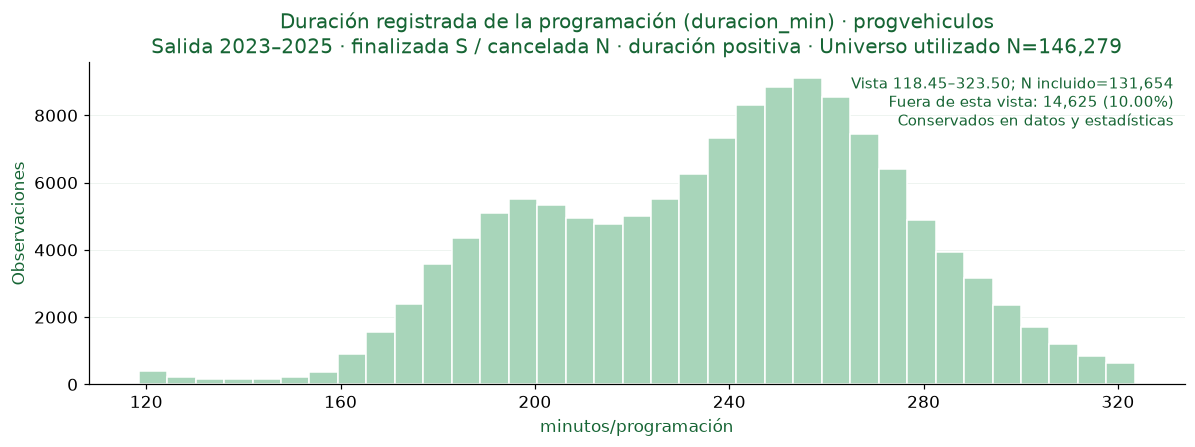

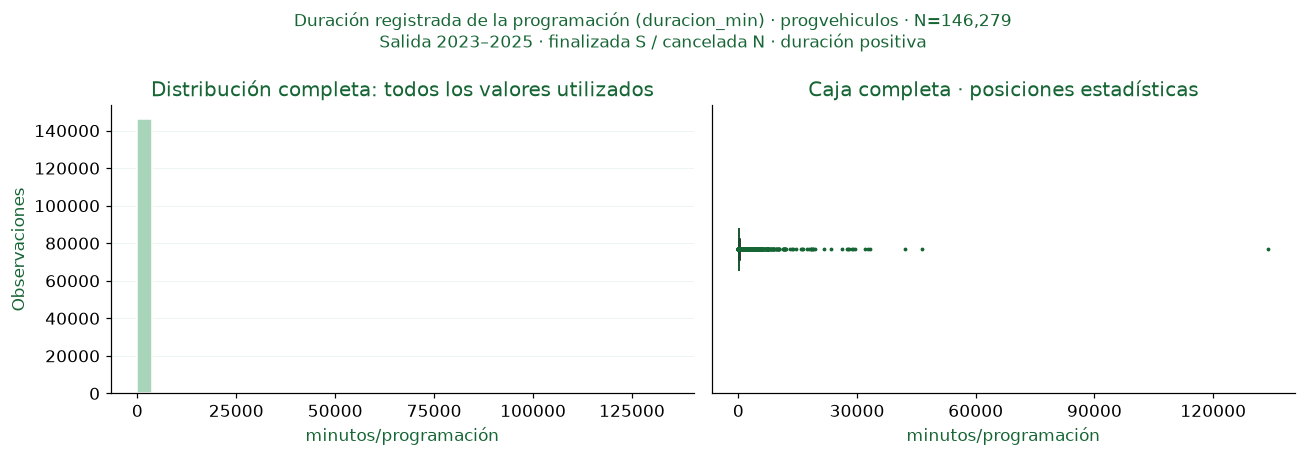

Indicador,Resultado
Fuente,progvehiculos
Variable,numeropasajeros
Alcance,Programaciones con salida programada 2023–2025
Unidad observación,programación
Unidad medida,abordajes/programación
Selección,Finalizada S y cancelada N; conteo presente no negativo (criterio 8)
Total considerado,146416
Faltantes,1218
Excluidos no faltantes,0
No finitos,0


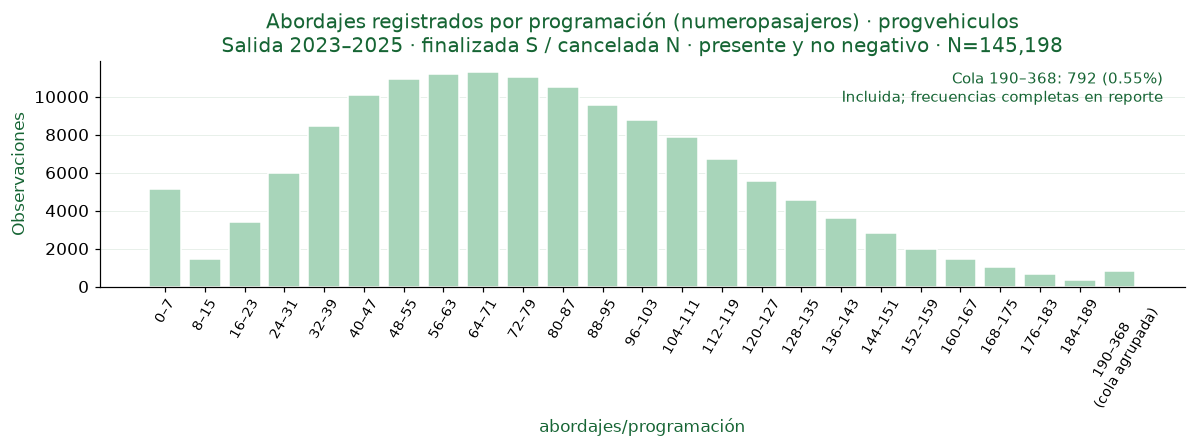

Indicador,Resultado
Fuente,progvehiculos
Variable,numerobajadas
Alcance,Programaciones con salida programada 2023–2025
Unidad observación,programación
Unidad medida,bajadas/programación
Selección,Finalizada S y cancelada N; conteo presente no negativo (criterio 8)
Total considerado,146416
Faltantes,1218
Excluidos no faltantes,0
No finitos,0


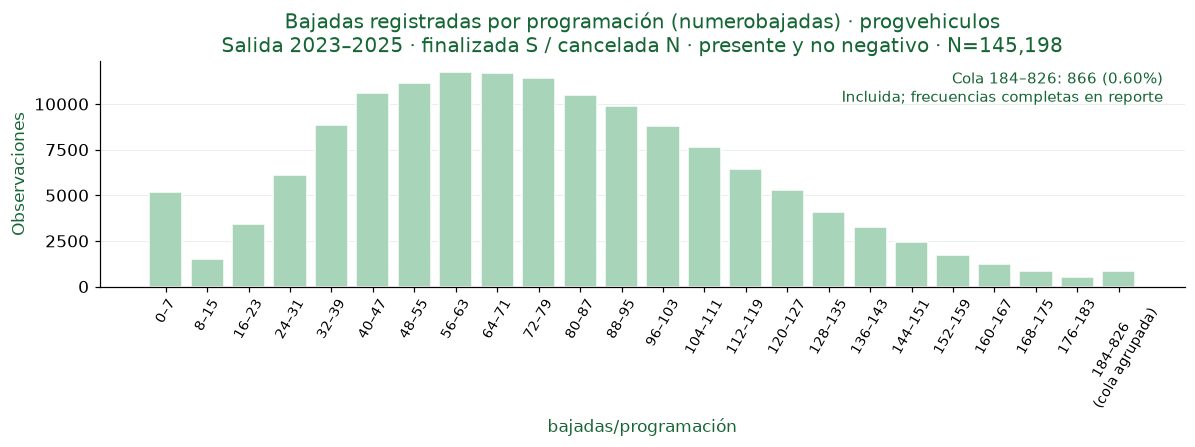

Indicador,Resultado
Fuente,progvehiculos
Variable,numerobloqueos
Alcance,Programaciones con salida programada 2023–2025
Unidad observación,programación
Unidad medida,bloqueos de puerta/programación
Selección,"Finalizada S y cancelada N; bloqueo presente, sin exclusión por signo"
Total considerado,146416
Faltantes,1218
Excluidos no faltantes,0
No finitos,0


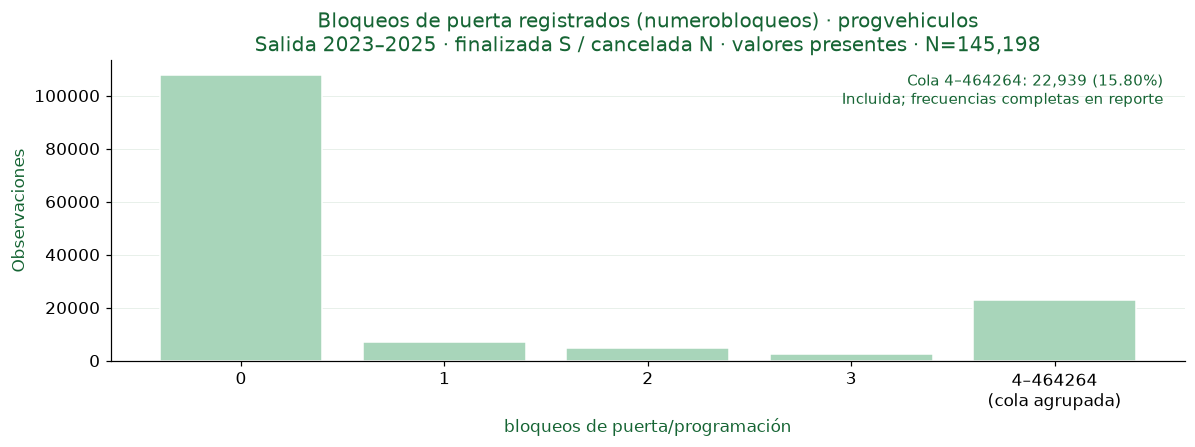

Fuente,Campo,Ceros,N selección,% ceros,Interpretación
progvehiculos,numeropasajeros,3708,145198,2.553754,Cero registrado; no equivale automáticamente a demanda nula
progvehiculos,numerobajadas,3296,145198,2.270004,Cero registrado; no equivale automáticamente a demanda nula


In [12]:
if p9 is not None:
    for columna,serie,seleccion in [
        ("duracion_min",dur9,SELECCIONES9["Duración positiva"]),
        ("numeropasajeros",p9.numeropasajeros,SELECCIONES9["Pasajeros disponibles no negativos"]),
        ("numerobajadas",p9.numerobajadas,SELECCIONES9["Bajadas disponibles no negativas"]),
        ("numerobloqueos",p9.numerobloqueos,final9 & p9.numerobloqueos.notna())]:
        numerica9("progvehiculos",columna,serie,NUM9["progvehiculos"][columna],final9,seleccion,
            "Finalizada S y cancelada N; duración positiva" if columna=="duracion_min" else "Finalizada S y cancelada N; conteo presente no negativo (criterio 8)" if columna in ["numeropasajeros","numerobajadas"] else "Finalizada S y cancelada N; bloqueo presente, sin exclusión por signo")
    ceros9=[]
    for c,nombre in [("numeropasajeros","Pasajeros disponibles no negativos"),("numerobajadas","Bajadas disponibles no negativas")]:
        mask=SELECCIONES9[nombre];ceros=int((mask & p9[c].eq(0)).sum())
        ceros9.append({"Fuente":"progvehiculos","Campo":c,"Ceros":ceros,"N selección":int(mask.sum()),"% ceros":100*ceros/mask.sum(),"Interpretación":"Cero registrado; no equivale automáticamente a demanda nula"})
    CEROS9=pd.DataFrame(ceros9);display(guardar9("progvehiculos","ceros_seleccionados",CEROS9))
    display(Markdown("Los ceros permanecen como valores observados. Pueden corresponder a distintas situaciones de registro u operación; el archivo no permite distinguirlas. La semejanza marginal entre subidas y bajadas tampoco demuestra balance dentro de cada programación."))

**progvehiculos.duracion_min — Programaciones con salida programada 2023–2025:** el 50% central está entre 205.02 y 267.45 minutos/programación. La media supera a la mediana: los valores altos tienen mayor influencia en ella. Fuera del intervalo IQR hay 12,373 observaciones: posiciones estadísticas, sin prueba de error. 

**progvehiculos.numeropasajeros — Programaciones con salida programada 2023–2025:** el 50% central está entre 49.00 y 105.00 abordajes/programación. La media supera a la mediana: los valores altos tienen mayor influencia en ella. Fuera del intervalo IQR hay 792 observaciones: posiciones estadísticas, sin prueba de error. 

**progvehiculos.numerobajadas — Programaciones con salida programada 2023–2025:** el 50% central está entre 48.00 y 102.00 bajadas/programación. La media supera a la mediana: los valores altos tienen mayor influencia en ella. Fuera del intervalo IQR hay 866 observaciones: posiciones estadísticas, sin prueba de error. 

**progvehiculos.numerobloqueos — Programaciones con salida programada 2023–2025:** el 50% central está entre 0.00 y 1.00 bloqueos de puerta/programación. La media supera a la mediana: los valores altos tienen mayor influencia en ella. Fuera del intervalo IQR hay 25,544 observaciones: posiciones estadísticas, sin prueba de error. 

Los ceros permanecen como valores observados. Pueden corresponder a distintas situaciones de registro u operación; el archivo no permite distinguirlas. La semejanza marginal entre subidas y bajadas tampoco demuestra balance dentro de cada programación.

#### **9.4.2. Diagnóstico de la duración registrada**
El diccionario general y el ampliado de `progvehiculos` definen inicio/fin como efectivos del “viaje”. No distinguen recorrido, ciclo o turno ni documentan el evento que fija esos tiempos. `rutas.tiempo_global` se describe como ciclo, pero no valida inicio–fin de cada programación. Se utiliza **duración registrada de la programación**; el número operativamente validado queda pendiente de una definición y reglas confirmadas. No se aplican umbrales de invalidación.

In [13]:
if p9 is not None:
    inicio9,fin9,salida9=(local9(p9[c]) for c in ["fechainicio","fechafin","fechasalida"])
    limites9=[pd.Timestamp(CFG9["inicio"]),pd.Timestamp(CFG9["fin_exclusivo"])]
    auditoria_tiempos9=[]
    for c,fechas in [("fechainicio",inicio9),("fechafin",fin9)]:
        for grupo,mask in [("Todas las programaciones",SELECCIONES9["Todas las programaciones"]),("Finalizadas no canceladas",final9),("Duración positiva (criterio 8)",SELECCIONES9["Duración positiva"])]:
            f=fechas.loc[mask];antes=int(f.lt(limites9[0]).sum());despues=int(f.ge(limites9[1]).sum())
            auditoria_tiempos9.append({"Campo":c,"Selección":grupo,"N selección":int(mask.sum()),"Presentes":int(f.notna().sum()),"Faltantes":int(f.isna().sum()),"Antes de inicio":antes,"Desde fin exclusivo":despues,"Total fuera":antes+despues,"Mínimo":str(f.min()),"Máximo":str(f.max())})
    FUERA_VENTANA9=pd.DataFrame(auditoria_tiempos9)
    display(guardar9("progvehiculos","inicio_fin_fuera_ventana",FUERA_VENTANA9))
    columnas9=["idprogramacion","fechasalida","fechainicio","fechafin","finalizado","cancelada"]
    MAYORES_DURACIONES9=p9.loc[SELECCIONES9["Duración positiva"],columnas9].copy()
    MAYORES_DURACIONES9["Duración registrada (min)"]=dur9.loc[MAYORES_DURACIONES9.index]
    MAYORES_DURACIONES9["Duración registrada (días)"]=MAYORES_DURACIONES9["Duración registrada (min)"]/1440
    MAYORES_DURACIONES9=MAYORES_DURACIONES9.nlargest(12,"Duración registrada (min)")
    display(guardar9("progvehiculos","mayores_duraciones",MAYORES_DURACIONES9))
    SEMANTICA_DURACION9=pd.DataFrame([{"Campo":c,**{k:DICC9['progvehiculos'][c].get(k,"No definido") for k in ['descripcion','significado','riesgo_leakage']}} for c in ['fechainicio','fechafin']])
    guardar9("progvehiculos","evidencia_diccionario_duracion",SEMANTICA_DURACION9)
    display(Markdown(f"El máximo registrado es **{dur9.loc[SELECCIONES9['Duración positiva']].max()/1440:.2f} días**. La pertenencia al reto se define por salida programada, por eso algunos inicio/fin exceden el cierre. Esto es verificable; la causa y la unidad operativa siguen sin confirmarse. Una duración positiva no queda operativamente validada por este diagnóstico."))

Campo,Selección,N selección,Presentes,Faltantes,Antes de inicio,Desde fin exclusivo,Total fuera,Mínimo,Máximo
fechainicio,Todas las programaciones,162678,161595,1083,0,3,3,2023-01-01 05:11:05,2026-01-09 09:54:24
fechainicio,Finalizadas no canceladas,146416,146416,0,0,3,3,2023-01-01 05:11:05,2026-01-09 09:54:24
fechainicio,Duración positiva (criterio 8),146279,146279,0,0,3,3,2023-01-01 05:11:05,2026-01-09 09:54:24
fechafin,Todas las programaciones,162678,146416,16262,0,16,16,2023-01-01 08:11:08,2026-01-23 11:58:16
fechafin,Finalizadas no canceladas,146416,146416,0,0,16,16,2023-01-01 08:11:08,2026-01-23 11:58:16
fechafin,Duración positiva (criterio 8),146279,146279,0,0,16,16,2023-01-01 08:11:08,2026-01-23 11:58:16


idprogramacion,fechasalida,fechainicio,fechafin,finalizado,cancelada,Duración registrada (min),Duración registrada (días)
6314930,2024-07-01 16:00:00,2024-08-05 09:10:02,2024-11-06 08:59:21,S,N,133909.316667,92.992581
6539056,2024-10-10 05:58:00,2024-10-10 05:51:33,2024-11-11 12:05:54,S,N,46454.350000,32.259965
6188787,2024-05-07 05:17:00,2024-05-07 05:02:01,2024-06-05 11:53:14,S,N,42171.216667,29.285567
7455998,2025-11-20 05:58:00,2025-12-31 10:32:42,2026-01-23 11:58:16,S,N,33205.566667,23.059421
6196370,2024-05-10 05:42:00,2024-05-15 11:02:37,2024-06-07 07:02:43,S,N,32880.100000,22.833403
6196346,2024-05-10 05:17:00,2024-05-10 05:02:43,2024-06-01 09:51:10,S,N,31968.450000,22.200312
7103950,2025-06-17 05:54:00,2025-06-17 06:00:52,2025-07-07 17:31:12,S,N,29490.333333,20.479398
6571909,2024-10-25 05:08:00,2024-10-25 05:01:13,2024-11-14 09:12:04,S,N,29050.850000,20.174201
6228564,2024-05-24 05:46:00,2024-07-02 13:12:39,2024-07-22 10:13:25,S,N,28620.766667,19.875532
5822994,2023-11-30 20:30:00,2023-11-30 20:25:38,2023-12-20 07:51:26,S,N,28045.800000,19.476250


El máximo registrado es **92.99 días**. La pertenencia al reto se define por salida programada, por eso algunos inicio/fin exceden el cierre. Esto es verificable; la causa y la unidad operativa siguen sin confirmarse. Una duración positiva no queda operativamente validada por este diagnóstico.

Indicador,Resultado
Fuente,progvehiculos
Variable,desfase_inicio_min
Alcance,Programaciones con salida programada 2023–2025
Unidad observación,programación
Unidad medida,minutos (inicio menos salida)
Selección,Finalizada S y cancelada N; ambas fechas presentes; todos los signos
Total considerado,146416
Faltantes,0
Excluidos no faltantes,0
No finitos,0


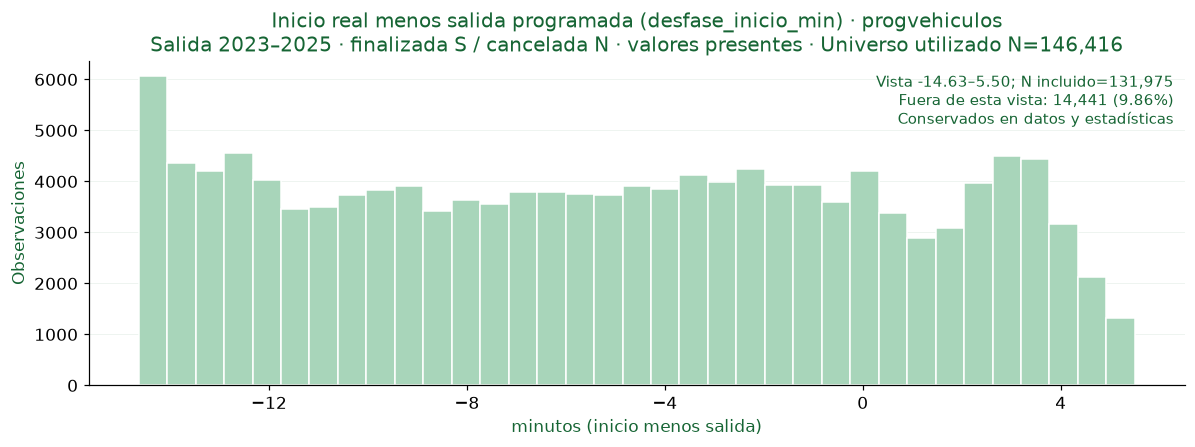

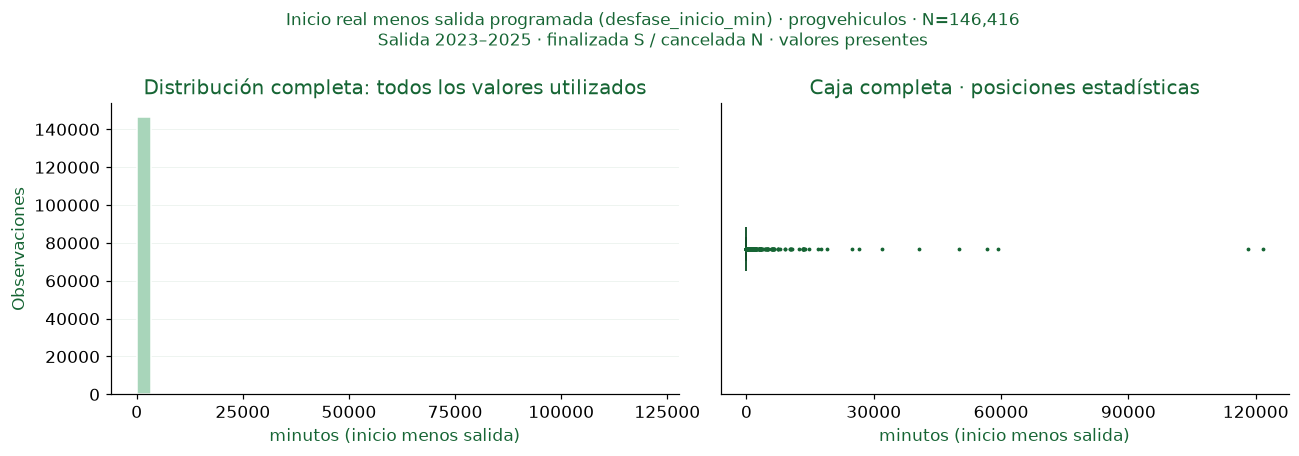

Banda descriptiva,Programaciones,N duración positiva,Porcentaje
"(0,120] min",7435,146279,5.082753
"(120,240] min",62171,146279,42.501658
"(240,360] min",70861,146279,48.442360
"(360,1440] min",4815,146279,3.291655
"(1,7] días",954,146279,0.652178
>7 días,43,146279,0.029396


In [14]:
if p9 is not None:
    desfase9=(inicio9-salida9).dt.total_seconds()/60
    numerica9("progvehiculos","desfase_inicio_min",desfase9,"minutos (inicio menos salida)",final9,
        criterio="Finalizada S y cancelada N; ambas fechas presentes; todos los signos",sufijo="_diagnostico")
    bandas9=pd.cut(dur9.loc[SELECCIONES9["Duración positiva"]],bins=[0,120,240,360,1440,10080,np.inf],
        labels=["(0,120] min","(120,240] min","(240,360] min","(360,1440] min","(1,7] días",">7 días"])
    bandas_f9=bandas9.value_counts(sort=False).rename_axis("Banda descriptiva").reset_index(name="Programaciones")
    bandas_f9["N duración positiva"]=int(SELECCIONES9["Duración positiva"].sum())
    bandas_f9["Porcentaje"]=100*bandas_f9.Programaciones/bandas_f9['N duración positiva']
    display(guardar9("progvehiculos","bandas_duracion_diagnostico",bandas_f9))
    display(Markdown(f"La diferencia inicio−salida es negativa en {int((final9 & desfase9.lt(0)).sum()):,} programaciones, cero en {int((final9 & desfase9.eq(0)).sum()):,} y positiva en {int((final9 & desfase9.gt(0)).sum()):,}. Describe la separación entre marcas temporales, no un atraso validado. Las bandas de duración son solo diagnóstico visual: **no son reglas de invalidez** y no alteran la selección original."))

**progvehiculos.desfase_inicio_min — Programaciones con salida programada 2023–2025:** el 50% central está entre -10.73 y 0.27 minutos (inicio menos salida). La media supera a la mediana: los valores altos tienen mayor influencia en ella. Fuera del intervalo IQR hay 2,048 observaciones: posiciones estadísticas, sin prueba de error. 

La diferencia inicio−salida es negativa en 107,367 programaciones, cero en 97 y positiva en 38,952. Describe la separación entre marcas temporales, no un atraso validado. Las bandas de duración son solo diagnóstico visual: **no son reglas de invalidez** y no alteran la selección original.

#### **9.4.2.1. Sensibilidad al cierre temporal, sin invalidación operativa**
La selección principal sigue siendo exactamente la de la sección 8. Se añade una comparación separada que exige que inicio y fin estén dentro de la ventana configurada. Es una condición de cobertura temporal, no una regla que valide el recorrido ni declare errores. No se modifican los datos ni se sustituyen las estadísticas principales.

In [15]:
if p9 is not None:
    positivo_revision9 = SELECCIONES9['Duración positiva']
    marcas_en_ventana9 = (inicio9.ge(limites9[0]) & inicio9.lt(limites9[1]) & fin9.ge(limites9[0]) & fin9.lt(limites9[1])).fillna(False)
    sensibilidad9 = positivo_revision9 & marcas_en_ventana9
    filas_revision9 = []
    for nombre, mask in [('Principal: duración positiva, criterio 8', positivo_revision9), ('Sensibilidad: positiva e inicio/fin en ventana', sensibilidad9)]:
        x = dur9.loc[mask].astype('float64')
        filas_revision9.append({'Selección':nombre, 'Unidad':'minutos/programación', 'N':len(x), 'Media':x.mean(), 'Mediana':x.median(), 'P95':x.quantile(.95), 'Máximo':x.max(), 'Fuera respecto a principal':int((positivo_revision9 & ~mask).sum())})
    revision_duracion9 = pd.DataFrame(filas_revision9)
    assert sensibilidad9.sum() + (positivo_revision9 & ~marcas_en_ventana9).sum() == positivo_revision9.sum()
    display(guardar9('progvehiculos','sensibilidad_cierre_temporal',revision_duracion9))
    nfuera9 = int((positivo_revision9 & ~marcas_en_ventana9).sum())
    display(Markdown(f'La condición temporal deja fuera de esta **comparación de sensibilidad** {nfuera9:,} programaciones ({100*nfuera9/positivo_revision9.sum():.3f}% de las positivas). Permanecen en la descripción principal. La diferencia entre las medias muestra cuánto influyen las marcas fuera de ventana; no confirma la causa ni la validez operativa de las restantes.'))


Selección,Unidad,N,Media,Mediana,P95,Máximo,Fuera respecto a principal
"Principal: duración positiva, criterio 8",minutos/programación,146279,268.683703,242.583333,323.500000,133909.316667,0
Sensibilidad: positiva e inicio/fin en ventana,minutos/programación,146263,267.944433,242.583333,323.366667,133909.316667,16


La condición temporal deja fuera de esta **comparación de sensibilidad** 16 programaciones (0.011% de las positivas). Permanecen en la descripción principal. La diferencia entre las medias muestra cuánto influyen las marcas fuera de ventana; no confirma la causa ni la validez operativa de las restantes.

#### **9.4.3. Detalle por segmento**
Cada fila es un registro segmento–programación. Se conservan todos los valores presentes, incluidos negativos, sin heredar el filtro de programación ni validar `pasajeros` como ocupación. Subidas y bajadas se presentan como conteos discretos con cola agrupada y frecuencias por entero completas.

Indicador,Resultado
Fuente,timbradas_segmentos
Variable,subidas
Alcance,Detalle observado 01-01-2023 a 27-02-2023
Unidad observación,registro segmento–viaje
Unidad medida,abordajes/registro
Selección,Filas de la fuente; valores presentes
Total considerado,799030
Faltantes,0
Excluidos no faltantes,0
No finitos,0


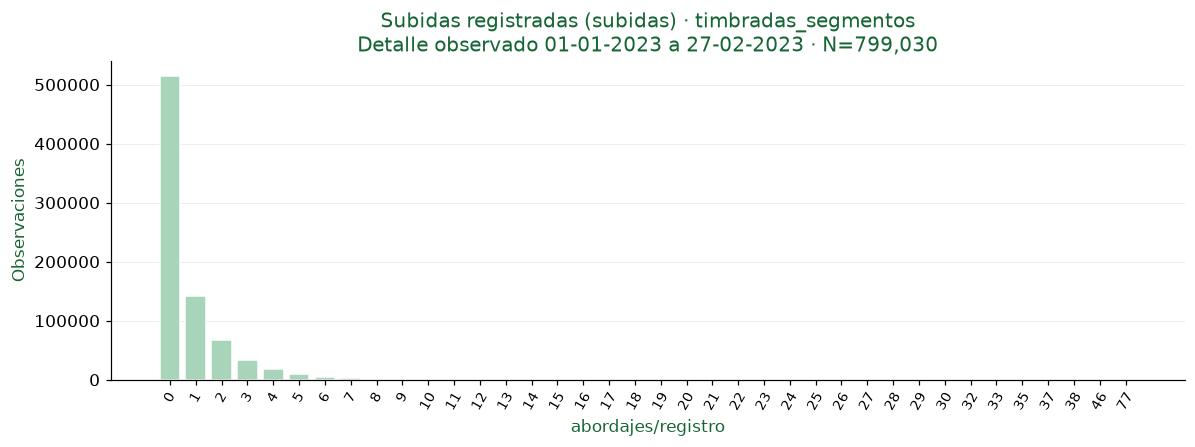

Indicador,Resultado
Fuente,timbradas_segmentos
Variable,bajadas
Alcance,Detalle observado 01-01-2023 a 27-02-2023
Unidad observación,registro segmento–viaje
Unidad medida,bajadas/registro
Selección,Filas de la fuente; valores presentes
Total considerado,799030
Faltantes,0
Excluidos no faltantes,0
No finitos,0


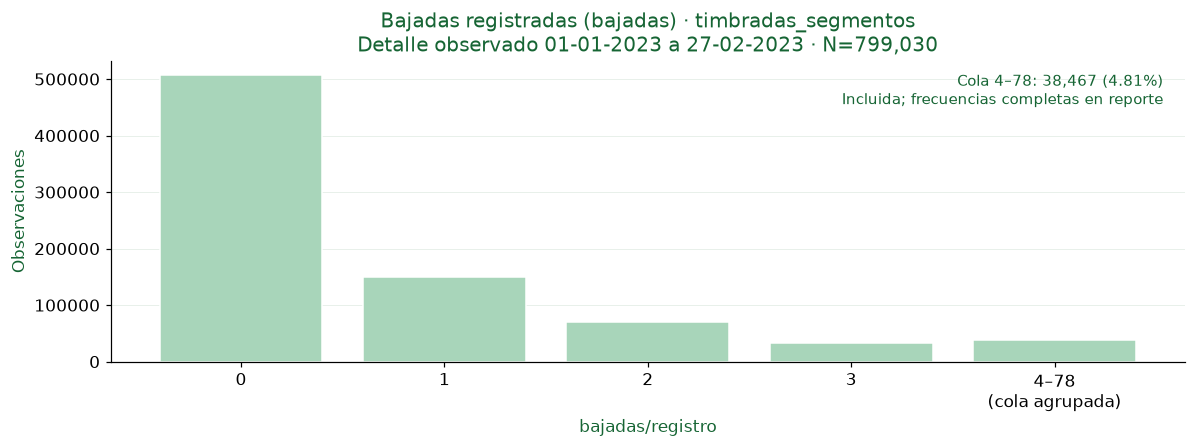

Indicador,Resultado
Fuente,timbradas_segmentos
Variable,pasajeros
Alcance,Detalle observado 01-01-2023 a 27-02-2023
Unidad observación,registro segmento–viaje
Unidad medida,valor registrado/registro; significado pendiente
Selección,Filas de la fuente; valores presentes
Total considerado,799030
Faltantes,0
Excluidos no faltantes,0
No finitos,0


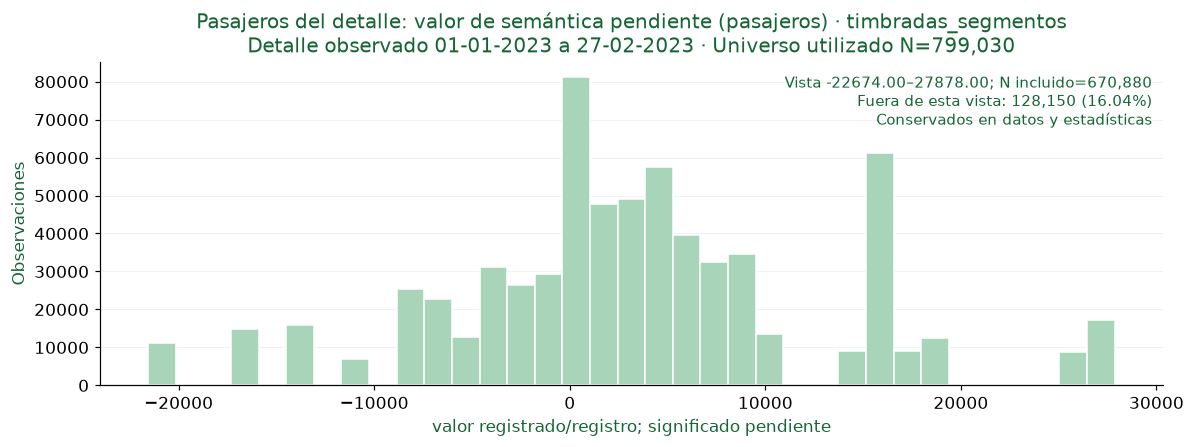

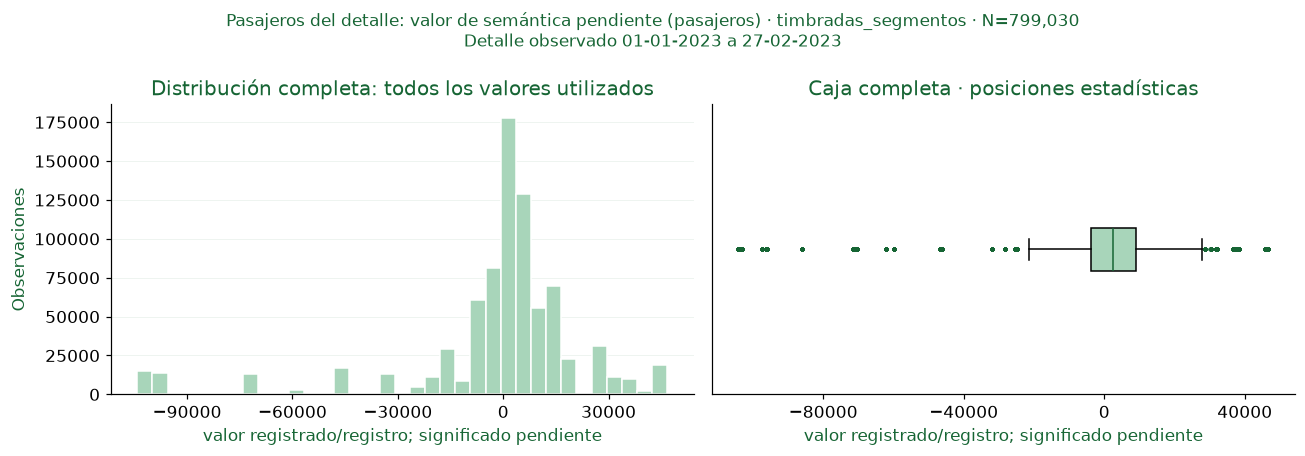

Fuente,Campo,N presentes,N negativos,% negativos,Mínimo negativo,Mediana negativos,P5 negativos,P95 negativos,Máximo negativo
timbradas_segmentos,pasajeros,799030,315974,39.544698,-104167.000000,-7386.000000,-96345.000000,-159.000000,-1.000000


In [16]:
if t9 is not None:
    for c,u in NUM9["timbradas_segmentos"].items(): numerica9("timbradas_segmentos",c,t9[c],u)
    negativos9=t9.pasajeros.loc[t9.pasajeros.lt(0).fillna(False)].astype("float64")
    MAGNITUD_NEGATIVOS9=pd.DataFrame([{"Fuente":"timbradas_segmentos","Campo":"pasajeros","N presentes":int(t9.pasajeros.notna().sum()),
        "N negativos":len(negativos9),"% negativos":100*len(negativos9)/t9.pasajeros.notna().sum(),"Mínimo negativo":negativos9.min(),
        "Mediana negativos":negativos9.median(),"P5 negativos":negativos9.quantile(.05),"P95 negativos":negativos9.quantile(.95),"Máximo negativo":negativos9.max()}])
    display(guardar9("timbradas_segmentos","magnitud_negativos_pasajeros",MAGNITUD_NEGATIVOS9))
    display(Markdown("La magnitud y la frecuencia de negativos impiden interpretar el campo como una ocupación simultánea confirmada. Se conserva su distribución como registro de semántica pendiente; no se sustituye por cero ni se utiliza para calcular ocupación porcentual."))

**timbradas_segmentos.subidas — Detalle observado 01-01-2023 a 27-02-2023:** el 50% central está entre 0.00 y 1.00 abordajes/registro. La media supera a la mediana: los valores altos tienen mayor influencia en ella. Fuera del intervalo IQR hay 74,281 observaciones: posiciones estadísticas, sin prueba de error. 

**timbradas_segmentos.bajadas — Detalle observado 01-01-2023 a 27-02-2023:** el 50% central está entre 0.00 y 1.00 bajadas/registro. La media supera a la mediana: los valores altos tienen mayor influencia en ella. Fuera del intervalo IQR hay 72,210 observaciones: posiciones estadísticas, sin prueba de error. 

**timbradas_segmentos.pasajeros — Detalle observado 01-01-2023 a 27-02-2023:** el 50% central está entre -3717.00 y 8921.00 valor registrado/registro; significado pendiente. La media queda por debajo de la mediana: la cola inferior tiene mayor influencia en ella. Fuera del intervalo IQR hay 128,150 observaciones: posiciones estadísticas, sin prueba de error. 

La magnitud y la frecuencia de negativos impiden interpretar el campo como una ocupación simultánea confirmada. Se conserva su distribución como registro de semántica pendiente; no se sustituye por cero ni se utiliza para calcular ocupación porcentual.

#### **9.4.4. Vehículos y longitudes**
Los vehículos se describen una vez por fila del catálogo. Sus estados son actuales al archivo, sin evidencia de vigencia histórica durante todo el reto. Las longitudes casi constantes requieren una tabla de predominio y excepciones; IQR cero no las convierte en errores.

Indicador,Resultado
Fuente,vehiculos
Variable,capacidad
Alcance,"Catálogo extraído; estado actual, sin historia 2023–2025"
Unidad observación,vehículo
Unidad medida,plazas declaradas/vehículo
Selección,Filas de la fuente; valores presentes
Total considerado,293
Faltantes,0
Excluidos no faltantes,0
No finitos,0


Indicador,Resultado
Fuente,vehiculos
Variable,n_sentados
Alcance,"Catálogo extraído; estado actual, sin historia 2023–2025"
Unidad observación,vehículo
Unidad medida,plazas sentadas declaradas/vehículo
Selección,Filas de la fuente; valores presentes
Total considerado,293
Faltantes,0
Excluidos no faltantes,0
No finitos,0


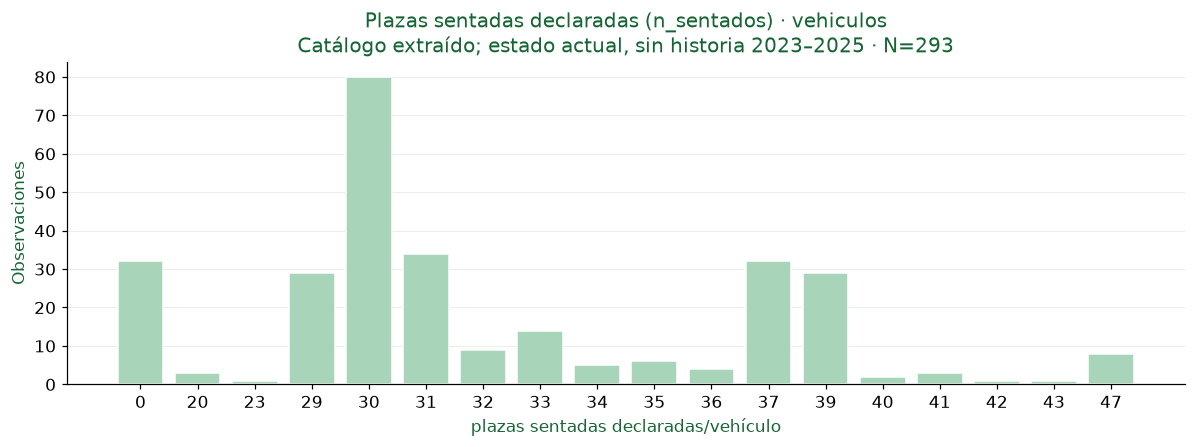

Indicador,Resultado
Fuente,vehiculos
Variable,n_depie
Alcance,"Catálogo extraído; estado actual, sin historia 2023–2025"
Unidad observación,vehículo
Unidad medida,plazas de pie declaradas/vehículo
Selección,Filas de la fuente; valores presentes
Total considerado,293
Faltantes,0
Excluidos no faltantes,0
No finitos,0


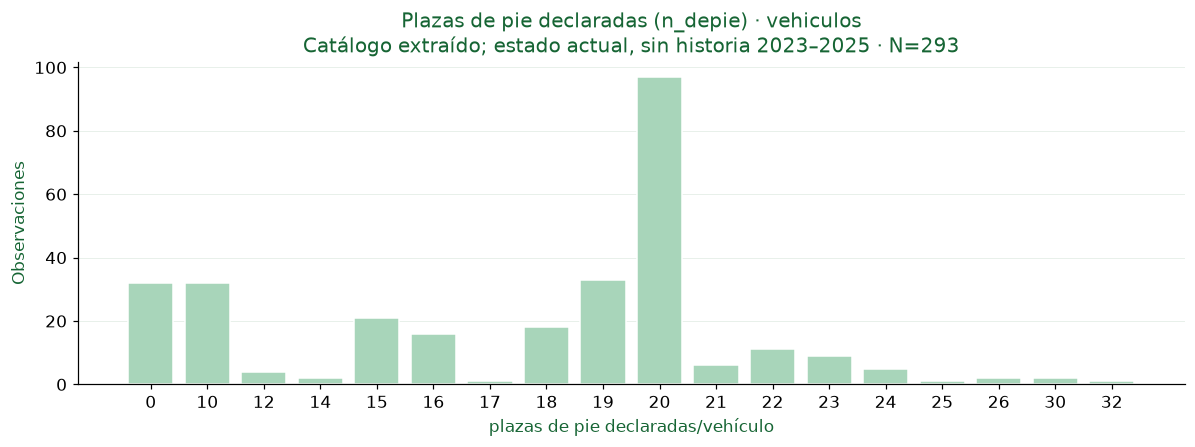

In [17]:
if "vehiculos" in DATOS9:
    v9=DATOS9["vehiculos"]
    for c,u in NUM9["vehiculos"].items(): numerica9("vehiculos",c,v9[c],u)
    display(Markdown(f"**vehiculos:** {int(v9.capacidad.eq(0).sum()):,} de {len(v9):,} capacidades son cero. Ese campo no permite ocupación porcentual. Plazas sentadas y de pie se describen por separado; su suma no sustituye automáticamente la capacidad declarada."))

vehiculos.capacidad: el valor registrado es constante (0.00); una distribución gráfica no aporta información.

**vehiculos.n_sentados — Catálogo extraído; estado actual, sin historia 2023–2025:** el 50% central está entre 30.00 y 37.00 plazas sentadas declaradas/vehículo. La media queda por debajo de la mediana: la cola inferior tiene mayor influencia en ella. Fuera del intervalo IQR hay 32 observaciones: posiciones estadísticas, sin prueba de error. 

**vehiculos.n_depie — Catálogo extraído; estado actual, sin historia 2023–2025:** el 50% central está entre 15.00 y 20.00 plazas de pie declaradas/vehículo. La media queda por debajo de la mediana: la cola inferior tiene mayor influencia en ella. Fuera del intervalo IQR hay 35 observaciones: posiciones estadísticas, sin prueba de error. 

**vehiculos:** 293 de 293 capacidades son cero. Ese campo no permite ocupación porcentual. Plazas sentadas y de pie se describen por separado; su suma no sustituye automáticamente la capacidad declarada.

In [18]:
LONGITUDES9=[]
for tabla,c in [("rutas_segmentos","longitud_m"),("rutas_segmentos_porcion","longitud_porcion_m")]:
    if tabla not in DATOS9: continue
    s=DATOS9[tabla][c]
    numerica9(tabla,c,s,NUM9[tabla][c],graficos=False)
    f=s.value_counts(dropna=False).rename_axis("Longitud exacta (m)").reset_index(name="Frecuencia")
    f["N fuente"]=len(s);f["Porcentaje"]=100*f.Frecuencia/len(s)
    f["Es valor predominante"]=f.Frecuencia.eq(f.Frecuencia.max())
    display(guardar9(tabla,c+"_predominio_excepciones",f))
    registrar9(tabla,c,"principal",c+"_predominio_excepciones.csv")
    LONGITUDES9.append({"Fuente":tabla,"Campo":c,"Valor predominante":str(f.iloc[0,0]),"Frecuencia":int(f.Frecuencia.iloc[0]),"N":len(s),"Excepciones":int(len(s)-f.Frecuencia.iloc[0])})
    display(Markdown(f"**{tabla}.{c}:** {f.Porcentaje.iloc[0]:.2f}% comparte la longitud predominante. Las restantes {len(s)-f.Frecuencia.iloc[0]:,} filas son excepciones al valor modal, sin prueba de error. La concentración hace inadecuado etiquetarlas por un intervalo IQR colapsado."))
if "rutas_segmentos_config" in DATOS9:
    config9=DATOS9["rutas_segmentos_config"][["id","tipo_agrupacion","tamaño_segmento_m","tamaño_porcion_m","tamaño_minimo_porcion_m","numero_segmentos"]]
    display(guardar9("rutas_segmentos_config","configuracion_longitudes",config9))
    comparacion_geometria9=[]
    if len(config9)==1:
        conf=config9.iloc[0]
        assert DATOS9['rutas_segmentos'].id_config.eq(conf['id']).all(), "La configuración no corresponde a todos los segmentos"
        for tabla,c,objetivo,minimo in [
            ('rutas_segmentos','longitud_m',float(conf['tamaño_segmento_m']),None),
            ('rutas_segmentos_porcion','longitud_porcion_m',float(conf['tamaño_porcion_m']),float(conf['tamaño_minimo_porcion_m']))]:
            xg=DATOS9[tabla][c].astype('float64')
            comparacion_geometria9.append({'Fuente':tabla,'N':len(xg),'Objetivo declarado (m)':objetivo,'Mínimo declarado (m)':minimo,
                'Mínimo observado (m)':xg.min(),'Filas inferiores al objetivo':int(xg.lt(objetivo).sum()),
                'Filas inferiores al mínimo declarado':int(xg.lt(minimo).sum()) if minimo is not None else None,
                'Conclusión':'Comparación numérica; regla de remanentes no documentada, sin invalidación'})
        display(guardar9('rutas_segmentos_config','contraste_longitudes_configuracion',pd.DataFrame(comparacion_geometria9)))
    for c in config9.columns:
        if not c.startswith("id"): registrar9("rutas_segmentos_config",c,"principal","configuracion_longitudes.csv")
    display(Markdown("La configuración declara tamaños objetivo y mínimo, pero no documenta excepciones para el cierre geométrico. Las longitudes menores podrían ser remanentes legítimos; **no se confirma esa causa**. Ser menor que el objetivo/minimo registrado es una comparación verificable, no una incompatibilidad operacional probada sin la regla de construcción."))
for c in ["inicio_m","fin_m"]:
    if "rutas_segmentos_porcion" in DATOS9:
        numerica9("rutas_segmentos_porcion",c,DATOS9["rutas_segmentos_porcion"][c],NUM9["rutas_segmentos_porcion"][c],mostrar=False)

Indicador,Resultado
Fuente,rutas_segmentos
Variable,longitud_m
Alcance,Archivo entregado; fila de la fuente
Unidad observación,segmento
Unidad medida,metros/segmento
Selección,Filas de la fuente; valores presentes
Total considerado,135
Faltantes,0
Excluidos no faltantes,0
No finitos,0


Longitud exacta (m),Frecuencia,N fuente,Porcentaje,Es valor predominante
500.000,134,135,99.259259,True
217.670,1,135,0.740741,False


Indicador,Resultado
Fuente,rutas_segmentos_porcion
Variable,longitud_porcion_m
Alcance,Archivo entregado; fila de la fuente
Unidad observación,porción geográfica
Unidad medida,metros/porción
Selección,Filas de la fuente; valores presentes
Total considerado,336089
Faltantes,0
Excluidos no faltantes,0
No finitos,0


Longitud exacta (m),Frecuencia,N fuente,Porcentaje,Es valor predominante
0.200,336088,336089,99.999702,True
0.070,1,336089,0.000298,False


id,tipo_agrupacion,tamaño_segmento_m,tamaño_porcion_m,tamaño_minimo_porcion_m,numero_segmentos
1,distancia,500.000,0.2000,0.2000,


Fuente,N,Objetivo declarado (m),Mínimo declarado (m),Mínimo observado (m),Filas inferiores al objetivo,Filas inferiores al mínimo declarado,Conclusión
rutas_segmentos,135,500.000000,nan,217.670000,1,nan,"Comparación numérica; regla de remanentes no documentada, sin invalidación"
rutas_segmentos_porcion,336089,0.200000,0.200000,0.070000,1,1.000000,"Comparación numérica; regla de remanentes no documentada, sin invalidación"


**rutas_segmentos.longitud_m — Archivo entregado; fila de la fuente:** el 50% central está entre 500.00 y 500.00 metros/segmento. La media queda por debajo de la mediana: la cola inferior tiene mayor influencia en ella. IQR=0: el intervalo intercuartílico colapsa y no sirve para declarar excepciones problemáticas. 

**rutas_segmentos.longitud_m:** 99.26% comparte la longitud predominante. Las restantes 1 filas son excepciones al valor modal, sin prueba de error. La concentración hace inadecuado etiquetarlas por un intervalo IQR colapsado.

**rutas_segmentos_porcion.longitud_porcion_m — Archivo entregado; fila de la fuente:** el 50% central está entre 0.20 y 0.20 metros/porción. La media queda por debajo de la mediana: la cola inferior tiene mayor influencia en ella. IQR=0: el intervalo intercuartílico colapsa y no sirve para declarar excepciones problemáticas. 

**rutas_segmentos_porcion.longitud_porcion_m:** 100.00% comparte la longitud predominante. Las restantes 1 filas son excepciones al valor modal, sin prueba de error. La concentración hace inadecuado etiquetarlas por un intervalo IQR colapsado.

La configuración declara tamaños objetivo y mínimo, pero no documenta excepciones para el cierre geométrico. Las longitudes menores podrían ser remanentes legítimos; **no se confirma esa causa**. Ser menor que el objetivo/minimo registrado es una comparación verificable, no una incompatibilidad operacional probada sin la regla de construcción.

#### **9.4.5. Agregados: alcance temporal explícito**
Para `timbradas_anio` las estadísticas principales se seleccionan por `ano` entre 2023 y 2025, inclusive. Archivo completo y 2026 tienen reportes separados. Una celda agregada no es un viaje: media de promedios de celdas y promedio global por viaje son conceptos distintos. `timbradas_consolidado` se describe como archivo sin año, con período de cálculo no confirmado.

Alcance,Celdas,N archivo,% archivo
Archivo completo (alcances superpuestos),10374,10374,100.000000
Principal: ano 2023–2025,7685,10374,74.079429
Fuera de 2023–2025,2689,10374,25.920571
Anexo: ano 2026,2689,10374,25.920571


Indicador,Resultado
Fuente,timbradas_anio
Variable,subidas
Alcance,"Reto 2023–2025, seleccionado por ano"
Unidad observación,celda agregada anual
Unidad medida,abordajes/celda agregada
Selección,ano entre 2023 y 2025 inclusive; valores presentes
Total considerado,7685
Faltantes,0
Excluidos no faltantes,0
No finitos,0


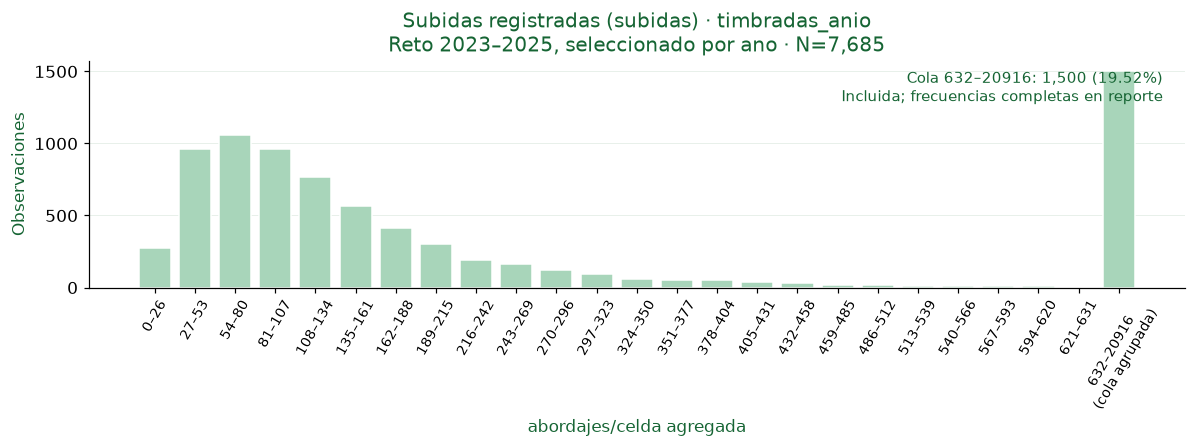

Indicador,Resultado
Fuente,timbradas_anio
Variable,bajadas
Alcance,"Reto 2023–2025, seleccionado por ano"
Unidad observación,celda agregada anual
Unidad medida,bajadas/celda agregada
Selección,ano entre 2023 y 2025 inclusive; valores presentes
Total considerado,7685
Faltantes,0
Excluidos no faltantes,0
No finitos,0


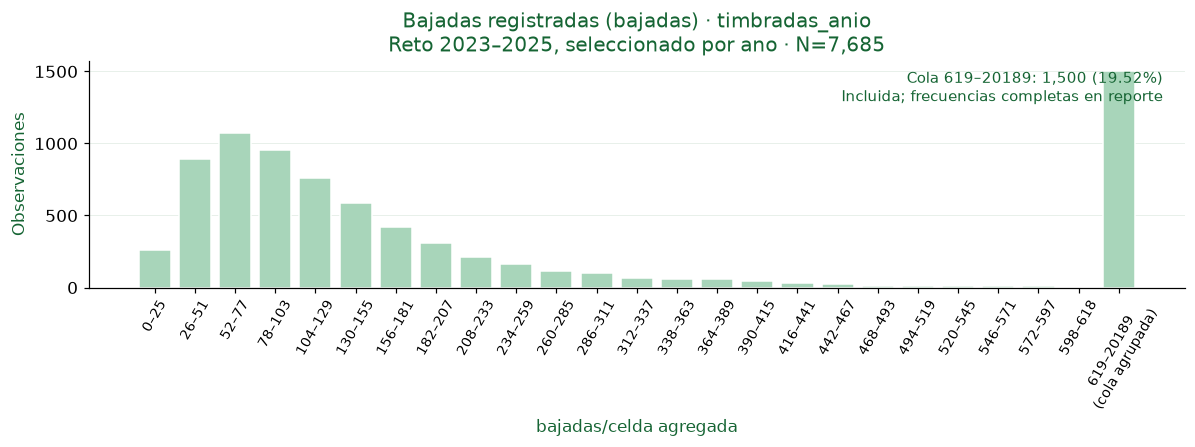

Indicador,Resultado
Fuente,timbradas_anio
Variable,nro_viajes
Alcance,"Reto 2023–2025, seleccionado por ano"
Unidad observación,celda agregada anual
Unidad medida,viajes/celda agregada
Selección,ano entre 2023 y 2025 inclusive; valores presentes
Total considerado,7685
Faltantes,0
Excluidos no faltantes,0
No finitos,0


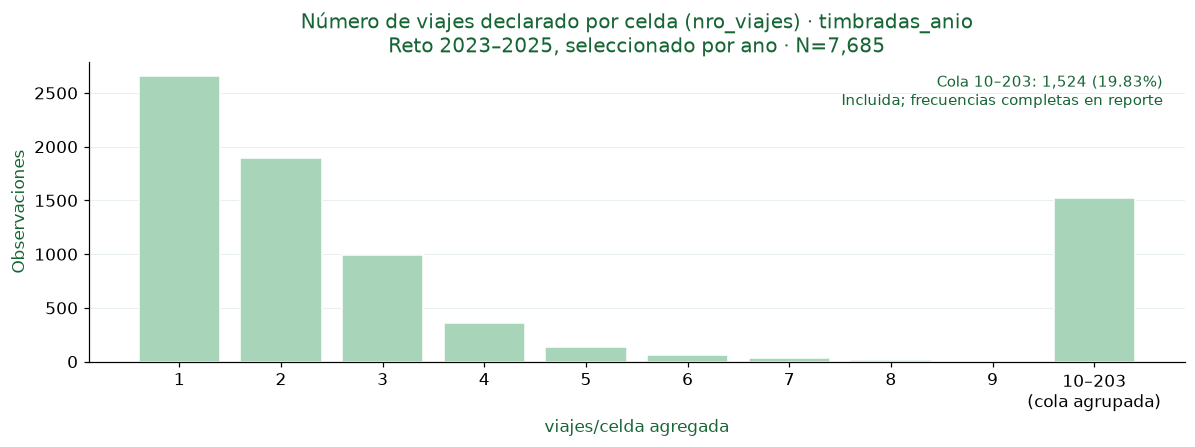

Indicador,Resultado
Fuente,timbradas_anio
Variable,promedio_subidas
Alcance,"Reto 2023–2025, seleccionado por ano"
Unidad observación,celda agregada anual
Unidad medida,abordajes/viaje declarados en celda
Selección,ano entre 2023 y 2025 inclusive; valores presentes
Total considerado,7685
Faltantes,0
Excluidos no faltantes,0
No finitos,0


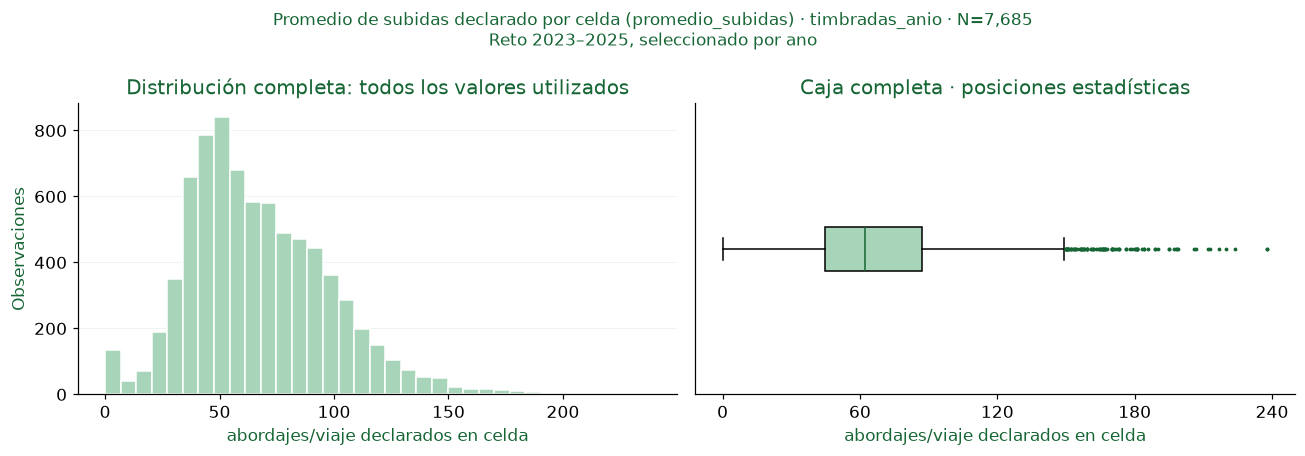

Indicador,Resultado
Fuente,timbradas_anio
Variable,promedio_bajadas
Alcance,"Reto 2023–2025, seleccionado por ano"
Unidad observación,celda agregada anual
Unidad medida,bajadas/viaje declaradas en celda
Selección,ano entre 2023 y 2025 inclusive; valores presentes
Total considerado,7685
Faltantes,0
Excluidos no faltantes,0
No finitos,0


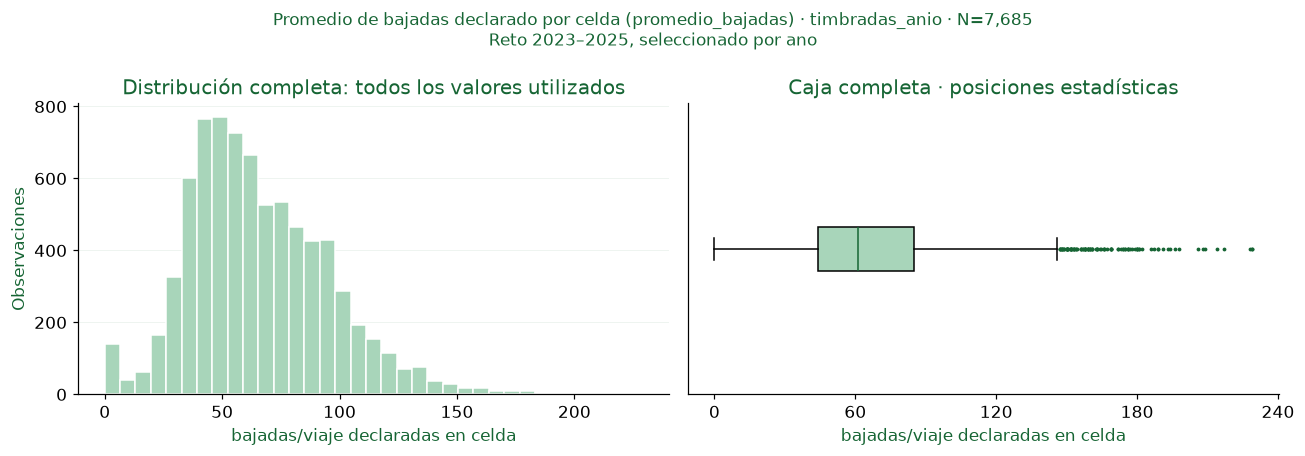

Indicador,Resultado
Fuente,timbradas_consolidado
Variable,subidas
Alcance,Archivo histórico sin año; período de cálculo no confirmado
Unidad observación,celda agregada histórica
Unidad medida,abordajes/celda agregada
Selección,Filas de la fuente; valores presentes
Total considerado,3562
Faltantes,0
Excluidos no faltantes,0
No finitos,0


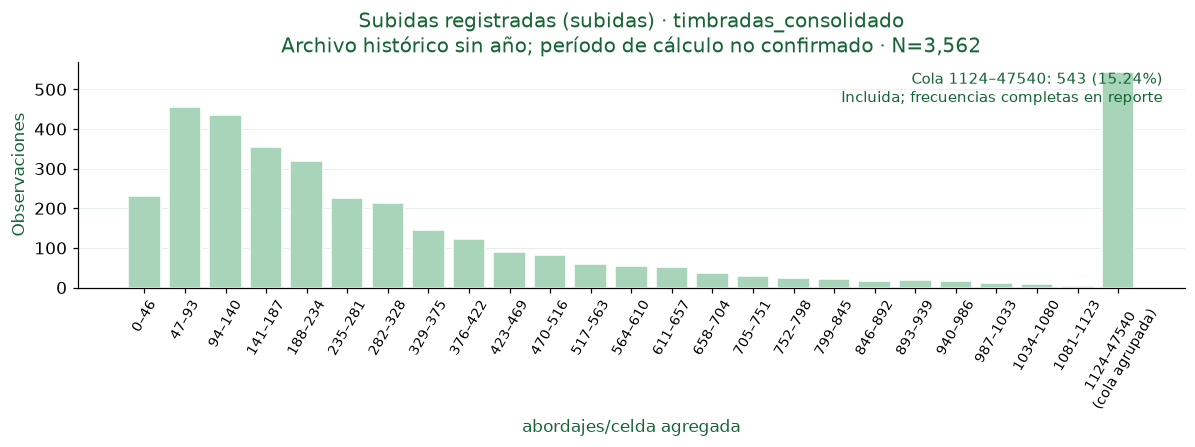

Indicador,Resultado
Fuente,timbradas_consolidado
Variable,bajadas
Alcance,Archivo histórico sin año; período de cálculo no confirmado
Unidad observación,celda agregada histórica
Unidad medida,bajadas/celda agregada
Selección,Filas de la fuente; valores presentes
Total considerado,3562
Faltantes,0
Excluidos no faltantes,0
No finitos,0


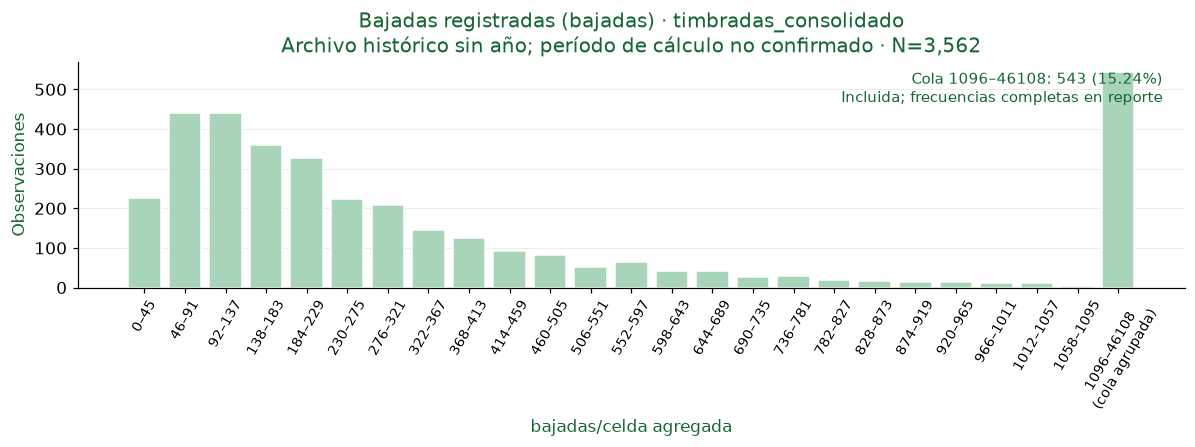

Indicador,Resultado
Fuente,timbradas_consolidado
Variable,nro_viajes
Alcance,Archivo histórico sin año; período de cálculo no confirmado
Unidad observación,celda agregada histórica
Unidad medida,viajes/celda agregada
Selección,Filas de la fuente; valores presentes
Total considerado,3562
Faltantes,0
Excluidos no faltantes,0
No finitos,0


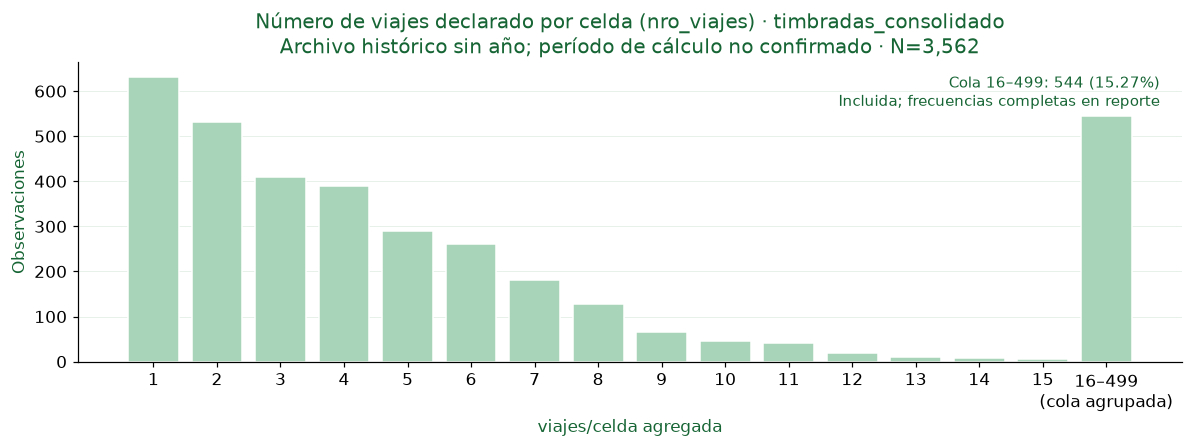

Indicador,Resultado
Fuente,timbradas_consolidado
Variable,promedio_subidas
Alcance,Archivo histórico sin año; período de cálculo no confirmado
Unidad observación,celda agregada histórica
Unidad medida,abordajes/viaje declarados en celda
Selección,Filas de la fuente; valores presentes
Total considerado,3562
Faltantes,0
Excluidos no faltantes,0
No finitos,0


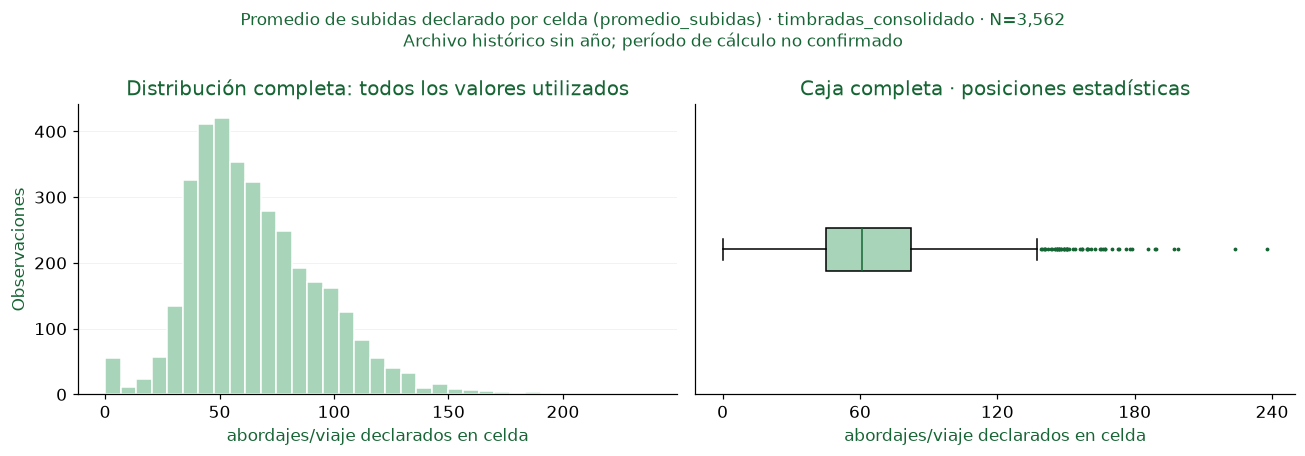

Indicador,Resultado
Fuente,timbradas_consolidado
Variable,promedio_bajadas
Alcance,Archivo histórico sin año; período de cálculo no confirmado
Unidad observación,celda agregada histórica
Unidad medida,bajadas/viaje declaradas en celda
Selección,Filas de la fuente; valores presentes
Total considerado,3562
Faltantes,0
Excluidos no faltantes,0
No finitos,0


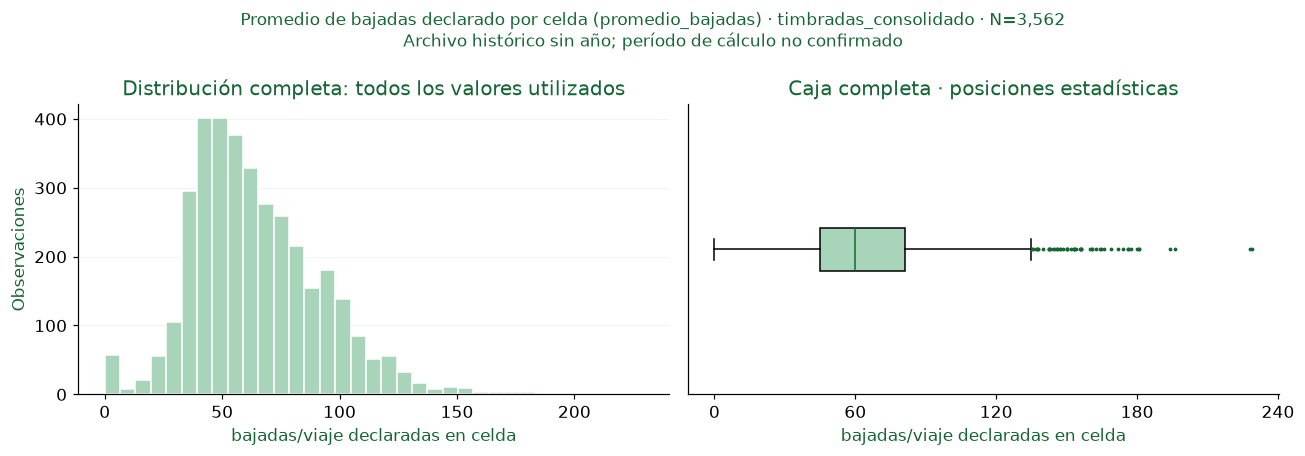

In [19]:
if "timbradas_anio" in DATOS9:
    anio9=DATOS9["timbradas_anio"]
    periodo_anio9=anio9.ano.between(2023,2025).fillna(False)
    fuera_anio9=~periodo_anio9
    ano2026_9=anio9.ano.eq(2026).fillna(False)
    ALCANCES_ANIO9=pd.DataFrame([{"Alcance":nombre,"Celdas":int(mask.sum()),"N archivo":len(anio9),"% archivo":100*mask.sum()/len(anio9)}
        for nombre,mask in [("Archivo completo (alcances superpuestos)",pd.Series(True,index=anio9.index)),("Principal: ano 2023–2025",periodo_anio9),("Fuera de 2023–2025",fuera_anio9),("Anexo: ano 2026",ano2026_9)]])
    display(guardar9("timbradas_anio","alcances_temporales",ALCANCES_ANIO9))
    for c,u in NUM9["timbradas_anio"].items():
        numerica9("timbradas_anio",c,anio9[c],u,periodo_anio9,criterio="ano entre 2023 y 2025 inclusive; valores presentes")
        numerica9("timbradas_anio",c,anio9[c],u,mostrar=False,alcance="Archivo completo; incluye años fuera del reto",sufijo="_archivo_completo")
        numerica9("timbradas_anio",c,anio9[c],u,ano2026_9,mostrar=False,alcance="Anexo fuera del reto: ano=2026",sufijo="_2026")
    display(Markdown(f"**timbradas_anio:** el análisis principal usa **{int(periodo_anio9.sum()):,} celdas de 2023–2025**, frente a {len(anio9):,} del archivo completo. El anexo 2026 tiene {int(ano2026_9.sum()):,} celdas. No se suman los tres alcances porque se superponen; las estadísticas no ponderan celdas como viajes."))
if "timbradas_consolidado" in DATOS9:
    for c,u in NUM9["timbradas_consolidado"].items(): numerica9("timbradas_consolidado",c,DATOS9["timbradas_consolidado"][c],u)

**timbradas_anio.subidas — Reto 2023–2025, seleccionado por ano:** el 50% central está entre 71.00 y 295.00 abordajes/celda agregada. La media supera a la mediana: los valores altos tienen mayor influencia en ella. Fuera del intervalo IQR hay 1,500 observaciones: posiciones estadísticas, sin prueba de error. 

**timbradas_anio.bajadas — Reto 2023–2025, seleccionado por ano:** el 50% central está entre 70.00 y 289.00 bajadas/celda agregada. La media supera a la mediana: los valores altos tienen mayor influencia en ella. Fuera del intervalo IQR hay 1,501 observaciones: posiciones estadísticas, sin prueba de error. 

**timbradas_anio.nro_viajes — Reto 2023–2025, seleccionado por ano:** el 50% central está entre 1.00 y 4.00 viajes/celda agregada. La media supera a la mediana: los valores altos tienen mayor influencia en ella. Fuera del intervalo IQR hay 1,534 observaciones: posiciones estadísticas, sin prueba de error. 

**timbradas_anio.promedio_subidas — Reto 2023–2025, seleccionado por ano:** el 50% central está entre 44.93 y 86.94 abordajes/viaje declarados en celda. La media supera a la mediana: los valores altos tienen mayor influencia en ella. Fuera del intervalo IQR hay 96 observaciones: posiciones estadísticas, sin prueba de error. Cada celda tiene igual peso; esta media de promedios no es el promedio global por viaje.

**timbradas_anio.promedio_bajadas — Reto 2023–2025, seleccionado por ano:** el 50% central está entre 44.00 y 85.00 bajadas/viaje declaradas en celda. La media supera a la mediana: los valores altos tienen mayor influencia en ella. Fuera del intervalo IQR hay 100 observaciones: posiciones estadísticas, sin prueba de error. Cada celda tiene igual peso; esta media de promedios no es el promedio global por viaje.

**timbradas_anio:** el análisis principal usa **7,685 celdas de 2023–2025**, frente a 10,374 del archivo completo. El anexo 2026 tiene 2,689 celdas. No se suman los tres alcances porque se superponen; las estadísticas no ponderan celdas como viajes.

**timbradas_consolidado.subidas — Archivo histórico sin año; período de cálculo no confirmado:** el 50% central está entre 115.00 y 518.00 abordajes/celda agregada. La media supera a la mediana: los valores altos tienen mayor influencia en ella. Fuera del intervalo IQR hay 543 observaciones: posiciones estadísticas, sin prueba de error. 

**timbradas_consolidado.bajadas — Archivo histórico sin año; período de cálculo no confirmado:** el 50% central está entre 113.00 y 505.50 bajadas/celda agregada. La media supera a la mediana: los valores altos tienen mayor influencia en ella. Fuera del intervalo IQR hay 543 observaciones: posiciones estadísticas, sin prueba de error. 

**timbradas_consolidado.nro_viajes — Archivo histórico sin año; período de cálculo no confirmado:** el 50% central está entre 2.00 y 7.00 viajes/celda agregada. La media supera a la mediana: los valores altos tienen mayor influencia en ella. Fuera del intervalo IQR hay 549 observaciones: posiciones estadísticas, sin prueba de error. 

**timbradas_consolidado.promedio_subidas — Archivo histórico sin año; período de cálculo no confirmado:** el 50% central está entre 45.33 y 82.22 abordajes/viaje declarados en celda. La media supera a la mediana: los valores altos tienen mayor influencia en ella. Fuera del intervalo IQR hay 54 observaciones: posiciones estadísticas, sin prueba de error. Cada celda tiene igual peso; esta media de promedios no es el promedio global por viaje.

**timbradas_consolidado.promedio_bajadas — Archivo histórico sin año; período de cálculo no confirmado:** el 50% central está entre 45.00 y 81.00 bajadas/viaje declaradas en celda. La media supera a la mediana: los valores altos tienen mayor influencia en ella. Fuera del intervalo IQR hay 50 observaciones: posiciones estadísticas, sin prueba de error. Cada celda tiene igual peso; esta media de promedios no es el promedio global por viaje.

#### **9.4.5.1. Auditoría de denominadores por año y estadística**
Esta tabla verifica qué filas alimentan cada variable del agregado anual. Se mantienen por separado los faltantes del campo y los años fuera del reto. Las observaciones son celdas agregadas, sin ponderación por número de viajes.

In [20]:
if 'timbradas_anio' in DATOS9:
    por_ano_revision9 = anio9.groupby('ano',dropna=False).size().rename('Celdas').reset_index().sort_values('ano',na_position='last')
    por_ano_revision9['Alcance'] = np.where(por_ano_revision9.ano.between(2023,2025).fillna(False),'Principal 2023–2025','Anexo fuera del reto')
    por_ano_revision9['N archivo'] = len(anio9)
    assert por_ano_revision9.Celdas.sum() == len(anio9)
    display(guardar9('timbradas_anio','auditoria_anios_entrega',por_ano_revision9))
    auditoria_campos9 = []
    for campo in NUM9['timbradas_anio']:
        for alcance, mask in [('Principal 2023–2025',periodo_anio9),('Archivo completo',pd.Series(True,index=anio9.index)),('Anexo 2026',ano2026_9)]:
            s = anio9.loc[mask,campo]
            auditoria_campos9.append({'Campo':campo,'Alcance':alcance,'Unidad de observación':'celda agregada anual','N seleccionado':len(s),'Presentes':int(s.notna().sum()),'Faltantes':int(s.isna().sum())})
    auditoria_campos9 = pd.DataFrame(auditoria_campos9)
    assert (auditoria_campos9.Presentes + auditoria_campos9.Faltantes).equals(auditoria_campos9['N seleccionado'])
    display(guardar9('timbradas_anio','auditoria_denominadores_entrega',auditoria_campos9))


ano,Celdas,Alcance,N archivo
2023,2502,Principal 2023–2025,10374
2024,2517,Principal 2023–2025,10374
2025,2666,Principal 2023–2025,10374
2026,2689,Anexo fuera del reto,10374


Campo,Alcance,Unidad de observación,N seleccionado,Presentes,Faltantes
subidas,Principal 2023–2025,celda agregada anual,7685,7685,0
subidas,Archivo completo,celda agregada anual,10374,10374,0
subidas,Anexo 2026,celda agregada anual,2689,2689,0
bajadas,Principal 2023–2025,celda agregada anual,7685,7685,0
bajadas,Archivo completo,celda agregada anual,10374,10374,0
bajadas,Anexo 2026,celda agregada anual,2689,2689,0
nro_viajes,Principal 2023–2025,celda agregada anual,7685,7685,0
nro_viajes,Archivo completo,celda agregada anual,10374,10374,0
nro_viajes,Anexo 2026,celda agregada anual,2689,2689,0
promedio_subidas,Principal 2023–2025,celda agregada anual,7685,7685,0


### **9.5. Categorías y calendario: códigos conservados, denominadores visibles**
Las tablas mantienen valores originales y faltantes. Las etiquetas de calendario se obtienen del catálogo real para `id_dia_semana`; los años se ordenan cronológicamente. Los gráficos distinguen faltantes presentes y “Otras”; no muestran una barra de faltantes si su frecuencia es cero. Estados de programación usan todas las filas, y estados del catálogo de vehículos describen el archivo actual.

In [21]:
CATALOGO_DIAS9=DATOS9.get("dias_semana")
MAPA_DIAS9,ORDEN_DIAS9={},[]
if CATALOGO_DIAS9 is not None and not CATALOGO_DIAS9.empty:
    assert CATALOGO_DIAS9.id_dia_semana.notna().all() and CATALOGO_DIAS9.id_dia_semana.is_unique
    catalogo_orden9=CATALOGO_DIAS9.sort_values("id_dia_semana")
    MAPA_DIAS9=dict(zip(catalogo_orden9.id_dia_semana,catalogo_orden9.dia_semana))
    ORDEN_DIAS9=catalogo_orden9.id_dia_semana.tolist()
    display(guardar9("dias_semana","catalogo_real_utilizado",catalogo_orden9))

def frecuencias9(serie):
    vc=serie.value_counts(dropna=False)
    filas=[{"Categoría original":"<Faltante>" if pd.isna(k) else repr(k),"Valor":k,"Frecuencia":int(n),"Es faltante":bool(pd.isna(k))} for k,n in vc.items()]
    if not any(r["Es faltante"] for r in filas): filas.append({"Categoría original":"<Faltante>","Valor":None,"Frecuencia":0,"Es faltante":True})
    f=pd.DataFrame(filas)
    f["Denominador"]=len(serie);f["Porcentaje"]=100*f.Frecuencia/len(serie) if len(serie) else np.nan
    return f

def ordenar_categorias9(f,c):
    f=f.copy();f["Etiqueta visual"]=f['Categoría original']
    if c=="id_dia_semana":
        f["Etiqueta visual"]=f.apply(lambda r:"<Faltante>" if r['Es faltante'] else str(MAPA_DIAS9.get(r.Valor,f"Código sin catálogo: {r.Valor}")),axis=1)
        f["Orden"]=f.Valor.map({v:i for i,v in enumerate(ORDEN_DIAS9)}).fillna(len(ORDEN_DIAS9))
        f=f.sort_values(["Es faltante","Orden"],kind="stable")
    elif c in ["ano","modelo"]:
        f["Orden"]=pd.to_numeric(f.Valor,errors="coerce")
        f=f.sort_values(["Es faltante","Orden"],kind="stable")
    return f

id_dia_semana,dia_semana
1,Lunes
2,Martes
3,Miércoles
4,Jueves
5,Viernes
6,Sábado
7,Domingo


In [22]:
def categorica9(tabla,c,serie,mostrar=True,alcance=None,sufijo="",grafico=True):
    alcance=alcance or ALCANCES9.get(tabla,"Archivo entregado; etiquetas del catálogo")
    f=ordenar_categorias9(frecuencias9(serie),c);f["Alcance"]=alcance
    assert f.Frecuencia.sum()==len(serie)
    if len(serie): assert np.isclose(f.Porcentaje.sum(),100)
    nombre=c+sufijo;guardar9(tabla,nombre+"_frecuencias",f.drop(columns=["Valor"]))
    registrar9(tabla,c,"principal" if mostrar else "secundario",nombre+"_frecuencias.csv")
    top=f.loc[~f['Es faltante']].copy()
    if len(top)>12:
        principales=top.nlargest(10,"Frecuencia");resto=top.loc[~top.index.isin(principales.index)]
        top=pd.concat([principales,pd.DataFrame([{"Etiqueta visual":"Otras","Frecuencia":int(resto.Frecuencia.sum()),"Porcentaje":resto.Porcentaje.sum(),"Es faltante":False}])])
        if c=="modelo": top=top.sort_values("Orden",na_position="last")
    top=pd.concat([top,f.loc[f['Es faltante'] & f.Frecuencia.gt(0)]],ignore_index=True)
    if mostrar:
        vista=f.drop(columns=["Valor"]) if len(f)<=16 else pd.concat([f.loc[~f['Es faltante']].nlargest(10,"Frecuencia"),f.loc[f['Es faltante']]]).drop(columns=["Valor"])
        display(guardar9(tabla,nombre+"_vista",vista))
    concentracion=serie.value_counts(normalize=True,dropna=False).max() if len(serie) else 1
    puede_grafico=mostrar and grafico and serie.nunique(dropna=True)>1 and not (c=="activa" and concentracion>.999)
    if puede_grafico:
        assert top.Frecuencia.sum()==len(serie)
        fig,ax=plt.subplots(figsize=(10,max(3.8,.38*len(top))))
        ax.barh(top['Etiqueta visual'],top.Frecuencia,color=VERDE9,edgecolor=OSCURO9,linewidth=.5)
        ax.invert_yaxis();ax.grid(axis="x");ax.set_axisbelow(True)
        ax.set(title=f"{TITULOS9.get(c,c)} ({c}) · {tabla}\n{alcance} · N={len(serie):,}",xlabel="Observaciones (no volumen de pasajeros)")
        for i,(_,r) in enumerate(top.iterrows()):
            pct="<0,1%" if 0<r.Porcentaje<.1 else f"{r.Porcentaje:.1f}%"
            ax.text(r.Frecuencia,i," "+pct,va="center",color=OSCURO9)
        ax.margins(x=.17);figura9(fig,tabla,nombre+"_categorias")
        registrar9(tabla,c,"principal",nombre+"_categorias.png",True)
    if mostrar:
        if c=="activa": nota="Casi constante; su significado y vigencia históricos deben confirmarse antes de usarla como indicador operativo."
        elif tabla=="vehiculos": nota="Describe el catálogo al momento del archivo; no demuestra el estado o composición de cada fecha de 2023–2025."
        elif tabla in ["timbradas_anio","timbradas_consolidado"]: nota="Cuenta celdas del alcance declarado; la concentración por categoría no equivale al volumen de pasajeros."
        elif tabla in ["estacionalidades","novedades_viales","dias_semana"]: nota="Cuenta etiquetas de catálogo, no ocurrencias de eventos; sin gráfica de frecuencia operacional."
        else: nota="Cuenta programaciones por etiqueta registrada, sin inferir demanda ni causas del estado."
        display(Markdown(f"**{tabla}.{c}:** {nota} Faltantes: {int(serie.isna().sum()):,} de {len(serie):,}."))
    return f

Categoría original,Frecuencia,Es faltante,Denominador,Porcentaje,Etiqueta visual,Alcance
'S',146416,False,162678,90.003565,'S',Programaciones con salida programada 2023–2025
'N',16262,False,162678,9.996435,'N',Programaciones con salida programada 2023–2025
,0,True,162678,0.000000,,Programaciones con salida programada 2023–2025


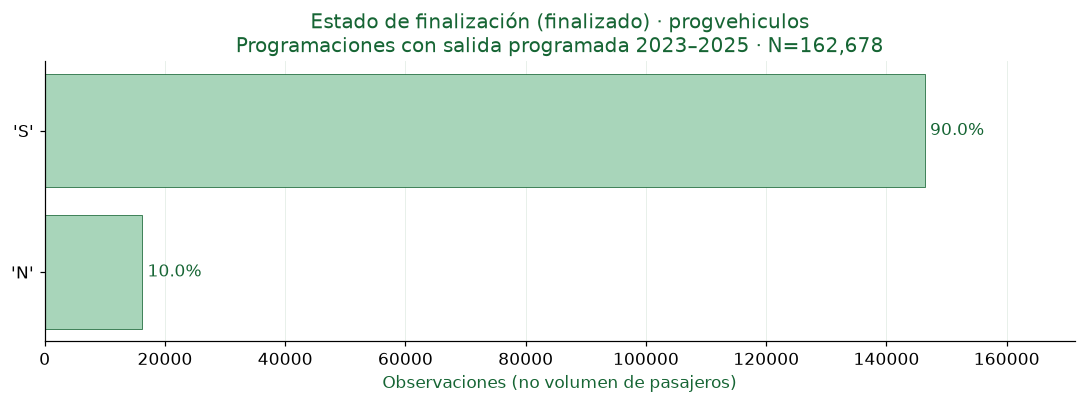

Categoría original,Frecuencia,Es faltante,Denominador,Porcentaje,Etiqueta visual,Alcance
'N',146427,False,162678,90.010327,'N',Programaciones con salida programada 2023–2025
'S',16251,False,162678,9.989673,'S',Programaciones con salida programada 2023–2025
,0,True,162678,0.000000,,Programaciones con salida programada 2023–2025


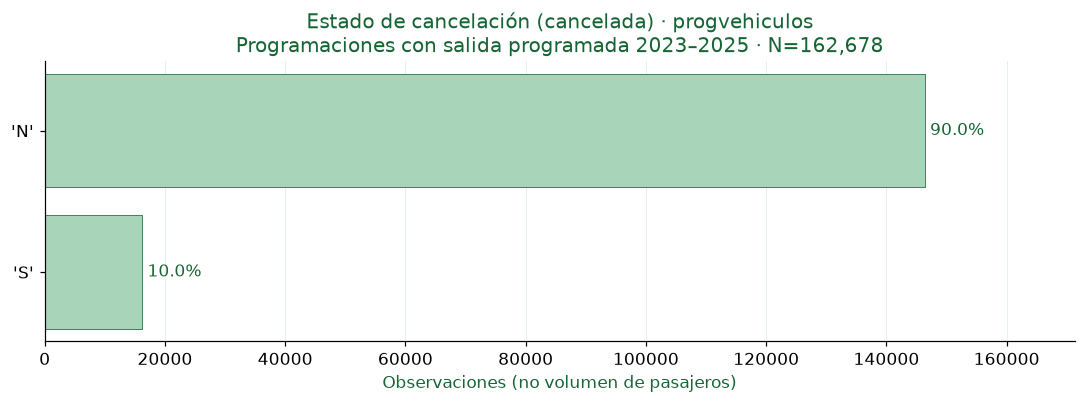

Categoría original,Frecuencia,Es faltante,Denominador,Porcentaje,Etiqueta visual,Alcance
,162678,True,162678,100.000000,,Programaciones con salida programada 2023–2025


Categoría original,Frecuencia,Es faltante,Denominador,Porcentaje,Etiqueta visual,Alcance
'N',162675,False,162678,99.998156,'N',Programaciones con salida programada 2023–2025
'S',3,False,162678,0.001844,'S',Programaciones con salida programada 2023–2025
,0,True,162678,0.000000,,Programaciones con salida programada 2023–2025


Categoría original,Frecuencia,Es faltante,Denominador,Porcentaje,Etiqueta visual,Alcance
False,162678,False,162678,100.000000,False,Programaciones con salida programada 2023–2025
,0,True,162678,0.000000,,Programaciones con salida programada 2023–2025


Categoría original,Frecuencia,Es faltante,Denominador,Porcentaje,Etiqueta visual,Alcance
False,162678,False,162678,100.000000,False,Programaciones con salida programada 2023–2025
,0,True,162678,0.000000,,Programaciones con salida programada 2023–2025


Categoría original,Frecuencia,Es faltante,Denominador,Porcentaje,Etiqueta visual,Alcance
True,162678,False,162678,100.000000,True,Programaciones con salida programada 2023–2025
,0,True,162678,0.000000,,Programaciones con salida programada 2023–2025


Categoría original,Frecuencia,Es faltante,Denominador,Porcentaje,Etiqueta visual,Orden,Alcance
'2016',41,False,293,13.993174,'2016',2016.000000,"Catálogo extraído; estado actual, sin historia 2023–2025"
'2020',36,False,293,12.286689,'2020',2020.000000,"Catálogo extraído; estado actual, sin historia 2023–2025"
'2008',18,False,293,6.143345,'2008',2008.000000,"Catálogo extraído; estado actual, sin historia 2023–2025"
'2010',18,False,293,6.143345,'2010',2010.000000,"Catálogo extraído; estado actual, sin historia 2023–2025"
'2018',17,False,293,5.802048,'2018',2018.000000,"Catálogo extraído; estado actual, sin historia 2023–2025"
'2011',15,False,293,5.119454,'2011',2011.000000,"Catálogo extraído; estado actual, sin historia 2023–2025"
'2019',15,False,293,5.119454,'2019',2019.000000,"Catálogo extraído; estado actual, sin historia 2023–2025"
'2023',13,False,293,4.436860,'2023',2023.000000,"Catálogo extraído; estado actual, sin historia 2023–2025"
'2022',12,False,293,4.095563,'2022',2022.000000,"Catálogo extraído; estado actual, sin historia 2023–2025"
'2017',10,False,293,3.412969,'2017',2017.000000,"Catálogo extraído; estado actual, sin historia 2023–2025"


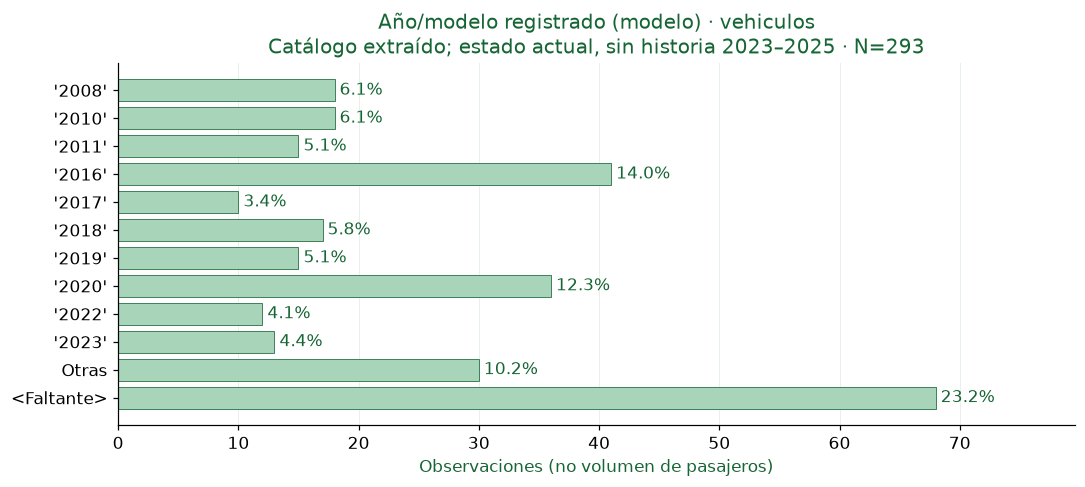

Categoría original,Frecuencia,Es faltante,Denominador,Porcentaje,Etiqueta visual,Alcance
'CHEVROLET',70,False,293,23.890785,'CHEVROLET',"Catálogo extraído; estado actual, sin historia 2023–2025"
'CHEVROLET NQR',53,False,293,18.088737,'CHEVROLET NQR',"Catálogo extraído; estado actual, sin historia 2023–2025"
'CHEVROLET NPR',50,False,293,17.064846,'CHEVROLET NPR',"Catálogo extraído; estado actual, sin historia 2023–2025"
'NQR',27,False,293,9.215017,'NQR',"Catálogo extraído; estado actual, sin historia 2023–2025"
'CHEVROLET B70',14,False,293,4.778157,'CHEVROLET B70',"Catálogo extraído; estado actual, sin historia 2023–2025"
'AGRALE',10,False,293,3.412969,'AGRALE',"Catálogo extraído; estado actual, sin historia 2023–2025"
'HINO',8,False,293,2.730375,'HINO',"Catálogo extraído; estado actual, sin historia 2023–2025"
'AGRALES',4,False,293,1.365188,'AGRALES',"Catálogo extraído; estado actual, sin historia 2023–2025"
'CHEVROLET FRR',3,False,293,1.023891,'CHEVROLET FRR',"Catálogo extraído; estado actual, sin historia 2023–2025"
'FRR',2,False,293,0.682594,'FRR',"Catálogo extraído; estado actual, sin historia 2023–2025"


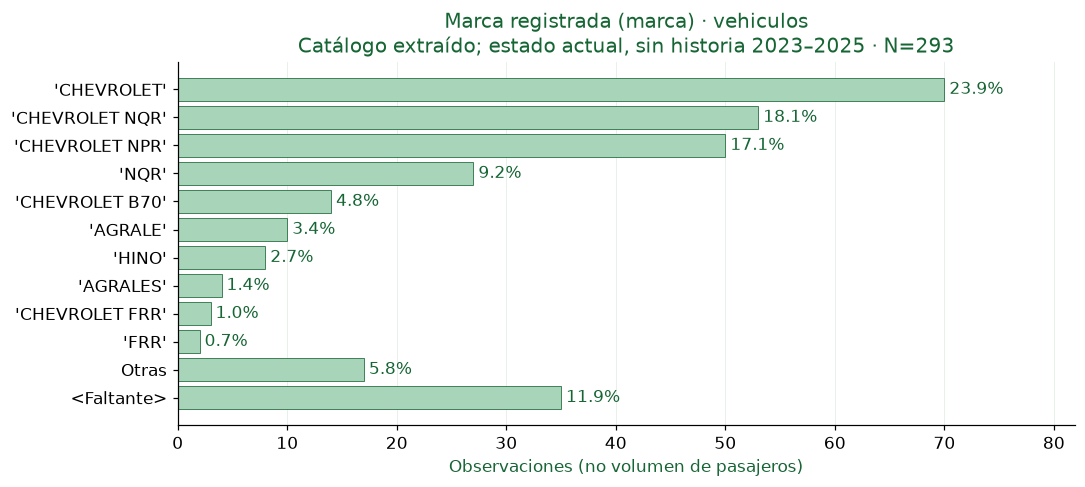

Categoría original,Frecuencia,Es faltante,Denominador,Porcentaje,Etiqueta visual,Alcance
'Y',260,False,293,88.737201,'Y',"Catálogo extraído; estado actual, sin historia 2023–2025"
'N',33,False,293,11.262799,'N',"Catálogo extraído; estado actual, sin historia 2023–2025"
,0,True,293,0.000000,,"Catálogo extraído; estado actual, sin historia 2023–2025"


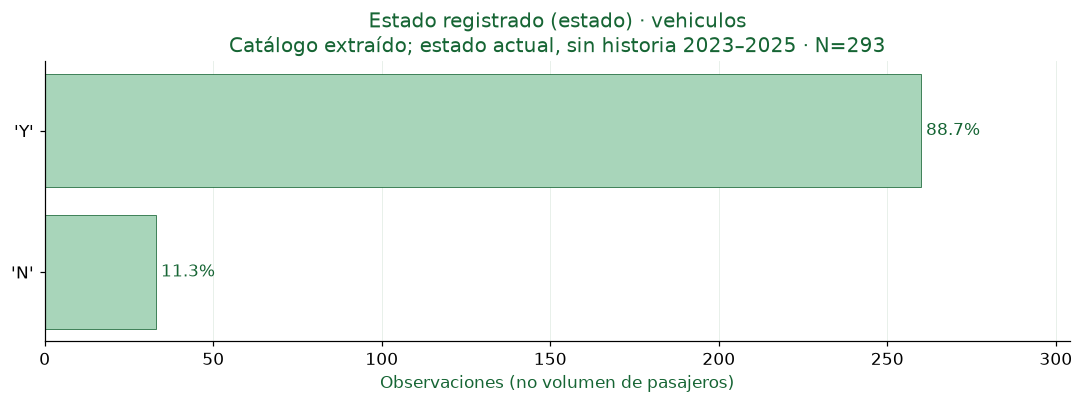

Categoría original,Frecuencia,Es faltante,Denominador,Porcentaje,Etiqueta visual,Alcance
'1',140,False,293,47.781570,'1',"Catálogo extraído; estado actual, sin historia 2023–2025"
'2',113,False,293,38.566553,'2',"Catálogo extraído; estado actual, sin historia 2023–2025"
'24',28,False,293,9.556314,'24',"Catálogo extraído; estado actual, sin historia 2023–2025"
,12,True,293,4.095563,,"Catálogo extraído; estado actual, sin historia 2023–2025"


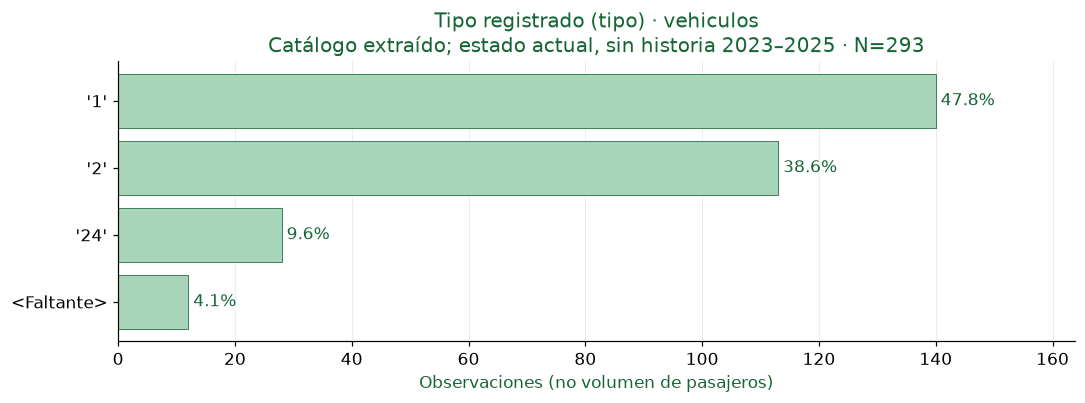

Categoría original,Frecuencia,Es faltante,Denominador,Porcentaje,Etiqueta visual,Alcance
,290,True,293,98.976109,,"Catálogo extraído; estado actual, sin historia 2023–2025"
'03',3,False,293,1.023891,'03',"Catálogo extraído; estado actual, sin historia 2023–2025"


Categoría original,Frecuencia,Es faltante,Denominador,Porcentaje,Etiqueta visual,Alcance
'AB',275,False,293,93.856655,'AB',"Catálogo extraído; estado actual, sin historia 2023–2025"
,18,True,293,6.143345,,"Catálogo extraído; estado actual, sin historia 2023–2025"


Categoría original,Frecuencia,Es faltante,Denominador,Porcentaje,Etiqueta visual,Alcance
True,268,False,293,91.467577,True,"Catálogo extraído; estado actual, sin historia 2023–2025"
False,25,False,293,8.532423,False,"Catálogo extraído; estado actual, sin historia 2023–2025"
,0,True,293,0.000000,,"Catálogo extraído; estado actual, sin historia 2023–2025"


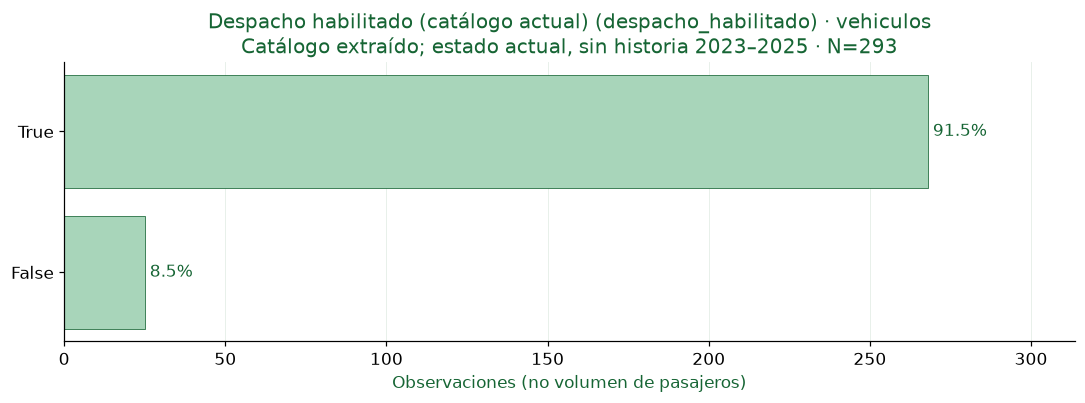

Categoría original,Frecuencia,Es faltante,Denominador,Porcentaje,Etiqueta visual,Orden,Alcance
2023,2502,False,10374,24.117987,2023,2023.000000,Archivo completo: distribución de años
2024,2517,False,10374,24.262580,2024,2024.000000,Archivo completo: distribución de años
2025,2666,False,10374,25.698863,2025,2025.000000,Archivo completo: distribución de años
2026,2689,False,10374,25.920571,2026,2026.000000,Archivo completo: distribución de años
,0,True,10374,0.000000,,nan,Archivo completo: distribución de años


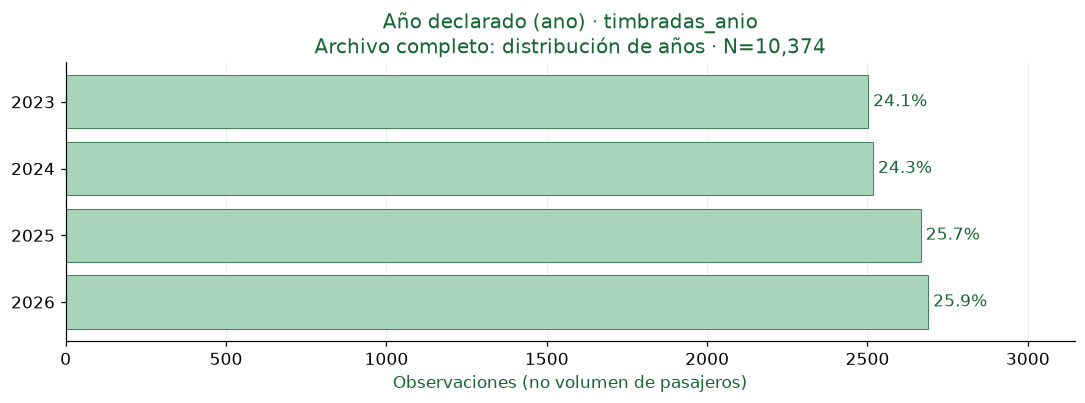

Categoría original,Frecuencia,Es faltante,Denominador,Porcentaje,Etiqueta visual,Orden,Alcance
2023,2502,False,7685,32.556929,2023,2023.000000,"Reto 2023–2025, seleccionado por ano"
2024,2517,False,7685,32.752115,2024,2024.000000,"Reto 2023–2025, seleccionado por ano"
2025,2666,False,7685,34.690956,2025,2025.000000,"Reto 2023–2025, seleccionado por ano"
,0,True,7685,0.000000,,nan,"Reto 2023–2025, seleccionado por ano"


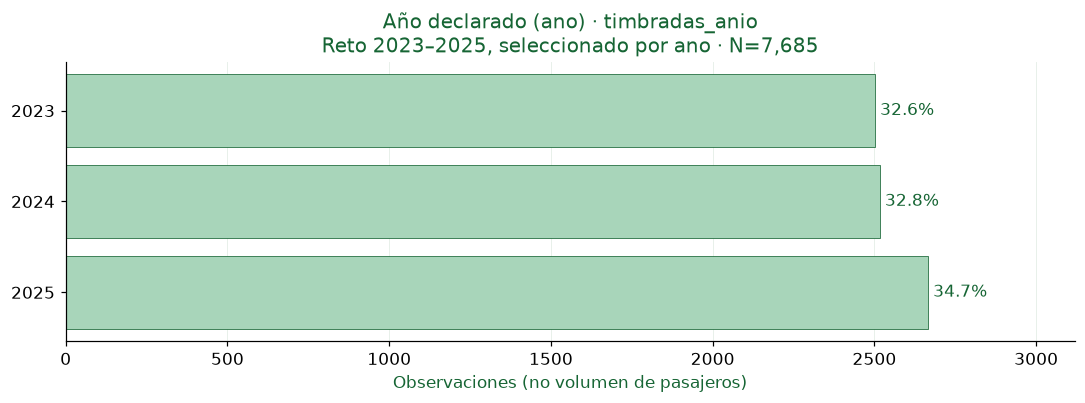

Categoría original,Frecuencia,Es faltante,Denominador,Porcentaje,Etiqueta visual,Orden,Alcance
1,2597,False,7685,33.793103,Lunes,0.000000,"Reto 2023–2025, seleccionado por ano"
2,778,False,7685,10.123617,Martes,1.000000,"Reto 2023–2025, seleccionado por ano"
3,848,False,7685,11.034483,Miércoles,2.000000,"Reto 2023–2025, seleccionado por ano"
4,978,False,7685,12.726090,Jueves,3.000000,"Reto 2023–2025, seleccionado por ano"
5,772,False,7685,10.045543,Viernes,4.000000,"Reto 2023–2025, seleccionado por ano"
6,840,False,7685,10.930384,Sábado,5.000000,"Reto 2023–2025, seleccionado por ano"
7,872,False,7685,11.346779,Domingo,6.000000,"Reto 2023–2025, seleccionado por ano"
,0,True,7685,0.000000,,7.000000,"Reto 2023–2025, seleccionado por ano"


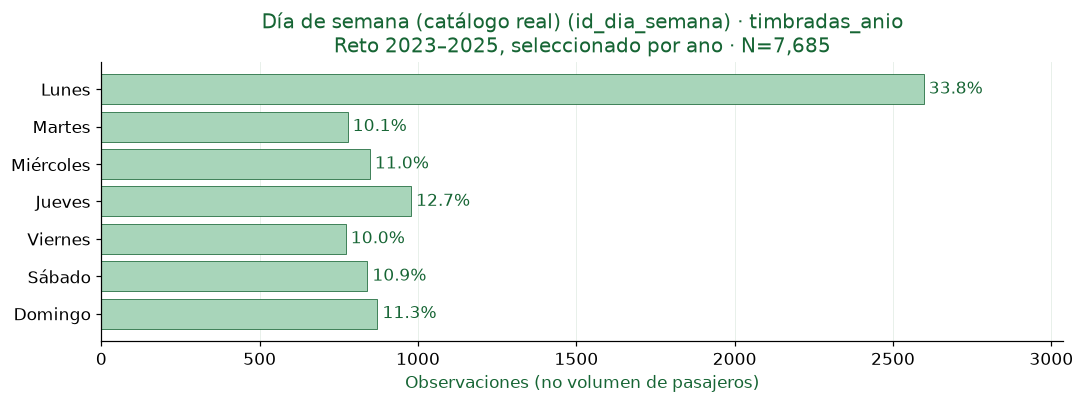

Categoría original,Frecuencia,Es faltante,Denominador,Porcentaje,Etiqueta visual,Orden,Alcance
1,1139,False,3562,31.976418,Lunes,0.000000,Archivo histórico sin año; período de cálculo no confirmado
2,347,False,3562,9.741718,Martes,1.000000,Archivo histórico sin año; período de cálculo no confirmado
3,457,False,3562,12.829871,Miércoles,2.000000,Archivo histórico sin año; período de cálculo no confirmado
4,490,False,3562,13.756317,Jueves,3.000000,Archivo histórico sin año; período de cálculo no confirmado
5,326,False,3562,9.152162,Viernes,4.000000,Archivo histórico sin año; período de cálculo no confirmado
6,351,False,3562,9.854015,Sábado,5.000000,Archivo histórico sin año; período de cálculo no confirmado
7,452,False,3562,12.689500,Domingo,6.000000,Archivo histórico sin año; período de cálculo no confirmado
,0,True,3562,0.000000,,7.000000,Archivo histórico sin año; período de cálculo no confirmado


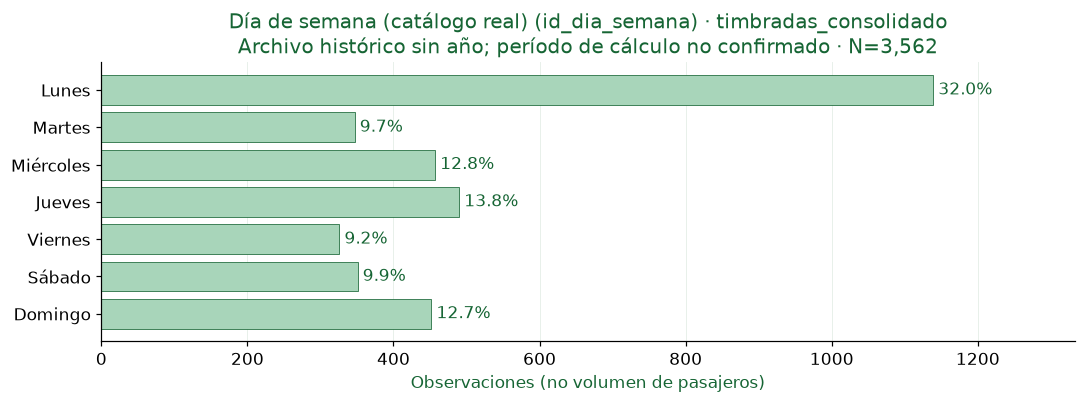

Categoría original,Frecuencia,Es faltante,Denominador,Porcentaje,Etiqueta visual,Alcance
True,135,False,135,100.000000,True,Archivo entregado; etiquetas del catálogo
,0,True,135,0.000000,,Archivo entregado; etiquetas del catálogo


Categoría original,Frecuencia,Es faltante,Denominador,Porcentaje,Etiqueta visual,Alcance
'FESTIVO_NACIONAL',19,False,24,79.166667,'FESTIVO_NACIONAL',Archivo entregado; etiquetas del catálogo
'FIESTA_ATLANTICO',2,False,24,8.333333,'FIESTA_ATLANTICO',Archivo entregado; etiquetas del catálogo
'TEMPORADA_NACIONAL',1,False,24,4.166667,'TEMPORADA_NACIONAL',Archivo entregado; etiquetas del catálogo
'DIAS_CORRIENTES',1,False,24,4.166667,'DIAS_CORRIENTES',Archivo entregado; etiquetas del catálogo
'FIESTAS_PATRONALES',1,False,24,4.166667,'FIESTAS_PATRONALES',Archivo entregado; etiquetas del catálogo
,0,True,24,0.000000,,Archivo entregado; etiquetas del catálogo


Categoría original,Frecuencia,Es faltante,Denominador,Porcentaje,Etiqueta visual,Alcance
'LLUVIA_LEVE',1,False,59,1.694915,'LLUVIA_LEVE',Archivo entregado; etiquetas del catálogo
'LLUVIA_FUERTE',1,False,59,1.694915,'LLUVIA_FUERTE',Archivo entregado; etiquetas del catálogo
'TORMENTA',1,False,59,1.694915,'TORMENTA',Archivo entregado; etiquetas del catálogo
'INUNDACION',1,False,59,1.694915,'INUNDACION',Archivo entregado; etiquetas del catálogo
'OLA_CALOR',1,False,59,1.694915,'OLA_CALOR',Archivo entregado; etiquetas del catálogo
'VENDAVAL',1,False,59,1.694915,'VENDAVAL',Archivo entregado; etiquetas del catálogo
'PARTIDO_SELECCION',1,False,59,1.694915,'PARTIDO_SELECCION',Archivo entregado; etiquetas del catálogo
'PARTIDO_JUNIOR',1,False,59,1.694915,'PARTIDO_JUNIOR',Archivo entregado; etiquetas del catálogo
'FINAL_FUTBOL',1,False,59,1.694915,'FINAL_FUTBOL',Archivo entregado; etiquetas del catálogo
'CLASICO_FUTBOL',1,False,59,1.694915,'CLASICO_FUTBOL',Archivo entregado; etiquetas del catálogo


Categoría original,Frecuencia,Es faltante,Denominador,Porcentaje,Etiqueta visual,Alcance
'Lunes',1,False,7,14.285714,'Lunes',Archivo entregado; etiquetas del catálogo
'Martes',1,False,7,14.285714,'Martes',Archivo entregado; etiquetas del catálogo
'Miércoles',1,False,7,14.285714,'Miércoles',Archivo entregado; etiquetas del catálogo
'Jueves',1,False,7,14.285714,'Jueves',Archivo entregado; etiquetas del catálogo
'Viernes',1,False,7,14.285714,'Viernes',Archivo entregado; etiquetas del catálogo
'Sábado',1,False,7,14.285714,'Sábado',Archivo entregado; etiquetas del catálogo
'Domingo',1,False,7,14.285714,'Domingo',Archivo entregado; etiquetas del catálogo
,0,True,7,0.000000,,Archivo entregado; etiquetas del catálogo


In [23]:
for tabla,columnas in CAT9.items():
    if tabla not in DATOS9: continue
    for c in columnas:
        if c not in DATOS9[tabla]: continue
        serie=DATOS9[tabla][c]
        if tabla=="timbradas_anio":
            if c=="ano":
                categorica9(tabla,c,serie,alcance="Archivo completo: distribución de años",sufijo="_archivo_completo")
            categorica9(tabla,c,serie.loc[periodo_anio9])
            categorica9(tabla,c,serie.loc[ano2026_9],mostrar=False,alcance="Anexo: ano=2026",sufijo="_2026")
        else:
            categorica9(tabla,c,serie,grafico=tabla not in ["estacionalidades","novedades_viales","dias_semana"])

**progvehiculos.finalizado:** Cuenta programaciones por etiqueta registrada, sin inferir demanda ni causas del estado. Faltantes: 0 de 162,678.

**progvehiculos.cancelada:** Cuenta programaciones por etiqueta registrada, sin inferir demanda ni causas del estado. Faltantes: 0 de 162,678.

**progvehiculos.tipo:** Cuenta programaciones por etiqueta registrada, sin inferir demanda ni causas del estado. Faltantes: 162,678 de 162,678.

**progvehiculos.activa:** Casi constante; su significado y vigencia históricos deben confirmarse antes de usarla como indicador operativo. Faltantes: 0 de 162,678.

**progvehiculos.viaje_culminado:** Cuenta programaciones por etiqueta registrada, sin inferir demanda ni causas del estado. Faltantes: 0 de 162,678.

**progvehiculos.modificado_manual:** Cuenta programaciones por etiqueta registrada, sin inferir demanda ni causas del estado. Faltantes: 0 de 162,678.

**progvehiculos.apto_estadisticas_historicas:** Cuenta programaciones por etiqueta registrada, sin inferir demanda ni causas del estado. Faltantes: 0 de 162,678.

**vehiculos.modelo:** Describe el catálogo al momento del archivo; no demuestra el estado o composición de cada fecha de 2023–2025. Faltantes: 68 de 293.

**vehiculos.marca:** Describe el catálogo al momento del archivo; no demuestra el estado o composición de cada fecha de 2023–2025. Faltantes: 35 de 293.

**vehiculos.estado:** Describe el catálogo al momento del archivo; no demuestra el estado o composición de cada fecha de 2023–2025. Faltantes: 0 de 293.

**vehiculos.tipo:** Describe el catálogo al momento del archivo; no demuestra el estado o composición de cada fecha de 2023–2025. Faltantes: 12 de 293.

**vehiculos.tipocombustible:** Describe el catálogo al momento del archivo; no demuestra el estado o composición de cada fecha de 2023–2025. Faltantes: 290 de 293.

**vehiculos.tipo_sensor:** Describe el catálogo al momento del archivo; no demuestra el estado o composición de cada fecha de 2023–2025. Faltantes: 18 de 293.

**vehiculos.despacho_habilitado:** Describe el catálogo al momento del archivo; no demuestra el estado o composición de cada fecha de 2023–2025. Faltantes: 0 de 293.

**timbradas_anio.ano:** Cuenta celdas del alcance declarado; la concentración por categoría no equivale al volumen de pasajeros. Faltantes: 0 de 10,374.

**timbradas_anio.ano:** Cuenta celdas del alcance declarado; la concentración por categoría no equivale al volumen de pasajeros. Faltantes: 0 de 7,685.

**timbradas_anio.id_dia_semana:** Cuenta celdas del alcance declarado; la concentración por categoría no equivale al volumen de pasajeros. Faltantes: 0 de 7,685.

**timbradas_consolidado.id_dia_semana:** Cuenta celdas del alcance declarado; la concentración por categoría no equivale al volumen de pasajeros. Faltantes: 0 de 3,562.

**rutas_segmentos.activo:** Cuenta programaciones por etiqueta registrada, sin inferir demanda ni causas del estado. Faltantes: 0 de 135.

**estacionalidades.estacionalidad:** Cuenta etiquetas de catálogo, no ocurrencias de eventos; sin gráfica de frecuencia operacional. Faltantes: 0 de 24.

**novedades_viales.novedad:** Cuenta etiquetas de catálogo, no ocurrencias de eventos; sin gráfica de frecuencia operacional. Faltantes: 0 de 59.

**dias_semana.dia_semana:** Cuenta etiquetas de catálogo, no ocurrencias de eventos; sin gráfica de frecuencia operacional. Faltantes: 0 de 7.

### **9.6. Fechas y horas: frecuencia de registros, no demanda**
Las marcas sin zona se interpretan como hora local America/Bogota conforme a la extracción; las marcas con zona se convierten a esa zona. Fechas puras no se desplazan. Se exportan solo fechas y horas observadas. Para inicio/fin se evita repetir gráficos casi iguales: rangos y tablas quedan en el anexo y en el diagnóstico de duración. Las horas del agregado anual principal usan únicamente `ano` 2023–2025.

In [24]:
def temporal9(tabla,c,serie,mostrar=True,alcance=None,sufijo=""):
    alcance=alcance or ALCANCES9.get(tabla,"Archivo entregado")
    presentes=serie.dropna();tipo=serie.dtype.pyarrow_dtype
    r={"Fuente":tabla,"Variable":c,"Alcance":alcance,"N considerado":len(serie),"Presentes":len(presentes),"Faltantes":int(serie.isna().sum()),
       "Mínimo":str(presentes.min()) if len(presentes) else None,"Máximo":str(presentes.max()) if len(presentes) else None,"Zona/convenio":"America/Bogota; fechas puras no convertidas"}
    nombre=c+sufijo;guardar9(tabla,nombre+"_rango",pd.DataFrame([r]))
    registrar9(tabla,c,"principal" if mostrar else "secundario",nombre+"_rango.csv")
    if mostrar: display(guardar9(tabla,nombre+"_rango_vista",pd.DataFrame([r])))
    if presentes.empty: return
    if pa.types.is_time(tipo):
        vistas=[("hora",presentes.map(lambda x:x.hour).value_counts().sort_index(),"Hora registrada (local)")]
    else:
        fechas=local9(serie);diaria=fechas.dt.date.value_counts().sort_index()
        guardar9(tabla,nombre+"_fechas_observadas",pd.DataFrame({"Fecha":diaria.index,"Observaciones":diaria.values,"N fuente":len(serie),"Alcance":alcance}))
        vistas=[("mes",fechas.dt.strftime("%Y-%m").value_counts().sort_index(),"Mes observado")]
        if tabla=="progvehiculos" and c=="fechasalida":
            nombres=["Lunes","Martes","Miércoles","Jueves","Viernes","Sábado","Domingo"]
            dias=fechas.dt.dayofweek.value_counts().sort_index()
            dias.index=[nombres[int(i)] for i in dias.index]
            vistas += [("dia_semana",dias,"Día de salida programada"),("hora",fechas.dt.hour.value_counts().sort_index(),"Hora de salida programada (local)")]
    for tipo_vista,grupos,eje in vistas:
        f=pd.DataFrame({"Categoría":grupos.index,"Frecuencia":grupos.values,"N fuente":len(serie),"Alcance":alcance})
        f["Porcentaje del total"]=100*f.Frecuencia/len(serie)
        assert int(grupos.sum())==len(presentes)
        guardar9(tabla,nombre+"_"+tipo_vista,f)
        if not mostrar or len(grupos)<2: continue
        fig,ax=plt.subplots(figsize=(11,4.1))
        ax.bar([str(k) for k in grupos.index],grupos.values,color=VERDE9)
        ax.set(title=f"{TITULOS9.get(c,c)} ({c}) · {tabla}: frecuencia por {tipo_vista}\n{alcance} · N={len(serie):,}; presentes={len(presentes):,}",xlabel=eje,ylabel="Observaciones")
        ax.grid(axis="y");ax.set_axisbelow(True)
        if len(grupos)>12: ax.tick_params(axis="x",rotation=70,labelsize=9)
        figura9(fig,tabla,nombre+"_"+tipo_vista)
        registrar9(tabla,c,"principal",nombre+"_"+tipo_vista+".png",True)
    if mostrar: display(Markdown(f"**{tabla}.{c}:** esta distribución representa la disponibilidad de {UNIDAD9.get(tabla,'registros')} por calendario u horario. La frecuencia no estima demanda; para volúmenes de pasajeros y comparaciones entre días se requiere el análisis posterior, respetando la cobertura de la fuente."))

Fuente,Variable,Alcance,N considerado,Presentes,Faltantes,Mínimo,Máximo,Zona/convenio
progvehiculos,fechasalida,Programaciones con salida programada 2023–2025,162678,162678,0,2023-01-01 05:00:00,2025-12-31 19:00:00,America/Bogota; fechas puras no convertidas


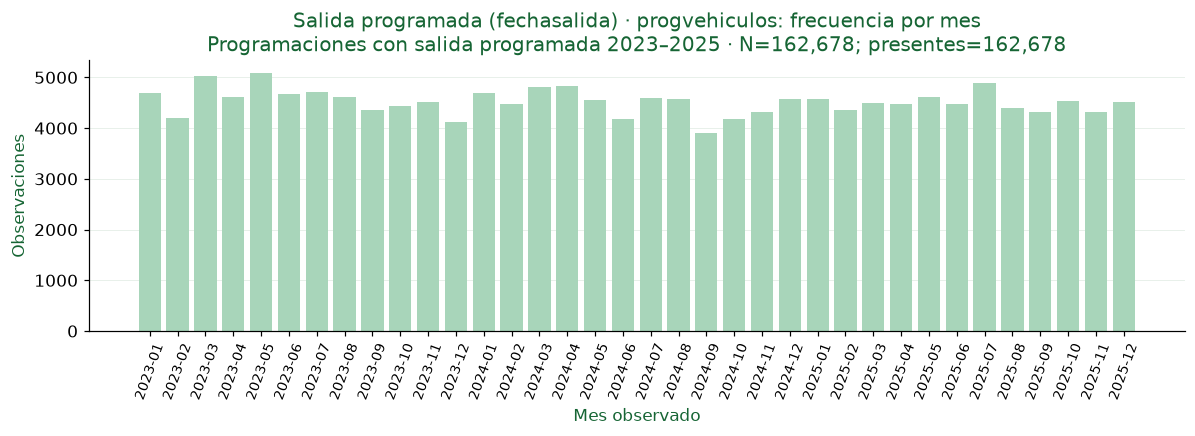

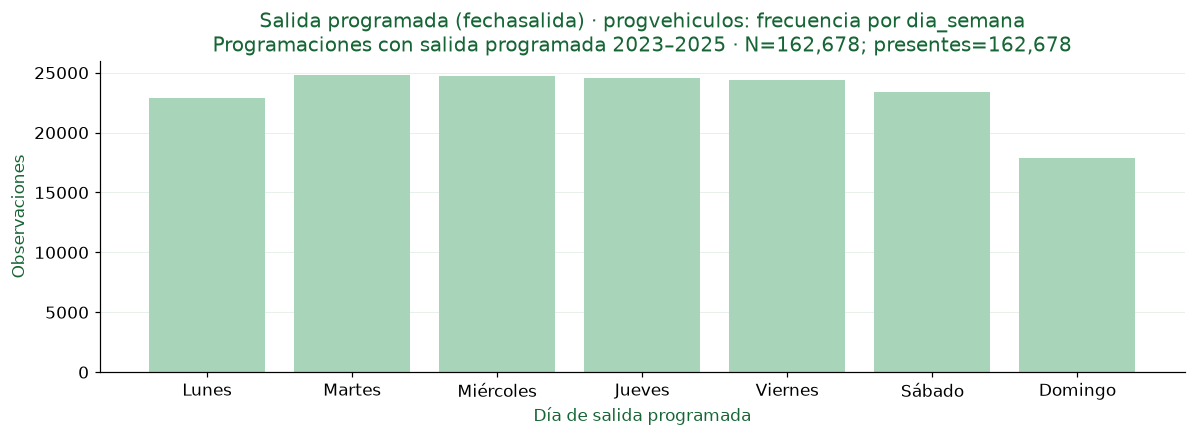

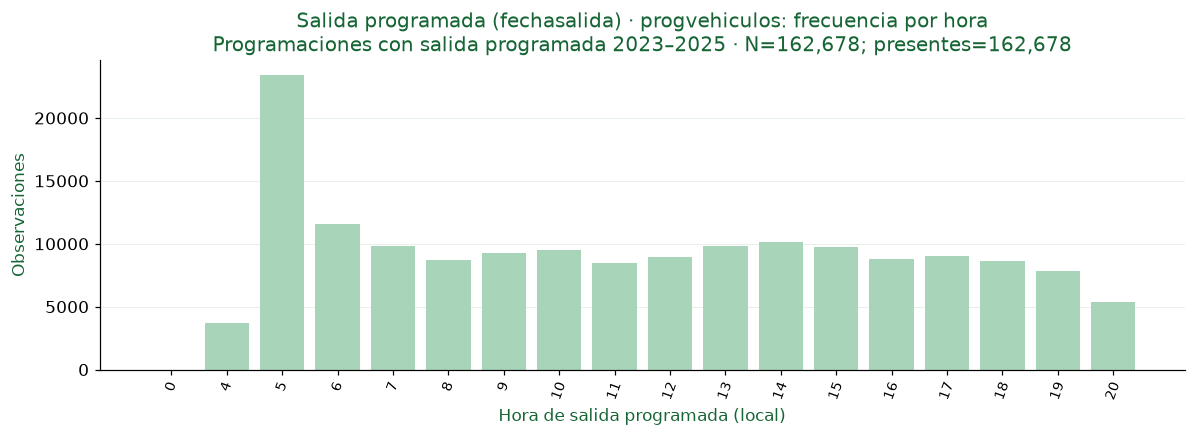

Fuente,Variable,Alcance,N considerado,Presentes,Faltantes,Mínimo,Máximo,Zona/convenio
timbradas_segmentos,fecha,Detalle observado 01-01-2023 a 27-02-2023,799030,799030,0,2023-01-01,2023-02-27,America/Bogota; fechas puras no convertidas


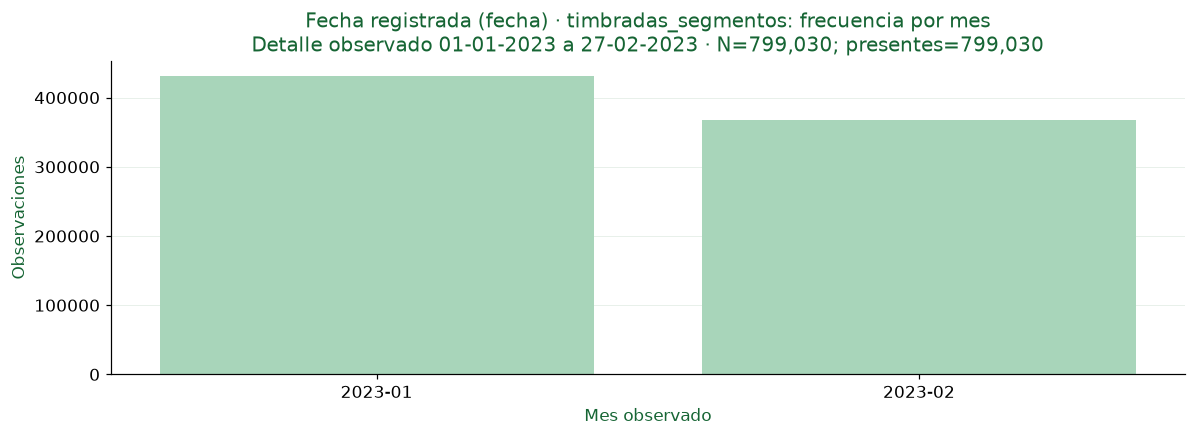

Fuente,Variable,Alcance,N considerado,Presentes,Faltantes,Mínimo,Máximo,Zona/convenio
timbradas_segmentos,hora_inicio,Detalle observado 01-01-2023 a 27-02-2023,799030,799030,0,01:00:00,23:45:00,America/Bogota; fechas puras no convertidas


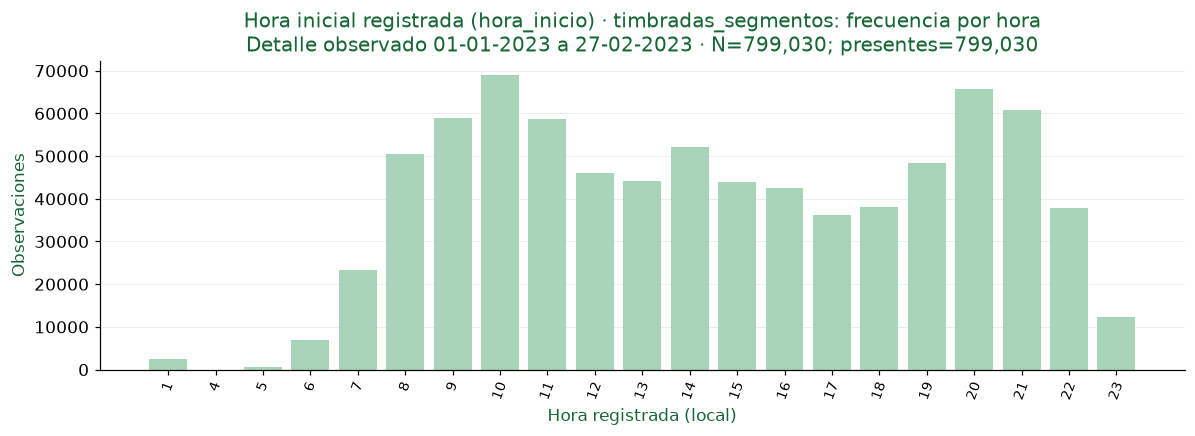

Fuente,Variable,Alcance,N considerado,Presentes,Faltantes,Mínimo,Máximo,Zona/convenio
timbradas_anio,hora,"Reto 2023–2025, seleccionado por ano",7685,7685,0,00:00:00,23:00:00,America/Bogota; fechas puras no convertidas


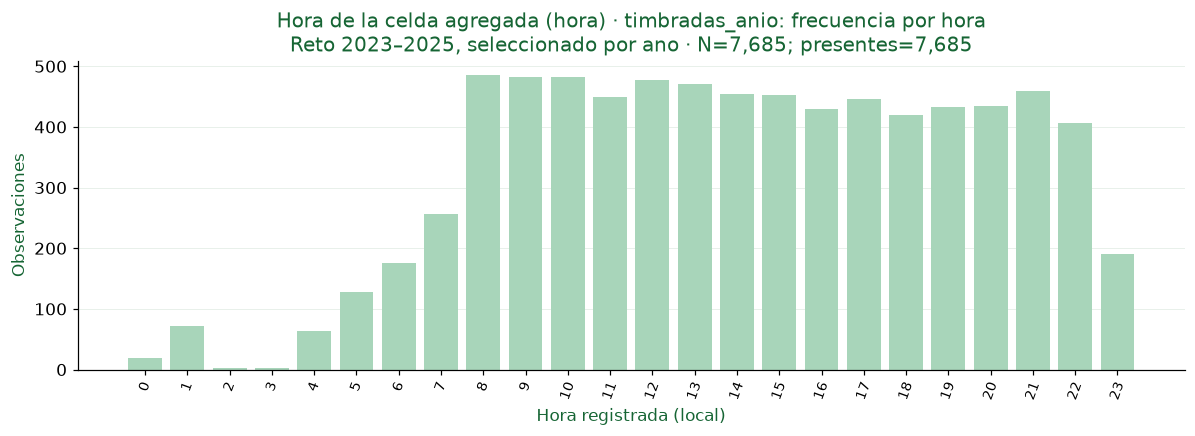

Fuente,Variable,Alcance,N considerado,Presentes,Faltantes,Mínimo,Máximo,Zona/convenio
timbradas_consolidado,hora,Archivo histórico sin año; período de cálculo no confirmado,3562,3562,0,00:00:00,23:00:00,America/Bogota; fechas puras no convertidas


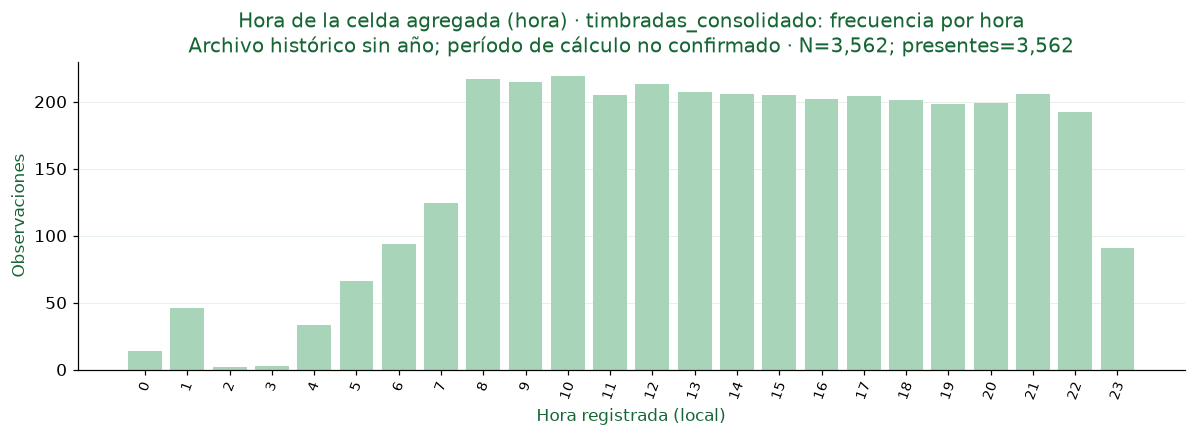

In [25]:
for tabla,columnas in TEMP9.items():
    if tabla not in DATOS9: continue
    for c in columnas:
        if c not in DATOS9[tabla]: continue
        serie=DATOS9[tabla][c]
        # Una hora principal por fuente; inicio/fin y fechas de catálogo quedan como anexo.
        principal=(tabla=="progvehiculos" and c=="fechasalida") or (tabla=="timbradas_segmentos" and c in ["fecha","hora_inicio"]) or (tabla in ["timbradas_anio","timbradas_consolidado"] and c=="hora")
        if tabla=="timbradas_anio":
            temporal9(tabla,c,serie.loc[periodo_anio9],mostrar=principal)
            temporal9(tabla,c,serie,mostrar=False,alcance="Archivo completo; incluye fuera del reto",sufijo="_archivo_completo")
            temporal9(tabla,c,serie.loc[ano2026_9],mostrar=False,alcance="Anexo: ano=2026",sufijo="_2026")
        else: temporal9(tabla,c,serie,mostrar=principal)

**progvehiculos.fechasalida:** esta distribución representa la disponibilidad de programación por calendario u horario. La frecuencia no estima demanda; para volúmenes de pasajeros y comparaciones entre días se requiere el análisis posterior, respetando la cobertura de la fuente.

**timbradas_segmentos.fecha:** esta distribución representa la disponibilidad de registro segmento–viaje por calendario u horario. La frecuencia no estima demanda; para volúmenes de pasajeros y comparaciones entre días se requiere el análisis posterior, respetando la cobertura de la fuente.

**timbradas_segmentos.hora_inicio:** esta distribución representa la disponibilidad de registro segmento–viaje por calendario u horario. La frecuencia no estima demanda; para volúmenes de pasajeros y comparaciones entre días se requiere el análisis posterior, respetando la cobertura de la fuente.

**timbradas_anio.hora:** esta distribución representa la disponibilidad de celda agregada anual por calendario u horario. La frecuencia no estima demanda; para volúmenes de pasajeros y comparaciones entre días se requiere el análisis posterior, respetando la cobertura de la fuente.

**timbradas_consolidado.hora:** esta distribución representa la disponibilidad de celda agregada histórica por calendario u horario. La frecuencia no estima demanda; para volúmenes de pasajeros y comparaciones entre días se requiere el análisis posterior, respetando la cobertura de la fuente.

### **9.7. Perfiles secundarios y cobertura real**
Se exportan perfiles de campos secundarios seguros, sin gráficos administrativos. Los conteos por puerta tienen unidad documentada, pero son componentes de los totales: quedan en el anexo para evitar gráficos redundantes y no se suman automáticamente a los totales. `distancia_recorrida` tiene significado documentado, pero no unidad confirmada; `recaudo_pasajeros` es nulo y no acredita moneda. Estos límites se registran explícitamente. El inventario final distingue ejecución real de interpretación confirmada.

In [26]:
inv9=pd.DataFrame(INVENTARIO9)
UNIDADES_SEC9={"distancia_recorrida":"unidad de distancia no confirmada", "recaudo_pasajeros":"moneda/unidad no confirmada"}
for tabla,df in DATOS9.items():
    for _,fila in inv9.loc[inv9.Fuente.eq(tabla)].iterrows():
        c=fila.Columna
        if c not in df or df.empty or (tabla,c) in PERFILES9: continue
        s=df[c]
        if tabla=="timbradas_anio": s=s.loc[periodo_anio9]
        if fila.Clase=="Numérica":
            if c.startswith(("cantidad_subida","cantidad_bajada","cantidad_bloqueo")): unidad="eventos registrados/programación (componente por puerta)"
            elif c.startswith("acumulada") or c in ["torniqueteinicial","torniquetefinal","timbradas_manuales"]: unidad="conteo/lectura registrada; no flujo neto validado"
            elif c.endswith("_m"): unidad="metros"
            else: unidad=UNIDADES_SEC9.get(c,"unidad secundaria no confirmada")
            numerica9(tabla,c,s,unidad,mostrar=False)
        elif fila.Clase=="Categórica": categorica9(tabla,c,s,mostrar=False)
        elif fila.Clase=="Temporal" and pa.types.is_temporal(s.dtype.pyarrow_dtype): temporal9(tabla,c,s,mostrar=False)
# Derivadas: ninguna sustituye una columna original.
for c,desc in [("duracion_min","(fin-inicio) en minutos; criterio positivo de sección 8"),("desfase_inicio_min","(inicio-salida programada) en minutos; diagnóstico de marcas")]:
    if ("progvehiculos",c) in PERFILES9:
        inv9=pd.concat([inv9,pd.DataFrame([{"Fuente":"progvehiculos","Columna":c,"Clase":"Numérica","Tipo almacenado":"float64 auxiliar; derivada", "Tratamiento":"Pendiente de perfil","Motivo":desc,"Descripción":desc}])],ignore_index=True)

In [27]:
SEMANTICA_PENDIENTE9={
    ("progvehiculos","duracion_min"):"No confirmado recorrido/ciclo/turno; positividad no es validación operativa",
    ("progvehiculos","desfase_inicio_min"):"Diferencia entre marcas, sin regla confirmada de puntualidad",
    ("progvehiculos","distancia_recorrida"):"Unidad de distancia no confirmada",
    ("progvehiculos","activa"):"Indicador casi constante; vigencia y semántica históricas no confirmadas",
    ("timbradas_segmentos","pasajeros"):"Semántica de ocupación no confirmada; incluye negativos"}
for i,r in inv9.iterrows():
    key=(r.Fuente,r.Columna);e=PERFILES9.get(key)
    nivel="Análisis principal con tabla y gráficos pertinentes" if e and e['Nivel']=="principal" else "Perfil secundario exportado" if e else "Sin perfil estadístico"
    inv9.loc[i,"Cobertura ejecutada"]=nivel
    inv9.loc[i,"Reportes"]= "; ".join(e['Archivos']) if e else ""
    inv9.loc[i,"Figuras"]= "; ".join(e['Gráficos']) if e else ""
    motivo=r.Motivo;tratamiento=r.Tratamiento
    if e:
        tratamiento=nivel;motivo="Artefactos generados y registrados tras la ejecución; alcance declarado en cada reporte"
    if tratamiento not in ["Exclusión justificada","Pendiente"] and (r.get("Filas",np.nan)==0 or r.get("Distintos no nulos",np.nan) in [0,1]):
        tratamiento="Descripción limitada"
        motivo="Fuente vacía" if r.get("Filas",np.nan)==0 else "Columna completamente nula" if r.get("Distintos no nulos",np.nan)==0 else "Columna constante; distribución gráfica omitida"
    if key in SEMANTICA_PENDIENTE9:
        tratamiento="Interpretación pendiente";motivo=SEMANTICA_PENDIENTE9[key]
    elif e and e['Nivel']=="secundario" and r.Clase=="Numérica" and tratamiento!="Descripción limitada":
        motivo="Perfil exportado de valores registrados; secundario para el reto. " + ("Componente por puerta; no sumado al total." if r.Columna.startswith("cantidad_") else "Verificar unidad/definición antes de uso operativo.")
    inv9.loc[i,"Tratamiento"]=tratamiento;inv9.loc[i,"Motivo"]=motivo
    inv9.loc[i,"Estado de interpretación"]="Pendiente" if key in SEMANTICA_PENDIENTE9 else "Descriptivo; sin validación operativa" if r.Clase=="Numérica" else "Según diccionario y alcance del archivo"
    inv9.loc[i,"Subtipo semántico"]="Booleana física/codificada" if r.Clase=="Categórica" and ("bool" in str(r.get("Tipo almacenado","")) or r.Columna in ["finalizado","cancelada","activa"]) else "Ordinal: año" if r.Columna in ["ano","modelo"] else "Calendario cíclico del catálogo" if r.Columna=="id_dia_semana" else r.Clase
for tabla in DATOS9:
    guardar9(tabla,"inventario",inv9.loc[inv9.Fuente.eq(tabla)])
display(guardar9("general","cobertura_tratamiento",inv9.groupby(["Fuente","Tratamiento"],dropna=False).size().rename("Columnas").reset_index()))
guardar9("general","inventario_completo",inv9)
guardar9("general","estadisticas_completas",pd.DataFrame(ESTADISTICAS9))
guardar9("general","pendientes",pd.DataFrame(PENDIENTES9,columns=["Fuente","Análisis bloqueado"]))
guardar9("general","figuras",pd.DataFrame(FIGURAS9))

Fuente,Tratamiento,Columnas
Procesos,Descripción limitada,79
Procesos,Exclusión justificada,9
dias_semana,Análisis principal con tabla y gráficos pertinentes,1
dias_semana,Exclusión justificada,1
estacionalidades,Análisis principal con tabla y gráficos pertinentes,1
estacionalidades,Exclusión justificada,4
estacionalidades_anio,Descripción limitada,6
novedades_viales,Análisis principal con tabla y gráficos pertinentes,1
novedades_viales,Exclusión justificada,4
novedades_viales_fecha,Descripción limitada,8


Fuente,Figura,Archivo
progvehiculos,duracion_min_central,reportes_seccion9/progvehiculos/figuras/duracion_min_central.png
progvehiculos,duracion_min_completa,reportes_seccion9/progvehiculos/figuras/duracion_min_completa.png
progvehiculos,numeropasajeros,reportes_seccion9/progvehiculos/figuras/numeropasajeros.png
progvehiculos,numerobajadas,reportes_seccion9/progvehiculos/figuras/numerobajadas.png
progvehiculos,numerobloqueos,reportes_seccion9/progvehiculos/figuras/numerobloqueos.png
progvehiculos,desfase_inicio_min_diagnostico_central,reportes_seccion9/progvehiculos/figuras/desfase_inicio_min_diagnostico_central.png
progvehiculos,desfase_inicio_min_diagnostico_completa,reportes_seccion9/progvehiculos/figuras/desfase_inicio_min_diagnostico_completa.png
timbradas_segmentos,subidas,reportes_seccion9/timbradas_segmentos/figuras/subidas.png
timbradas_segmentos,bajadas,reportes_seccion9/timbradas_segmentos/figuras/bajadas.png
timbradas_segmentos,pasajeros_central,reportes_seccion9/timbradas_segmentos/figuras/pasajeros_central.png


In [28]:
FUENTES_COBERTURA9=[]
for _,r in LECTURAS9.iterrows():
    tipo="Analítica con registros" if r.Filas>0 else "Analítica vacía verificada"
    FUENTES_COBERTURA9.append({"Fuente":r.Fuente,"Tipo de alcance":tipo,"Filas":r.Filas,"Columnas inventariadas":int(inv9.Fuente.eq(r.Fuente).sum()),"Incluida en fuentes analíticas":True})
FUENTES_COBERTURA9 += [{"Fuente":"spatial_ref_sys","Tipo de alcance":"Catálogo técnico separado","Filas":len(SRID9),"Columnas inventariadas":len(CATALOGO_TECNICO9),"Incluida en fuentes analíticas":False}]
for t in sorted(OBJETOS_EXCLUIDOS9):
    FUENTES_COBERTURA9.append({"Fuente":t,"Tipo de alcance":"Objeto técnico excluido antes de carga/inventario","Filas":None,"Columnas inventariadas":0,"Incluida en fuentes analíticas":False})
for _,r in CONTROL9.loc[CONTROL9.Estado.eq("Diferida")].iterrows():
    FUENTES_COBERTURA9.append({"Fuente":r.Tabla,"Tipo de alcance":"Fuente diferida, no entregada","Filas":None,"Columnas inventariadas":0,"Incluida en fuentes analíticas":False})
COBERTURA_FUENTES9=pd.DataFrame(FUENTES_COBERTURA9)
display(guardar9("general","cobertura_fuentes",COBERTURA_FUENTES9))
RESUMEN_COBERTURA9=COBERTURA_FUENTES9.groupby("Tipo de alcance").agg(Fuentes=("Fuente","size"),Columnas_inventariadas=("Columnas inventariadas","sum")).reset_index()
display(guardar9("general","resumen_cobertura_fuentes",RESUMEN_COBERTURA9))

Fuente,Tipo de alcance,Filas,Columnas inventariadas,Incluida en fuentes analíticas
Procesos,Analítica con registros,1.000000,88,True
dias_semana,Analítica con registros,7.000000,2,True
estacionalidades,Analítica con registros,24.000000,5,True
estacionalidades_anio,Analítica vacía verificada,0.000000,6,True
novedades_viales,Analítica con registros,59.000000,5,True
novedades_viales_fecha,Analítica vacía verificada,0.000000,8,True
novedades_viales_ruta,Analítica vacía verificada,0.000000,3,True
progvehiculos,Analítica con registros,162678.000000,75,True
rutas,Analítica con registros,1.000000,43,True
rutas_segmentos,Analítica con registros,135.000000,9,True


Tipo de alcance,Fuentes,Columnas_inventariadas
Analítica con registros,13,430
Analítica vacía verificada,10,89
Catálogo técnico separado,1,5
"Fuente diferida, no entregada",1,0
Objeto técnico excluido antes de carga/inventario,4,0


### **9.8. Controles de ejecución y síntesis calculada**
Se comprueban selecciones por identificador contra la sección 8, los años de las celdas principales, la conservación de frecuencias y las particiones de valores. Los casos sintéticos prueban funciones puras: no escriben reportes ni se agregan a estadísticas reales. Inventariar una columna no equivale a haber realizado un análisis principal, y ejecutar código no confirma una semántica operativa.

In [29]:
# Pruebas aisladas: función pura, sin archivos ni colección de estadísticas reales.
for serie,esperado in [(pd.Series([],dtype=float),0),(pd.Series([np.nan,np.nan]),0),(pd.Series([0.,0.,0.]),3)]:
    r,x=resumen_num9(serie);assert r["Utilizados"]==esperado
    f=frecuencias9(serie);assert int(f.Frecuencia.sum())==len(serie)
prueba9=pd.Series([np.nan,-1.,0.,2.])
r,x=resumen_num9(prueba9,seleccion=prueba9.ge(0))
assert (r['Utilizados'],r['Faltantes'],r['Excluidos no faltantes'],r['Ceros utilizados'])==(2,1,1,1)
assert not CONCILIACION9.Diferencia.ne(0).any(), "Investigar diferencias antes de aprobar"
if p9 is not None:
    assert set(MAYORES_DURACIONES9.idprogramacion)<=set(p9.loc[SELECCIONES9['Duración positiva'],'idprogramacion'])
    assert SELECCIONES9['Duración positiva'].equals((final9 & p9.fechafin.gt(p9.fechainicio)).fillna(False))
    assert p9.loc[SELECCIONES9['Pasajeros disponibles no negativos'],'numeropasajeros'].ge(0).all()
    assert p9.loc[SELECCIONES9['Bajadas disponibles no negativas'],'numerobajadas'].ge(0).all()
if "timbradas_anio" in DATOS9:
    assert anio9.loc[periodo_anio9,'ano'].between(2023,2025).all()
    assert set(anio9.loc[periodo_anio9,'id_timbrada_anio']).isdisjoint(set(anio9.loc[ano2026_9,'id_timbrada_anio']))
    registros_principales9=[r for r in ESTADISTICAS9 if r['Fuente']=='timbradas_anio' and r['Alcance']==ALCANCES9['timbradas_anio']]
    assert all(r['Total considerado']==int(periodo_anio9.sum()) for r in registros_principales9)
    assert int(periodo_anio9.sum())+int(fuera_anio9.sum())==len(anio9)
assert not inv9.Fuente.isin(OBJETOS_EXCLUIDOS9|TECNICOS9).any()
assert not inv9.duplicated(['Fuente','Columna']).any()
for r in ESTADISTICAS9:
    assert r['Total considerado']==r['Utilizados']+r['Faltantes']+r['Excluidos no faltantes']+r['No finitos']
    fila=inv9.loc[inv9.Fuente.eq(r['Fuente']) & inv9.Columna.eq(r['Variable'])]
    assert not fila.Clase.eq('Identificador/código').any()
assert all((PROYECTO9/f['Archivo']).is_file() for f in FIGURAS9)
assert HUELLA_RAW9=={str(f.relative_to(BASE9)):(f.stat().st_size,f.stat().st_mtime_ns)
    for f in (BASE9 / "raw").rglob("*.parquet")}, "RAW cambió durante la ejecución"
# Reportes relacionales existentes: solo evidencia leída, sin nuevas uniones.
for archivo in ['seguridad_uniones','contexto']:
    guardar9('general','evidencia_'+archivo+'_seccion7',pd.read_csv(REL9/(archivo+'.csv')))

In [30]:
manifest9={"Extracción":str(BASE9.relative_to(PROYECTO9)),"Zona":CFG9['zona'],
    "Fuentes analíticas con registros":int(LECTURAS9.Filas.gt(0).sum()),"Fuentes analíticas vacías":int(LECTURAS9.Filas.eq(0).sum()),
    "Columnas analíticas originales":int(inv9['Tipo almacenado'].ne('float64 auxiliar; derivada').sum()),"Derivadas":int(inv9['Tipo almacenado'].eq('float64 auxiliar; derivada').sum()),
    "Catálogos técnicos separados":len(TECNICOS9),"Columnas catálogo técnico":len(CATALOGO_TECNICO9),
    "Objetos técnicos excluidos":len(OBJETOS_EXCLUIDOS9),"Fuentes diferidas":int(CONTROL9.Estado.eq('Diferida').sum()),
    "Figuras":len(FIGURAS9),"Perfiles reales ejecutados":len(PERFILES9),"Sin SQL ni escritura RAW":True,
    "Alcance principal anual":"ano 2023–2025","Selecciones programación":"Recalculadas y contrastadas por idprogramacion con sección 8"}
(OUT9/'manifest.json').write_text(json.dumps(manifest9,ensure_ascii=False,indent=2))
VAL9={"Kernel":"Nuevo, solo sección 9","Conciliación":"Sin diferencias","Filtros anuales":"Comprobados por año e identificador",
    "Frecuencias":"Conservación y porcentajes comprobados","Casos sintéticos":"Aislados de reportes y estadísticas reales",
    "Identificadores":"Sin estadísticas continuas","RAW":"Tamaños y marcas de modificación preservados durante ejecución","Semántica operativa":"Pendiente donde se indica; no certificada por ejecución"}
(OUT9/'VALIDACION.json').write_text(json.dumps(VAL9,ensure_ascii=False,indent=2))
display(Markdown(f"Se ejecutaron perfiles de {len(PERFILES9)} columnas/derivadas y se exportaron {len(FIGURAS9)} figuras. La cobertura por fuente y tratamiento está arriba; las restantes columnas están excluidas, limitadas o pendientes según evidencia. Las selecciones de programación coinciden por identificador con la sección 8."))

Se ejecutaron perfiles de 235 columnas/derivadas y se exportaron 41 figuras. La cobertura por fuente y tratamiento está arriba; las restantes columnas están excluidas, limitadas o pendientes según evidencia. Las selecciones de programación coinciden por identificador con la sección 8.

In [31]:
est9=pd.DataFrame(ESTADISTICAS9)
def resultado9(tabla,c,alcance=None):
    f=est9.loc[est9.Fuente.eq(tabla)&est9.Variable.eq(c)]
    if alcance is not None: f=f.loc[f.Alcance.eq(alcance)]
    return f.iloc[0]
lineas9=['## Síntesis calculada de la sección 9','']
if p9 is not None:
    rd9=resultado9('progvehiculos','duracion_min')
    lineas9 += [f"- Programaciones: {len(p9):,}; finalizadas no canceladas: {int(final9.sum()):,}; duraciones positivas: {int(SELECCIONES9['Duración positiva'].sum()):,}. Negativas: {int((final9 & dur9.lt(0)).sum()):,}; cero: {int((final9 & dur9.eq(0)).sum()):,}.",
        f"- Duración registrada de programación: mediana {rd9['Mediana']:.2f} min, media {rd9['Media']:.2f} min, máximo {rd9['Máximo']:.2f} min ({rd9['Máximo']/1440:.2f} días). El alcance se define por salida; inicio/fin fuera de ventana se detallan en el diagnóstico. Positividad no es validación operativa de recorrido/ciclo/turno."]
    for _,r in CEROS9.iterrows():
        rp9=resultado9('progvehiculos',r.Campo)
        lineas9.append(f"- {r.Campo}: {int(r['N selección']):,} valores seleccionados; {int(r.Ceros):,} ceros ({r['% ceros']:.2f}%). Mediana {rp9['Mediana']:.2f}; media {rp9['Media']:.2f}. Los ceros no son faltantes ni prueban demanda nula.")
    lineas9.append(f"- Ambos conteos ausentes: {int(ambos9.sum()):,}. Junio 2024: {int((ambos9 & junio9).sum()):,}/{int((final9 & junio9).sum()):,} ({100*(ambos9 & junio9).sum()/(final9 & junio9).sum():.2f}%).")
    for c in ['fechainicio','fechafin']:
        fila=FUERA_VENTANA9.loc[FUERA_VENTANA9.Campo.eq(c)&FUERA_VENTANA9.Selección.eq('Todas las programaciones')].iloc[0]
        lineas9.append(f"- {c}: {int(fila['Total fuera']):,} marcas fuera de [{CFG9['inicio']}, {CFG9['fin_exclusivo']}), sobre {int(fila.Presentes):,} presentes de todas las programaciones.")
if t9 is not None:
    rn9=MAGNITUD_NEGATIVOS9.iloc[0]
    lineas9.append(f"- Detalle: {t9.fecha.min()} a {t9.fecha.max()}; negativos en pasajeros: {int(rn9['N negativos']):,}/{int(rn9['N presentes']):,} ({rn9['% negativos']:.2f}%), mínimo {rn9['Mínimo negativo']:.0f} y mediana negativa {rn9['Mediana negativos']:.0f}. Semántica de ocupación no confirmada.")
    if p9 is not None: lineas9.append(f"- Programaciones con detalle: {int(tiene9.sum()):,}; finalizadas sin detalle en ventana: {int(sin9.sum()):,}. En días sin timbradas: {int((sin9 & ~dias9.isin(fechas9)).sum()):,}; en días con timbradas: {int((sin9 & dias9.isin(fechas9)).sum()):,}. Ausencia no equivale a cero demanda.")
if 'timbradas_anio' in DATOS9:
    lineas9.append(f"- Agregado anual principal: {int(periodo_anio9.sum()):,} celdas con ano 2023–2025. Archivo completo: {len(anio9):,}; anexo 2026: {int(ano2026_9.sum()):,}. Las medias de promedios describen celdas con igual peso, no el promedio global por viaje.")
    ra9=resultado9('timbradas_anio','subidas',ALCANCES9['timbradas_anio'])
    lineas9.append(f"- Subidas de celdas anuales 2023–2025: mediana {ra9['Mediana']:.2f}, media {ra9['Media']:.2f}, N utilizado {int(ra9['Utilizados']):,} celdas.")
if 'vehiculos' in DATOS9: lineas9.append(f"- Capacidad cero en {int(v9.capacidad.eq(0).sum()):,}/{len(v9):,} vehículos del catálogo; impide porcentajes de ocupación. No se reemplaza por plazas sentadas más plazas de pie. Estado actual no acredita vigencia histórica.")
lineas9 += ['- El consolidado sin año no tiene período de cálculo confirmado. Extremos IQR son descriptivos, no errores demostrados; con IQR cero el criterio se omite. Excepciones geométricas podrían ser remanentes, sin causa confirmada.',
    '- Las frecuencias de programaciones, celdas o etiquetas no son volumen de pasajeros ni frecuencia de eventos. Distribuciones marginales parecidas no prueban balance por programación. No se habilitan agregados históricos como predictores sin verificar período y disponibilidad.']
lineas9.append(f"- Cobertura: {manifest9['Fuentes analíticas con registros']} fuentes analíticas con registros; {manifest9['Fuentes analíticas vacías']} vacías; {manifest9['Columnas analíticas originales']} columnas originales y {manifest9['Derivadas']} derivadas inventariadas. Hay {manifest9['Catálogos técnicos separados']} catálogo técnico separado, {manifest9['Objetos técnicos excluidos']} objetos técnicos excluidos y {manifest9['Fuentes diferidas']} fuente diferida. Se ejecutaron perfiles de {len(PERFILES9)} columnas/derivadas; el inventario informa cuáles.")
sintesis9='\n'.join(lineas9)
(OUT9/'SINTESIS.md').write_text(sintesis9,encoding='utf-8')
display(Markdown(sintesis9))

## Síntesis calculada de la sección 9

- Programaciones: 162,678; finalizadas no canceladas: 146,416; duraciones positivas: 146,279. Negativas: 16; cero: 121.
- Duración registrada de programación: mediana 242.58 min, media 268.68 min, máximo 133909.32 min (92.99 días). El alcance se define por salida; inicio/fin fuera de ventana se detallan en el diagnóstico. Positividad no es validación operativa de recorrido/ciclo/turno.
- numeropasajeros: 145,198 valores seleccionados; 3,708 ceros (2.55%). Mediana 75.00; media 78.07. Los ceros no son faltantes ni prueban demanda nula.
- numerobajadas: 145,198 valores seleccionados; 3,296 ceros (2.27%). Mediana 73.00; media 76.24. Los ceros no son faltantes ni prueban demanda nula.
- Ambos conteos ausentes: 1,218. Junio 2024: 176/3,660 (4.81%).
- fechainicio: 3 marcas fuera de [2023-01-01, 2026-01-01), sobre 161,595 presentes de todas las programaciones.
- fechafin: 16 marcas fuera de [2023-01-01, 2026-01-01), sobre 146,416 presentes de todas las programaciones.
- Detalle: 2023-01-01 a 2023-02-27; negativos en pasajeros: 315,974/799,030 (39.54%), mínimo -104167 y mediana negativa -7386. Semántica de ocupación no confirmada.
- Programaciones con detalle: 7,519; finalizadas sin detalle en ventana: 361. En días sin timbradas: 311; en días con timbradas: 50. Ausencia no equivale a cero demanda.
- Agregado anual principal: 7,685 celdas con ano 2023–2025. Archivo completo: 10,374; anexo 2026: 2,689. Las medias de promedios describen celdas con igual peso, no el promedio global por viaje.
- Subidas de celdas anuales 2023–2025: mediana 128.00, media 1528.35, N utilizado 7,685 celdas.
- Capacidad cero en 293/293 vehículos del catálogo; impide porcentajes de ocupación. No se reemplaza por plazas sentadas más plazas de pie. Estado actual no acredita vigencia histórica.
- El consolidado sin año no tiene período de cálculo confirmado. Extremos IQR son descriptivos, no errores demostrados; con IQR cero el criterio se omite. Excepciones geométricas podrían ser remanentes, sin causa confirmada.
- Las frecuencias de programaciones, celdas o etiquetas no son volumen de pasajeros ni frecuencia de eventos. Distribuciones marginales parecidas no prueban balance por programación. No se habilitan agregados históricos como predictores sin verificar período y disponibilidad.
- Cobertura: 13 fuentes analíticas con registros; 10 vacías; 517 columnas originales y 2 derivadas inventariadas. Hay 1 catálogo técnico separado, 4 objetos técnicos excluidos y 1 fuente diferida. Se ejecutaron perfiles de 235 columnas/derivadas; el inventario informa cuáles.

## **10. Análisis exploratorio bivariado**

Ruta **SILENCIO, id 2**. Se comparan conteos registrados por programación, estados y detalle por segmento, conservando sus poblaciones. Las asociaciones son descriptivas: no estiman efectos causales ni prueban independencia entre programaciones repetidas por vehículo y fecha. No se aplican pruebas de significación automáticas ni se habilitan resultados posteriores o agregados históricos como predictores.

**Ejecución:** después de la sección 9, ejecutar las celdas de **10.1 a 10.8 en orden**. Si se reinicia el kernel, basta empezar en **10.1**: esta sección carga sus columnas y criterios desde los archivos existentes, sin ejecutar 1–9 ni la extracción. Requiere pandas, numpy, pyarrow, matplotlib e IPython. Si el directorio del kernel no es el proyecto, definir `EDA10_PROYECTO`. Las salidas nuevas están en `reportes_seccion10/`; no se modifican RAW ni los reportes anteriores.

### **10.1. Alcance y preparación mínima**
**Pregunta:** ¿qué poblaciones y unidades sostienen cada comparación? La fecha del calendario es `fechasalida`, con zona America/Bogota. Las marcas SQL sin zona se interpretan en esa zona conforme a la configuración; las marcas con zona se convierten. Las etiquetas de día proceden del catálogo y se vinculan por su nombre de calendario, no por equivalencia automática entre sus códigos y `dayofweek`.

In [1]:
from pathlib import Path
import os, json, ast, hashlib
import pandas as pd
import numpy as np
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import MaxNLocator, StrMethodFormatter
from IPython.display import display, Markdown
PROYECTO10 = Path(os.environ.get('EDA10_PROYECTO', '.')).resolve()
BASE10 = PROYECTO10/'salidas_extraccion/ruta_2/20261012T024407_20362e05'
OUT10 = PROYECTO10/'reportes_seccion10'
OUT10.mkdir(exist_ok=True)
CFG10 = json.loads((BASE10/'configuracion.json').read_text())
FUENTES10 = json.loads((BASE10/'fuentes.json').read_text())
EXCLUIDOS10 = {'geometry_columns','geography_columns','raster_columns','raster_overviews','spatial_ref_sys'}
RAW10 = {t:BASE10/p for t,p in FUENTES10.items() if t not in EXCLUIDOS10}
HUELLA10 = {str(f.relative_to(BASE10)):(f.stat().st_size,f.stat().st_mtime_ns) for f in (BASE10/'raw').rglob('*.parquet')}
VERDE10, OSCURO10 = '#A8D5BA', '#166534'
MAPA10 = LinearSegmentedColormap.from_list('sobusa10',['#eef8f0',VERDE10,OSCURO10])
plt.rcParams.update({'figure.facecolor':'white','axes.facecolor':'white','font.family':'DejaVu Sans',
    'font.size':11,'axes.titlesize':12,'axes.titlecolor':OSCURO10,'axes.labelcolor':OSCURO10,
    'axes.spines.top':False,'axes.spines.right':False,'grid.color':'#E6EFE9','grid.linewidth':.6})
FIGURAS10, CONTROLES10, HALLAZGOS10, BLOQUEOS10 = [], [], [], []
CAMPOS10 = {'numeropasajeros':'Abordajes registrados','numerobajadas':'Bajadas registradas'}

In [2]:
def tabla10(fuente, nombre, df, mostrar=True):
    carpeta=OUT10/fuente; carpeta.mkdir(parents=True,exist_ok=True)
    df.to_csv(carpeta/f'{nombre}.csv',index=False,encoding='utf-8-sig')
    vista=df.style.format(precision=2,na_rep='Sin datos').set_table_styles([
        {'selector':'th','props':[('background-color',VERDE10),('color',OSCURO10)]},
        {'selector':'td','props':[('border-bottom','1px solid #E6EFE9')]}]).hide(axis='index')
    (carpeta/f'{nombre}.html').write_text(vista.to_html(),encoding='utf-8')
    if mostrar: display(vista)
    return df

def figura10(fig, fuente, nombre):
    carpeta=OUT10/fuente/'figuras';carpeta.mkdir(parents=True,exist_ok=True)
    fig.tight_layout()
    for ext in ['png','svg']: fig.savefig(carpeta/f'{nombre}.{ext}',dpi=170,bbox_inches='tight')
    FIGURAS10.append({'Fuente':fuente,'Figura':nombre,'PNG':str((carpeta/f'{nombre}.png').relative_to(OUT10))})
    plt.show();plt.close(fig)

def leer10(tabla, columnas):
    partes=sorted(RAW10[tabla].glob('parte-*.parquet'))
    if not partes:
        BLOQUEOS10.append({'Fuente':tabla,'Limitación':'Sin partes Parquet para las columnas necesarias'})
        return None
    return pq.read_table(partes,columns=columnas).to_pandas(types_mapper=pd.ArrowDtype)

def bogota10(serie):
    f=pd.to_datetime(serie,errors='raise')
    return f.dt.tz_localize(CFG10['zona']) if f.dt.tz is None else f.dt.tz_convert(CFG10['zona'])

In [3]:
# Lectura proyectada de RAW, con tipos Arrow; no se lee p8 ni REL_DATOS.
p10=leer10('progvehiculos',['idprogramacion','idvehiculo','idruta','fechasalida','fechainicio','fechafin',
    'finalizado','cancelada','numeropasajeros','numerobajadas','tipo','grupo'])
t10=leer10('timbradas_segmentos',['id_timbrada_segmento','id_segmento','id_viaje','fecha','subidas','bajadas'])
s10=leer10('rutas_segmentos',['id','id_config','idruta','nro_segmento'])
dias10=leer10('dias_semana',['id_dia_semana','dia_semana'])
v10=leer10('vehiculos',['idvehiculo','capacidad'])
a10=leer10('timbradas_anio',['ano'])
# La fuente central es imprescindible; otros bloques informan su ausencia y se omiten.
if p10 is None: raise FileNotFoundError('Falta RAW progvehiculos: bloquea las comparaciones de programación')
assert p10.idprogramacion.is_unique and p10.idprogramacion.notna().all()
assert p10.idruta.eq(2).all() and CFG10['zona']=='America/Bogota'
DICC10={}
for nombre in ['progvehiculos','timbradas_segmentos','rutas_segmentos','dias_semana']:
    archivo=PROYECTO10/f'EDA/diccionarios/diccionario_{nombre}.py'
    for nodo in ast.parse(archivo.read_text()).body:
        if isinstance(nodo,ast.Assign): DICC10[nombre]=ast.literal_eval(nodo.value)
EVIDENCIA10=pd.DataFrame([{'Fuente':t,'Campo':c,'Descripción':DICC10[t][c]['descripcion'],
    'Significado':DICC10[t][c]['significado']} for t,cols in {
    'progvehiculos':['numeropasajeros','numerobajadas','finalizado','cancelada','fechasalida','fechainicio','fechafin'],
    'timbradas_segmentos':['subidas','bajadas','id_segmento','id_viaje']}.items() for c in cols])
tabla10('general','evidencia_diccionarios',EVIDENCIA10,mostrar=False)

,Fuente,Campo,Descripción,Significado
0,progvehiculos,numeropasajeros,Total de pasajeros transportados (subidas).,Cantidad total de pasajeros que subieron duran...
1,progvehiculos,numerobajadas,Total de bajadas del viaje.,Cantidad total de pasajeros que bajaron durant...
2,progvehiculos,finalizado,Estado: viaje finalizado (S/N).,Indica si el viaje llegó a completarse.
3,progvehiculos,cancelada,Si el viaje fue cancelado (S/N).,Indica si el viaje programado terminó siendo c...
4,progvehiculos,fechasalida,Fecha/hora programada de salida.,Momento en que estaba programado que el vehícu...
5,progvehiculos,fechainicio,Inicio efectivo del viaje.,Momento en que el viaje realmente comenzó (pue...
6,progvehiculos,fechafin,Fin efectivo del viaje.,Momento en que el viaje realmente terminó.
7,timbradas_segmentos,subidas,Subidas en el segmento para ese viaje.,Cantidad de pasajeros que subieron específicam...
8,timbradas_segmentos,bajadas,Bajadas en el segmento para ese viaje.,Cantidad de pasajeros que bajaron específicame...
9,timbradas_segmentos,id_segmento,FK a rutas_segmentos.id.,Referencia a cuál segmento de la ruta correspo...


In [4]:
salida10=bogota10(p10.fechasalida)
inicio10,fin10=bogota10(p10.fechainicio),bogota10(p10.fechafin)
limites10=[pd.Timestamp(CFG10[c],tz=CFG10['zona']) for c in ['inicio','fin_exclusivo']]
assert salida10.notna().all() and salida10.between(limites10[0],limites10[1],inclusive='left').all()
final10=(p10.finalizado.eq('S') & p10.cancelada.eq('N')).fillna(False)
validos10={c:(final10 & p10[c].notna() & p10[c].ge(0)).fillna(False) for c in CAMPOS10}
pares10=validos10['numeropasajeros'] & validos10['numerobajadas']
duracion10=(fin10-inicio10).dt.total_seconds()/60
positiva10=(final10 & duracion10.gt(0)).fillna(False)
p10['hora10']=salida10.dt.hour
p10['ano10']=salida10.dt.year
p10['mes10']=salida10.dt.strftime('%Y-%m')
# El orden se fija por calendario; los códigos se recuperan por etiquetas verificadas.
ORDEN_DIAS10=['Lunes','Martes','Miércoles','Jueves','Viernes','Sábado','Domingo']
if dias10 is None: raise FileNotFoundError('Falta dias_semana: bloquea la validación del calendario')
assert dias10.id_dia_semana.is_unique and dias10.dia_semana.is_unique
assert set(dias10.dia_semana)==set(ORDEN_DIAS10)
nombres10=salida10.dt.dayofweek.map(dict(enumerate(ORDEN_DIAS10)))
p10['dia10']=pd.Categorical(nombres10,categories=ORDEN_DIAS10,ordered=True)
mapa_codigo10=dias10.set_index('dia_semana').id_dia_semana.to_dict()
p10['codigo_dia10']=nombres10.map(mapa_codigo10)
assert p10.codigo_dia10.notna().all()
tabla10('general','catalogo_calendario',dias10,mostrar=False)

,id_dia_semana,dia_semana
0,1,Lunes
1,2,Martes
2,3,Miércoles
3,4,Jueves
4,5,Viernes
5,6,Sábado
6,7,Domingo


In [5]:
# Conciliación externa fila por fila; las cifras de referencia no construyen filtros.
REL10=BASE10/'reportes/consistencia_relacional_20261012T145821_928619'
sel_archivo10=pd.read_csv(REL10/'preuniv_seleccion_por_programacion.csv').set_index('idprogramacion')
assert sel_archivo10.index.is_unique and set(sel_archivo10.index)==set(p10.idprogramacion)
selecciones10={'Todas las programaciones':pd.Series(True,index=p10.index),'Finalizadas no canceladas':final10,
    'Duración positiva':positiva10,'Pasajeros disponibles no negativos':validos10['numeropasajeros'],
    'Bajadas disponibles no negativas':validos10['numerobajadas']}
for nombre,mask in selecciones10.items():
    assert np.array_equal(mask.to_numpy(),sel_archivo10.reindex(p10.idprogramacion)[nombre].to_numpy())
    CONTROLES10.append({'Control':nombre,'N recalculado':int(mask.sum()),'Resultado':'Coincide por identificador con sección 8'})
TABLA_FILTROS10=[]
for c in CAMPOS10:
    TABLA_FILTROS10.append({'Variable':c,'N todas':len(p10),'N finalizadas no canceladas':int(final10.sum()),
        'Utilizadas':int(validos10[c].sum()),'Faltantes en finalizadas':int((final10 & p10[c].isna()).sum()),
        'Negativos en finalizadas':int((final10 & p10[c].lt(0)).sum()),'Ceros utilizados':int((validos10[c] & p10[c].eq(0)).sum())})
tabla10('general','selecciones',pd.DataFrame(TABLA_FILTROS10))
if a10 is not None:
    tabla10('general','alcance_anual',pd.DataFrame([{'Unidad':'celda anual','Archivo completo':len(a10),
        'Principal 2023–2025':int(a10.ano.between(2023,2025).sum()),'Separadas 2026':int(a10.ano.eq(2026).sum())}]))

Variable,N todas,N finalizadas no canceladas,Utilizadas,Faltantes en finalizadas,Negativos en finalizadas,Ceros utilizados
numeropasajeros,162678,146416,145198,1218,0,3708
numerobajadas,162678,146416,145198,1218,0,3296


Unidad,Archivo completo,Principal 2023–2025,Separadas 2026
celda anual,10374,7685,2689


No se incorporan celdas de `timbradas_anio` a las programaciones: describen otro nivel de observación y no son predictores autorizados. El consolidado sin año queda fuera de las relaciones por período desconocido. Los cuatro objetos técnicos PostGIS se excluyen antes de la carga; `spatial_ref_sys` sigue siendo catálogo técnico separado en la sección 9.

In [6]:
PLAN10=pd.DataFrame([
    ['10.2','¿Coinciden los conteos de una programación?','numeropasajeros × numerobajadas','programación','Ambos presentes y no negativos; no ocupación'],
    ['10.3','¿Cómo varía el conteo típico por calendario?','Cada conteo × día/hora/año/mes','programación','Disponibilidad independiente; totales observados incompletos'],
    ['10.4','¿Cómo difieren las asignaciones por vehículo?','Cada conteo × vehículo anónimo','programación','Selección por N; mezcla de fechas y horarios; sin efecto causal'],
    ['10.5','¿Cómo se combinan los estados registrados?','finalizado × cancelada','programación','Todas las filas; estados de resultado'],
    ['10.6','¿Cómo difieren eventos entre segmentos?','subidas/bajadas × segmento','registro segmento–programación','Solo ventana del detalle; suma de eventos documentados'],
    ['10.7','¿Cómo se asocian conteos y duración registrada?','Cada conteo × duración registrada','programación','Semántica de duración pendiente; diagnóstico sin validación'],
],columns=['Bloque','Pregunta','Variables','Unidad','Límite'])
tabla10('general','plan_analisis',PLAN10)

Bloque,Pregunta,Variables,Unidad,Límite
10.2,¿Coinciden los conteos de una programación?,numeropasajeros × numerobajadas,programación,Ambos presentes y no negativos; no ocupación
10.3,¿Cómo varía el conteo típico por calendario?,Cada conteo × día/hora/año/mes,programación,Disponibilidad independiente; totales observados incompletos
10.4,¿Cómo difieren las asignaciones por vehículo?,Cada conteo × vehículo anónimo,programación,Selección por N; mezcla de fechas y horarios; sin efecto causal
10.5,¿Cómo se combinan los estados registrados?,finalizado × cancelada,programación,Todas las filas; estados de resultado
10.6,¿Cómo difieren eventos entre segmentos?,subidas/bajadas × segmento,registro segmento–programación,Solo ventana del detalle; suma de eventos documentados
10.7,¿Cómo se asocian conteos y duración registrada?,Cada conteo × duración registrada,programación,Semántica de duración pendiente; diagnóstico sin validación


,Bloque,Pregunta,Variables,Unidad,Límite
0,10.2,¿Coinciden los conteos de una programación?,numeropasajeros × numerobajadas,programación,Ambos presentes y no negativos; no ocupación
1,10.3,¿Cómo varía el conteo típico por calendario?,Cada conteo × día/hora/año/mes,programación,Disponibilidad independiente; totales observad...
2,10.4,¿Cómo difieren las asignaciones por vehículo?,Cada conteo × vehículo anónimo,programación,Selección por N; mezcla de fechas y horarios; ...
3,10.5,¿Cómo se combinan los estados registrados?,finalizado × cancelada,programación,Todas las filas; estados de resultado
4,10.6,¿Cómo difieren eventos entre segmentos?,subidas/bajadas × segmento,registro segmento–programación,Solo ventana del detalle; suma de eventos docu...
5,10.7,¿Cómo se asocian conteos y duración registrada?,Cada conteo × duración registrada,programación,Semántica de duración pendiente; diagnóstico s...


### **10.2. Relación entre pasajeros y bajadas**
**Pregunta:** ¿la asociación entre ambos conteos implica igualdad en cada programación? Población: finalizadas no canceladas con **ambos conteos presentes y no negativos**, incluidos ceros. Pearson describe asociación lineal y Spearman asociación monotónica mediante rangos con empates promedio. Se informan magnitudes sin p-valores: la repetición por fecha/vehículo impide asumir independencia automática.

In [7]:
def correlaciones10(x,y):
    x,y=x.astype('float64'),y.astype('float64')
    if len(x)<2 or x.nunique()<2 or y.nunique()<2: return np.nan,np.nan
    return float(x.corr(y)),float(x.rank(method='average').corr(y.rank(method='average')))

xy10=p10.loc[pares10,['numeropasajeros','numerobajadas']].astype('float64')
pearson10,spearman10=correlaciones10(xy10.numeropasajeros,xy10.numerobajadas)
diff10=xy10.numeropasajeros-xy10.numerobajadas
TABLA_PARES10=pd.DataFrame([{'Población':'Finalizadas no canceladas','N población':int(final10.sum()),
    'N pares válidos':len(xy10),'Sin par válido':int(final10.sum())-len(xy10),
    'Pearson':pearson10,'Spearman':spearman10,'% igualdad exacta':100*diff10.eq(0).mean(),
    'Media diferencia':diff10.mean(),'Mediana diferencia':diff10.median(),'Media diferencia absoluta':diff10.abs().mean()}])
tabla10('programaciones','correlacion_pasajeros_bajadas',TABLA_PARES10)
DIFERENCIAS10=pd.DataFrame([{'Diagnóstico':'Abordajes menos bajadas','Unidad':'eventos/programación','N':len(diff10),
    'Negativas':int(diff10.lt(0).sum()),'Cero':int(diff10.eq(0).sum()),'Positivas':int(diff10.gt(0).sum()),
    'Desv. estándar':diff10.std(),'Mínimo':diff10.min(),'P5':diff10.quantile(.05),'Q1':diff10.quantile(.25),
    'Mediana':diff10.median(),'Q3':diff10.quantile(.75),'P95':diff10.quantile(.95),'Máximo':diff10.max()}])
tabla10('programaciones','diferencia_conteos',DIFERENCIAS10)

Población,N población,N pares válidos,Sin par válido,Pearson,Spearman,% igualdad exacta,Media diferencia,Mediana diferencia,Media diferencia absoluta
Finalizadas no canceladas,146416,145198,1218,0.98,0.98,11.76,1.83,1.00,4.78


Diagnóstico,Unidad,N,Negativas,Cero,Positivas,Desv. estándar,Mínimo,P5,Q1,Mediana,Q3,P95,Máximo
Abordajes menos bajadas,eventos/programación,145198,50744,17071,77383,8.15,-739.00,-7.00,-2.00,1.00,5.00,14.00,168.00


,Diagnóstico,Unidad,N,Negativas,Cero,Positivas,Desv. estándar,Mínimo,P5,Q1,Mediana,Q3,P95,Máximo
0,Abordajes menos bajadas,eventos/programación,145198,50744,17071,77383,8.145542,-739.0,-7.0,-2.0,1.0,5.0,14.0,168.0


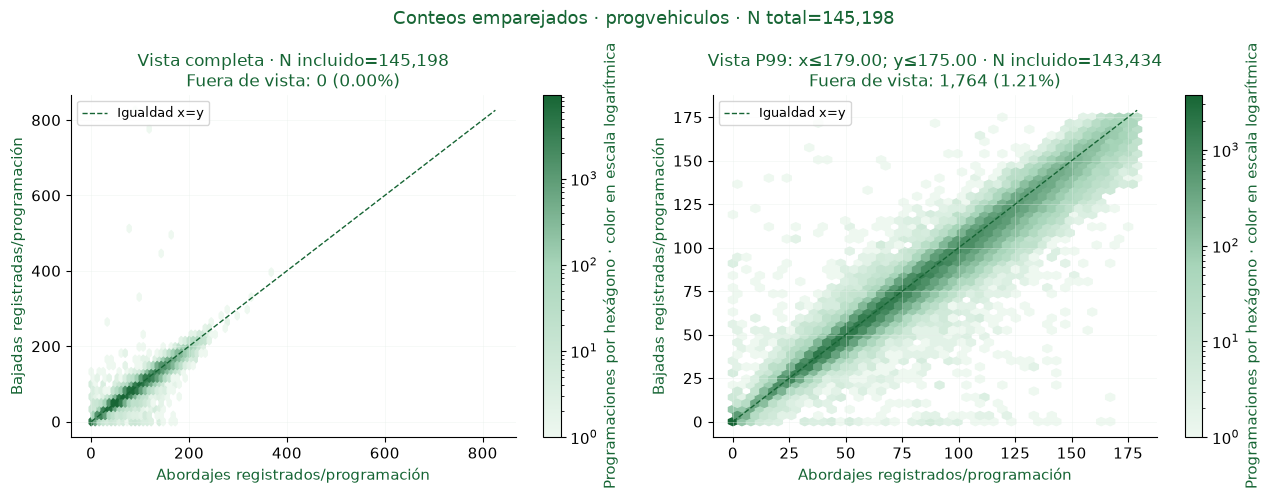

In [8]:
# Mismos pares en estadísticas completas; P99 solo define una vista legible.
if not xy10.empty:
    limites_par10=xy10.quantile(.99)
    centro_par10=(xy10.le(limites_par10)).all(axis=1)
    fig,axes=plt.subplots(1,2,figsize=(13,5))
    for ax,mask,titulo in [(axes[0],pd.Series(True,index=xy10.index),'Vista completa'),(axes[1],centro_par10,f'Vista P99: x≤{limites_par10.iloc[0]:.2f}; y≤{limites_par10.iloc[1]:.2f}')]:
        z=xy10.loc[mask]; fuera=len(xy10)-len(z)
        h=ax.hexbin(z.numeropasajeros,z.numerobajadas,gridsize=45,mincnt=1,cmap=MAPA10,bins='log')
        maximo=max(z.max().max(),1);ax.plot([0,maximo],[0,maximo],color=OSCURO10,ls='--',lw=1,label='Igualdad x=y')
        ax.set(title=f'{titulo} · N incluido={len(z):,}\nFuera de vista: {fuera:,} ({100*fuera/len(xy10):.2f}%)',
            xlabel='Abordajes registrados/programación',ylabel='Bajadas registradas/programación')
        ax.legend(fontsize=9);ax.ticklabel_format(style='plain');ax.grid(alpha=.4)
        fig.colorbar(h,ax=ax,label='Programaciones por hexágono · color en escala logarítmica')
    fig.suptitle(f'Conteos emparejados · progvehiculos · N total={len(xy10):,}',color=OSCURO10)
    figura10(fig,'programaciones','pasajeros_vs_bajadas')
    nota_pares10=(f'La correlación lineal es {pearson10:.3f} y la monotónica {spearman10:.3f}, pero solo '
        f'{100*diff10.eq(0).mean():.2f}% de los pares son exactamente iguales. La diferencia absoluta media '
        f'es {diff10.abs().mean():.2f} eventos por programación. La cercanía a la diagonal describe concordancia '
        'de conteos; la diferencia no identifica ocupación, pasajeros restantes ni errores. La vista ampliada '
        'conserva fuera de pantalla sus extremos en las estadísticas completas; el color logarítmico hace visible la densidad.')
    display(Markdown(nota_pares10));HALLAZGOS10.append(nota_pares10)

La correlación lineal es 0.979 y la monotónica 0.983, pero solo 11.76% de los pares son exactamente iguales. La diferencia absoluta media es 4.78 eventos por programación. La cercanía a la diagonal describe concordancia de conteos; la diferencia no identifica ocupación, pasajeros restantes ni errores. La vista ampliada conserva fuera de pantalla sus extremos en las estadísticas completas; el color logarítmico hace visible la densidad.

### **10.3. Pasajeros y bajadas frente al calendario**
**Pregunta:** ¿las diferencias de volumen se deben a más programaciones observadas o a un conteo típico distinto? Cada variable usa su selección independiente. Las tablas distinguen todas las programaciones, las finalizadas no canceladas, N con conteo válido, ausencias/negativos, suma registrada y media/mediana/dispersión por programación. No se completan fechas sin registros ni se imputan faltantes. Los intervalos gráficos Q1–Q3 describen dispersión, **no intervalos de confianza**.

In [9]:
def resumen_grupos10(grupo, columna):
    base=p10.loc[final10,[grupo,columna]].copy()
    base['valor']=base[columna].where(validos10[columna].loc[base.index]).astype('float64')
    base['faltante']=base[columna].isna().astype(int)
    base['negativo']=base[columna].lt(0).fillna(False).astype(int)
    g=base.groupby(grupo,observed=True,dropna=False)
    res=g.agg(N_finalizadas=(columna,'size'),N_validos=('valor','count'),Faltantes=('faltante','sum'),Negativos=('negativo','sum'),
        Total_registrado=('valor',lambda x:x.sum(min_count=1)),Media=('valor','mean'),Mediana=('valor','median'),
        Desv_estandar=('valor','std'),Q1=('valor',lambda x:x.quantile(.25)),Q3=('valor',lambda x:x.quantile(.75))).reset_index()
    todas=p10.groupby(grupo,observed=True,dropna=False).size().rename('N_todas').reset_index()
    res=todas.merge(res,on=grupo,how='left',validate='one_to_one')
    for c in ['N_finalizadas','N_validos','Faltantes','Negativos']: res[c]=res[c].fillna(0).astype(int)
    res['IQR']=res.Q3-res.Q1
    res['% disponible_finalizadas']=100*res.N_validos/res.N_finalizadas.replace(0,np.nan)
    res['Variable']=columna;res['Unidad']='eventos/programación; suma de registros disponibles'
    assert res.N_todas.sum()==len(p10) and res.N_validos.sum()==validos10[columna].sum()
    assert (res.N_finalizadas==res.N_validos+res.Faltantes+res.Negativos).all()
    assert np.isclose(res.Total_registrado.sum(),p10.loc[validos10[columna],columna].sum())
    return res

CALENDARIO10={}
for grupo in ['dia10','hora10','ano10','mes10']:
    for c in CAMPOS10:
        z=resumen_grupos10(grupo,c).sort_values(grupo)
        CALENDARIO10[(grupo,c)]=z
        tabla10('calendario',f'{grupo}_{c}',z,mostrar=False)

In [10]:
# Tabla horaria compacta; la exportación conserva la dispersión completa.
hora_compacta10=CALENDARIO10[('hora10','numeropasajeros')][['hora10','N_todas','N_finalizadas','N_validos','Mediana','IQR']].rename(columns={'N_validos':'N_abordajes','Mediana':'Mediana_abordajes','IQR':'IQR_abordajes'})
hora_bajadas10=CALENDARIO10[('hora10','numerobajadas')][['hora10','N_validos','Mediana','IQR']].rename(columns={'N_validos':'N_bajadas','Mediana':'Mediana_bajadas','IQR':'IQR_bajadas'})
hora_compacta10=hora_compacta10.merge(hora_bajadas10,on='hora10',validate='one_to_one')
tabla10('calendario','horas_vista_compacta',hora_compacta10)
# Tablas por día y año.
for grupo in ['dia10','ano10']:
    z=pd.concat([CALENDARIO10[(grupo,c)] for c in CAMPOS10],ignore_index=True)
    tabla10('calendario',f'{grupo}_vista',z[[grupo,'Variable','N_todas','N_finalizadas','N_validos','Faltantes','Negativos','Total_registrado','Media','Mediana','Desv_estandar','IQR']])

hora10,N_todas,N_finalizadas,N_abordajes,Mediana_abordajes,IQR_abordajes,N_bajadas,Mediana_bajadas,IQR_bajadas
0,1,0,0,Sin datos,Sin datos,0,Sin datos,Sin datos
4,3717,3454,3407,95.00,69.00,3407,93.00,68.00
5,23404,21801,21468,70.00,61.00,21468,70.00,59.00
6,11553,10933,10891,96.00,50.00,10891,93.00,48.00
7,9839,9285,9257,76.00,45.00,9257,74.00,44.00
8,8710,8191,8168,80.00,49.00,8168,78.00,47.00
9,9300,8668,8647,73.00,46.00,8647,71.00,44.00
10,9472,8741,8716,69.00,44.00,8716,67.00,42.00
11,8433,7684,7658,74.00,48.00,7658,72.00,46.00
12,8984,8008,7971,84.00,54.00,7971,82.00,52.00


dia10,Variable,N_todas,N_finalizadas,N_validos,Faltantes,Negativos,Total_registrado,Media,Mediana,Desv_estandar,IQR
Lunes,numeropasajeros,22901,20556,20375,181,0,1632227.00,80.11,77.00,41.11,58.00
Martes,numeropasajeros,24767,22498,22328,170,0,1872763.00,83.88,83.00,42.07,59.00
Miércoles,numeropasajeros,24740,22591,22408,183,0,1859849.00,83.00,82.00,41.27,56.00
Jueves,numeropasajeros,24563,22435,22271,164,0,1827787.00,82.07,80.00,41.19,58.00
Viernes,numeropasajeros,24400,22316,22139,177,0,1825399.00,82.45,80.00,41.28,57.00
Sábado,numeropasajeros,23423,21371,21183,188,0,1505102.00,71.05,68.00,34.29,46.00
Domingo,numeropasajeros,17884,14649,14494,155,0,812952.00,56.09,52.00,26.27,33.00
Lunes,numerobajadas,22901,20556,20375,181,0,1592501.00,78.16,75.00,39.91,56.00
Martes,numerobajadas,24767,22498,22328,170,0,1825095.00,81.74,80.00,40.83,56.00
Miércoles,numerobajadas,24740,22591,22408,183,0,1813003.00,80.91,79.00,40.19,55.25


ano10,Variable,N_todas,N_finalizadas,N_validos,Faltantes,Negativos,Total_registrado,Media,Mediana,Desv_estandar,IQR
2023,numeropasajeros,55014,50272,49954,318,0,4156845.00,83.21,80.00,39.62,54.00
2024,numeropasajeros,53698,47933,47430,503,0,3744725.00,78.95,76.00,41.50,59.00
2025,numeropasajeros,53966,48211,47814,397,0,3434509.00,71.83,68.00,38.10,53.00
2023,numerobajadas,55014,50272,49954,318,0,4064264.00,81.36,78.00,38.48,52.00
2024,numerobajadas,53698,47933,47430,503,0,3654520.00,77.05,74.00,40.68,57.00
2025,numerobajadas,53966,48211,47814,397,0,3350925.00,70.08,67.00,36.82,51.00


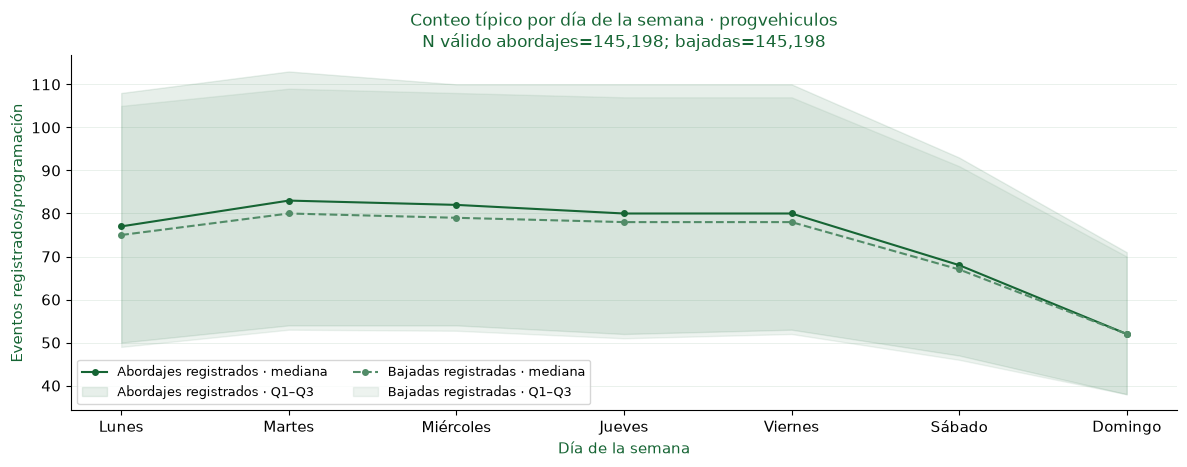

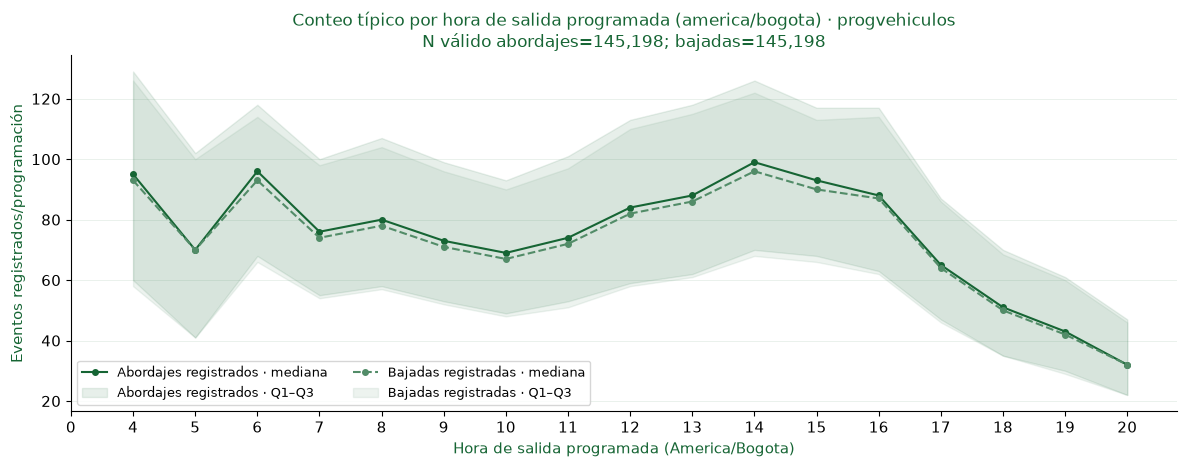

In [11]:
def calendario_grafico10(grupo, titulo):
    fig,ax=plt.subplots(figsize=(12,4.8))
    for c,color,estilo in [('numeropasajeros',OSCURO10,'-'),('numerobajadas','#528c68','--')]:
        z=CALENDARIO10[(grupo,c)];x=np.arange(len(z))
        ax.plot(x,z.Mediana,color=color,ls=estilo,marker='o',ms=4,label=f'{CAMPOS10[c]} · mediana')
        ax.fill_between(x,z.Q1,z.Q3,color=color,alpha=.10,label=f'{CAMPOS10[c]} · Q1–Q3')
    etiquetas=z[grupo].astype(str)
    ax.set_xticks(x,etiquetas);ax.set(ylabel='Eventos registrados/programación',xlabel=titulo,
        title=f'Conteo típico por {titulo.lower()} · progvehiculos\nN válido abordajes={int(validos10["numeropasajeros"].sum()):,}; bajadas={int(validos10["numerobajadas"].sum()):,}')
    ax.grid(axis='y');ax.set_axisbelow(True);ax.legend(ncol=2,fontsize=9)
    figura10(fig,'calendario',grupo+'_mediana_iqr')

calendario_grafico10('dia10','Día de la semana')
calendario_grafico10('hora10','Hora de salida programada (America/Bogota)')

In [12]:
# Los N por hora forman parte del resultado, aunque no se rotulen sobre cada línea.
hora_vista10=pd.concat([CALENDARIO10[('hora10',c)] for c in CAMPOS10],ignore_index=True)
tabla10('calendario','hora10_vista',hora_vista10[['hora10','Variable','N_finalizadas','N_validos','Faltantes','Total_registrado','Media','Mediana','IQR']],mostrar=False)
notas_calendario10=[]
for grupo,titulo in [('dia10','día de semana'),('hora10','hora programada')]:
    z=CALENDARIO10[(grupo,'numeropasajeros')].dropna(subset=['Mediana'])
    alto=z.loc[z.Mediana.idxmax()];bajo=z.loc[z.Mediana.idxmin()]
    texto=(f'Por {titulo}, la mediana de abordajes va de {bajo.Mediana:.2f} ({bajo[grupo]}) a {alto.Mediana:.2f} ({alto[grupo]}). '
        f'El grupo de mayor mediana tiene N={int(alto.N_validos):,} conteos disponibles. Los intervalos Q1–Q3 muestran '
        'la heterogeneidad dentro de cada grupo; no separan efectos de fecha, horario o asignación. Las horas cuentan programaciones, no demanda por sí mismas. Los horarios sin conteos válidos mantienen sus medidas ausentes; no se dibujan como demanda cero.')
    notas_calendario10.append(texto)
display(Markdown('\n\n'.join(notas_calendario10)));HALLAZGOS10.extend(notas_calendario10)

Por día de semana, la mediana de abordajes va de 52.00 (Domingo) a 83.00 (Martes). El grupo de mayor mediana tiene N=22,328 conteos disponibles. Los intervalos Q1–Q3 muestran la heterogeneidad dentro de cada grupo; no separan efectos de fecha, horario o asignación. Las horas cuentan programaciones, no demanda por sí mismas. Los horarios sin conteos válidos mantienen sus medidas ausentes; no se dibujan como demanda cero.

Por hora programada, la mediana de abordajes va de 32.00 (20) a 99.00 (14). El grupo de mayor mediana tiene N=8,123 conteos disponibles. Los intervalos Q1–Q3 muestran la heterogeneidad dentro de cada grupo; no separan efectos de fecha, horario o asignación. Las horas cuentan programaciones, no demanda por sí mismas. Los horarios sin conteos válidos mantienen sus medidas ausentes; no se dibujan como demanda cero.

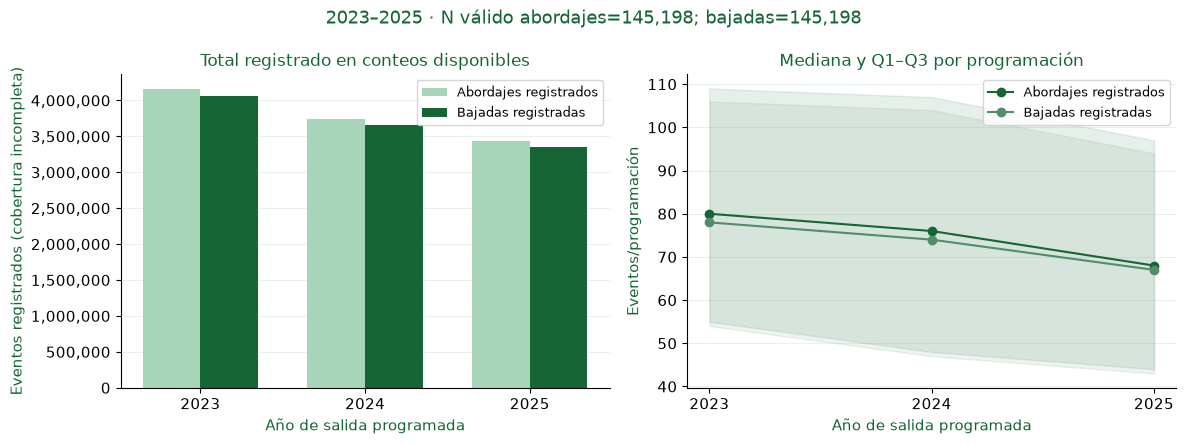

In [13]:
# Años: volumen observado frente a conteo típico, con las mismas selecciones.
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
for j,c in enumerate(CAMPOS10):
    z=CALENDARIO10[('ano10',c)];x=np.arange(len(z))
    axes[0].bar(x+(j-.5)*.35,z.Total_registrado,width=.35,color=[VERDE10,OSCURO10][j],label=CAMPOS10[c])
    axes[1].plot(x,z.Mediana,color=[OSCURO10,'#528c68'][j],marker='o',label=CAMPOS10[c])
    axes[1].fill_between(x,z.Q1,z.Q3,color=[OSCURO10,'#528c68'][j],alpha=.1)
for ax in axes:
    ax.set_xticks(x,z.ano10.astype(str));ax.set_xlabel('Año de salida programada');ax.grid(axis='y');ax.set_axisbelow(True);ax.legend(fontsize=9)
axes[0].set(title='Total registrado en conteos disponibles',ylabel='Eventos registrados (cobertura incompleta)')
axes[0].yaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
axes[1].set(title='Mediana y Q1–Q3 por programación',ylabel='Eventos/programación')
fig.suptitle(f'2023–2025 · N válido abordajes={int(validos10["numeropasajeros"].sum()):,}; bajadas={int(validos10["numerobajadas"].sum()):,}',color=OSCURO10)
figura10(fig,'calendario','ano_volumen_tipico')

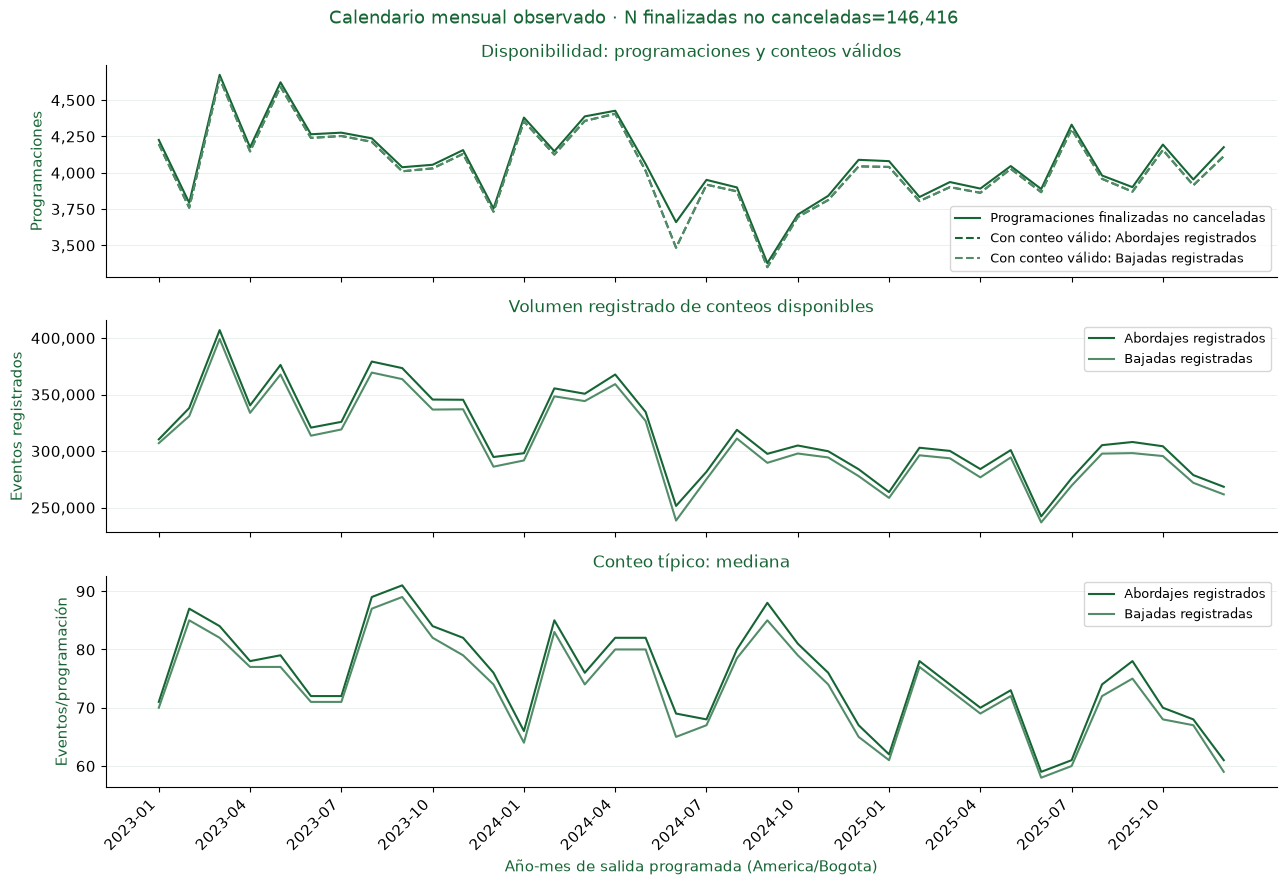

In [14]:
# Año-mes observado: no se rellena un calendario sin filas con demanda cero.
fig,axes=plt.subplots(3,1,figsize=(13,9),sharex=True)
z0=CALENDARIO10[('mes10','numeropasajeros')];x=np.arange(len(z0))
axes[0].plot(x,z0.N_finalizadas,color=OSCURO10,label='Programaciones finalizadas no canceladas')
for c,color in [('numeropasajeros',OSCURO10),('numerobajadas','#528c68')]:
    z=CALENDARIO10[('mes10',c)]
    axes[0].plot(x,z.N_validos,color=color,ls='--',label=f'Con conteo válido: {CAMPOS10[c]}')
    axes[1].plot(x,z.Total_registrado,color=color,label=CAMPOS10[c])
    axes[2].plot(x,z.Mediana,color=color,label=CAMPOS10[c])
for ax,titulo,unidad in zip(axes,['Disponibilidad: programaciones y conteos válidos','Volumen registrado de conteos disponibles','Conteo típico: mediana'],['Programaciones','Eventos registrados','Eventos/programación']):
    ax.set(title=titulo,ylabel=unidad);ax.grid(axis='y');ax.set_axisbelow(True);ax.legend(fontsize=9)
    ax.yaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
axes[2].set_xticks(x[::3],z0.mes10.iloc[::3],rotation=45,ha='right');axes[2].set_xlabel('Año-mes de salida programada (America/Bogota)')
fig.suptitle(f'Calendario mensual observado · N finalizadas no canceladas={int(final10.sum()):,}',color=OSCURO10)
figura10(fig,'calendario','mes_disponibilidad_volumen_tipico')

In [15]:
z=CALENDARIO10[('ano10','numeropasajeros')]
nota_anos10='; '.join(f"{int(f.ano10)}: {int(f.N_validos):,}/{int(f.N_finalizadas):,} programaciones con conteo válido, mediana {f.Mediana:.2f}" for _,f in z.iterrows())
texto_anos10=(f'Abordajes por año — {nota_anos10}. Los totales mensuales combinan número de programaciones y magnitud por programación; '
    'no son demanda completa. La curva de mediana separa el conteo típico del volumen, pero los cambios siguen mezclando horarios y asignaciones. '
    'Los meses con faltantes se ven como separación entre N finalizadas y N disponible, sin convertir las ausencias en cero.')
display(Markdown(texto_anos10));HALLAZGOS10.append(texto_anos10)

Abordajes por año — 2023: 49,954/50,272 programaciones con conteo válido, mediana 80.00; 2024: 47,430/47,933 programaciones con conteo válido, mediana 76.00; 2025: 47,814/48,211 programaciones con conteo válido, mediana 68.00. Los totales mensuales combinan número de programaciones y magnitud por programación; no son demanda completa. La curva de mediana separa el conteo típico del volumen, pero los cambios siguen mezclando horarios y asignaciones. Los meses con faltantes se ven como separación entre N finalizadas y N disponible, sin convertir las ausencias en cero.

### **10.4. Diferencias entre vehículos y categorías pertinentes**
**Pregunta:** ¿qué variación descriptiva existe entre asignaciones a vehículos? Se usan identificadores como categorías, representados por etiquetas anónimas estables `V001…`, ordenadas por identificador dentro de esta extracción. No se exporta la correspondencia con placas. La tabla completa está en el reporte; la figura selecciona los **12 vehículos con más programaciones finalizadas no canceladas**, no los de mayor demanda. No se unen estados actuales ni capacidades al histórico.

In [16]:
ids_veh10=sorted(p10.idvehiculo.dropna().unique().tolist(),key=str)
mapa_veh10={valor:f'V{i+1:03d}' for i,valor in enumerate(ids_veh10)}
p10['vehiculo10']=p10.idvehiculo.map(mapa_veh10).fillna('<Vehículo faltante>')
VEHICULOS10={c:resumen_grupos10('vehiculo10',c) for c in CAMPOS10}
nveh10=p10.loc[final10].groupby('vehiculo10',observed=True).size().sort_values(ascending=False,kind='stable')
top_veh10=nveh10.head(12).index.tolist()
for c,z in VEHICULOS10.items(): tabla10('vehiculos',c+'_todos',z,mostrar=False)
veh_vista10=pd.concat([z.set_index('vehiculo10').reindex(top_veh10).reset_index() for z in VEHICULOS10.values()],ignore_index=True)
tabla10('vehiculos','seleccion_mayor_n',veh_vista10[['vehiculo10','Variable','N_finalizadas','N_validos','Faltantes','Total_registrado','Media','Mediana','IQR']])
if v10 is not None:
    assert v10.idvehiculo.notna().all() and v10.idvehiculo.is_unique
    n_no_catalogo10=int((p10.idvehiculo.notna() & ~p10.idvehiculo.isin(v10.idvehiculo)).sum())
    CONTROLES10.append({'Control':'Programaciones con vehículo fuera del catálogo','N recalculado':n_no_catalogo10,'Resultado':'Solo pertenencia de llaves; sin unir atributos históricos'})

vehiculo10,Variable,N_finalizadas,N_validos,Faltantes,Total_registrado,Media,Mediana,IQR
V245,numeropasajeros,2804,2795,9,213750.00,76.48,74.00,49.00
V191,numeropasajeros,2740,2712,28,205696.00,75.85,70.00,53.00
V147,numeropasajeros,2736,2719,17,233457.00,85.86,82.00,54.00
V187,numeropasajeros,2679,2667,12,202098.00,75.78,72.00,57.00
V233,numeropasajeros,2635,2621,14,239224.00,91.27,90.00,60.00
V213,numeropasajeros,2574,2561,13,193703.00,75.64,71.00,57.00
V284,numeropasajeros,2547,2532,15,223340.00,88.21,86.00,57.25
V144,numeropasajeros,2531,2507,24,215300.00,85.88,81.00,56.00
V089,numeropasajeros,2493,2464,29,194594.00,78.97,76.00,53.25
V005,numeropasajeros,2484,2465,19,185261.00,75.16,74.00,51.00


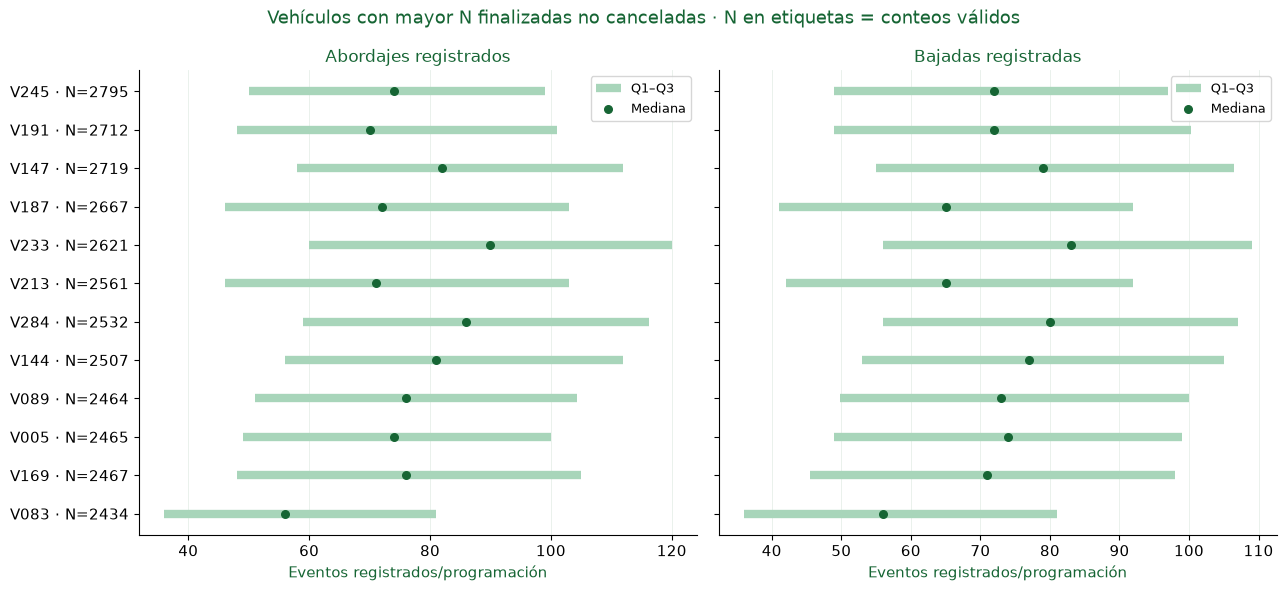

Campo,N no nulos,Categorías,Decisión
tipo,0,0,Sin comparación: totalmente nulo
grupo,0,0,Sin comparación: totalmente nulo


In [17]:
fig,axes=plt.subplots(1,2,figsize=(13,6),sharey=True)
for ax,c in zip(axes,CAMPOS10):
    z=VEHICULOS10[c].set_index('vehiculo10').reindex(top_veh10)
    y=np.arange(len(z));ax.hlines(y,z.Q1,z.Q3,color=VERDE10,lw=6,label='Q1–Q3')
    ax.scatter(z.Mediana,y,color=OSCURO10,s=30,label='Mediana',zorder=3)
    ax.set_yticks(y,[f'{v} · N={int(n)}' for v,n in zip(z.index,z.N_validos)])
    ax.set(title=CAMPOS10[c],xlabel='Eventos registrados/programación');ax.grid(axis='x');ax.set_axisbelow(True);ax.legend(fontsize=9)
axes[0].invert_yaxis()
fig.suptitle('Vehículos con mayor N finalizadas no canceladas · N en etiquetas = conteos válidos',color=OSCURO10)
figura10(fig,'vehiculos','comparacion_top_n')
nota_veh10=(f'La selección representa {int(nveh10.loc[top_veh10].sum()):,} de {int(final10.sum()):,} programaciones finalizadas no canceladas '
    f'({100*nveh10.loc[top_veh10].sum()/final10.sum():.2f}%). Los intervalos describen dispersión interna; las diferencias entre '
    'medianas pueden acompañar mezclas de fechas y horarios. No estiman un efecto propio del vehículo ni su capacidad histórica.')
display(Markdown(nota_veh10));HALLAZGOS10.append(nota_veh10)
CATEGORIAS_PENDIENTES10=pd.DataFrame([{'Campo':c,'N no nulos':int(p10[c].notna().sum()),'Categorías':int(p10[c].nunique()),
    'Decisión':'Sin comparación: totalmente nulo' if p10[c].notna().sum()==0 else 'Sin comparación: codificación de etiquetas no confirmada'} for c in ['tipo','grupo']])
tabla10('general','categorias_no_comparadas',CATEGORIAS_PENDIENTES10)
display(Markdown('`tipo` y `grupo` no aportan categorías observadas; no se generan cruces vacíos. `activa` es casi constante y su vigencia histórica no está confirmada. Los estados del catálogo de vehículos no se utilizan para inferir estados de 2023–2025.'))

La selección representa 31,156 de 146,416 programaciones finalizadas no canceladas (21.28%). Los intervalos describen dispersión interna; las diferencias entre medianas pueden acompañar mezclas de fechas y horarios. No estiman un efecto propio del vehículo ni su capacidad histórica.

`tipo` y `grupo` no aportan categorías observadas; no se generan cruces vacíos. `activa` es casi constante y su vigencia histórica no está confirmada. Los estados del catálogo de vehículos no se utilizan para inferir estados de 2023–2025.

### **10.5. Relaciones categóricas pertinentes**
**Pregunta:** ¿cómo se combinan finalización y cancelación? Codificación S/N documentada. Se incluyen **todas las programaciones**, conservando cualquier etiqueta o faltante observado. La contingencia muestra N y porcentaje del total; se exportan además porcentajes por fila (dentro de cada estado de finalización) y por columna (dentro de cada estado de cancelación).

finalizado,cancelada,Programaciones,N total,% total
N,N,11,162678,0.01
N,S,16251,162678,9.99
S,N,146416,162678,90.00
S,S,0,162678,0.00


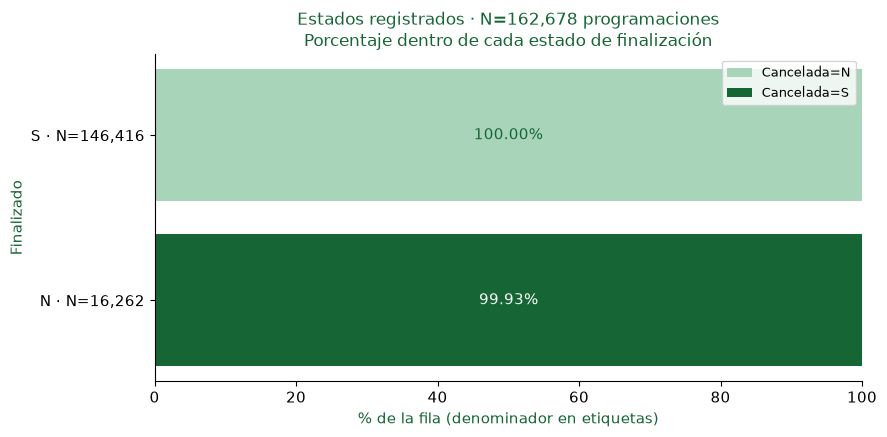

In [18]:
estados10=p10[['finalizado','cancelada']].astype('string').fillna('<Faltante>')
contingencia10=pd.crosstab(estados10.finalizado,estados10.cancelada,dropna=False)
assert int(contingencia10.to_numpy().sum())==len(p10)
fila_pct10=100*contingencia10.div(contingencia10.sum(axis=1),axis=0)
col_pct10=100*contingencia10.div(contingencia10.sum(axis=0),axis=1)
assert np.allclose(fila_pct10.sum(axis=1),100) and np.allclose(col_pct10.sum(axis=0),100)
cruce10=contingencia10.stack().rename('Programaciones').reset_index()
cruce10['N total']=len(p10);cruce10['% total']=100*cruce10.Programaciones/len(p10)
tabla10('estados','contingencia',cruce10)
tabla10('estados','porcentaje_fila',fila_pct10.reset_index(),mostrar=False)
tabla10('estados','porcentaje_columna',col_pct10.reset_index(),mostrar=False)
fig,ax=plt.subplots(figsize=(9,4.5));izquierda=np.zeros(len(fila_pct10))
for c,color in zip(fila_pct10.columns,[VERDE10,OSCURO10,'#73ac89']):
    valores=fila_pct10[c].to_numpy();ax.barh(fila_pct10.index,valores,left=izquierda,color=color,label=f'Cancelada={c}')
    for i,v in enumerate(valores):
        if v>=3: ax.text(izquierda[i]+v/2,i,f'{v:.2f}%',ha='center',va='center',color='white' if color==OSCURO10 else OSCURO10)
    izquierda+=valores
ax.set(title=f'Estados registrados · N={len(p10):,} programaciones\nPorcentaje dentro de cada estado de finalización',xlabel='% de la fila (denominador en etiquetas)',ylabel='Finalizado')
ax.set_yticks(np.arange(len(fila_pct10)),[f'{c} · N={int(n):,}' for c,n in contingencia10.sum(axis=1).items()]);ax.legend(fontsize=9);ax.set_xlim(0,100)
figura10(fig,'estados','finalizado_cancelada')
no_fin_no_can10=int(((p10.finalizado.eq('N')) & (p10.cancelada.eq('N'))).sum())
nota_estados10=(f'Hay {no_fin_no_can10:,} programaciones no finalizadas y no canceladas. El cruce conserva esta combinación '
    'en lugar de suponer que ambos estados son complementarios. Su interpretación requiere el flujo operativo; la tabla describe '
    'el estado registrado del archivo, sin inferir transición temporal ni causa de cancelación.')
display(Markdown(nota_estados10));HALLAZGOS10.append(nota_estados10)

Hay 11 programaciones no finalizadas y no canceladas. El cruce conserva esta combinación en lugar de suponer que ambos estados son complementarios. Su interpretación requiere el flujo operativo; la tabla describe el estado registrado del archivo, sin inferir transición temporal ni causa de cancelación.

### **10.6. Detalle por segmento, con su ventana propia**
**Pregunta:** ¿cómo varían los eventos registrados entre segmentos? El diccionario ampliado define `subidas` y `bajadas` como cantidades que ocurrieron específicamente en ese segmento para esa programación, no como lecturas acumuladas. Se comprueba la unicidad programación–segmento antes de sumar. Las sumas se identifican como **conteos registrados del detalle observado**, no totales operativos de la ruta ni demanda completa. `pasajeros` del detalle queda fuera de estas relaciones por semántica pendiente.

No se une detalle a programaciones para promediar conteos totales repetidos. Primero se resume por segmento; después se añade su orden mediante una unión muchos-a-uno validada con el catálogo.

In [19]:
DETALLE_RESUMEN10=None
if t10 is not None and not t10.empty:
    assert t10.id_timbrada_segmento.is_unique
    dup_seg10=int(t10.duplicated(['id_viaje','id_segmento']).sum())
    assert dup_seg10==0, 'Revisar repetición programación–segmento antes de sumar eventos'
    rango_det10=[str(t10.fecha.min()),str(t10.fecha.max())]
    tabla10('segmentos','alcance',pd.DataFrame([{'Inicio observado':rango_det10[0],'Fin observado':rango_det10[1],
        'Registros':len(t10),'Programaciones distintas':t10.id_viaje.nunique(),'Segmentos observados':t10.id_segmento.nunique(),
        'Duplicados programación–segmento':dup_seg10}]))
    base_seg10=t10.groupby('id_segmento',observed=True).agg(Registros=('id_viaje','size'),Programaciones_distintas=('id_viaje','nunique')).reset_index()
    piezas_seg10=[]
    for c in ['subidas','bajadas']:
        z=t10.groupby('id_segmento',observed=True)[c].agg(N='count',Media='mean',Mediana='median',Desv_estandar='std',
            Q1=lambda s:s.quantile(.25),Q3=lambda s:s.quantile(.75),Total_registrado=lambda s:s.sum(min_count=1)).reset_index()
        z['Campo']=c
        z=base_seg10.merge(z,on='id_segmento',validate='one_to_one')
        assert z.Registros.sum()==len(t10) and z.N.sum()==t10[c].notna().sum()
        assert np.isclose(z.Total_registrado.sum(),t10[c].sum())
        piezas_seg10.append(z)
    DETALLE_RESUMEN10=pd.concat(piezas_seg10,ignore_index=True)
    tabla10('segmentos','estadisticas_por_segmento',DETALLE_RESUMEN10,mostrar=False)
else:
    BLOQUEOS10.append({'Fuente':'timbradas_segmentos','Limitación':'Sin detalle disponible; bloque 10.6 no ejecutado'})

Inicio observado,Fin observado,Registros,Programaciones distintas,Segmentos observados,Duplicados programación–segmento
2023-01-01,2023-02-27,799030,7519,135,0


id_segmento,Registros,Programaciones_distintas,N,Media,Mediana,Desv_estandar,Q1,Q3,Total_registrado,Campo,id_config,idruta,nro_segmento
1,2737,2737,2737,0.07,0.00,0.49,0.00,0.00,195,bajadas,1,2,1
1,2737,2737,2737,0.13,0.00,0.53,0.00,0.00,343,subidas,1,2,1
2,577,577,577,0.08,0.00,0.56,0.00,0.00,47,bajadas,1,2,2
2,577,577,577,0.07,0.00,0.42,0.00,0.00,40,subidas,1,2,2
3,1178,1178,1178,0.23,0.00,1.72,0.00,0.00,270,bajadas,1,2,3
3,1178,1178,1178,0.20,0.00,1.34,0.00,0.00,241,subidas,1,2,3
4,2426,2426,2426,0.13,0.00,1.83,0.00,0.00,316,bajadas,1,2,4
4,2426,2426,2426,0.63,0.00,1.97,0.00,1.00,1522,subidas,1,2,4
5,5855,5855,5855,0.09,0.00,0.58,0.00,0.00,543,bajadas,1,2,5
5,5855,5855,5855,1.10,1.00,1.44,0.00,2.00,6439,subidas,1,2,5


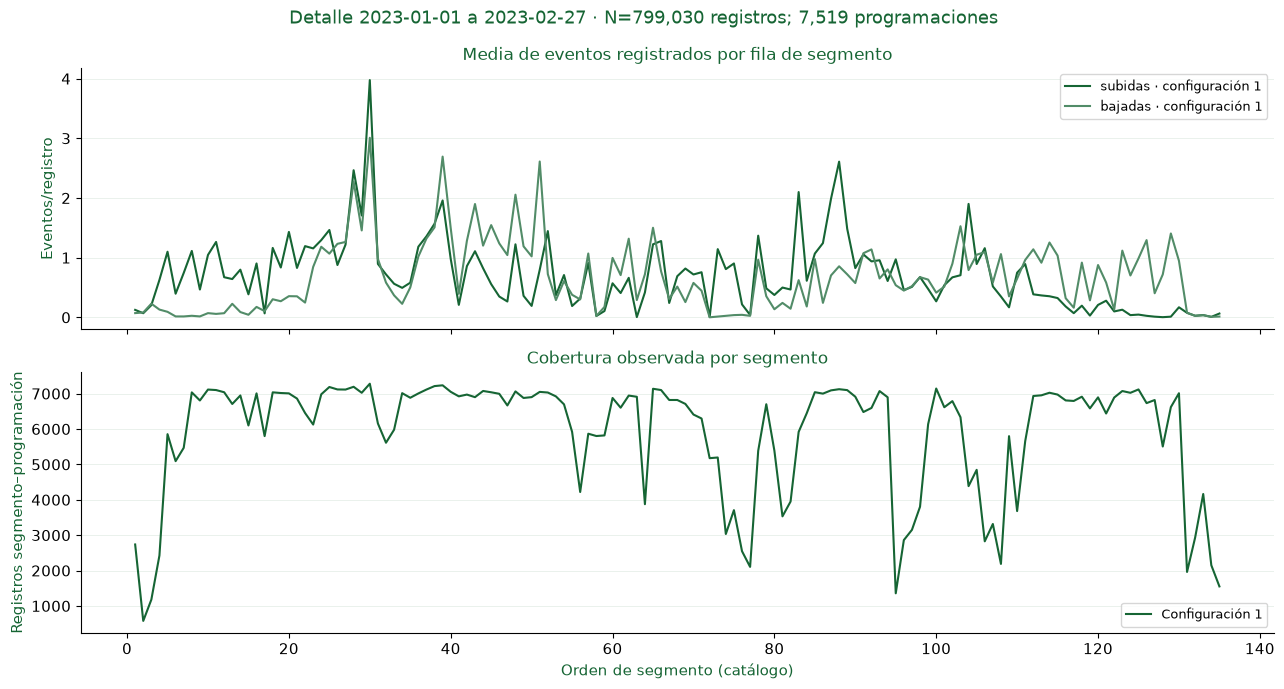

In [20]:
if DETALLE_RESUMEN10 is not None and s10 is not None:
    assert s10.id.is_unique and s10.id.notna().all() and s10.idruta.eq(2).all()
    antes_seg10=len(DETALLE_RESUMEN10)
    orden_seg10=DETALLE_RESUMEN10.merge(s10.rename(columns={'id':'id_segmento'}),on='id_segmento',how='left',validate='many_to_one',indicator=True)
    assert len(orden_seg10)==antes_seg10 and orden_seg10._merge.eq('both').all()
    for c in ['subidas','bajadas']:
        assert np.isclose(orden_seg10.loc[orden_seg10.Campo.eq(c),'Total_registrado'].sum(),t10[c].sum())
    orden_seg10=orden_seg10.drop(columns='_merge').sort_values(['id_config','nro_segmento','Campo'])
    tabla10('segmentos','estadisticas_con_orden',orden_seg10,mostrar=False)
    tabla10('segmentos','vista_primeros_segmentos',orden_seg10.head(16))
    fig,axes=plt.subplots(2,1,figsize=(13,7),sharex=True)
    for c,color in [('subidas',OSCURO10),('bajadas','#528c68')]:
        z=orden_seg10.loc[orden_seg10.Campo.eq(c)]
        # Un panel por configuración evita conectar segmentos de configuraciones distintas.
        for conf,g in z.groupby('id_config',observed=True):
            axes[0].plot(g.nro_segmento.astype(float),g.Media.astype(float),color=color,label=f'{c} · configuración {conf}')
    z=orden_seg10.loc[orden_seg10.Campo.eq('subidas')]
    for conf,g in z.groupby('id_config',observed=True): axes[1].plot(g.nro_segmento.astype(float),g.Registros,color=OSCURO10,label=f'Configuración {conf}')
    axes[0].set(title='Media de eventos registrados por fila de segmento',ylabel='Eventos/registro');axes[0].legend(fontsize=9)
    axes[1].set(title='Cobertura observada por segmento',ylabel='Registros segmento–programación',xlabel='Orden de segmento (catálogo)');axes[1].legend(fontsize=9)
    for ax in axes: ax.grid(axis='y');ax.set_axisbelow(True)
    fig.suptitle(f'Detalle {rango_det10[0]} a {rango_det10[1]} · N={len(t10):,} registros; {t10.id_viaje.nunique():,} programaciones',color=OSCURO10)
    figura10(fig,'segmentos','eventos_y_cobertura')
    nota_seg10=(f'El detalle contiene {len(t10):,} registros de {t10.id_viaje.nunique():,} programaciones distintas. '
        f'Los N por segmento van de {int(z.Registros.min()):,} a {int(z.Registros.max()):,}; no todos los segmentos tienen la misma cobertura. '
        'Las medias se calculan por registro observado, incluyendo ceros, no por todas las programaciones de 2023–2025. '
        'Las diferencias describen localización de eventos dentro de esta ventana; no prueban una demanda estable ni validan ocupación.')
    display(Markdown(nota_seg10));HALLAZGOS10.append(nota_seg10)
elif DETALLE_RESUMEN10 is not None:
    BLOQUEOS10.append({'Fuente':'rutas_segmentos','Limitación':'Sin catálogo: tabla por identificador exportada; gráfico de orden bloqueado'})

El detalle contiene 799,030 registros de 7,519 programaciones distintas. Los N por segmento van de 577 a 7,280; no todos los segmentos tienen la misma cobertura. Las medias se calculan por registro observado, incluyendo ceros, no por todas las programaciones de 2023–2025. Las diferencias describen localización de eventos dentro de esta ventana; no prueban una demanda estable ni validan ocupación.

### **10.7. Duración y otras relaciones condicionadas**
**Pregunta diagnóstica:** ¿cómo se asocia la duración registrada de programación con cada conteo? Se requiere finalización S, cancelación N, duración positiva y **solo el conteo utilizado** presente y no negativo. No se interpreta como duración válida de un recorrido individual. Las estadísticas principales conservan todos los extremos.

La sensibilidad exige inicio y fin dentro de la ventana configurada, sin umbral de duración. Esto verifica cobertura de marcas temporales, no validez operativa. Una segunda vista hasta P99 es exclusivamente visual. Distancia no se incorpora: el diccionario no confirma su unidad. Capacidad cero impide analizar ocupación porcentual.

In [21]:
DURACION_REL10=[]
marcas_dentro10=(inicio10.ge(limites10[0]) & inicio10.lt(limites10[1]) & fin10.ge(limites10[0]) & fin10.lt(limites10[1])).fillna(False)
for c in CAMPOS10:
    mask=positiva10 & validos10[c]
    for nombre,seleccion in [('Principal: positiva y conteo válido',mask),('Sensibilidad: además inicio/fin dentro de ventana',mask & marcas_dentro10)]:
        x=duracion10.loc[seleccion];y=p10.loc[seleccion,c]
        rp,rs=correlaciones10(x,y)
        DURACION_REL10.append({'Variable':c,'Selección':nombre,'Unidad':'minutos/programación × eventos/programación',
            'N finalizadas':int(final10.sum()),'N pares':int(seleccion.sum()),'Sin par respecto a finalizadas':int(final10.sum()-seleccion.sum()),
            'Apartados respecto a principal':int(mask.sum()-seleccion.sum()),'Pearson':rp,'Spearman':rs,'Máxima duración (min)':x.max()})
DURACION_SELECCIONES10=pd.DataFrame([{'Variable':c,'N finalizadas':int(final10.sum()),'Duración no positiva o ausente':int((final10 & ~positiva10).sum()),'Duración positiva con conteo faltante':int((positiva10 & p10[c].isna()).sum()),'Duración positiva con conteo negativo':int((positiva10 & p10[c].lt(0)).sum()),'Pares utilizados':int((positiva10 & validos10[c]).sum())} for c in CAMPOS10])
assert (DURACION_SELECCIONES10.iloc[:,2:].sum(axis=1)==DURACION_SELECCIONES10['N finalizadas']).all()
tabla10('duracion','selecciones_por_variable',DURACION_SELECCIONES10)
DURACION_REL10=pd.DataFrame(DURACION_REL10)
tabla10('duracion','correlaciones_y_sensibilidad',DURACION_REL10)

Variable,N finalizadas,Duración no positiva o ausente,Duración positiva con conteo faltante,Duración positiva con conteo negativo,Pares utilizados
numeropasajeros,146416,137,1097,0,145182
numerobajadas,146416,137,1097,0,145182


Variable,Selección,Unidad,N finalizadas,N pares,Sin par respecto a finalizadas,Apartados respecto a principal,Pearson,Spearman,Máxima duración (min)
numeropasajeros,Principal: positiva y conteo válido,minutos/programación × eventos/programación,146416,145182,1234,0,0.01,0.51,42171.22
numeropasajeros,Sensibilidad: además inicio/fin dentro de ventana,minutos/programación × eventos/programación,146416,145173,1243,9,0.01,0.51,42171.22
numerobajadas,Principal: positiva y conteo válido,minutos/programación × eventos/programación,146416,145182,1234,0,0.01,0.49,42171.22
numerobajadas,Sensibilidad: además inicio/fin dentro de ventana,minutos/programación × eventos/programación,146416,145173,1243,9,0.01,0.49,42171.22


,Variable,Selección,Unidad,N finalizadas,N pares,Sin par respecto a finalizadas,Apartados respecto a principal,Pearson,Spearman,Máxima duración (min)
0,numeropasajeros,Principal: positiva y conteo válido,minutos/programación × eventos/programación,146416,145182,1234,0,0.008795,0.506416,42171.216667
1,numeropasajeros,Sensibilidad: además inicio/fin dentro de ventana,minutos/programación × eventos/programación,146416,145173,1243,9,0.009553,0.506482,42171.216667
2,numerobajadas,Principal: positiva y conteo válido,minutos/programación × eventos/programación,146416,145182,1234,0,0.006251,0.490260,42171.216667
3,numerobajadas,Sensibilidad: además inicio/fin dentro de ventana,minutos/programación × eventos/programación,146416,145173,1243,9,0.006939,0.490321,42171.216667


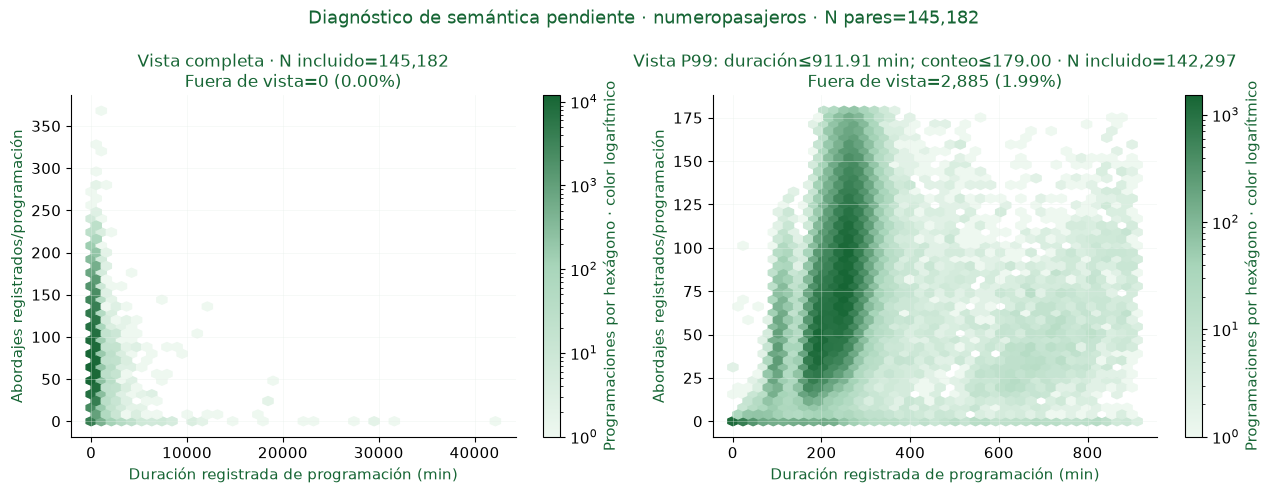

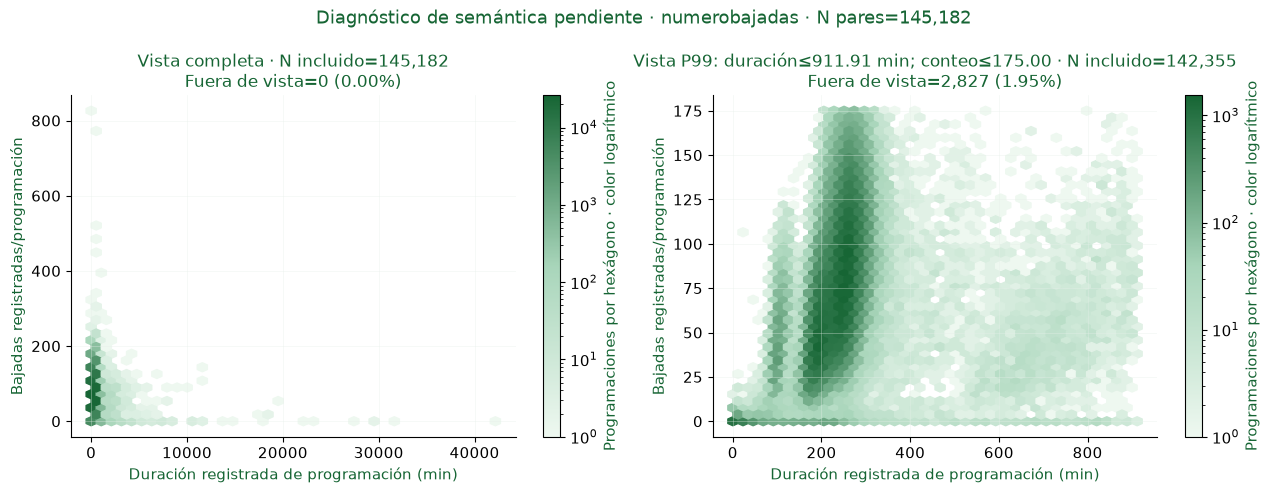

In [22]:
for c in CAMPOS10:
    mask=positiva10 & validos10[c]
    x,y=duracion10.loc[mask].astype(float),p10.loc[mask,c].astype(float)
    if x.empty: continue
    central=(x.le(x.quantile(.99)) & y.le(y.quantile(.99)))
    fig,axes=plt.subplots(1,2,figsize=(13,5))
    for ax,m,titulo in [(axes[0],pd.Series(True,index=x.index),'Vista completa'),(axes[1],central,f'Vista P99: duración≤{x.quantile(.99):.2f} min; conteo≤{y.quantile(.99):.2f}')]:
        fuera=len(x)-int(m.sum())
        h=ax.hexbin(x.loc[m],y.loc[m],gridsize=40,mincnt=1,bins='log',cmap=MAPA10)
        ax.set(title=f'{titulo} · N incluido={int(m.sum()):,}\nFuera de vista={fuera:,} ({100*fuera/len(x):.2f}%)',
            xlabel='Duración registrada de programación (min)',ylabel=f'{CAMPOS10[c]}/programación')
        ax.ticklabel_format(style='plain');ax.grid(alpha=.4)
        fig.colorbar(h,ax=ax,label='Programaciones por hexágono · color logarítmico')
    fig.suptitle(f'Diagnóstico de semántica pendiente · {c} · N pares={len(x):,}',color=OSCURO10)
    figura10(fig,'duracion',f'duracion_vs_{c}')
    rp=DURACION_REL10.loc[DURACION_REL10.Variable.eq(c) & DURACION_REL10.Selección.str.startswith('Principal')].iloc[0]
    rs=DURACION_REL10.loc[DURACION_REL10.Variable.eq(c) & DURACION_REL10.Selección.str.startswith('Sensibilidad')].iloc[0]
    nota=(f'Para {c}, Pearson={rp.Pearson:.3f} y Spearman={rp.Spearman:.3f} con {int(rp["N pares"]):,} pares. '
        f'La sensibilidad temporal aparta {int(rs["Apartados respecto a principal"]):,} pares y obtiene Pearson={rs.Pearson:.3f}, '
        f'Spearman={rs.Spearman:.3f}. Se conservan los extremos en la descripción principal. '
        f'El máximo dentro de los pares es {rp["Máxima duración (min)"]:.2f} min, frente a {duracion10.loc[positiva10].max():.2f} min entre todas las duraciones positivas: algunos extremos no tienen conteo válido. '
        'La asociación por rangos es mayor que la lineal; una recta no resume ambos coeficientes. Estas asociaciones '
        'no validan una unidad operativa de recorrido ni permiten atribuir los conteos al tiempo registrado.')
    display(Markdown(nota));HALLAZGOS10.append(nota)

Para numeropasajeros, Pearson=0.009 y Spearman=0.506 con 145,182 pares. La sensibilidad temporal aparta 9 pares y obtiene Pearson=0.010, Spearman=0.506. Se conservan los extremos en la descripción principal. El máximo dentro de los pares es 42171.22 min, frente a 133909.32 min entre todas las duraciones positivas: algunos extremos no tienen conteo válido. La asociación por rangos es mayor que la lineal; una recta no resume ambos coeficientes. Estas asociaciones no validan una unidad operativa de recorrido ni permiten atribuir los conteos al tiempo registrado.

Para numerobajadas, Pearson=0.006 y Spearman=0.490 con 145,182 pares. La sensibilidad temporal aparta 9 pares y obtiene Pearson=0.007, Spearman=0.490. Se conservan los extremos en la descripción principal. El máximo dentro de los pares es 42171.22 min, frente a 133909.32 min entre todas las duraciones positivas: algunos extremos no tienen conteo válido. La asociación por rangos es mayor que la lineal; una recta no resume ambos coeficientes. Estas asociaciones no validan una unidad operativa de recorrido ni permiten atribuir los conteos al tiempo registrado.

### **10.8. Síntesis e implicaciones**
La síntesis se genera desde resultados calculados. Los controles comprueban denominadores, filtros por identificador, cobertura y conservación de sumas. No se realizaron uniones de detalle a programación ni se calcularon correlaciones de identificadores. No se realizaron pruebas inferenciales bajo una independencia no justificada.

In [23]:
# Controles finales de poblaciones y cardinalidad.
assert len(xy10)==int(pares10.sum())
assert DIFERENCIAS10[['Negativas','Cero','Positivas']].sum(axis=1).iloc[0]==len(xy10)
assert int(contingencia10.to_numpy().sum())==len(p10)
assert np.isclose(cruce10['% total'].sum(),100)
assert HUELLA10=={str(f.relative_to(BASE10)):(f.stat().st_size,f.stat().st_mtime_ns) for f in (BASE10/'raw').rglob('*.parquet')}
if DETALLE_RESUMEN10 is not None:
    assert t10.fecha.min()>=pd.Timestamp('2023-01-01').date() and t10.fecha.max()<=pd.Timestamp('2023-02-27').date()
    assert t10.id_viaje.isin(p10.idprogramacion).all()
    assert t10[['subidas','bajadas']].notna().all().all() and t10[['subidas','bajadas']].ge(0).all().all()
    CONTROLES10.append({'Control':'Detalle: unicidad, ventana y eventos no negativos','N recalculado':len(t10),'Resultado':'Comprobado; sin generalización a 2023–2025'})
CONTROLES10.append({'Control':'RAW: tamaños y marcas de modificación','N recalculado':len(HUELLA10),'Resultado':'Preservados'})
tabla10('general','controles',pd.DataFrame(CONTROLES10))
PENDIENTES10=pd.DataFrame([
    {'Relación':'Duración × conteos','Estado':'Diagnóstico ejecutado','Límite':'Unidad operativa recorrido/ciclo/turno pendiente'},
    {'Relación':'Distancia × conteos','Estado':'Pendiente','Límite':'Unidad de distancia no documentada'},
    {'Relación':'Ocupación × capacidad','Estado':'No calculable','Límite':'Capacidad cero; pasajeros del detalle no validado'},
    {'Relación':'tipo/grupo × conteos','Estado':'No disponible','Límite':'Columnas totalmente nulas en esta extracción'},
    {'Relación':'Estados actuales de vehículos × histórico','Estado':'Excluida','Límite':'Vigencia histórica no acreditada'},
    {'Relación':'Agregados históricos × programación','Estado':'Excluida','Límite':'Disponibilidad temporal no confirmada; consolidado sin período'},
])
tabla10('general','relaciones_pendientes',PENDIENTES10)
if BLOQUEOS10: tabla10('general','bloqueos_archivos',pd.DataFrame(BLOQUEOS10))

Control,N recalculado,Resultado
Todas las programaciones,162678,Coincide por identificador con sección 8
Finalizadas no canceladas,146416,Coincide por identificador con sección 8
Duración positiva,146279,Coincide por identificador con sección 8
Pasajeros disponibles no negativos,145198,Coincide por identificador con sección 8
Bajadas disponibles no negativas,145198,Coincide por identificador con sección 8
Programaciones con vehículo fuera del catálogo,0,Solo pertenencia de llaves; sin unir atributos históricos
"Detalle: unicidad, ventana y eventos no negativos",799030,Comprobado; sin generalización a 2023–2025
RAW: tamaños y marcas de modificación,144,Preservados


Relación,Estado,Límite
Duración × conteos,Diagnóstico ejecutado,Unidad operativa recorrido/ciclo/turno pendiente
Distancia × conteos,Pendiente,Unidad de distancia no documentada
Ocupación × capacidad,No calculable,Capacidad cero; pasajeros del detalle no validado
tipo/grupo × conteos,No disponible,Columnas totalmente nulas en esta extracción
Estados actuales de vehículos × histórico,Excluida,Vigencia histórica no acreditada
Agregados históricos × programación,Excluida,Disponibilidad temporal no confirmada; consolidado sin período


In [24]:
SINTESIS10='## Síntesis calculada de la sección 10\n\n'+'\n\n'.join('- '+x for x in HALLAZGOS10)
SINTESIS10+='\n\n**Límites:** resultados descriptivos de registros disponibles; faltantes y cobertura de segmentos impiden afirmar demanda completa. No causalidad, ocupación validada ni duración de recorrido confirmada.\n\n'
SINTESIS10+='**Siguiente estudio:** contrastar definición de duración y carga; revisar faltantes por fecha; comparar horarios y asignaciones mediante un diseño que respete repetición por vehículo y fecha. Antes de modelar, separar el tiempo y verificar disponibilidad de predictores; aprender transformaciones solo en entrenamiento.'
(OUT10/'SINTESIS.md').write_text(SINTESIS10,encoding='utf-8')
display(Markdown(SINTESIS10))
tabla10('general','figuras',pd.DataFrame(FIGURAS10),mostrar=False)
VALIDACION10={'Extracción':str(BASE10.relative_to(PROYECTO10)),'Zona':CFG10['zona'],'Sin SQL':True,
    'Programaciones':len(p10),'Finalizadas no canceladas':int(final10.sum()),'Pares conteos':int(pares10.sum()),
    'Criterios sección 8':'Coinciden por identificador','RAW':'Preservado durante ejecución','Figuras':len(FIGURAS10),
    'Unión':'Solo resúmenes por grupo y catálogo de segmentos; cardinalidad validada',
    'Inferencia':'Sin p-valores ni supuestos de independencia','Bloqueos':BLOQUEOS10}
(OUT10/'VALIDACION.json').write_text(json.dumps(VALIDACION10,ensure_ascii=False,indent=2))

494

## Síntesis calculada de la sección 10

- La correlación lineal es 0.979 y la monotónica 0.983, pero solo 11.76% de los pares son exactamente iguales. La diferencia absoluta media es 4.78 eventos por programación. La cercanía a la diagonal describe concordancia de conteos; la diferencia no identifica ocupación, pasajeros restantes ni errores. La vista ampliada conserva fuera de pantalla sus extremos en las estadísticas completas; el color logarítmico hace visible la densidad.

- Por día de semana, la mediana de abordajes va de 52.00 (Domingo) a 83.00 (Martes). El grupo de mayor mediana tiene N=22,328 conteos disponibles. Los intervalos Q1–Q3 muestran la heterogeneidad dentro de cada grupo; no separan efectos de fecha, horario o asignación. Las horas cuentan programaciones, no demanda por sí mismas. Los horarios sin conteos válidos mantienen sus medidas ausentes; no se dibujan como demanda cero.

- Por hora programada, la mediana de abordajes va de 32.00 (20) a 99.00 (14). El grupo de mayor mediana tiene N=8,123 conteos disponibles. Los intervalos Q1–Q3 muestran la heterogeneidad dentro de cada grupo; no separan efectos de fecha, horario o asignación. Las horas cuentan programaciones, no demanda por sí mismas. Los horarios sin conteos válidos mantienen sus medidas ausentes; no se dibujan como demanda cero.

- Abordajes por año — 2023: 49,954/50,272 programaciones con conteo válido, mediana 80.00; 2024: 47,430/47,933 programaciones con conteo válido, mediana 76.00; 2025: 47,814/48,211 programaciones con conteo válido, mediana 68.00. Los totales mensuales combinan número de programaciones y magnitud por programación; no son demanda completa. La curva de mediana separa el conteo típico del volumen, pero los cambios siguen mezclando horarios y asignaciones. Los meses con faltantes se ven como separación entre N finalizadas y N disponible, sin convertir las ausencias en cero.

- La selección representa 31,156 de 146,416 programaciones finalizadas no canceladas (21.28%). Los intervalos describen dispersión interna; las diferencias entre medianas pueden acompañar mezclas de fechas y horarios. No estiman un efecto propio del vehículo ni su capacidad histórica.

- Hay 11 programaciones no finalizadas y no canceladas. El cruce conserva esta combinación en lugar de suponer que ambos estados son complementarios. Su interpretación requiere el flujo operativo; la tabla describe el estado registrado del archivo, sin inferir transición temporal ni causa de cancelación.

- El detalle contiene 799,030 registros de 7,519 programaciones distintas. Los N por segmento van de 577 a 7,280; no todos los segmentos tienen la misma cobertura. Las medias se calculan por registro observado, incluyendo ceros, no por todas las programaciones de 2023–2025. Las diferencias describen localización de eventos dentro de esta ventana; no prueban una demanda estable ni validan ocupación.

- Para numeropasajeros, Pearson=0.009 y Spearman=0.506 con 145,182 pares. La sensibilidad temporal aparta 9 pares y obtiene Pearson=0.010, Spearman=0.506. Se conservan los extremos en la descripción principal. El máximo dentro de los pares es 42171.22 min, frente a 133909.32 min entre todas las duraciones positivas: algunos extremos no tienen conteo válido. La asociación por rangos es mayor que la lineal; una recta no resume ambos coeficientes. Estas asociaciones no validan una unidad operativa de recorrido ni permiten atribuir los conteos al tiempo registrado.

- Para numerobajadas, Pearson=0.006 y Spearman=0.490 con 145,182 pares. La sensibilidad temporal aparta 9 pares y obtiene Pearson=0.007, Spearman=0.490. Se conservan los extremos en la descripción principal. El máximo dentro de los pares es 42171.22 min, frente a 133909.32 min entre todas las duraciones positivas: algunos extremos no tienen conteo válido. La asociación por rangos es mayor que la lineal; una recta no resume ambos coeficientes. Estas asociaciones no validan una unidad operativa de recorrido ni permiten atribuir los conteos al tiempo registrado.

**Límites:** resultados descriptivos de registros disponibles; faltantes y cobertura de segmentos impiden afirmar demanda completa. No causalidad, ocupación validada ni duración de recorrido confirmada.

**Siguiente estudio:** contrastar definición de duración y carga; revisar faltantes por fecha; comparar horarios y asignaciones mediante un diseño que respete repetición por vehículo y fecha. Antes de modelar, separar el tiempo y verificar disponibilidad de predictores; aprender transformaciones solo en entrenamiento.